# Uncertainty Analysis Results

This notebook visualizes the results from the 24 uncertainty analysis scenarios:
- 4 GENeSYS-MOD electricity price scenarios (Go RES, NECPEssentials, REPowerEU++, Trinity)
- 2 charging markup levels (15%, 30%)
- 3 BEV technology cost trajectories (-30%, 0%, +30% by 2060)

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import os
import sys
import pandas as pd
import yaml
import json
from pathlib import Path
import glob

# Set style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

## 1. Setup and Data Loading

In [2]:
# Paths
base_path = Path.cwd()

# BASELINE ONLY - results WITHOUT charging-at-breaks constraint
results_path_without = base_path / "results" / "uncertainty_analysis"
results_path = results_path_without  # For backward compatibility

# Results WITH constraint not yet available - set to None
results_path_with = None

input_scenarios_path = base_path / "input_data" / "uncertainty_scenarios"
cases_json_path = input_scenarios_path / "cases.json"

print(f"Base path: {base_path}")
print(f"Results path (BASELINE): {results_path_without}")
print(f"Cases JSON: {cases_json_path}")


Base path: c:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM
Results path (BASELINE): c:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\results\uncertainty_analysis
Cases JSON: c:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\input_data\uncertainty_scenarios\cases.json


## Average Electricity Costs by Scenario

This section displays the average electricity costs (EUR/kWh) across all geographic locations for each scenario.
The electricity prices vary by:
- **GENeSYS scenario**: Different scenarios have different base electricity price trajectories
- **Charging markup**: 15% or 30% markup applied on top of base prices

Formula: `final_price = base_price * genesys_ratio * (1 + charging_markup)`

Loaded electricity prices for 24 scenarios


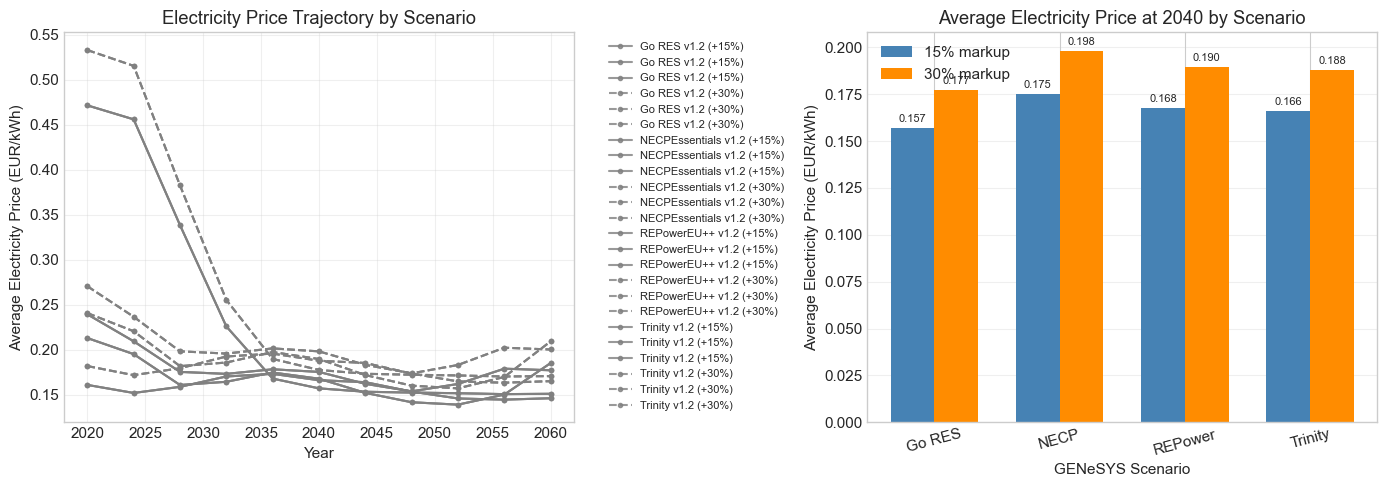


=== AVERAGE ELECTRICITY PRICES (EUR/kWh) BY SCENARIO AT KEY YEARS ===
ID   GENeSYS            Markup       2020     2030     2040     2050     2060
0    Go RES v1.2         15%       0.4716   0.2627   0.1569   0.1523   0.1509
1    Go RES v1.2         15%       0.4716   0.2627   0.1569   0.1523   0.1509
2    Go RES v1.2         15%       0.4716   0.2627   0.1569   0.1523   0.1509
3    Go RES v1.2         30%       0.5332   0.2970   0.1774   0.1721   0.1706
4    Go RES v1.2         30%       0.5332   0.2970   0.1774   0.1721   0.1706
5    Go RES v1.2         30%       0.5332   0.2970   0.1774   0.1721   0.1706
6    NECPEssentials v1   15%       0.2393   0.1475   0.1752   0.1501   0.1771
7    NECPEssentials v1   15%       0.2393   0.1475   0.1752   0.1501   0.1771
8    NECPEssentials v1   15%       0.2393   0.1475   0.1752   0.1501   0.1771
9    NECPEssentials v1   30%       0.2705   0.1667   0.1981   0.1697   0.2001
10   NECPEssentials v1   30%       0.2705   0.1667   0.1981   0.1697   

In [3]:
# =============================================================================
# AVERAGE ELECTRICITY COSTS BY SCENARIO
# =============================================================================

import yaml
import json
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

# Load cases.json
with open('input_data/uncertainty_scenarios/cases.json', 'r') as f:
    cases_data = json.load(f)

cases = {c['case_id']: c for c in cases_data['cases']}

# Years to analyze
model_years = list(range(2020, 2061))
year_indices = [0, 5, 10, 15, 20, 25, 30, 35, 40]  # 2020, 2025, 2030, ..., 2060
selected_years = [2020, 2024, 2028, 2032, 2036, 2040, 2044, 2048, 2052, 2056, 2060]

# Collect electricity prices for each scenario
scenario_prices = {}

for i in range(24):
    scenario = f'scenario_{i:03d}'
    scenario_path = Path(f'input_data/uncertainty_scenarios/{scenario}')
    fuel_cost_path = scenario_path / 'FuelCost.yaml'
    
    if not fuel_cost_path.exists():
        print(f'Skipping {scenario}: FuelCost.yaml not found')
        continue
    
    with open(fuel_cost_path, 'r') as f:
        fuel_costs = yaml.safe_load(f)
    
    # Collect electricity prices (average across all locations)
    elec_prices_by_year = [[] for _ in range(len(model_years))]
    
    for entry in fuel_costs:
        fuel = entry.get('fuel', '')
        if fuel == 'electricity' or fuel == 0 or str(fuel).lower() == 'electricity':
            cost_per_kwh = entry.get('cost_per_kWh', [])
            if isinstance(cost_per_kwh, list):
                for y_idx, price in enumerate(cost_per_kwh):
                    if y_idx < len(elec_prices_by_year):
                        elec_prices_by_year[y_idx].append(price)
    
    # Calculate average price per year
    avg_prices = []
    for y_idx in range(len(model_years)):
        if elec_prices_by_year[y_idx]:
            avg_prices.append(np.mean(elec_prices_by_year[y_idx]))
        else:
            avg_prices.append(np.nan)
    
    case = cases[i]
    scenario_prices[i] = {
        'genesys': case['genesys_scenario'],
        'markup': case['charging_markup'],
        'tech_cost': case['tech_cost_multiplier'],
        'avg_prices': avg_prices
    }

print(f'Loaded electricity prices for {len(scenario_prices)} scenarios')

# =============================================================================
# PLOT 1: Average electricity price trajectory by GENeSYS scenario
# =============================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Color map for GENeSYS scenarios
genesys_colors = {
    'Go RES': '#e41a1c',
    'NECPEssentials': '#377eb8',
    'REPowerEU++': '#4daf4a',
    'Trinity': '#984ea3'
}

# Group by GENeSYS and markup
ax1 = axes[0]
for i, data in scenario_prices.items():
    genesys = data['genesys']
    markup = data['markup']
    color = genesys_colors.get(genesys, 'gray')
    linestyle = '-' if markup == 0.15 else '--'
    
    # Only plot at 4-year intervals (matching model time step)
    time_step_years = model_years[::4]  # Every 4 years
    time_step_prices = data['avg_prices'][::4]
    
    label = f"{genesys} (+{int(markup*100)}%)"
    ax1.plot(time_step_years, time_step_prices, color=color, linestyle=linestyle, 
             marker='o', markersize=3, label=label, alpha=0.8)

ax1.set_xlabel('Year')
ax1.set_ylabel('Average Electricity Price (EUR/kWh)')
ax1.set_title('Electricity Price Trajectory by Scenario')
ax1.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
ax1.grid(True, alpha=0.3)

# =============================================================================
# PLOT 2: Bar chart of average electricity cost at year 2040
# =============================================================================

ax2 = axes[1]

# Get prices at 2040 (index 20 in model_years)
year_2040_idx = 20

# Group by GENeSYS and markup
bar_data = []
for i, data in scenario_prices.items():
    bar_data.append({
        'scenario_id': i,
        'genesys': data['genesys'],
        'markup': data['markup'],
        'price_2040': data['avg_prices'][year_2040_idx] if year_2040_idx < len(data['avg_prices']) else np.nan
    })

bar_df = pd.DataFrame(bar_data)

# Create grouped bar chart
genesys_order = ['Go RES v1.2', 'NECPEssentials v1.2', 'REPowerEU++ v1.2', 'Trinity v1.2']
genesys_short = ['Go RES', 'NECP', 'REPower', 'Trinity']
x = np.arange(len(genesys_order))
width = 0.35

prices_15 = [bar_df[(bar_df['genesys'] == g) & (bar_df['markup'] == 0.15)]['price_2040'].mean() 
             for g in genesys_order]
prices_30 = [bar_df[(bar_df['genesys'] == g) & (bar_df['markup'] == 0.30)]['price_2040'].mean() 
             for g in genesys_order]

bars1 = ax2.bar(x - width/2, prices_15, width, label='15% markup', color='steelblue')
bars2 = ax2.bar(x + width/2, prices_30, width, label='30% markup', color='darkorange')

ax2.set_xlabel('GENeSYS Scenario')
ax2.set_ylabel('Average Electricity Price (EUR/kWh)')
ax2.set_title('Average Electricity Price at 2040 by Scenario')
ax2.set_xticks(x)
ax2.set_xticklabels(genesys_short, rotation=15)
ax2.legend()
ax2.grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        if not np.isnan(height):
            ax2.annotate(f'{height:.3f}',
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 3),
                        textcoords="offset points",
                        ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig('figures/electricity_prices_by_scenario.pdf', bbox_inches='tight', dpi=150)
plt.show()

# =============================================================================
# Print summary table
# =============================================================================

print('\n=== AVERAGE ELECTRICITY PRICES (EUR/kWh) BY SCENARIO AT KEY YEARS ===')
print(f'{"ID":<4} {"GENeSYS":<18} {"Markup":<8} {"2020":>8} {"2030":>8} {"2040":>8} {"2050":>8} {"2060":>8}')
print('=' * 80)

for i, data in sorted(scenario_prices.items()):
    p2020 = data['avg_prices'][0] if len(data['avg_prices']) > 0 else np.nan
    p2030 = data['avg_prices'][10] if len(data['avg_prices']) > 10 else np.nan
    p2040 = data['avg_prices'][20] if len(data['avg_prices']) > 20 else np.nan
    p2050 = data['avg_prices'][30] if len(data['avg_prices']) > 30 else np.nan
    p2060 = data['avg_prices'][40] if len(data['avg_prices']) > 40 else np.nan
    
    print(f'{i:<4} {data["genesys"][:17]:<18} {int(data["markup"]*100):>3}%     '
          f'{p2020:>8.4f} {p2030:>8.4f} {p2040:>8.4f} {p2050:>8.4f} {p2060:>8.4f}')

## Average Electricity Costs by Scenario

This section displays the average electricity costs (EUR/kWh) across all geographic locations for each scenario.
The electricity prices vary by:
- **GENeSYS scenario**: Different scenarios have different base electricity price trajectories
- **Charging markup**: 15% or 30% markup applied on top of base prices

Formula: `final_price = base_price * genesys_ratio * (1 + charging_markup)`

Loaded electricity prices for 24 scenarios


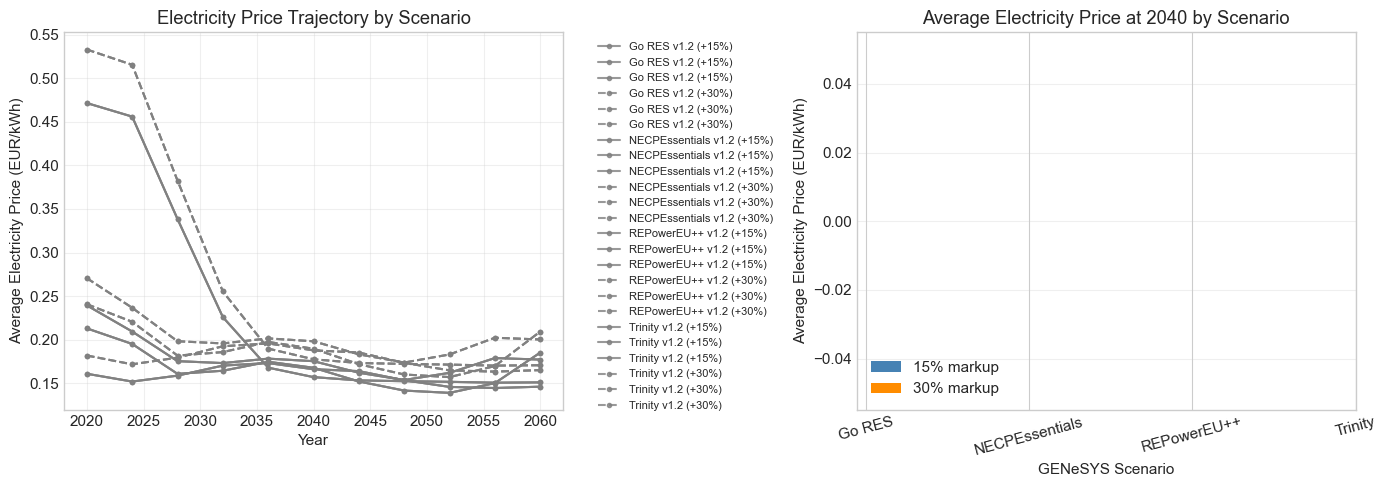


=== AVERAGE ELECTRICITY PRICES (EUR/kWh) BY SCENARIO AT KEY YEARS ===
ID   GENeSYS            Markup       2020     2030     2040     2050     2060
0    Go RES v1.2         15%       0.4716   0.2627   0.1569   0.1523   0.1509
1    Go RES v1.2         15%       0.4716   0.2627   0.1569   0.1523   0.1509
2    Go RES v1.2         15%       0.4716   0.2627   0.1569   0.1523   0.1509
3    Go RES v1.2         30%       0.5332   0.2970   0.1774   0.1721   0.1706
4    Go RES v1.2         30%       0.5332   0.2970   0.1774   0.1721   0.1706
5    Go RES v1.2         30%       0.5332   0.2970   0.1774   0.1721   0.1706
6    NECPEssentials v1   15%       0.2393   0.1475   0.1752   0.1501   0.1771
7    NECPEssentials v1   15%       0.2393   0.1475   0.1752   0.1501   0.1771
8    NECPEssentials v1   15%       0.2393   0.1475   0.1752   0.1501   0.1771
9    NECPEssentials v1   30%       0.2705   0.1667   0.1981   0.1697   0.2001
10   NECPEssentials v1   30%       0.2705   0.1667   0.1981   0.1697   

In [4]:
# =============================================================================
# AVERAGE ELECTRICITY COSTS BY SCENARIO
# =============================================================================

import yaml
import json
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

# Load cases.json
with open('input_data/uncertainty_scenarios/cases.json', 'r') as f:
    cases_data = json.load(f)

cases = {c['case_id']: c for c in cases_data['cases']}

# Years to analyze
model_years = list(range(2020, 2061))
year_indices = [0, 5, 10, 15, 20, 25, 30, 35, 40]  # 2020, 2025, 2030, ..., 2060
selected_years = [2020, 2024, 2028, 2032, 2036, 2040, 2044, 2048, 2052, 2056, 2060]

# Collect electricity prices for each scenario
scenario_prices = {}

for i in range(24):
    scenario = f'scenario_{i:03d}'
    scenario_path = Path(f'input_data/uncertainty_scenarios/{scenario}')
    fuel_cost_path = scenario_path / 'FuelCost.yaml'
    
    if not fuel_cost_path.exists():
        print(f'Skipping {scenario}: FuelCost.yaml not found')
        continue
    
    with open(fuel_cost_path, 'r') as f:
        fuel_costs = yaml.safe_load(f)
    
    # Collect electricity prices (average across all locations)
    elec_prices_by_year = [[] for _ in range(len(model_years))]
    
    for entry in fuel_costs:
        fuel = entry.get('fuel', '')
        if fuel == 'electricity' or fuel == 0 or str(fuel).lower() == 'electricity':
            cost_per_kwh = entry.get('cost_per_kWh', [])
            if isinstance(cost_per_kwh, list):
                for y_idx, price in enumerate(cost_per_kwh):
                    if y_idx < len(elec_prices_by_year):
                        elec_prices_by_year[y_idx].append(price)
    
    # Calculate average price per year
    avg_prices = []
    for y_idx in range(len(model_years)):
        if elec_prices_by_year[y_idx]:
            avg_prices.append(np.mean(elec_prices_by_year[y_idx]))
        else:
            avg_prices.append(np.nan)
    
    case = cases[i]
    scenario_prices[i] = {
        'genesys': case['genesys_scenario'],
        'markup': case['charging_markup'],
        'tech_cost': case['tech_cost_multiplier'],
        'avg_prices': avg_prices
    }

print(f'Loaded electricity prices for {len(scenario_prices)} scenarios')

# =============================================================================
# PLOT 1: Average electricity price trajectory by GENeSYS scenario
# =============================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Color map for GENeSYS scenarios
genesys_colors = {
    'Go RES': '#e41a1c',
    'NECPEssentials': '#377eb8',
    'REPowerEU++': '#4daf4a',
    'Trinity': '#984ea3'
}

# Group by GENeSYS and markup
ax1 = axes[0]
for i, data in scenario_prices.items():
    genesys = data['genesys']
    markup = data['markup']
    color = genesys_colors.get(genesys, 'gray')
    linestyle = '-' if markup == 0.15 else '--'
    
    # Only plot at 4-year intervals (matching model time step)
    time_step_years = model_years[::4]  # Every 4 years
    time_step_prices = data['avg_prices'][::4]
    
    label = f"{genesys} (+{int(markup*100)}%)"
    ax1.plot(time_step_years, time_step_prices, color=color, linestyle=linestyle, 
             marker='o', markersize=3, label=label, alpha=0.8)

ax1.set_xlabel('Year')
ax1.set_ylabel('Average Electricity Price (EUR/kWh)')
ax1.set_title('Electricity Price Trajectory by Scenario')
ax1.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
ax1.grid(True, alpha=0.3)

# =============================================================================
# PLOT 2: Bar chart of average electricity cost at year 2040
# =============================================================================

ax2 = axes[1]

# Get prices at 2040 (index 20 in model_years)
year_2040_idx = 20

# Group by GENeSYS and markup
bar_data = []
for i, data in scenario_prices.items():
    bar_data.append({
        'scenario_id': i,
        'genesys': data['genesys'],
        'markup': data['markup'],
        'price_2040': data['avg_prices'][year_2040_idx] if year_2040_idx < len(data['avg_prices']) else np.nan
    })

bar_df = pd.DataFrame(bar_data)

# Create grouped bar chart
genesys_order = ['Go RES', 'NECPEssentials', 'REPowerEU++', 'Trinity']
x = np.arange(len(genesys_order))
width = 0.35

prices_15 = [bar_df[(bar_df['genesys'] == g) & (bar_df['markup'] == 0.15)]['price_2040'].mean() 
             for g in genesys_order]
prices_30 = [bar_df[(bar_df['genesys'] == g) & (bar_df['markup'] == 0.30)]['price_2040'].mean() 
             for g in genesys_order]

bars1 = ax2.bar(x - width/2, prices_15, width, label='15% markup', color='steelblue')
bars2 = ax2.bar(x + width/2, prices_30, width, label='30% markup', color='darkorange')

ax2.set_xlabel('GENeSYS Scenario')
ax2.set_ylabel('Average Electricity Price (EUR/kWh)')
ax2.set_title('Average Electricity Price at 2040 by Scenario')
ax2.set_xticks(x)
ax2.set_xticklabels(genesys_order, rotation=15)
ax2.legend()
ax2.grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        if not np.isnan(height):
            ax2.annotate(f'{height:.3f}',
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 3),
                        textcoords="offset points",
                        ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.savefig('figures/electricity_prices_by_scenario.pdf', bbox_inches='tight', dpi=150)
plt.show()

# =============================================================================
# Print summary table
# =============================================================================

print('\n=== AVERAGE ELECTRICITY PRICES (EUR/kWh) BY SCENARIO AT KEY YEARS ===')
print(f'{"ID":<4} {"GENeSYS":<18} {"Markup":<8} {"2020":>8} {"2030":>8} {"2040":>8} {"2050":>8} {"2060":>8}')
print('=' * 80)

for i, data in sorted(scenario_prices.items()):
    p2020 = data['avg_prices'][0] if len(data['avg_prices']) > 0 else np.nan
    p2030 = data['avg_prices'][10] if len(data['avg_prices']) > 10 else np.nan
    p2040 = data['avg_prices'][20] if len(data['avg_prices']) > 20 else np.nan
    p2050 = data['avg_prices'][30] if len(data['avg_prices']) > 30 else np.nan
    p2060 = data['avg_prices'][40] if len(data['avg_prices']) > 40 else np.nan
    
    print(f'{i:<4} {data["genesys"][:17]:<18} {int(data["markup"]*100):>3}%     '
          f'{p2020:>8.4f} {p2030:>8.4f} {p2040:>8.4f} {p2050:>8.4f} {p2060:>8.4f}')

In [102]:
# Load cases metadata
with open(cases_json_path, 'r') as f:
    cases_metadata = json.load(f)

cases = cases_metadata['cases']
print(f"Loaded {len(cases)} cases")

# Create a DataFrame for easy filtering
cases_df = pd.DataFrame(cases)
cases_df

Loaded 24 cases


,case_id,genesys_scenario,electricity_price_multiplier,carbon_price,charging_markup,diesel_markup,tech_cost_multiplier
0,0,Go RES v1.2,1.000000,0.0,0.15,0.5,0.7
1,1,Go RES v1.2,1.000000,0.0,0.15,0.5,1.0
2,2,Go RES v1.2,1.000000,0.0,0.15,0.5,1.3
3,3,Go RES v1.2,1.000000,0.0,0.30,0.5,0.7
4,4,Go RES v1.2,1.000000,0.0,0.30,0.5,1.0
5,5,Go RES v1.2,1.000000,0.0,0.30,0.5,1.3
6,6,NECPEssentials v1.2,0.704652,0.0,0.15,0.5,0.7
7,7,NECPEssentials v1.2,0.704652,0.0,0.15,0.5,1.0
8,8,NECPEssentials v1.2,0.704652,0.0,0.15,0.5,1.3
9,9,NECPEssentials v1.2,0.704652,0.0,0.30,0.5,0.7


In [103]:
def load_yaml_file(filepath):
    """Load a YAML file and return its contents."""
    with open(filepath, 'r') as f:
        return yaml.safe_load(f)

def find_latest_result_file(scenario_folder, variable):
    """Find the latest result file for a given variable in a scenario folder."""
    pattern = f"*_{variable}_dict.yaml"
    files = list(Path(scenario_folder).glob(pattern))
    if not files:
        return None
    # Return the most recent file
    return max(files, key=lambda x: x.stat().st_mtime)

def load_scenario_results(scenario_id, variables=['h', 'f', 's', 'q_fuel_infr_plus'], custom_results_path=None):
    """Load results for a specific scenario."""
    res_path = custom_results_path if custom_results_path else results_path
    scenario_folder = res_path / f"scenario_{scenario_id:03d}"
    
    if not scenario_folder.exists():
        # Try alternate naming (without leading zeros)
        scenario_folder = res_path / f"scenario_{scenario_id}"
    
    if not scenario_folder.exists():
        print(f"Warning: Scenario folder not found: {scenario_folder}")
        return None
    
    results = {}
    for var in variables:
        filepath = find_latest_result_file(scenario_folder, var)
        if filepath:
            results[var] = load_yaml_file(filepath)
        else:
            print(f"Warning: {var} not found for scenario {scenario_id}")
    
    return results

def load_scenario_input(scenario_id):
    """Load input data for a specific scenario (skip metadata files with numpy objects)."""
    scenario_folder = input_scenarios_path / f"scenario_{scenario_id:03d}"
    
    input_data = {}
    # Skip case_metadata.yaml as it contains numpy objects that yaml.safe_load can't handle
    skip_files = ['case_metadata']
    
    for yaml_file in scenario_folder.glob("*.yaml"):
        key = yaml_file.stem
        if key in skip_files:
            continue
        try:
            input_data[key] = load_yaml_file(yaml_file)
        except Exception as e:
            print(f"Warning: Could not load {yaml_file.name}: {e}")
    
    return input_data


In [104]:
# Load all scenario results - BASELINE ONLY (without constraint)
all_results_without = {}
all_inputs = {}

print("Loading BASELINE results (WITHOUT charging-at-breaks constraint)...")
for case in cases:
    scenario_id = case['case_id']
    results = load_scenario_results(scenario_id, custom_results_path=results_path_without)
    if results:
        all_results_without[scenario_id] = results

print(f"Loaded {len(all_results_without)} baseline scenarios")

# For backward compatibility
all_results = all_results_without

# Skip loading 'with constraint' results - not yet available
all_results_with = {}  # Empty - will be populated after running with_breaks optimization
print("Note: 'With constraint' results not yet available. Run run_uncertainty_analysis_with_breaks.jl first.")

# Load inputs (just first scenario per GENeSYS scenario)
for case in cases:
    scenario_id = case['case_id']
    if scenario_id % 6 == 0:
        all_inputs[scenario_id] = load_scenario_input(scenario_id)

print(f"Loaded {len(all_inputs)} scenario inputs for reference")


Loading BASELINE results (WITHOUT charging-at-breaks constraint)...
Loaded 24 baseline scenarios
Note: 'With constraint' results not yet available. Run run_uncertainty_analysis_with_breaks.jl first.
Loaded 4 scenario inputs for reference


## 2. Fleet Electrification Analysis (h variable)

Analyze how the BEV fleet develops over time across different scenarios.

In [105]:
def extract_fleet_by_technology(h_dict):
    """
    Extract fleet counts by technology and year from h_dict.
    
    h_dict structure: {(year, odpair_id, tech_id, generation): value}
    - tech_id 0: ICEV (diesel)
    - tech_id 1: BEV
    """
    fleet_data = []
    
    for key, value in h_dict.items():
        # Convert value to float if it's a string
        if isinstance(value, str):
            value = float(value)
        
        if value > 0.01:  # Filter near-zero values
            # Parse the key - it's a string representation of a tuple
            if isinstance(key, str):
                # Remove parentheses and split
                key_clean = key.strip('()').split(',')
                year = int(key_clean[0].strip())
                odpair_id = int(key_clean[1].strip())
                tech_id = int(key_clean[2].strip())
                generation = int(key_clean[3].strip())
            else:
                year, odpair_id, tech_id, generation = key
            
            fleet_data.append({
                'year': year,
                'odpair_id': odpair_id,
                'tech_id': tech_id,
                'generation': generation,
                'vehicles': value
            })
    
    return pd.DataFrame(fleet_data)

# Test with first scenario
test_scenario = 0
if test_scenario in all_results and 'h' in all_results[test_scenario]:
    fleet_df = extract_fleet_by_technology(all_results[test_scenario]['h'])
    print(f"Scenario {test_scenario} fleet data shape: {fleet_df.shape}")
    print(f"Years: {sorted(fleet_df['year'].unique())}")
    print(f"Technologies: {sorted(fleet_df['tech_id'].unique())}")
    print(f"\nSample data:")
    print(fleet_df.head(10))

Scenario 0 fleet data shape: (84576, 5)
Years: [np.int64(2020), np.int64(2024), np.int64(2028), np.int64(2032), np.int64(2036), np.int64(2040), np.int64(2044), np.int64(2048), np.int64(2052), np.int64(2056), np.int64(2060)]
Technologies: [np.int64(0), np.int64(1)]

Sample data:
   year  odpair_id  tech_id  generation   vehicles
0  2044       2704        0        2040   0.011081
1  2044        195        0        2040   0.519015
2  2040        162        0        2032  11.461975
3  2040       5242        0        2032   8.377976
4  2024        435        0        2016   0.133210
5  2028       3626        0        2024   1.769462
6  2036       4031        0        2028   0.494175
7  2056       1322        1        2052   1.104469
8  2052       3662        1        2044  13.089041
9  2036       1256        0        2028   0.887607


In [106]:
def calculate_electrification_rate(h_dict, bev_tech_id=1):
    """
    Calculate the electrification rate (BEV share) by year.
    
    Based on h_dict structure:
    - tech_id=0: ICEV (diesel)
    - tech_id=1: BEV
    """
    fleet_df = extract_fleet_by_technology(h_dict)
    
    if fleet_df.empty:
        return pd.DataFrame()
    
    # Aggregate by year and technology
    yearly_fleet = fleet_df.groupby(['year', 'tech_id'])['vehicles'].sum().reset_index()
    
    # Pivot to get technologies as columns
    yearly_pivot = yearly_fleet.pivot(index='year', columns='tech_id', values='vehicles').fillna(0)
    
    # Calculate totals and BEV share
    yearly_pivot['total'] = yearly_pivot.sum(axis=1)
    
    if bev_tech_id in yearly_pivot.columns:
        yearly_pivot['bev_share'] = yearly_pivot[bev_tech_id] / yearly_pivot['total'] * 100
        yearly_pivot['bev_vehicles'] = yearly_pivot[bev_tech_id]
    else:
        yearly_pivot['bev_share'] = 0
        yearly_pivot['bev_vehicles'] = 0
    
    return yearly_pivot.reset_index()

In [107]:
# Calculate electrification rates for all scenarios
electrification_data = []

for case in cases:
    scenario_id = case['case_id']
    
    if scenario_id not in all_results or 'h' not in all_results[scenario_id]:
        continue
    
    elec_rate = calculate_electrification_rate(all_results[scenario_id]['h'])
    
    if not elec_rate.empty:
        for _, row in elec_rate.iterrows():
            electrification_data.append({
                'scenario_id': scenario_id,
                'genesys_scenario': case['genesys_scenario'],
                'charging_markup': case['charging_markup'],
                'tech_cost_multiplier': case['tech_cost_multiplier'],
                'year': row['year'],
                'bev_share': row['bev_share'],
                'bev_vehicles': row['bev_vehicles'],
                'total_vehicles': row['total']
            })

elec_df = pd.DataFrame(electrification_data)
print(f"Electrification data: {len(elec_df)} rows")
elec_df.head(10)

Electrification data: 264 rows


,scenario_id,genesys_scenario,charging_markup,tech_cost_multiplier,year,bev_share,bev_vehicles,total_vehicles
0,0,Go RES v1.2,0.15,0.7,2020.0,0.000000,0.000000,22439.304823
1,0,Go RES v1.2,0.15,0.7,2024.0,0.000000,0.000000,23930.211927
2,0,Go RES v1.2,0.15,0.7,2028.0,0.000000,0.000000,25420.736860
3,0,Go RES v1.2,0.15,0.7,2032.0,9.984138,2714.078784,27183.906480
4,0,Go RES v1.2,0.15,0.7,2036.0,20.320333,5879.769424,28935.399589
5,0,Go RES v1.2,0.15,0.7,2040.0,30.758338,9585.721588,31164.627590
6,0,Go RES v1.2,0.15,0.7,2044.0,42.853758,13758.537985,32105.790931
7,0,Go RES v1.2,0.15,0.7,2048.0,48.578712,16227.011398,33403.544001
8,0,Go RES v1.2,0.15,0.7,2052.0,54.221960,19032.653342,35101.374405
9,0,Go RES v1.2,0.15,0.7,2056.0,69.151057,24479.361218,35399.836395


### 2.1 BEV Share Over Time by GENeSYS Scenario

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo


findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

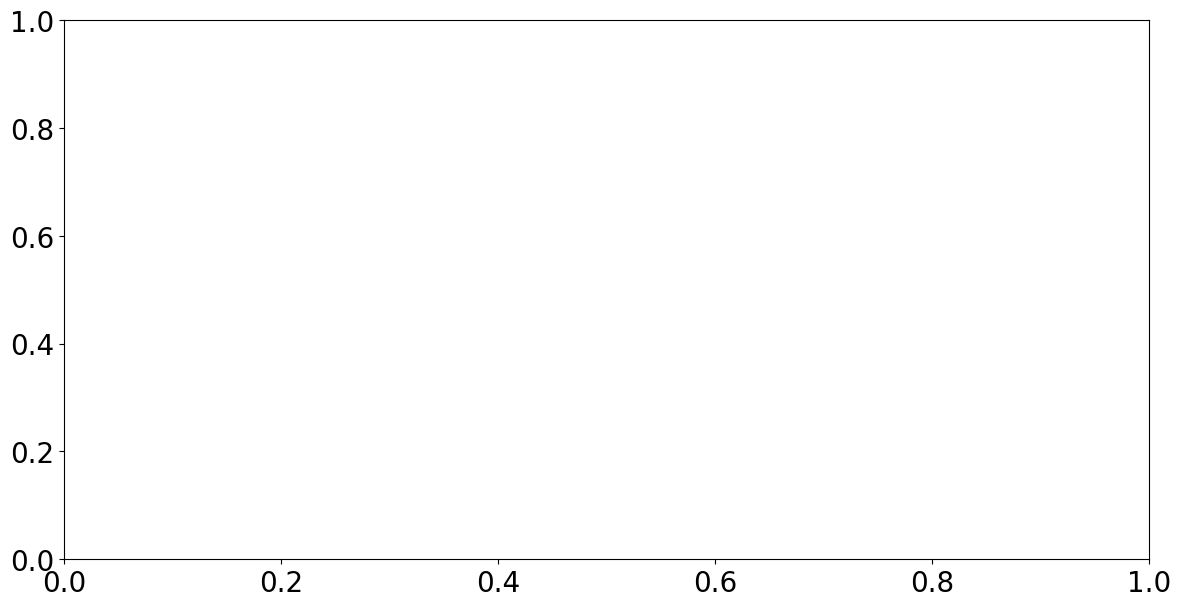

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

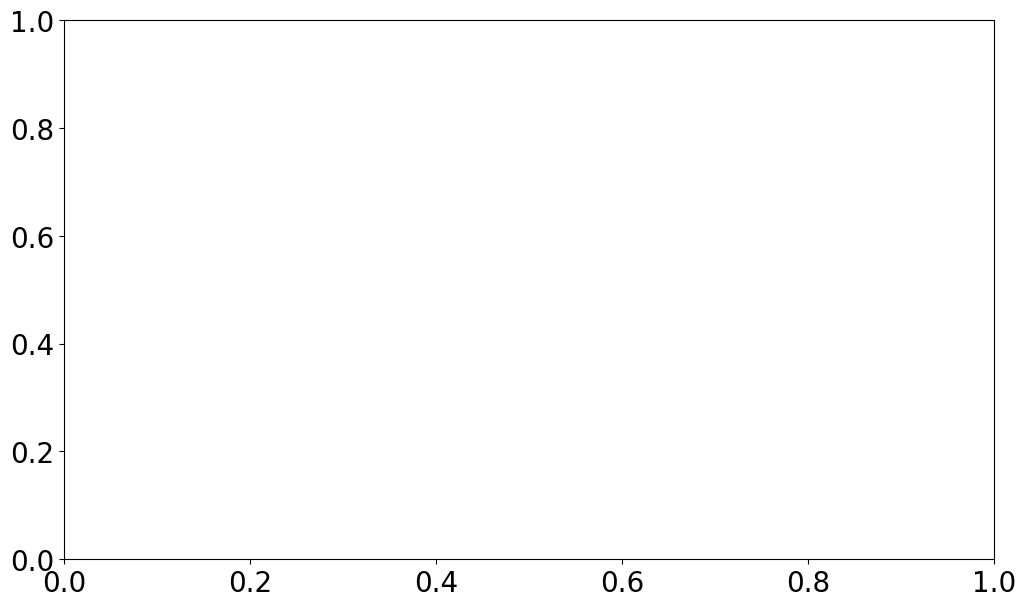

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

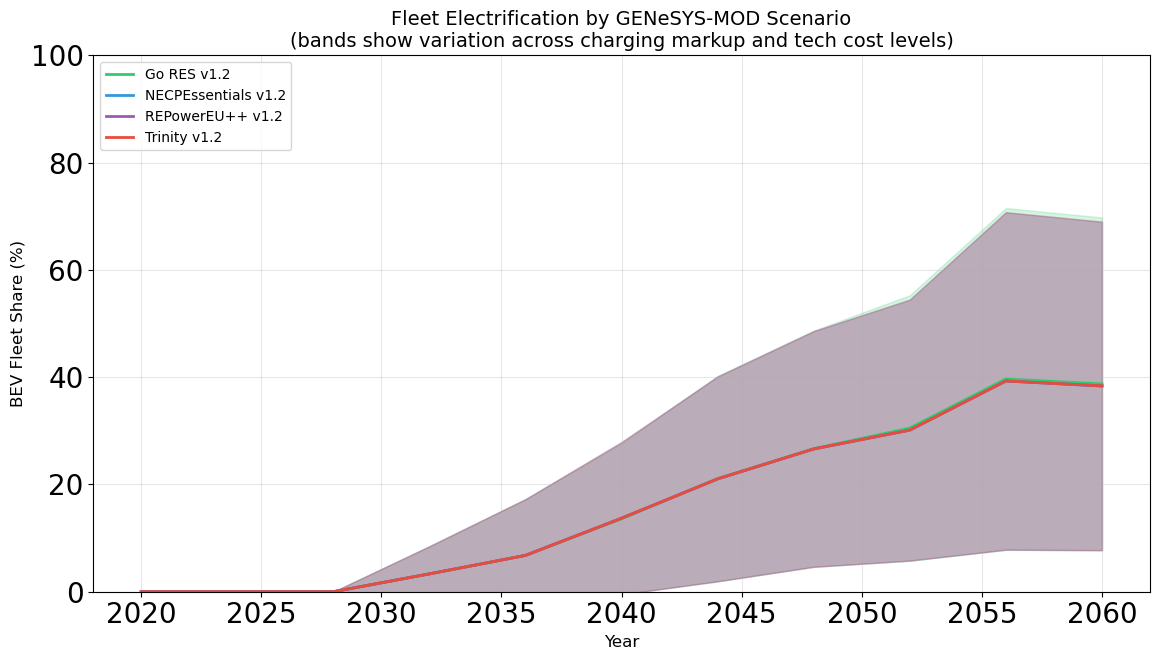

In [108]:
# Plot BEV share over time, grouped by GENeSYS scenario
fig, ax = plt.subplots(figsize=(12, 7))

colors = {
    'Go RES v1.2': '#2ecc71',
    'NECPEssentials v1.2': '#3498db',
    'REPowerEU++ v1.2': '#9b59b6',
    'Trinity v1.2': '#e74c3c'
}

# Group by GENeSYS scenario and calculate mean/std
for scenario_name in colors.keys():
    scenario_data = elec_df[elec_df['genesys_scenario'] == scenario_name]
    
    if scenario_data.empty:
        continue
    
    # Calculate mean and std by year
    yearly_stats = scenario_data.groupby('year')['bev_share'].agg(['mean', 'std']).reset_index()
    
    # Plot mean line
    ax.plot(yearly_stats['year'], yearly_stats['mean'], 
            color=colors[scenario_name], linewidth=2, label=scenario_name)
    
    # Plot confidence band (mean Ã‚Â± std)
    ax.fill_between(yearly_stats['year'], 
                    yearly_stats['mean'] - yearly_stats['std'],
                    yearly_stats['mean'] + yearly_stats['std'],
                    color=colors[scenario_name], alpha=0.2)

ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('BEV Fleet Share (%)', fontsize=12)
ax.set_title('Fleet Electrification by GENeSYS-MOD Scenario\n(bands show variation across charging markup and tech cost levels)', fontsize=14)
ax.legend(loc='upper left', fontsize=10)
ax.set_ylim(0, 100)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figures/electrification_by_genesys_scenario.pdf', bbox_inches='tight', dpi=150)
plt.show()

### 2.2 BEV Share by Technology Cost Trajectory

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

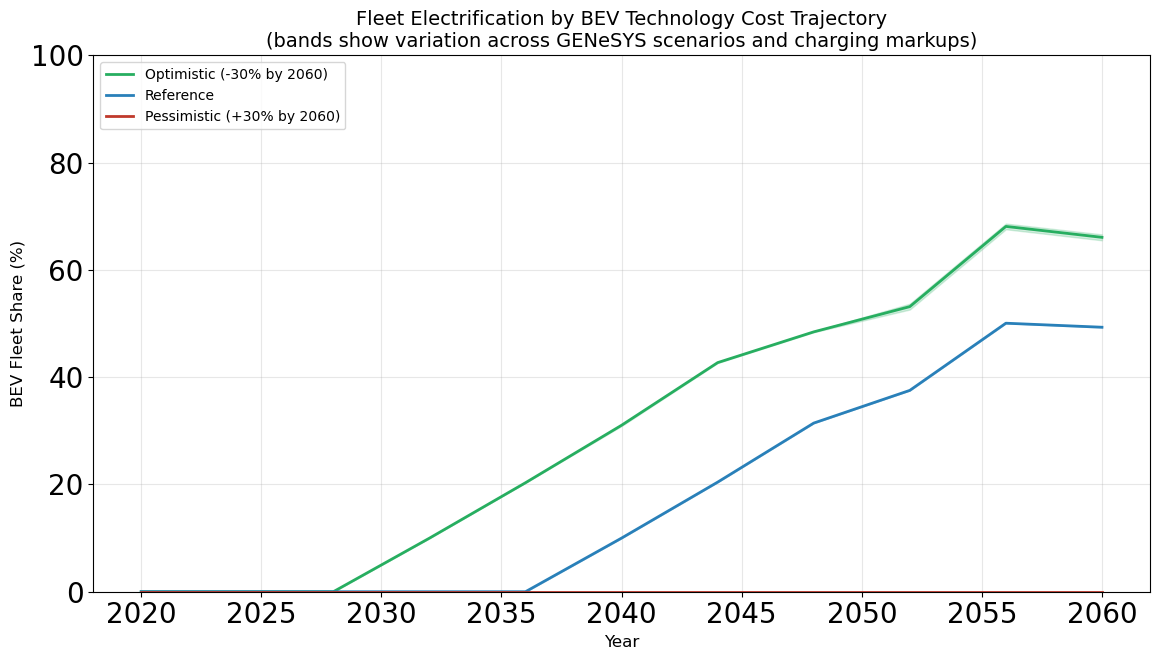

In [109]:
# Plot BEV share over time, grouped by tech cost multiplier
fig, ax = plt.subplots(figsize=(12, 7))

tech_colors = {
    0.7: '#27ae60',   # Optimistic (green)
    1.0: '#2980b9',   # Reference (blue)
    1.3: '#c0392b'    # Pessimistic (red)
}

tech_labels = {
    0.7: 'Optimistic (-30% by 2060)',
    1.0: 'Reference',
    1.3: 'Pessimistic (+30% by 2060)'
}

for tech_mult in sorted(elec_df['tech_cost_multiplier'].unique()):
    tech_data = elec_df[elec_df['tech_cost_multiplier'] == tech_mult]
    
    if tech_data.empty:
        continue
    
    yearly_stats = tech_data.groupby('year')['bev_share'].agg(['mean', 'std']).reset_index()
    
    ax.plot(yearly_stats['year'], yearly_stats['mean'],
            color=tech_colors.get(tech_mult, 'gray'), linewidth=2, 
            label=tech_labels.get(tech_mult, f'Tech x{tech_mult}'))
    
    ax.fill_between(yearly_stats['year'],
                    yearly_stats['mean'] - yearly_stats['std'],
                    yearly_stats['mean'] + yearly_stats['std'],
                    color=tech_colors.get(tech_mult, 'gray'), alpha=0.2)

ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('BEV Fleet Share (%)', fontsize=12)
ax.set_title('Fleet Electrification by BEV Technology Cost Trajectory\n(bands show variation across GENeSYS scenarios and charging markups)', fontsize=14)
ax.legend(loc='upper left', fontsize=10)
ax.set_ylim(0, 100)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figures/electrification_by_tech_cost.pdf', bbox_inches='tight', dpi=150)
plt.show()

### 2.3 Absolute BEV Fleet Size by GENeSYS Scenario


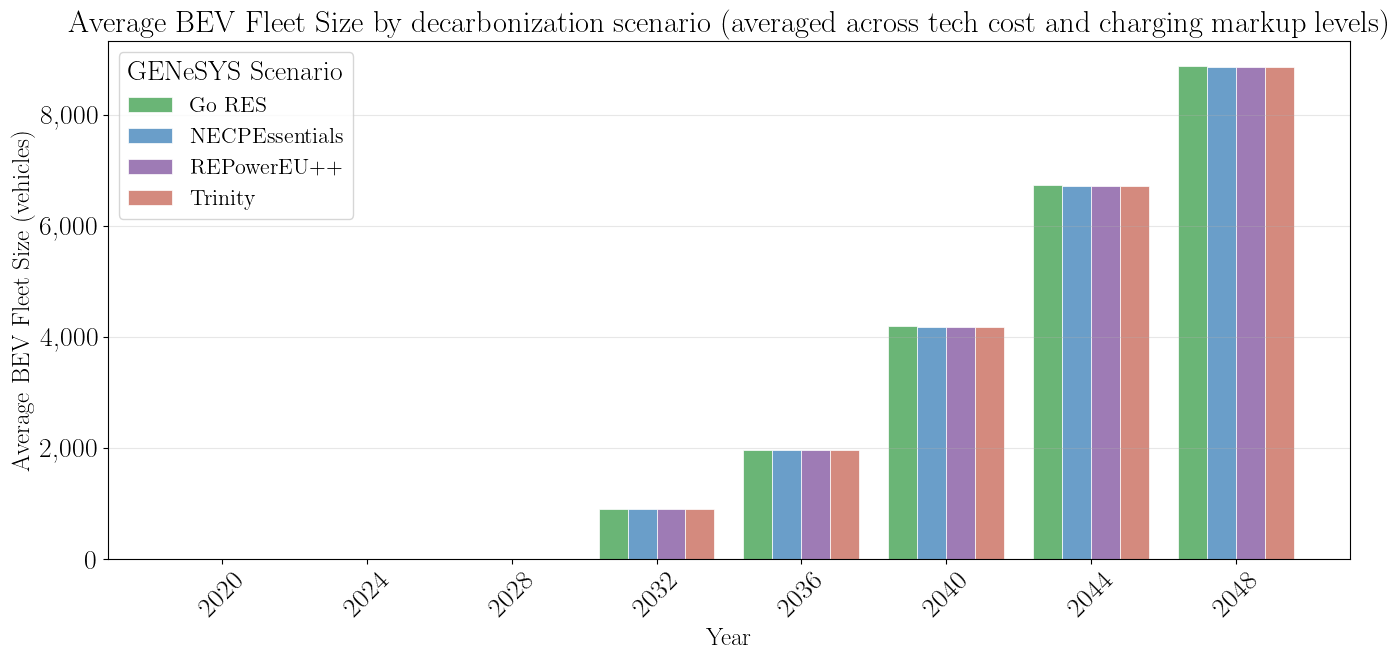

=== BEV Fleet Size Summary (vehicles) ===
Year 2032:
  Go RES              : 905 ± 1,402
  NECPEssentials      : 905 ± 1,402
  REPowerEU++         : 905 ± 1,402
  Trinity             : 905 ± 1,402
Year 2040:
  Go RES              : 4,195 ± 4,381
  NECPEssentials      : 4,181 ± 4,360
  REPowerEU++         : 4,181 ± 4,360
  Trinity             : 4,181 ± 4,360
Year 2048:
  Go RES              : 8,887 ± 7,352
  NECPEssentials      : 8,872 ± 7,334
  REPowerEU++         : 8,871 ± 7,333
  Trinity             : 8,872 ± 7,334
Year 2056:
  Go RES              : 14,065 ± 11,290
  NECPEssentials      : 13,935 ± 11,147
  REPowerEU++         : 13,935 ± 11,148
  Trinity             : 13,935 ± 11,147


In [135]:
# Absolute BEV fleet size by GENeSYS scenario (clustered bar chart)
# Shows average across all scenarios within each GENeSYS group
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    'font.serif': 'mathpazo',
    'font.size': 20,
    'axes.labelsize': 20
})
fig, ax = plt.subplots(figsize=(14, 7))

# Years to show (2020:4:2060)
years_to_show = list(range(2020, 2050, 4))

# GENeSYS scenarios and colors
genesys_scenarios = ['Go RES v1.2', 'NECPEssentials v1.2', 'REPowerEU++ v1.2', 'Trinity v1.2']
colors = {
      'Go RES v1.2': '#6ab576',       # Bright sage green
      'NECPEssentials v1.2': '#6a9ec9', # Bright muted blue
      'REPowerEU++ v1.2': '#9e7bb5',   # Bright muted purple
      'Trinity v1.2': '#d48a7e'        # Bright muted coral
  }


# Calculate bar positions
n_scenarios = len(genesys_scenarios)
bar_width = 0.8 / n_scenarios
x = np.arange(len(years_to_show))

# Plot bars for each GENeSYS scenario
for i, scenario_name in enumerate(genesys_scenarios):
    scenario_data = elec_df[elec_df['genesys_scenario'] == scenario_name]
    
    if scenario_data.empty:
        continue
    
    # Calculate mean BEV vehicles by year (averaged over tech cost and charging markup)
    yearly_mean = scenario_data.groupby('year')['bev_vehicles'].mean()
    
    # Get values for the years we want
    values = [yearly_mean.get(y, 0) for y in years_to_show]
    
    # Plot bars
    offset = (i - n_scenarios/2 + 0.5) * bar_width
    ax.bar(x + offset, values, bar_width, label=scenario_name.replace(' v1.2', ''),
           color=colors[scenario_name], edgecolor='white', linewidth=0.5)

# Formatting
ax.set_xlabel('Year', fontsize=18, fontweight='bold')
ax.set_ylabel('Average BEV Fleet Size (vehicles)', fontsize=18, fontweight='bold')
ax.set_title('Average BEV Fleet Size by decarbonization scenario (averaged across tech cost and charging markup levels)', fontsize=22, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(years_to_show, rotation=45)
ax.legend(title='GENeSYS Scenario', loc='upper left', fontsize=16)
ax.grid(True, axis='y', alpha=0.3)

# Format y-axis with thousands separator
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{x:,.0f}'))

plt.tight_layout()
plt.savefig('figures/absolute_bev_fleet_by_genesys.pdf', bbox_inches='tight', dpi=150)
plt.show()

# Print summary statistics
print("=== BEV Fleet Size Summary (vehicles) ===")
for year in [2032, 2040, 2048, 2056]:
    print(f"Year {year}:")
    for scenario_name in genesys_scenarios:
        scenario_data = elec_df[(elec_df['genesys_scenario'] == scenario_name) & (elec_df['year'] == year)]
        if not scenario_data.empty:
            mean_val = scenario_data['bev_vehicles'].mean()
            std_val = scenario_data['bev_vehicles'].std()
            print(f"  {scenario_name.replace(' v1.2', ''):20s}: {mean_val:,.0f} ± {std_val:,.0f}")


### 2.3 BEV Share by Charging Markup

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

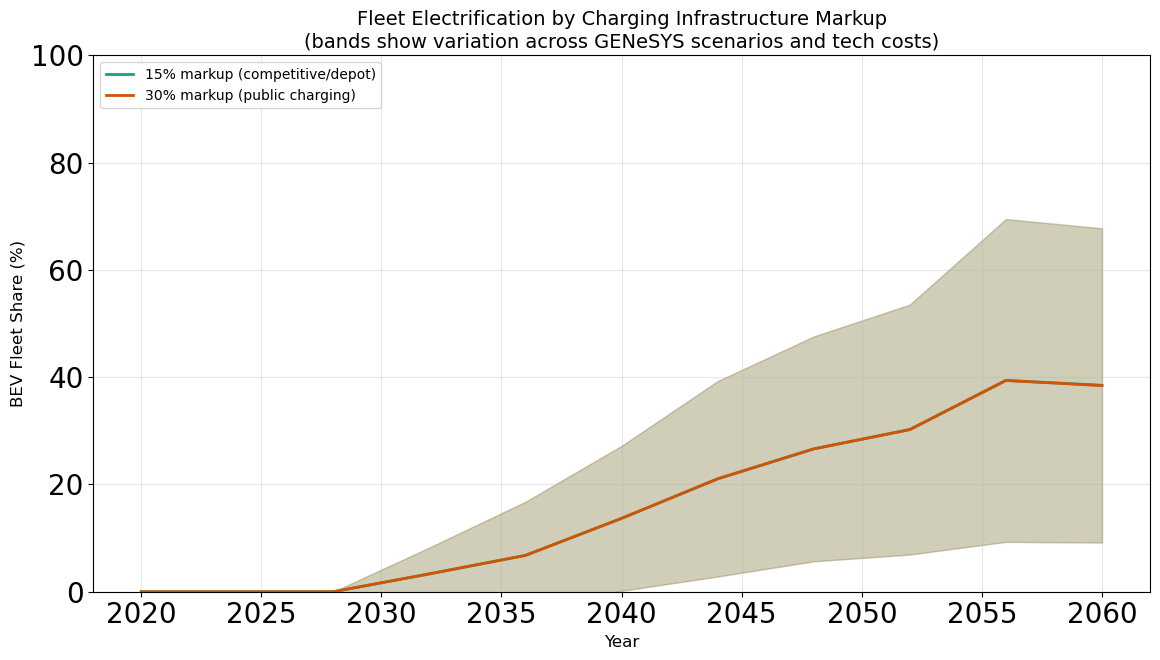

In [111]:
# Plot BEV share over time, grouped by charging markup
fig, ax = plt.subplots(figsize=(12, 7))

markup_colors = {
    0.15: '#16a085',  # Low markup (teal)
    0.30: '#d35400'   # High markup (orange)
}

markup_labels = {
    0.15: '15% markup (competitive/depot)',
    0.30: '30% markup (public charging)'
}

for markup in sorted(elec_df['charging_markup'].unique()):
    markup_data = elec_df[elec_df['charging_markup'] == markup]
    
    if markup_data.empty:
        continue
    
    yearly_stats = markup_data.groupby('year')['bev_share'].agg(['mean', 'std']).reset_index()
    
    ax.plot(yearly_stats['year'], yearly_stats['mean'],
            color=markup_colors.get(markup, 'gray'), linewidth=2,
            label=markup_labels.get(markup, f'{markup*100:.0f}% markup'))
    
    ax.fill_between(yearly_stats['year'],
                    yearly_stats['mean'] - yearly_stats['std'],
                    yearly_stats['mean'] + yearly_stats['std'],
                    color=markup_colors.get(markup, 'gray'), alpha=0.2)

ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('BEV Fleet Share (%)', fontsize=12)
ax.set_title('Fleet Electrification by Charging Infrastructure Markup\n(bands show variation across GENeSYS scenarios and tech costs)', fontsize=14)
ax.legend(loc='upper left', fontsize=10)
ax.set_ylim(0, 100)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figures/electrification_by_charging_markup.pdf', bbox_inches='tight', dpi=150)
plt.show()

### 2.4 Full Factorial Comparison (Heatmap at Selected Years)

C:\Users\simuser\AppData\Local\Temp\ipykernel_21512\743050034.py:48: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following fam

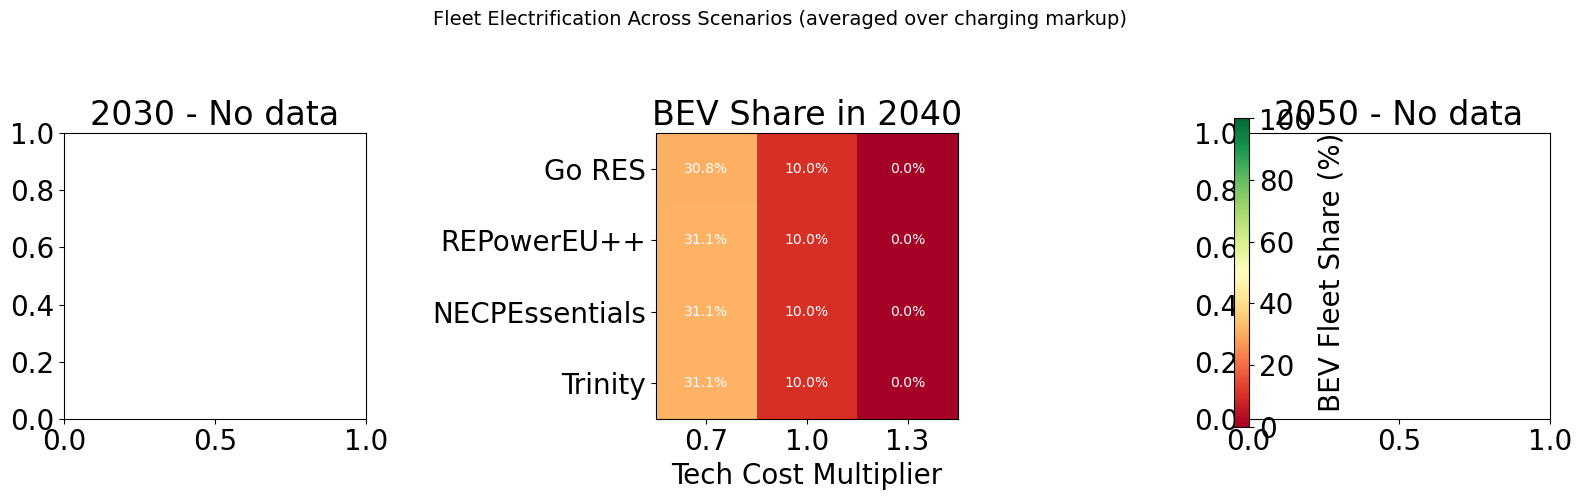

In [112]:
# Create heatmap of BEV share at key years
key_years = [2030, 2040, 2050]

fig, axes = plt.subplots(1, len(key_years), figsize=(16, 5))

for idx, year in enumerate(key_years):
    ax = axes[idx]
    
    year_data = elec_df[elec_df['year'] == year].copy()
    
    if year_data.empty:
        ax.set_title(f'{year} - No data')
        continue
    
    # Create pivot table: rows = GENeSYS scenario, columns = tech_cost, values = mean BEV share
    # Average over charging markup
    pivot_data = year_data.groupby(['genesys_scenario', 'tech_cost_multiplier'])['bev_share'].mean().unstack()
    
    # Reorder rows
    row_order = ['Go RES v1.2', 'REPowerEU++ v1.2', 'NECPEssentials v1.2', 'Trinity v1.2']
    pivot_data = pivot_data.reindex([r for r in row_order if r in pivot_data.index])
    
    # Plot heatmap
    im = ax.imshow(pivot_data.values, cmap='RdYlGn', aspect='auto', vmin=0, vmax=100)
    
    # Labels
    ax.set_xticks(range(len(pivot_data.columns)))
    ax.set_xticklabels([f'{x:.1f}' for x in pivot_data.columns])
    ax.set_yticks(range(len(pivot_data.index)))
    ax.set_yticklabels([s.replace(' v1.2', '') for s in pivot_data.index])
    
    ax.set_xlabel('Tech Cost Multiplier')
    if idx == 0:
        ax.set_ylabel('GENeSYS Scenario')
    ax.set_title(f'BEV Share in {year}')
    
    # Add values as text
    for i in range(len(pivot_data.index)):
        for j in range(len(pivot_data.columns)):
            val = pivot_data.iloc[i, j]
            color = 'white' if val < 50 else 'black'
            ax.text(j, i, f'{val:.1f}%', ha='center', va='center', color=color, fontsize=10)

# Colorbar
cbar = fig.colorbar(im, ax=axes, shrink=0.8, label='BEV Fleet Share (%)')

plt.suptitle('Fleet Electrification Across Scenarios (averaged over charging markup)', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('figures/electrification_heatmap_by_year.pdf', bbox_inches='tight', dpi=150)
plt.show()

### 2.5 Absolute BEV Fleet Size

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

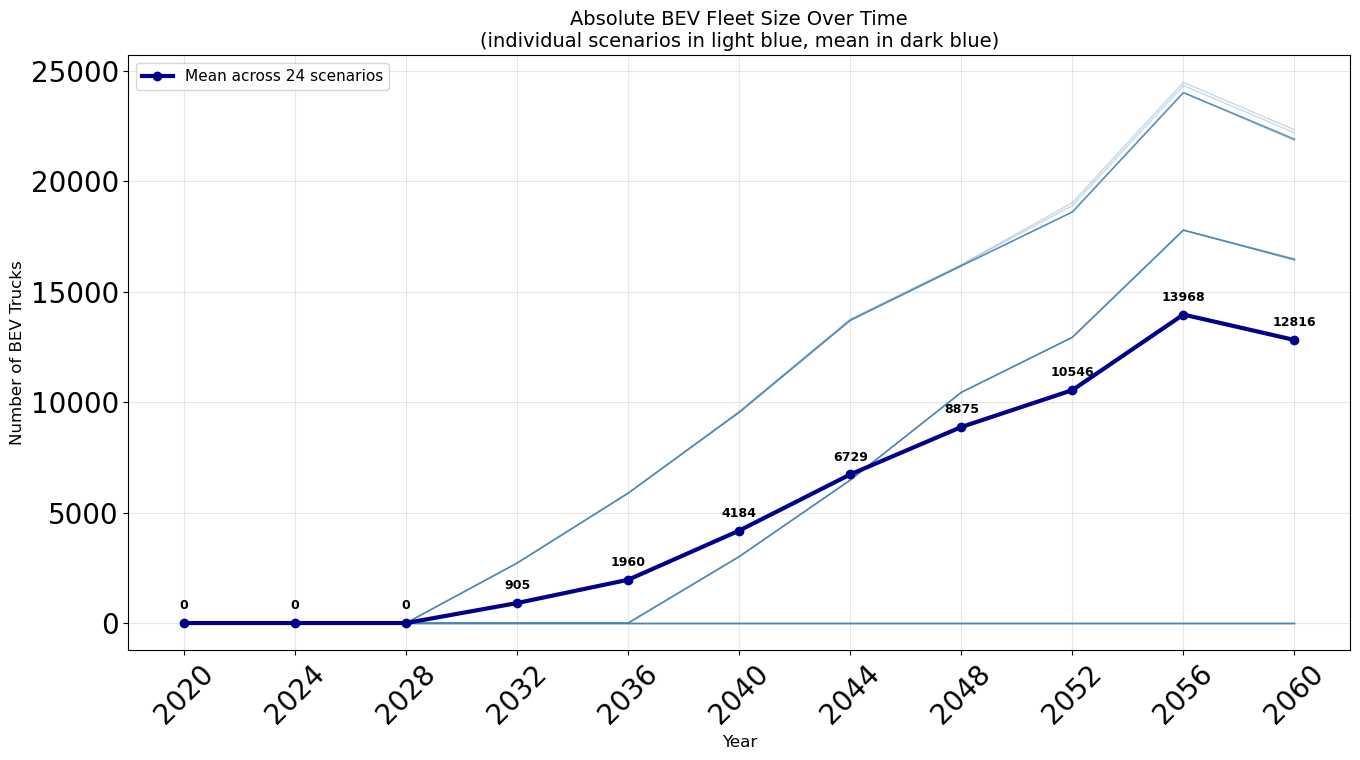


=== Absolute BEV Fleet by Year (Mean across scenarios) ===
  year         mean  min          max          std
2020.0     0.000000  0.0     0.000000     0.000000
2024.0     0.000000  0.0     0.000000     0.000000
2028.0     0.000000  0.0     0.000000     0.000000
2032.0   904.850584  0.0  2715.059322  1307.174531
2036.0  1960.203242  0.0  5881.496643  2831.768893
2040.0  4184.290270  0.0  9585.721588  4070.819250
2044.0  6729.058861  0.0 13758.537985  5722.311625
2048.0  8875.444216  0.0 16227.011398  6843.003788
2052.0 10545.549687  0.0 19032.653342  7987.840793
2056.0 13967.556811  0.0 24479.361218 10428.490231
2060.0 12815.738901  0.0 22331.456833  9540.426542


In [113]:
# Plot absolute number of BEV vehicles over time with individual scenario lines
fig, ax = plt.subplots(figsize=(14, 8))

# Plot individual scenario lines (thin, semi-transparent)
for scenario_id in elec_df['scenario_id'].unique():
    scenario_data = elec_df[elec_df['scenario_id'] == scenario_id].sort_values('year')
    ax.plot(scenario_data['year'], scenario_data['bev_vehicles'], 
            alpha=0.3, linewidth=1, color='steelblue')

# Calculate and plot mean across all scenarios
yearly_bev = elec_df.groupby('year')['bev_vehicles'].agg(['mean', 'min', 'max', 'std']).reset_index()

# Plot mean line (thick, bold)
ax.plot(yearly_bev['year'], yearly_bev['mean'], 'darkblue', linewidth=3, 
        label=f'Mean across {len(elec_df["scenario_id"].unique())} scenarios', marker='o', markersize=6)

# Add value labels on the mean line
for _, row in yearly_bev.iterrows():
    ax.annotate(f'{row["mean"]:.0f}', 
                xy=(row['year'], row['mean']),
                xytext=(0, 10), textcoords='offset points',
                ha='center', fontsize=9, fontweight='bold')

ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Number of BEV Trucks', fontsize=12)
ax.set_title('Absolute BEV Fleet Size Over Time\n(individual scenarios in light blue, mean in dark blue)', fontsize=14)
ax.legend(loc='upper left', fontsize=11)
ax.grid(True, alpha=0.3)

# Set x-axis to show all years
ax.set_xticks(yearly_bev['year'])
ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('figures/absolute_bev_fleet_with_mean.pdf', bbox_inches='tight', dpi=150)
plt.show()

# Print summary table
print("\n=== Absolute BEV Fleet by Year (Mean across scenarios) ===")
print(yearly_bev[['year', 'mean', 'min', 'max', 'std']].to_string(index=False))

C:\Users\simuser\AppData\Local\Temp\ipykernel_21512\955427416.py:21: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(boxplot_data, labels=years, patch_artist=True)


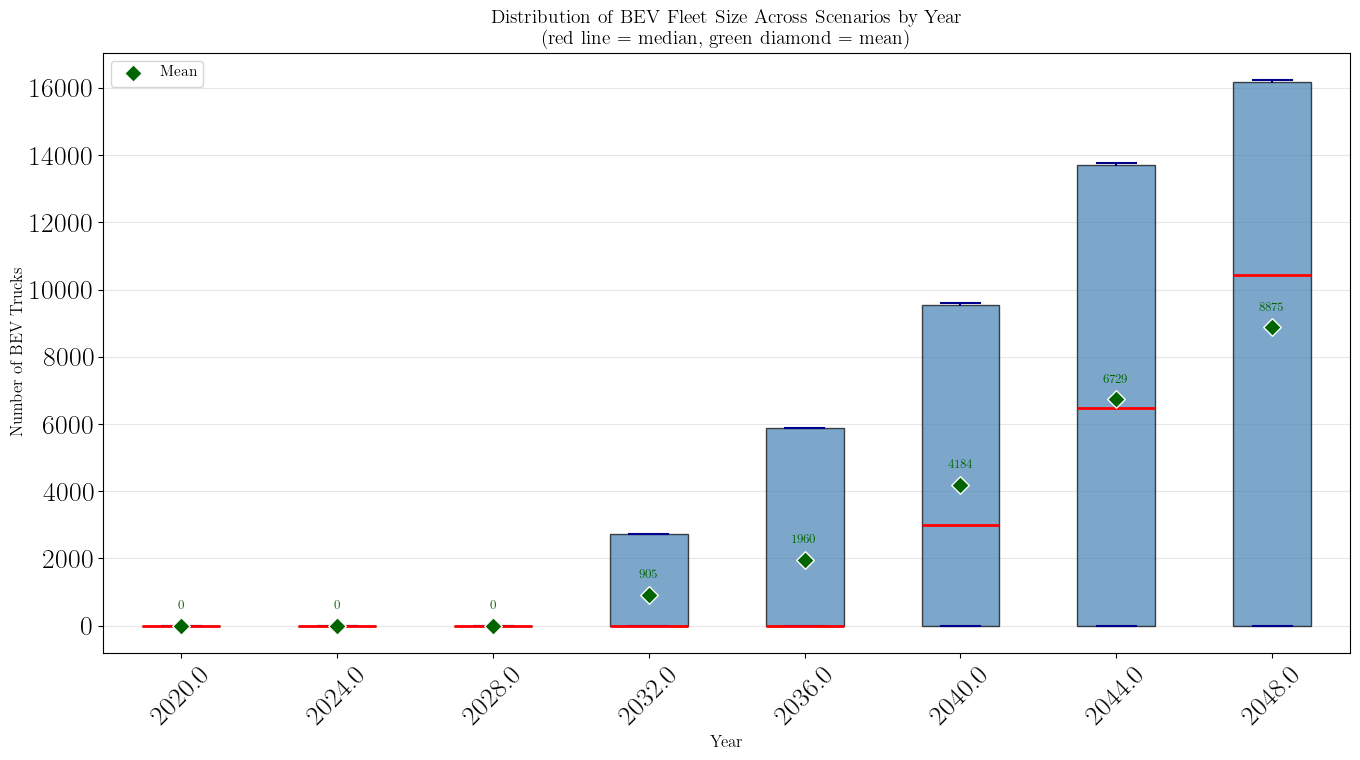

In [114]:
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    'font.serif': 'mathpazo',
    'font.size': 20,
    'axes.labelsize': 20
})

# Boxplot of absolute BEV fleet by year (cutoff at 2048)
fig, ax = plt.subplots(figsize=(14, 8))

# Filter data to years <= 2048
elec_df_filtered = elec_df[elec_df['year'] <= 2048]

# Prepare data for boxplot
years = sorted(elec_df_filtered['year'].unique())
boxplot_data = [elec_df_filtered[elec_df_filtered['year'] == year]['bev_vehicles'].values for year in years]

# Create boxplot
bp = ax.boxplot(boxplot_data, labels=years, patch_artist=True)

# Style the boxplot
for patch in bp['boxes']:
    patch.set_facecolor('steelblue')
    patch.set_alpha(0.7)

for whisker in bp['whiskers']:
    whisker.set(color='darkblue', linewidth=1.5)

for cap in bp['caps']:
    cap.set(color='darkblue', linewidth=1.5)

for median in bp['medians']:
    median.set(color='red', linewidth=2)

for flier in bp['fliers']:
    flier.set(marker='o', color='gray', alpha=0.5)

# Add mean markers
means = [elec_df_filtered[elec_df_filtered['year'] == year]['bev_vehicles'].mean() for year in years]
ax.scatter(range(1, len(years) + 1), means, color='darkgreen', s=80, zorder=5, 
           marker='D', label='Mean', edgecolors='white', linewidths=1)

# Add mean value labels
for i, (year, mean_val) in enumerate(zip(years, means)):
    ax.annotate(f'{mean_val:.0f}', 
                xy=(i + 1, mean_val),
                xytext=(0, 12), textcoords='offset points',
                ha='center', fontsize=9, fontweight='bold', color='darkgreen')

ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Number of BEV Trucks', fontsize=12)
ax.set_title('Distribution of BEV Fleet Size Across Scenarios by Year\n(red line = median, green diamond = mean)', fontsize=14)
ax.legend(loc='upper left', fontsize=11)
ax.grid(True, alpha=0.3, axis='y')

plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('figures/bev_fleet_boxplot_by_year.pdf', bbox_inches='tight', dpi=150)
plt.show()

## 3. Summary Statistics

In [115]:
# Summary table at key years
summary_years = [2030, 2040, 2050, 2060]

summary_data = []
for year in summary_years:
    year_data = elec_df[elec_df['year'] == year]
    if not year_data.empty:
        summary_data.append({
            'Year': year,
            'Mean BEV Share (%)': year_data['bev_share'].mean(),
            'Std BEV Share (%)': year_data['bev_share'].std(),
            'Min BEV Share (%)': year_data['bev_share'].min(),
            'Max BEV Share (%)': year_data['bev_share'].max(),
            'Mean BEV Vehicles': year_data['bev_vehicles'].mean(),
            'Mean Total Vehicles': year_data['total_vehicles'].mean()
        })

summary_df = pd.DataFrame(summary_data)
summary_df.round(2)

,Year,Mean BEV Share (%),Std BEV Share (%),Min BEV Share (%),Max BEV Share (%),Mean BEV Vehicles,Mean Total Vehicles
0,2040,13.68,13.21,0.0,31.11,4184.29,30240.46
1,2060,38.46,28.65,0.0,67.16,12815.74,33658.80


In [116]:
# Sensitivity analysis: which factor has the largest effect?
print("=== Sensitivity Analysis (BEV Share in 2050) ===")

year_2050 = elec_df[elec_df['year'] == 2050]

if not year_2050.empty:
    # Effect of GENeSYS scenario
    genesys_effect = year_2050.groupby('genesys_scenario')['bev_share'].mean()
    print(f"\nGENeSYS Scenario Effect:")
    print(f"  Range: {genesys_effect.max() - genesys_effect.min():.1f} percentage points")
    for scenario, share in genesys_effect.items():
        print(f"  {scenario}: {share:.1f}%")
    
    # Effect of tech cost
    tech_effect = year_2050.groupby('tech_cost_multiplier')['bev_share'].mean()
    print(f"\nTech Cost Effect:")
    print(f"  Range: {tech_effect.max() - tech_effect.min():.1f} percentage points")
    for tech, share in tech_effect.items():
        print(f"  x{tech}: {share:.1f}%")
    
    # Effect of charging markup
    markup_effect = year_2050.groupby('charging_markup')['bev_share'].mean()
    print(f"\nCharging Markup Effect:")
    print(f"  Range: {markup_effect.max() - markup_effect.min():.1f} percentage points")
    for markup, share in markup_effect.items():
        print(f"  {markup*100:.0f}%: {share:.1f}%")

=== Sensitivity Analysis (BEV Share in 2050) ===


# BEV Adoption by Origin-Destination Pathway Analysis

In [163]:
from pathlib import Path


base_path = Path(r"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM")


In [164]:
import importlib
import sys

if 'bev_od_adoption_uncertainty' in sys.modules:
    importlib.reload(sys.modules['bev_od_adoption_uncertainty'])

from bev_od_adoption_uncertainty import (
    create_bev_od_matrix_by_genesys,
    create_bev_od_timeseries_by_genesys,
    plot_bev_od_matrices_comparison,
    plot_bev_od_matrices_with_deltas,
    plot_bev_timeseries_by_genesys,
    plot_bev_od_bar_by_corridor,
    plot_bev_od_by_markup_and_tech,
    plot_bev_totals_by_markup_and_tech
)

In [165]:
# Create BEV OD matrices by GENeSYS scenario (year 2040) - using pre-loaded data
bev_od_matrices = create_bev_od_matrix_by_genesys(
    base_path, 
    target_year=2040,
    preloaded_results=all_results,
    cases_metadata=cases_metadata
)

BEV OD ADOPTION BY GENeSYS SCENARIO (Year: 2040)
Loaded 2043 OD pairs, 81 geographic elements
Using 24 pre-loaded scenario results

GENeSYS scenarios: ['Go RES v1.2', 'NECPEssentials v1.2', 'REPowerEU++ v1.2', 'Trinity v1.2']

Processing Go RES v1.2 (6 scenarios)...
  Matrix shape: (7, 7), Total BEVs: 6292

Processing NECPEssentials v1.2 (6 scenarios)...
  Matrix shape: (7, 7), Total BEVs: 6271

Processing REPowerEU++ v1.2 (6 scenarios)...
  Matrix shape: (7, 7), Total BEVs: 6271

Processing Trinity v1.2 (6 scenarios)...
  Matrix shape: (7, 7), Total BEVs: 6271


In [166]:
print(bev_od_matrices.keys())

dict_keys(['Go RES v1.2', 'NECPEssentials v1.2', 'REPowerEU++ v1.2', 'Trinity v1.2'])


Saved to figures\bev_od_matrices_with_deltas_2040.pdf


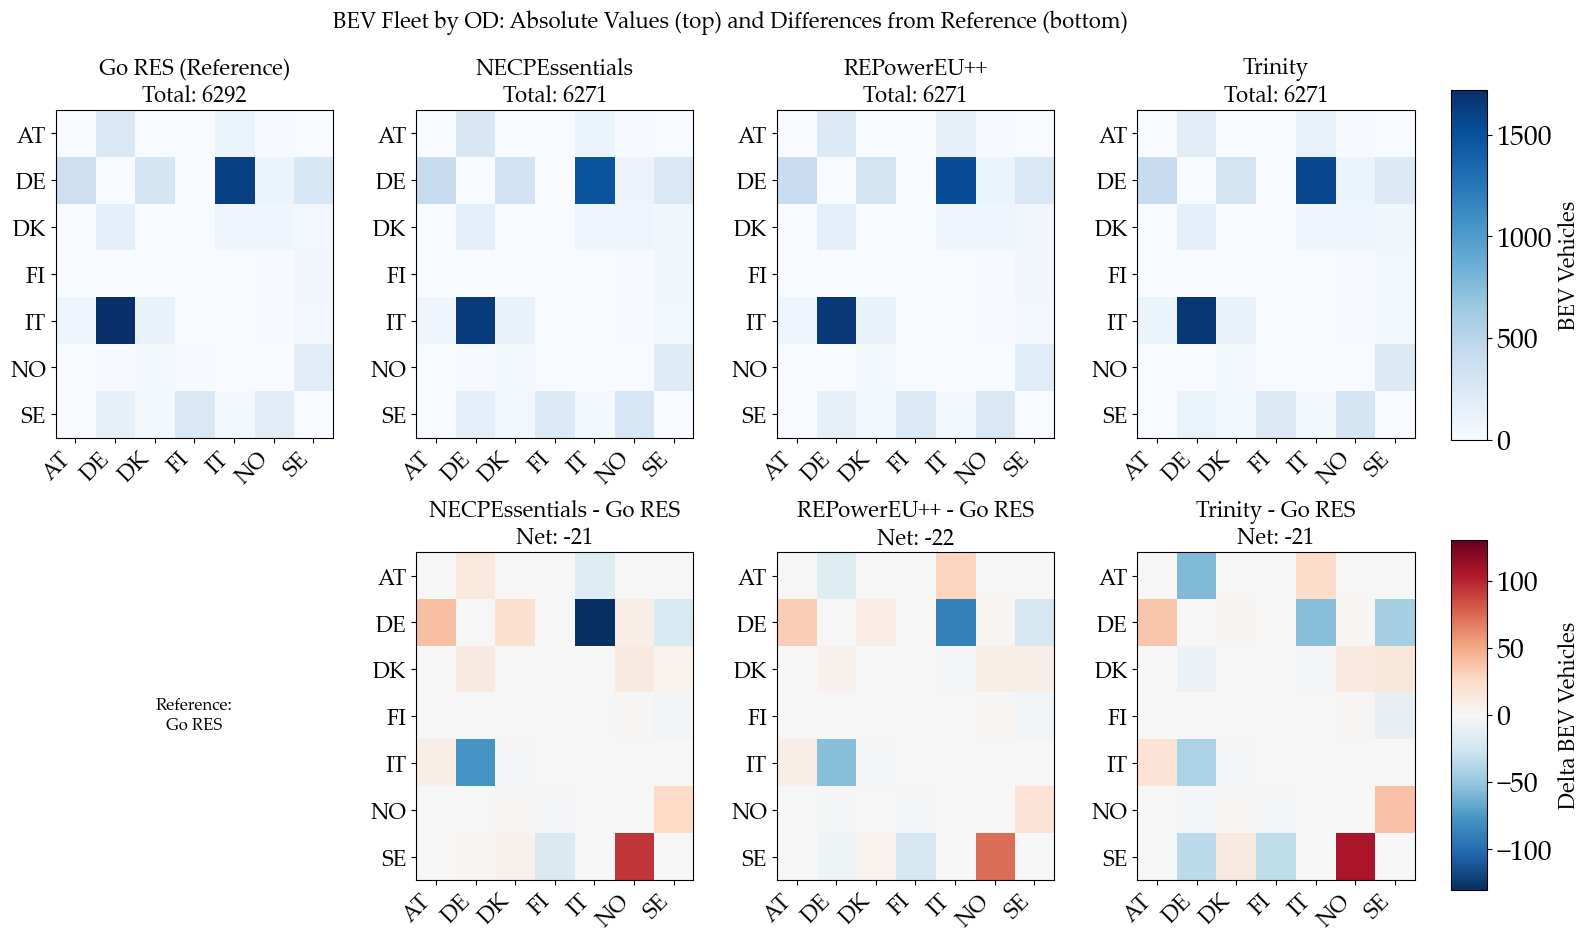


=== Scenario Comparison Summary ===
Reference: Go RES v1.2
  Total BEVs: 6292

NECPEssentials v1.2:
  Total BEVs: 6271
  Difference: -21 (-0.3%)

REPowerEU++ v1.2:
  Total BEVs: 6271
  Difference: -22 (-0.3%)

Trinity v1.2:
  Total BEVs: 6271
  Difference: -21 (-0.3%)


In [173]:
if 'bev_od_adoption_uncertainty' in sys.modules:
    importlib.reload(sys.modules['bev_od_adoption_uncertainty'])
plt.rcParams.update(plt.rcParamsDefault)
plt.rcParams.update({
    "text.usetex": False,  # Disable LaTeX
    "font.family": "serif",
    "font.serif": ["Palatino Linotype", "DejaVu Serif", "Times New Roman"],
    "mathtext.fontset": "cm",  # Computer Modern for math
    "font.size": 20,
    "axes.labelsize": 20
})

import importlib
import bev_od_adoption_uncertainty
importlib.reload(bev_od_adoption_uncertainty)
from bev_od_adoption_uncertainty import plot_bev_od_matrices_with_deltas

plot_bev_od_matrices_with_deltas(
    bev_od_matrices,
    reference_scenario='Go RES v1.2',
    figsize=(18, 10),
    save_path=Path('figures/bev_od_matrices_with_deltas_2040.pdf')
)

In [141]:
# Create BEV time series by GENeSYS scenario - using pre-loaded data
bev_timeseries = create_bev_od_timeseries_by_genesys(
    base_path, 
    years=list(range(2020, 2052, 4)),
    preloaded_results=all_results,
    cases_metadata=cases_metadata
)
bev_timeseries

BEV ADOPTION TIME SERIES BY GENeSYS SCENARIO
Using 24 pre-loaded scenario results
Processing year 2020...
Processing year 2024...
Processing year 2028...
Processing year 2032...
Processing year 2036...
Processing year 2040...
Processing year 2044...
Processing year 2048...


,year,genesys_scenario,mean_bevs,std_bevs,min_bevs,max_bevs
0,2020,Go RES v1.2,0.0,0.0,0,0
1,2020,NECPEssentials v1.2,0.0,0.0,0,0
2,2020,REPowerEU++ v1.2,0.0,0.0,0,0
3,2020,Trinity v1.2,0.0,0.0,0,0
4,2024,Go RES v1.2,0.0,0.0,0,0
5,2024,NECPEssentials v1.2,0.0,0.0,0,0
6,2024,REPowerEU++ v1.2,0.0,0.0,0,0
7,2024,Trinity v1.2,0.0,0.0,0,0
8,2028,Go RES v1.2,0.0,0.0,0,0
9,2028,NECPEssentials v1.2,0.0,0.0,0,0


findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

Saved to figures\bev_timeseries_by_genesys.pdf


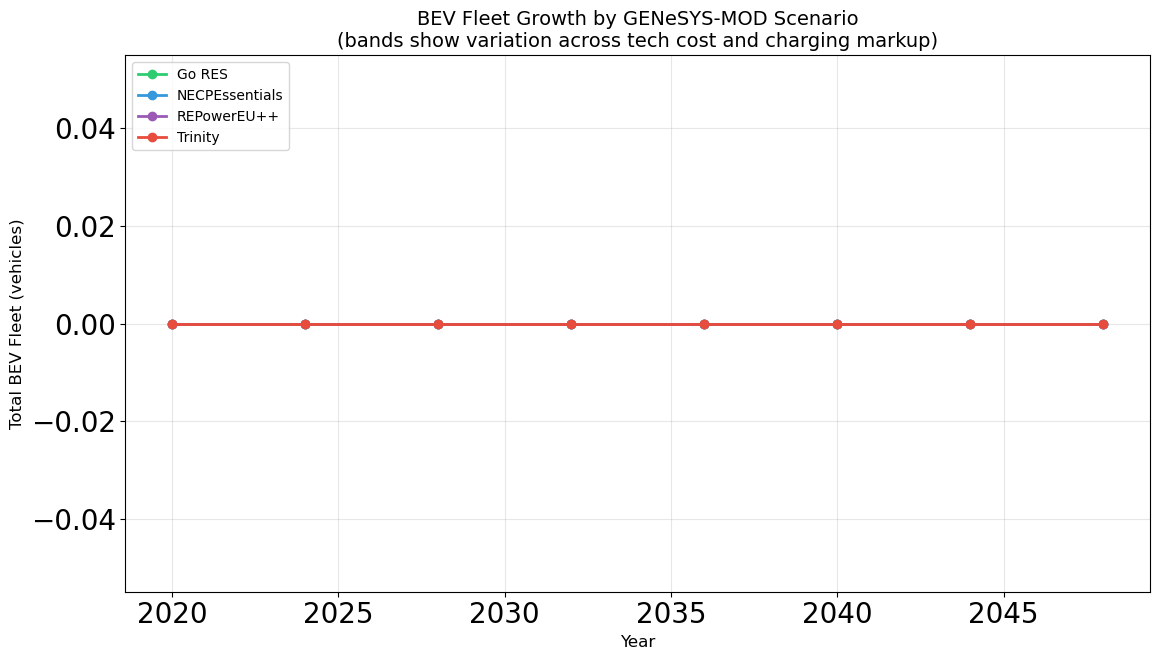

In [142]:
# Plot BEV adoption time series by GENeSYS scenario
plot_bev_timeseries_by_genesys(
    bev_timeseries,
    figsize=(12, 7),
    save_path=Path('figures/bev_timeseries_by_genesys.pdf')
)

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

Saved to figures\bev_top_corridors_by_genesys_2040.pdf


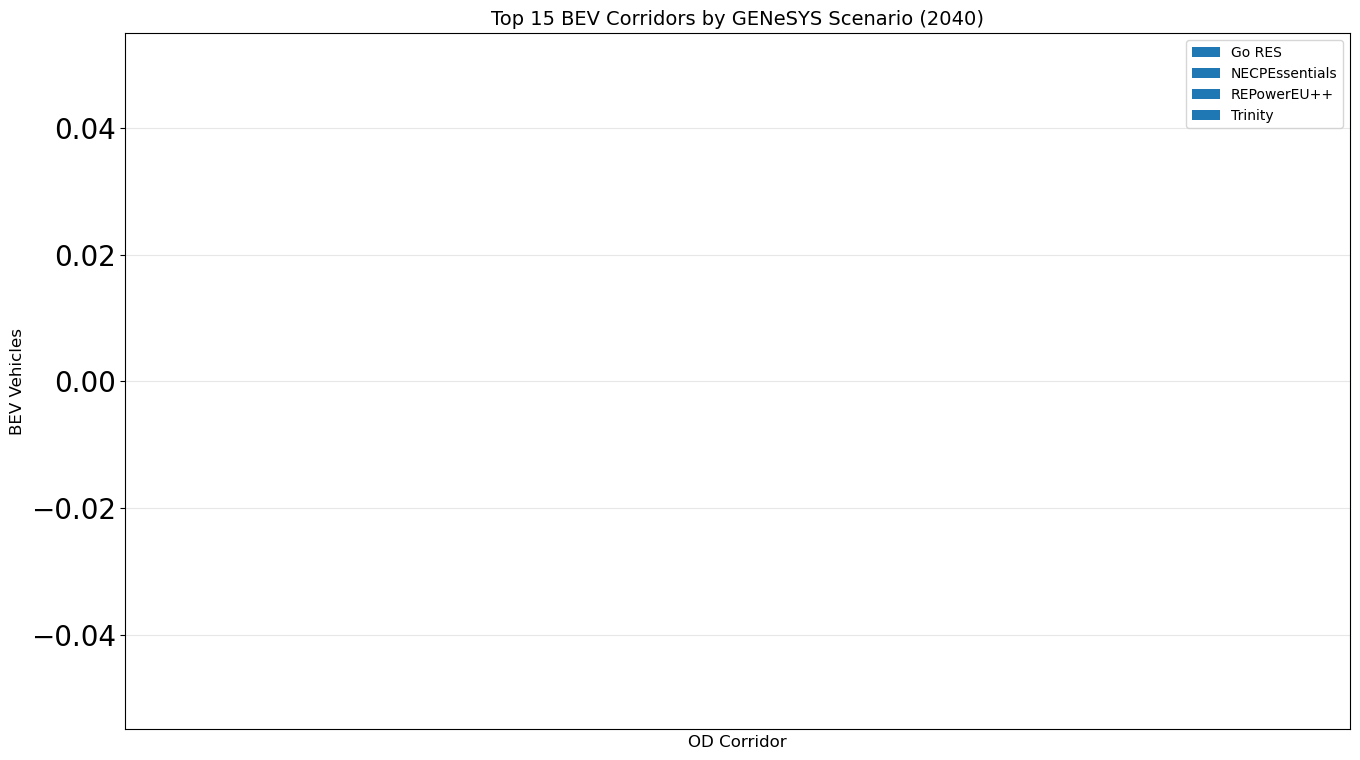

In [143]:
# Plot top BEV corridors by GENeSYS scenario (bar chart) - using pre-loaded matrices
top_corridors, corridor_data = plot_bev_od_bar_by_corridor(
    base_path, 
    target_year=2040,
    top_n=15,
    figsize=(14, 8),
    save_path=Path('figures/bev_top_corridors_by_genesys_2040.pdf'),
    preloaded_matrices=bev_od_matrices
)

In [144]:
# Plot BEV OD matrices for Go RES scenario - breakdown by markup and tech cost
# Rows: markup (15%, 30%), Columns: tech cost (0.7x, 1.0x, 1.3x)
plot_bev_od_by_markup_and_tech(
    base_path,
    genesys_scenario='Go RES v1.2',
    target_year=2040,
    preloaded_results=all_results,
    cases_metadata=cases_metadata,
    figsize=(16, 10),
    save_path=Path('figures/bev_od_go_res_by_params_2040.pdf')
)

No data found for Go RES v1.2


findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

Saved to figures\bev_totals_by_markup_tech_2040.pdf


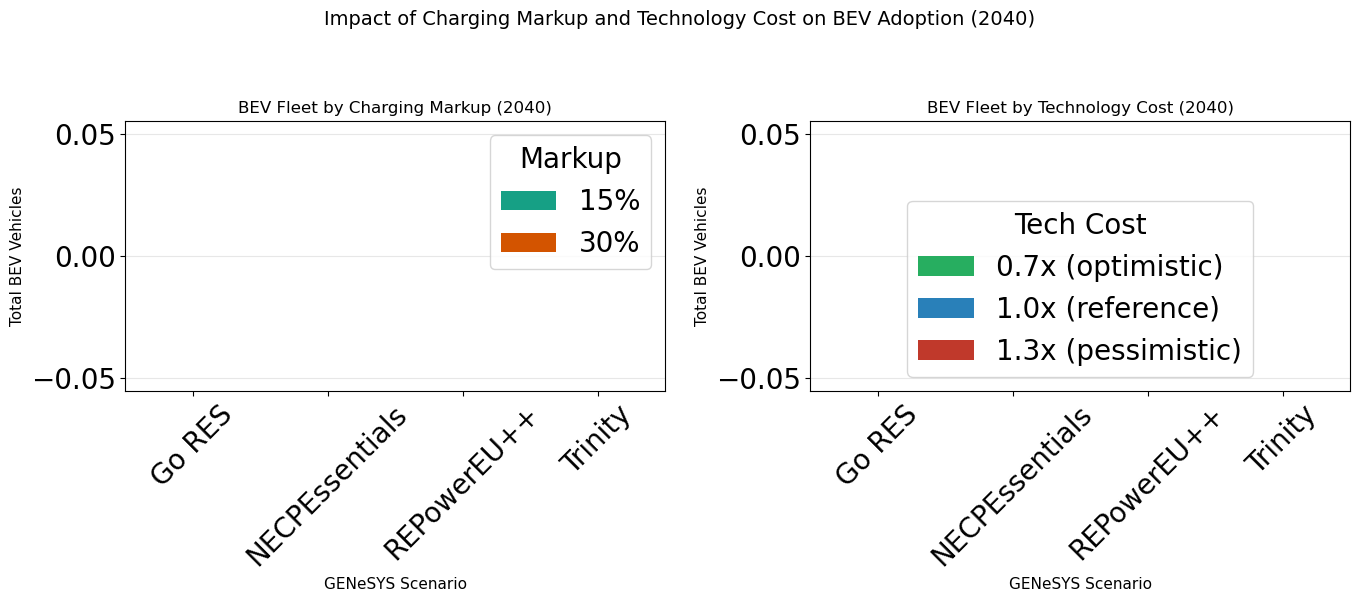


=== Impact Summary (2040) ===

By Markup (averaged across tech costs):
  15%: 0 BEVs
  30%: 0 BEVs

By Tech Cost (averaged across markups):
  0.7x: 0 BEVs
  1.0x: 0 BEVs
  1.3x: 0 BEVs


,genesys,markup,tech_cost,total_bevs
0,Go RES,15%,0.7,0
1,Go RES,15%,1.0,0
2,Go RES,15%,1.3,0
3,Go RES,30%,0.7,0
4,Go RES,30%,1.0,0
5,Go RES,30%,1.3,0
6,NECPEssentials,15%,0.7,0
7,NECPEssentials,15%,1.0,0
8,NECPEssentials,15%,1.3,0
9,NECPEssentials,30%,0.7,0


In [145]:
# Summary bar charts: Impact of markup and tech cost across all GENeSYS scenarios
plot_bev_totals_by_markup_and_tech(
    base_path,
    target_year=2040,
    preloaded_results=all_results,
    cases_metadata=cases_metadata,
    figsize=(14, 6),
    save_path=Path('figures/bev_totals_by_markup_tech_2040.pdf')
)

In [146]:
print("\nÃ¢Å“â€œ Uncertainty analysis visualization complete!")
print("\nFigures saved to 'figures/' folder:")
print("  - electrification_by_genesys_scenario.pdf")
print("  - electrification_by_tech_cost.pdf")
print("  - electrification_by_charging_markup.pdf")
print("  - electrification_heatmap_by_year.pdf")
print("  - absolute_bev_fleet.pdf")


Ã¢Å“â€œ Uncertainty analysis visualization complete!

Figures saved to 'figures/' folder:
  - electrification_by_genesys_scenario.pdf
  - electrification_by_tech_cost.pdf
  - electrification_by_charging_markup.pdf
  - electrification_heatmap_by_year.pdf
  - absolute_bev_fleet.pdf


In [147]:
# Calculate electrification speed and cost indicator for each scenario
plt.rcParams['text.usetex'] = False

scenario_metrics = []

for case in cases:
    scenario_id = case['case_id']
    
    # Get electrification data for this scenario
    scenario_elec = elec_df[elec_df['scenario_id'] == scenario_id].copy()
    
    if scenario_elec.empty:
        continue
    
    # Sort by year
    scenario_elec = scenario_elec.sort_values('year')
    
    # Calculate electrification speed (percentage points per year)
    # Using linear regression slope from 2020 to 2048
    scenario_elec_period = scenario_elec[(scenario_elec['year'] >= 2020) & (scenario_elec['year'] <= 2048)]
    
    if len(scenario_elec_period) >= 2:
        years = scenario_elec_period['year'].values
        bev_shares = scenario_elec_period['bev_share'].values
        
        # Linear regression: slope = electrification speed (pp/year)
        from numpy.polynomial import polynomial as P
        coeffs = np.polyfit(years, bev_shares, 1)
        elec_speed = coeffs[0]  # slope in percentage points per year
        
        # Calculate cost indicator
        # Combine electricity price multiplier and technology cost multiplier
        # Higher values = higher costs for BEV transition
        elec_mult = case['electricity_price_multiplier']
        tech_mult = case['tech_cost_multiplier']
        markup = case['charging_markup']
        
        # Relative cost indicator (normalized):
        # - elec_mult affects operating costs (fuel)
        # - tech_mult affects capital costs (vehicle purchase)
        # Both matter for total cost of ownership
        # Using weighted combination (capital ~40%, operating ~60% for trucks)
        cost_indicator = 0.4 * tech_mult + 0.6 * (elec_mult * (1 + markup))
        
        # Also calculate 2040 and 2048 BEV share
        bev_2040 = scenario_elec[scenario_elec['year'] == 2040]['bev_share'].values
        bev_2048 = scenario_elec[scenario_elec['year'] == 2048]['bev_share'].values
        
        scenario_metrics.append({
            'scenario_id': scenario_id,
            'genesys_scenario': case['genesys_scenario'],
            'charging_markup': case['charging_markup'],
            'tech_cost_multiplier': case['tech_cost_multiplier'],
            'elec_multiplier': elec_mult,
            'cost_indicator': cost_indicator,
            'elec_speed': elec_speed,
            'bev_share_2040': bev_2040[0] if len(bev_2040) > 0 else np.nan,
            'bev_share_2048': bev_2048[0] if len(bev_2048) > 0 else np.nan
        })

metrics_df = pd.DataFrame(scenario_metrics)
print(f"Calculated metrics for {len(metrics_df)} scenarios")
metrics_df.head(10)

Calculated metrics for 24 scenarios


,scenario_id,genesys_scenario,charging_markup,tech_cost_multiplier,elec_multiplier,cost_indicator,elec_speed,bev_share_2040,bev_share_2048
0,0,Go RES v1.2,0.15,0.7,1.000000,0.970000,1.955152,30.758338,48.578712
1,1,Go RES v1.2,0.15,1.0,1.000000,1.090000,1.048290,9.999164,31.439710
2,2,Go RES v1.2,0.15,1.3,1.000000,1.210000,0.000000,0.000000,0.000000
3,3,Go RES v1.2,0.30,0.7,1.000000,1.060000,1.954170,30.868617,48.525073
4,4,Go RES v1.2,0.30,1.0,1.000000,1.180000,1.048299,9.998801,31.440653
5,5,Go RES v1.2,0.30,1.3,1.000000,1.300000,0.000000,0.000000,0.000000
6,6,NECPEssentials v1.2,0.15,0.7,0.704652,0.766210,1.952151,31.112529,48.410409
7,7,NECPEssentials v1.2,0.15,1.0,0.704652,0.886210,1.048334,9.999999,31.440176
8,8,NECPEssentials v1.2,0.15,1.3,0.704652,1.006210,0.000000,0.000000,0.000000
9,9,NECPEssentials v1.2,0.30,0.7,0.704652,0.829628,1.952094,31.111705,48.409185


findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

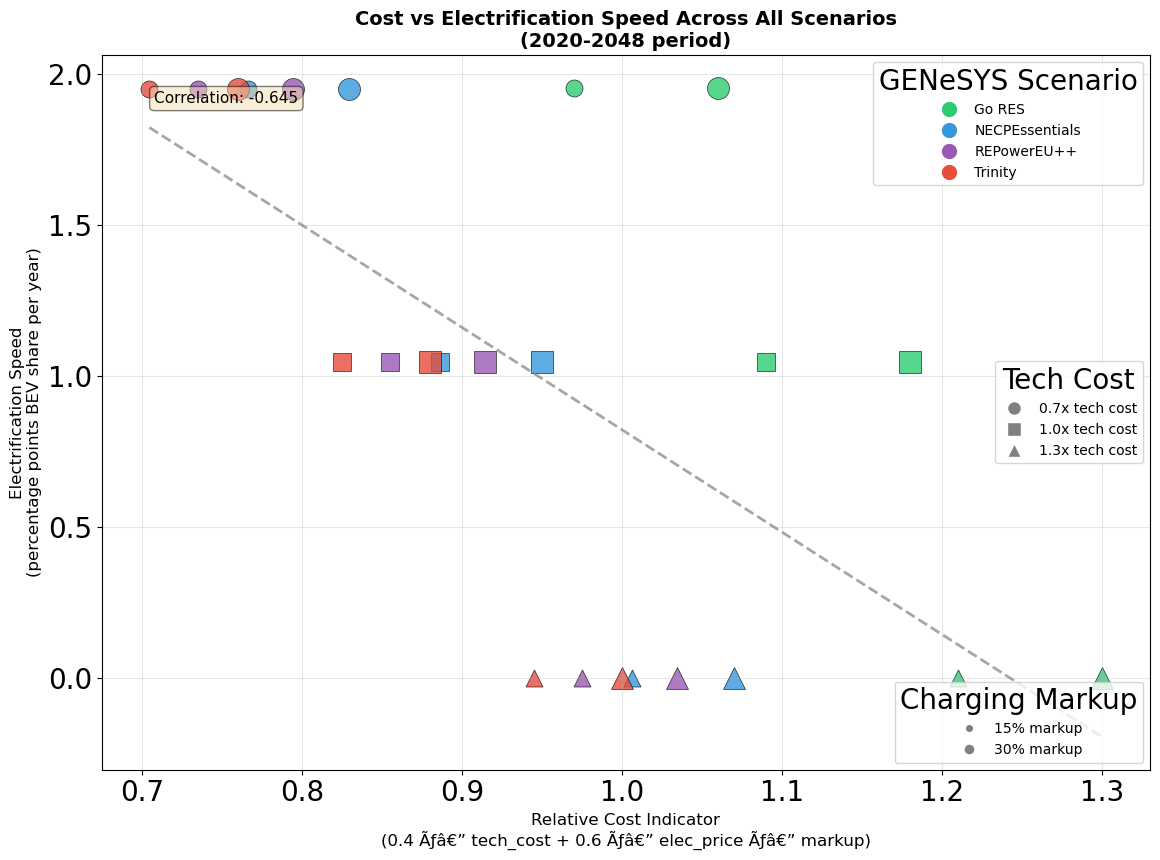


Correlation between cost indicator and electrification speed: -0.645
(Negative correlation = higher costs lead to slower electrification)


In [148]:
# Main figure: Cost Indicator vs Electrification Speed
fig, ax = plt.subplots(figsize=(12, 9))

# Color by GENeSYS scenario
colors = {
    'Go RES v1.2': '#2ecc71',
    'NECPEssentials v1.2': '#3498db',
    'REPowerEU++ v1.2': '#9b59b6',
    'Trinity v1.2': '#e74c3c'
}

# Marker by tech cost
markers = {
    0.7: 'o',   # circle - optimistic
    1.0: 's',   # square - reference
    1.3: '^'    # triangle - pessimistic
}

# Size by markup (larger = higher markup)
sizes = {
    0.15: 150,
    0.30: 250
}

# Plot each scenario
for _, row in metrics_df.iterrows():
    ax.scatter(
        row['cost_indicator'],
        row['elec_speed'],
        c=colors[row['genesys_scenario']],
        marker=markers[row['tech_cost_multiplier']],
        s=sizes[row['charging_markup']],
        alpha=0.8,
        edgecolors='black',
        linewidths=0.5
    )

# Create legend elements
from matplotlib.lines import Line2D

# GENeSYS legend (color)
genesys_handles = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor=color, markersize=12, label=name.replace(' v1.2', ''))
    for name, color in colors.items()
]

# Tech cost legend (marker shape)
tech_handles = [
    Line2D([0], [0], marker=marker, color='w', markerfacecolor='gray', markersize=10, 
           label=f'{mult:.1f}x tech cost')
    for mult, marker in markers.items()
]

# Markup legend (size)
markup_handles = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', markersize=np.sqrt(size)/2, 
           label=f'{int(markup*100)}% markup')
    for markup, size in sizes.items()
]

# Add legends
legend1 = ax.legend(handles=genesys_handles, title='GENeSYS Scenario', loc='upper right', fontsize=10)
ax.add_artist(legend1)
legend2 = ax.legend(handles=tech_handles, title='Tech Cost', loc='center right', fontsize=10)
ax.add_artist(legend2)
legend3 = ax.legend(handles=markup_handles, title='Charging Markup', loc='lower right', fontsize=10)

# Labels and title
ax.set_xlabel('Relative Cost Indicator\n(0.4 Ãƒâ€” tech_cost + 0.6 Ãƒâ€” elec_price Ãƒâ€” markup)', fontsize=12)
ax.set_ylabel('Electrification Speed\n(percentage points BEV share per year)', fontsize=12)
ax.set_title('Cost vs Electrification Speed Across All Scenarios\n(2020-2048 period)', fontsize=14, fontweight='bold')

ax.grid(True, alpha=0.3)

# Add trend line
z = np.polyfit(metrics_df['cost_indicator'], metrics_df['elec_speed'], 1)
p = np.poly1d(z)
x_line = np.linspace(metrics_df['cost_indicator'].min(), metrics_df['cost_indicator'].max(), 100)
ax.plot(x_line, p(x_line), '--', color='gray', alpha=0.7, linewidth=2, label='Trend')

# Calculate correlation
corr = metrics_df['cost_indicator'].corr(metrics_df['elec_speed'])
ax.text(0.05, 0.95, f'Correlation: {corr:.3f}', transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.savefig('figures/cost_vs_electrification_speed.pdf', bbox_inches='tight', dpi=150)
plt.show()

print(f"\nCorrelation between cost indicator and electrification speed: {corr:.3f}")
print("(Negative correlation = higher costs lead to slower electrification)")

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

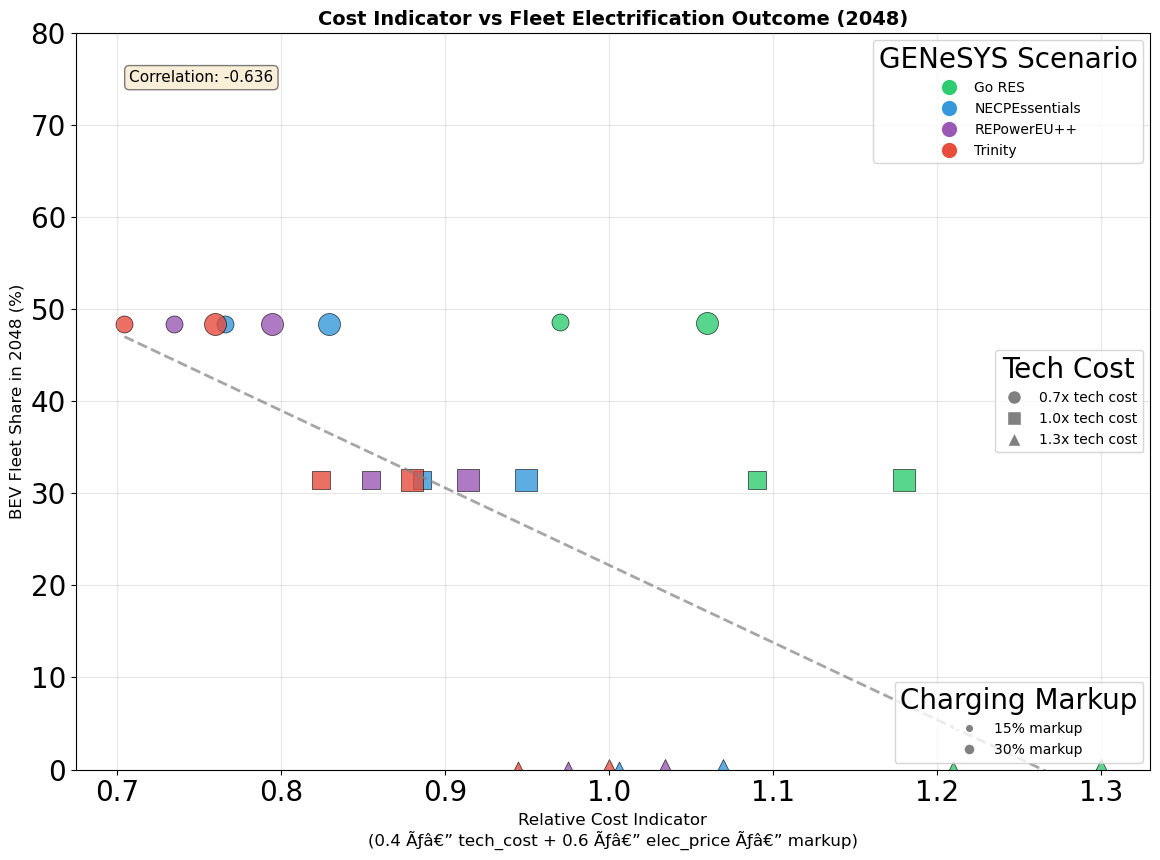


=== Scenario Summary: Cost vs Electrification ===
 scenario_id    genesys_scenario  tech_cost_multiplier  charging_markup  cost_indicator  elec_speed  bev_share_2048
           0         Go RES v1.2                   0.7             0.15           0.970       1.955          48.579
           1         Go RES v1.2                   1.0             0.15           1.090       1.048          31.440
           2         Go RES v1.2                   1.3             0.15           1.210       0.000           0.000
           3         Go RES v1.2                   0.7             0.30           1.060       1.954          48.525
           4         Go RES v1.2                   1.0             0.30           1.180       1.048          31.441
           5         Go RES v1.2                   1.3             0.30           1.300       0.000           0.000
           6 NECPEssentials v1.2                   0.7             0.15           0.766       1.952          48.410
           7 NECPEsse

In [149]:
# Alternative: Cost Indicator vs BEV Share at 2048
fig, ax = plt.subplots(figsize=(12, 9))

# Plot each scenario
for _, row in metrics_df.iterrows():
    ax.scatter(
        row['cost_indicator'],
        row['bev_share_2048'],
        c=colors[row['genesys_scenario']],
        marker=markers[row['tech_cost_multiplier']],
        s=sizes[row['charging_markup']],
        alpha=0.8,
        edgecolors='black',
        linewidths=0.5
    )

# Add legends (same as before)
legend1 = ax.legend(handles=genesys_handles, title='GENeSYS Scenario', loc='upper right', fontsize=10)
ax.add_artist(legend1)
legend2 = ax.legend(handles=tech_handles, title='Tech Cost', loc='center right', fontsize=10)
ax.add_artist(legend2)
legend3 = ax.legend(handles=markup_handles, title='Charging Markup', loc='lower right', fontsize=10)

# Labels and title
ax.set_xlabel('Relative Cost Indicator\n(0.4 Ãƒâ€” tech_cost + 0.6 Ãƒâ€” elec_price Ãƒâ€” markup)', fontsize=12)
ax.set_ylabel('BEV Fleet Share in 2048 (%)', fontsize=12)
ax.set_title('Cost Indicator vs Fleet Electrification Outcome (2048)', fontsize=14, fontweight='bold')

ax.grid(True, alpha=0.3)
ax.set_ylim(0, 80)

# Add trend line
z = np.polyfit(metrics_df['cost_indicator'], metrics_df['bev_share_2048'], 1)
p = np.poly1d(z)
x_line = np.linspace(metrics_df['cost_indicator'].min(), metrics_df['cost_indicator'].max(), 100)
ax.plot(x_line, p(x_line), '--', color='gray', alpha=0.7, linewidth=2)

# Calculate correlation
corr = metrics_df['cost_indicator'].corr(metrics_df['bev_share_2048'])
ax.text(0.05, 0.95, f'Correlation: {corr:.3f}', transform=ax.transAxes, fontsize=11,
        verticalalignment='top', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.savefig('figures/cost_vs_bev_share_2048.pdf', bbox_inches='tight', dpi=150)
plt.show()

# Print scenario summary table
print("\n=== Scenario Summary: Cost vs Electrification ===")
print(metrics_df[['scenario_id', 'genesys_scenario', 'tech_cost_multiplier', 'charging_markup', 
                   'cost_indicator', 'elec_speed', 'bev_share_2048']].round(3).to_string(index=False))

## Cost vs Electrification Speed Analysis

This analysis plots each scenario based on:
- **X-axis**: Relative cost indicator (combining electricity price and technology costs)
- **Y-axis**: Electrification speed (average annual increase in BEV fleet share)

In [150]:
# =============================================================================
# COST DIFFERENCE ANALYSIS: (â‚¬/tkm ICEV) - (â‚¬/tkm BEV)
# =============================================================================
# Uses actual data from TechVehicle.yaml:
# - capital_cost: vehicle purchase price (â‚¬)
# - maintenance_cost_annual: annual maintenance (â‚¬/year) - indexed by [generation][year]
# - spec_cons: specific consumption (ICEV: Wh/tkm, BEV: kWh/km)
# - Lifetime: vehicle lifetime (years)
# - AnnualRange: annual driving distance (km/year)
#
# Positive cost difference = BEV is cheaper (cost advantage for electrification)
# Negative cost difference = ICEV is cheaper

plt.rcParams['text.usetex'] = False

def load_scenario_costs(scenario_id, base_path, year_index=5):
    """
    Load cost data for a scenario and calculate â‚¬/tkm for ICEV and BEV.
    Uses actual parameters from TechVehicle.yaml.
    
    Parameters:
    -----------
    scenario_id : int
        Scenario number (0-23)
    base_path : Path
        Base path to the examples/moving_loads_SM folder
    year_index : int
        Index into cost arrays (0=2020, 5=2040 for 4-year steps starting 2020)
        
    Returns:
    --------
    dict with icev_cost_per_tkm, bev_cost_per_tkm, cost_difference and components
    """
    scenario_path = base_path / "input_data" / "uncertainty_scenarios" / f"scenario_{scenario_id:03d}"
    
    # Load FuelCost.yaml for electricity and diesel prices
    with open(scenario_path / "FuelCost.yaml", 'r') as f:
        fuel_costs = yaml.safe_load(f)
    
    # Load TechVehicle.yaml for vehicle costs and consumption
    with open(scenario_path / "TechVehicle.yaml", 'r') as f:
        tech_vehicles = yaml.safe_load(f)
    
    # Extract fuel costs
    elec_cost_per_kwh = None
    diesel_cost_per_kwh = None
    
    for fc in fuel_costs:
        if fc['fuel'] == 'electricity' and fc['fueling_infr_type_id'] == 1:  # MCS charging
            elec_cost_per_kwh = fc['cost_per_kWh'][year_index]
        elif fc['fuel'] == 'diesel':
            diesel_cost_per_kwh = fc['cost_per_kWh'][year_index]
    
    # Fallback for diesel cost if not in FuelCost (sometimes modeled separately)
    if diesel_cost_per_kwh is None or diesel_cost_per_kwh == 0:
        diesel_cost_per_kwh = 0.0975  # Reference value from FuelCost.yaml
    
    # Extract vehicle data
    icev_data = None
    bev_data = None
    
    for tv in tech_vehicles:
        if tv['name'] == 'ICEV':
            icev_data = tv
        elif tv['name'] == 'BEV':
            bev_data = tv
    
    if not icev_data or not bev_data:
        return None
    
    # =========================================================================
    # Extract parameters from TechVehicle.yaml
    # =========================================================================
    
    # Lifetime (years) - from TechVehicle
    icev_lifetime = icev_data['Lifetime'][year_index]  # 12 years
    bev_lifetime = bev_data['Lifetime'][year_index]    # 12 years
    
    # Annual range (km/year) - from TechVehicle
    icev_annual_km = icev_data['AnnualRange'][year_index]  # 136,750 km/year
    bev_annual_km = bev_data['AnnualRange'][year_index]    # 136,750 km/year
    
    # Total lifetime km
    icev_lifetime_km = icev_lifetime * icev_annual_km
    bev_lifetime_km = bev_lifetime * bev_annual_km
    
    # Capital costs (â‚¬) - from TechVehicle
    icev_capital = icev_data['capital_cost'][year_index]
    bev_capital = bev_data['capital_cost'][year_index]
    
    # Maintenance cost annual (â‚¬/year) - from TechVehicle
    # Structure: maintenance_cost_annual[generation_index][year_index]
    # Using generation 0 (newest vehicles) for simplicity
    icev_maintenance_annual = icev_data['maintenance_cost_annual'][0][year_index]
    bev_maintenance_annual = bev_data['maintenance_cost_annual'][0][year_index]
    
    # Specific consumption - from TechVehicle
    # ICEV: spec_cons in Wh/tkm (converted to kWh/km with load assumption)
    # BEV: spec_cons in kWh/km
    icev_spec_cons = icev_data['spec_cons'][year_index]  # Wh/tkm
    bev_spec_cons = bev_data['spec_cons'][year_index]    # kWh/km
    
    # Average load assumption (tonnes)
    avg_load_tonnes = 20
    
    # Convert ICEV consumption to kWh/km
    icev_kwh_per_km = icev_spec_cons * avg_load_tonnes / 1000
    
    # =========================================================================
    # Calculate cost components per km
    # =========================================================================
    
    # Capital cost per km (â‚¬/km)
    icev_capital_per_km = icev_capital / icev_lifetime_km
    bev_capital_per_km = bev_capital / bev_lifetime_km
    
    # Maintenance cost per km (â‚¬/km)
    icev_maintenance_per_km = (icev_maintenance_annual * icev_lifetime) / icev_lifetime_km
    bev_maintenance_per_km = (bev_maintenance_annual * bev_lifetime) / bev_lifetime_km
    
    # Fuel/energy cost per km (â‚¬/km)
    icev_fuel_per_km = icev_kwh_per_km * diesel_cost_per_kwh
    bev_fuel_per_km = bev_spec_cons * elec_cost_per_kwh
    
    # =========================================================================
    # Total cost per km and per tkm
    # =========================================================================
    
    # Total cost per km (capital + maintenance + fuel)
    icev_cost_per_km = icev_capital_per_km + icev_maintenance_per_km + icev_fuel_per_km
    bev_cost_per_km = bev_capital_per_km + bev_maintenance_per_km + bev_fuel_per_km
    
    # Convert to â‚¬/tkm (divide by average load)
    icev_cost_per_tkm = icev_cost_per_km / avg_load_tonnes
    bev_cost_per_tkm = bev_cost_per_km / avg_load_tonnes
    
    # Cost difference: positive = BEV cheaper
    cost_diff = icev_cost_per_tkm - bev_cost_per_tkm
    
    return {
        'icev_cost_per_tkm': icev_cost_per_tkm,
        'bev_cost_per_tkm': bev_cost_per_tkm,
        'cost_difference': cost_diff,
        # Component breakdown (per km)
        'icev_capital_per_km': icev_capital_per_km,
        'bev_capital_per_km': bev_capital_per_km,
        'icev_maintenance_per_km': icev_maintenance_per_km,
        'bev_maintenance_per_km': bev_maintenance_per_km,
        'icev_fuel_per_km': icev_fuel_per_km,
        'bev_fuel_per_km': bev_fuel_per_km,
        # Input parameters
        'elec_cost_kwh': elec_cost_per_kwh,
        'diesel_cost_kwh': diesel_cost_per_kwh,
        'bev_capital': bev_capital,
        'icev_capital': icev_capital,
        'bev_consumption_kwh_km': bev_spec_cons,
        'icev_consumption_kwh_km': icev_kwh_per_km,
        'lifetime_years': icev_lifetime,
        'annual_km': icev_annual_km
    }

# Calculate costs for all scenarios at year 2040 (index 5)
cost_data = []
year_index = 5  # 2040

for case in cases:
    scenario_id = case['case_id']
    costs = load_scenario_costs(scenario_id, base_path, year_index=year_index)
    
    if costs:
        cost_data.append({
            'scenario_id': scenario_id,
            'genesys_scenario': case['genesys_scenario'],
            'charging_markup': case['charging_markup'],
            'tech_cost_multiplier': case['tech_cost_multiplier'],
            'elec_multiplier': case['electricity_price_multiplier'],
            **costs
        })

cost_df = pd.DataFrame(cost_data)

# Merge with electrification metrics
metrics_with_costs = metrics_df.merge(
    cost_df[['scenario_id', 'cost_difference', 'icev_cost_per_tkm', 'bev_cost_per_tkm', 
             'elec_cost_kwh', 'bev_capital', 'icev_capital_per_km', 'bev_capital_per_km',
             'icev_maintenance_per_km', 'bev_maintenance_per_km', 'icev_fuel_per_km', 'bev_fuel_per_km',
             'lifetime_years', 'annual_km']],
    on='scenario_id'
)

# Print cost breakdown for first scenario
print("=" * 80)
print("LEVELIZED COST CALCULATION - Using TechVehicle.yaml parameters")
print("=" * 80)
first_cost = cost_df.iloc[0]
print(f"\nParameters (from TechVehicle.yaml):")
print(f"  Vehicle lifetime:     {first_cost['lifetime_years']:.0f} years")
print(f"  Annual driving:       {first_cost['annual_km']:,.0f} km/year")
print(f"  Lifetime distance:    {first_cost['lifetime_years'] * first_cost['annual_km']:,.0f} km")
print(f"  Average load:         20 tonnes")

print(f"\nCost components (â‚¬/km) for Scenario 0 (Go RES, tech=0.7):")
print(f"  {'Component':<20} {'ICEV':>12} {'BEV':>12}")
print(f"  {'-'*20} {'-'*12} {'-'*12}")
print(f"  {'Capital':.<20} {first_cost['icev_capital_per_km']:>12.4f} {first_cost['bev_capital_per_km']:>12.4f}")
print(f"  {'Maintenance':.<20} {first_cost['icev_maintenance_per_km']:>12.4f} {first_cost['bev_maintenance_per_km']:>12.4f}")
print(f"  {'Fuel/Energy':.<20} {first_cost['icev_fuel_per_km']:>12.4f} {first_cost['bev_fuel_per_km']:>12.4f}")
print(f"  {'-'*20} {'-'*12} {'-'*12}")
icev_total = first_cost['icev_capital_per_km'] + first_cost['icev_maintenance_per_km'] + first_cost['icev_fuel_per_km']
bev_total = first_cost['bev_capital_per_km'] + first_cost['bev_maintenance_per_km'] + first_cost['bev_fuel_per_km']
print(f"  {'TOTAL â‚¬/km':.<20} {icev_total:>12.4f} {bev_total:>12.4f}")
print(f"  {'TOTAL â‚¬/tkm':.<20} {icev_total/20:>12.5f} {bev_total/20:>12.5f}")

print(f"\n\nCost analysis for year 2040 (all scenarios):")
print("=" * 80)
print(metrics_with_costs[['scenario_id', 'genesys_scenario', 'tech_cost_multiplier',
                          'icev_cost_per_tkm', 'bev_cost_per_tkm', 'cost_difference']].round(5).to_string(index=False))

print(f"\n\nCost difference range: {metrics_with_costs['cost_difference'].min()*100:.3f} to {metrics_with_costs['cost_difference'].max()*100:.3f} ct/tkm")
print("(Positive = BEV is cheaper than ICEV)")

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\simuser\\Documents\\AntoniaGolab\\Scand_Med_analysis\\SM_baby_2\\iDesignRES_transcompmodel\\examples\\moving_loads_SM\\input_data\\uncertainty_scenarios\\input_data\\uncertainty_scenarios\\scenario_000\\FuelCost.yaml'

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo


findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

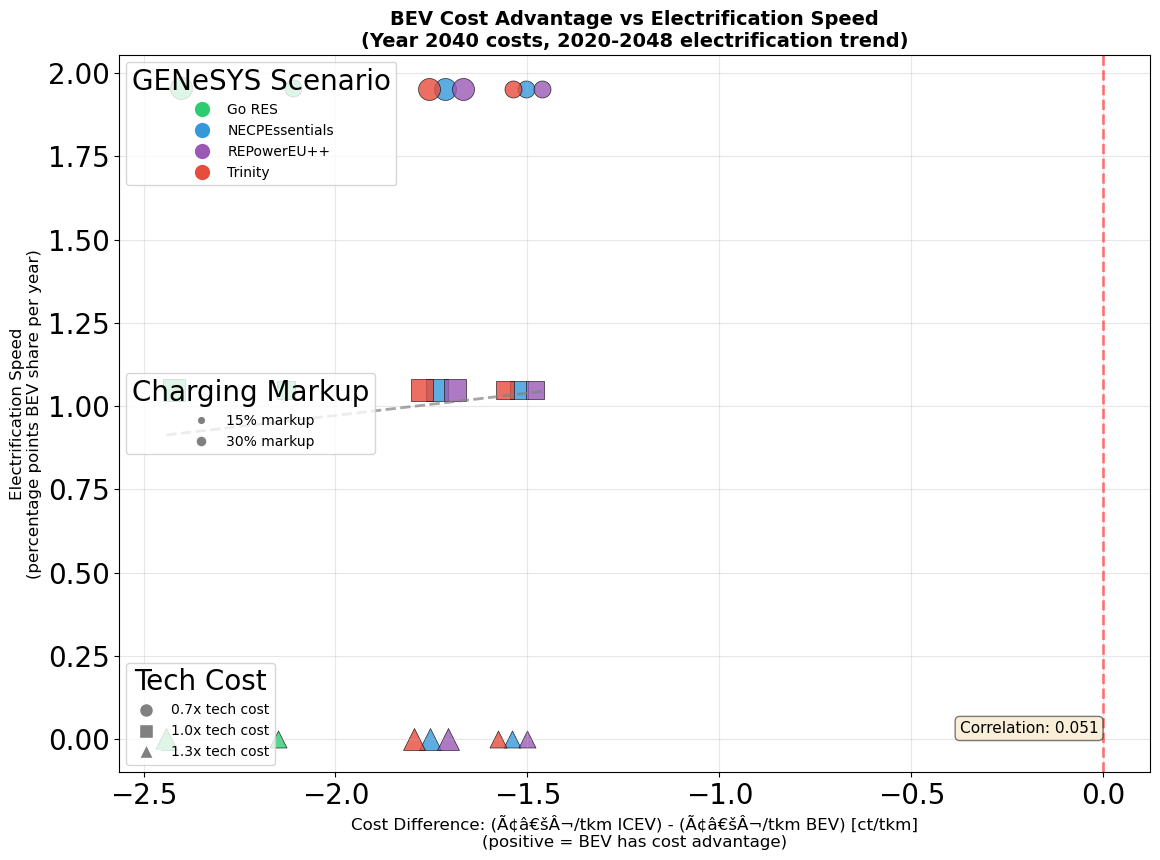


Correlation between BEV cost advantage and electrification speed: 0.051
(Positive correlation = larger BEV cost advantage leads to faster electrification)


In [ ]:
# =============================================================================
# MAIN FIGURE: Cost Difference (Ã¢â€šÂ¬/tkm ICEV - Ã¢â€šÂ¬/tkm BEV) vs Electrification Speed
# =============================================================================
# X-axis: Cost difference in Ã¢â€šÂ¬/tkm (positive = BEV cheaper = cost advantage)
# Y-axis: Electrification speed (pp BEV share per year)

fig, ax = plt.subplots(figsize=(12, 9))

# Color by GENeSYS scenario
colors = {
    'Go RES v1.2': '#2ecc71',
    'NECPEssentials v1.2': '#3498db',
    'REPowerEU++ v1.2': '#9b59b6',
    'Trinity v1.2': '#e74c3c'
}

# Marker by tech cost
markers = {
    0.7: 'o',   # circle - optimistic
    1.0: 's',   # square - reference
    1.3: '^'    # triangle - pessimistic
}

# Size by markup (larger = higher markup)
sizes = {
    0.15: 150,
    0.30: 250
}

# Plot each scenario
for _, row in metrics_with_costs.iterrows():
    ax.scatter(
        row['cost_difference'] * 100,  # Convert to cents/tkm for readability
        row['elec_speed'],
        c=colors[row['genesys_scenario']],
        marker=markers[row['tech_cost_multiplier']],
        s=sizes[row['charging_markup']],
        alpha=0.8,
        edgecolors='black',
        linewidths=0.5
    )

# Create legend elements
from matplotlib.lines import Line2D

# GENeSYS legend (color)
genesys_handles = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor=color, markersize=12, label=name.replace(' v1.2', ''))
    for name, color in colors.items()
]

# Tech cost legend (marker shape)
tech_handles = [
    Line2D([0], [0], marker=marker, color='w', markerfacecolor='gray', markersize=10, 
           label=f'{mult:.1f}x tech cost')
    for mult, marker in markers.items()
]

# Markup legend (size)
markup_handles = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', markersize=np.sqrt(size)/2, 
           label=f'{int(markup*100)}% markup')
    for markup, size in sizes.items()
]

# Add legends
legend1 = ax.legend(handles=genesys_handles, title='GENeSYS Scenario', loc='upper left', fontsize=10)
ax.add_artist(legend1)
legend2 = ax.legend(handles=tech_handles, title='Tech Cost', loc='lower left', fontsize=10)
ax.add_artist(legend2)
legend3 = ax.legend(handles=markup_handles, title='Charging Markup', loc='center left', fontsize=10,
                    bbox_to_anchor=(0, 0.5))

# Labels and title
ax.set_xlabel('Cost Difference: (Ã¢â€šÂ¬/tkm ICEV) - (Ã¢â€šÂ¬/tkm BEV) [ct/tkm]\n(positive = BEV has cost advantage)', fontsize=12)
ax.set_ylabel('Electrification Speed\n(percentage points BEV share per year)', fontsize=12)
ax.set_title('BEV Cost Advantage vs Electrification Speed\n(Year 2040 costs, 2020-2048 electrification trend)', fontsize=14, fontweight='bold')

ax.grid(True, alpha=0.3)

# Add vertical line at zero (cost parity)
ax.axvline(x=0, color='red', linestyle='--', alpha=0.5, linewidth=2, label='Cost parity')

# Add trend line
x_data = metrics_with_costs['cost_difference'] * 100
y_data = metrics_with_costs['elec_speed']
z = np.polyfit(x_data, y_data, 1)
p = np.poly1d(z)
x_line = np.linspace(x_data.min(), x_data.max(), 100)
ax.plot(x_line, p(x_line), '--', color='gray', alpha=0.7, linewidth=2)

# Calculate correlation
corr = x_data.corr(y_data)
ax.text(0.95, 0.05, f'Correlation: {corr:.3f}', transform=ax.transAxes, fontsize=11,
        verticalalignment='bottom', horizontalalignment='right',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.savefig('figures/cost_difference_vs_electrification_speed.pdf', bbox_inches='tight', dpi=150)
plt.show()

print(f"\nCorrelation between BEV cost advantage and electrification speed: {corr:.3f}")
print("(Positive correlation = larger BEV cost advantage leads to faster electrification)")

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

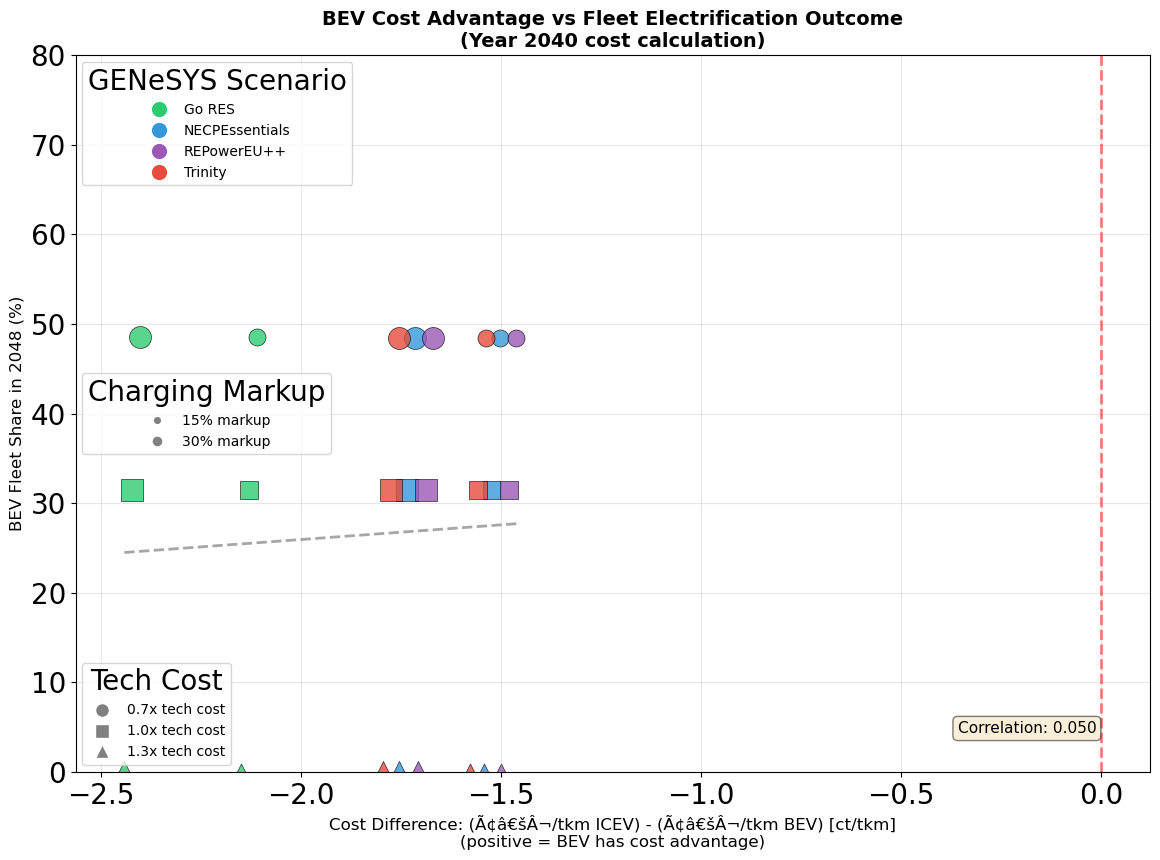


SUMMARY: Cost Difference vs Electrification

Cost difference (Ã¢â€šÂ¬/tkm ICEV - Ã¢â€šÂ¬/tkm BEV) at 2040:
  Min: -2.44 ct/tkm
  Max: -1.46 ct/tkm
  Mean: -1.79 ct/tkm

Interpretation:
  On average, ICEV is still cheaper than BEV

Correlation with electrification speed: 0.051
Correlation with BEV share 2048: 0.050


In [ ]:
# =============================================================================
# ALTERNATIVE: Cost Difference vs BEV Share at 2048
# =============================================================================

fig, ax = plt.subplots(figsize=(12, 9))

# Plot each scenario
for _, row in metrics_with_costs.iterrows():
    ax.scatter(
        row['cost_difference'] * 100,  # Convert to cents/tkm
        row['bev_share_2048'],
        c=colors[row['genesys_scenario']],
        marker=markers[row['tech_cost_multiplier']],
        s=sizes[row['charging_markup']],
        alpha=0.8,
        edgecolors='black',
        linewidths=0.5
    )

# Add legends
legend1 = ax.legend(handles=genesys_handles, title='GENeSYS Scenario', loc='upper left', fontsize=10)
ax.add_artist(legend1)
legend2 = ax.legend(handles=tech_handles, title='Tech Cost', loc='lower left', fontsize=10)
ax.add_artist(legend2)
legend3 = ax.legend(handles=markup_handles, title='Charging Markup', loc='center left', fontsize=10,
                    bbox_to_anchor=(0, 0.5))

# Labels and title
ax.set_xlabel('Cost Difference: (Ã¢â€šÂ¬/tkm ICEV) - (Ã¢â€šÂ¬/tkm BEV) [ct/tkm]\n(positive = BEV has cost advantage)', fontsize=12)
ax.set_ylabel('BEV Fleet Share in 2048 (%)', fontsize=12)
ax.set_title('BEV Cost Advantage vs Fleet Electrification Outcome\n(Year 2040 cost calculation)', fontsize=14, fontweight='bold')

ax.grid(True, alpha=0.3)
ax.set_ylim(0, 80)

# Add vertical line at zero (cost parity)
ax.axvline(x=0, color='red', linestyle='--', alpha=0.5, linewidth=2, label='Cost parity')

# Add trend line
x_data = metrics_with_costs['cost_difference'] * 100
y_data = metrics_with_costs['bev_share_2048']
z = np.polyfit(x_data, y_data, 1)
p = np.poly1d(z)
x_line = np.linspace(x_data.min(), x_data.max(), 100)
ax.plot(x_line, p(x_line), '--', color='gray', alpha=0.7, linewidth=2)

# Calculate correlation
corr = x_data.corr(y_data)
ax.text(0.95, 0.05, f'Correlation: {corr:.3f}', transform=ax.transAxes, fontsize=11,
        verticalalignment='bottom', horizontalalignment='right',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.savefig('figures/cost_difference_vs_bev_share_2048.pdf', bbox_inches='tight', dpi=150)
plt.show()

# Summary statistics
print("\n" + "=" * 80)
print("SUMMARY: Cost Difference vs Electrification")
print("=" * 80)
print(f"\nCost difference (Ã¢â€šÂ¬/tkm ICEV - Ã¢â€šÂ¬/tkm BEV) at 2040:")
print(f"  Min: {metrics_with_costs['cost_difference'].min()*100:.2f} ct/tkm")
print(f"  Max: {metrics_with_costs['cost_difference'].max()*100:.2f} ct/tkm")
print(f"  Mean: {metrics_with_costs['cost_difference'].mean()*100:.2f} ct/tkm")

print(f"\nInterpretation:")
if metrics_with_costs['cost_difference'].mean() > 0:
    print("  On average, BEV has a cost advantage over ICEV")
else:
    print("  On average, ICEV is still cheaper than BEV")

print(f"\nCorrelation with electrification speed: {metrics_with_costs['cost_difference'].corr(metrics_with_costs['elec_speed']):.3f}")
print(f"Correlation with BEV share 2048: {corr:.3f}")

In [ ]:
# Explanation: Why GENeSYS scenarios dominate while markup has minimal effect
# ================================================================================

print("=" * 80)
print("PARAMETER SENSITIVITY ANALYSIS: Why GENeSYS matters more than markup")
print("=" * 80)

# Show the electricity price multipliers for each GENeSYS scenario
genesys_multipliers = {
    'Go RES v1.2': 1.000,
    'NECPEssentials v1.2': 0.705,
    'REPowerEU++ v1.2': 0.659,
    'Trinity v1.2': 0.615
}

print("\n1. GENeSYS Electricity Price Multipliers:")
print("-" * 50)
for scenario, mult in genesys_multipliers.items():
    diff = (1.0 - mult) * 100
    print(f"  {scenario:20s}: {mult:.3f} ({'-' if diff > 0 else '+'}{abs(diff):.1f}% from baseline)")

print(f"\n  >> Price RANGE across GENeSYS: {(1.0 - 0.615) * 100:.1f}% (38.5%)")

# Charging markup comparison
print("\n2. Charging Infrastructure Markup:")
print("-" * 50)
print(f"  15% markup: factor = {1.15:.3f}")
print(f"  30% markup: factor = {1.30:.3f}")
print(f"  >> Ratio (30%/15%): {1.30/1.15:.4f} = {((1.30/1.15)-1)*100:.1f}% difference")

# Combined effect calculation
print("\n3. Combined Electricity Costs (base Ãƒâ€” genesys_mult Ãƒâ€” (1+markup)):")
print("-" * 70)
print(f"{'Scenario':<25} {'15% markup':<15} {'30% markup':<15} {'Markup effect':<15}")
print("-" * 70)

for scenario, mult in genesys_multipliers.items():
    cost_15 = mult * 1.15
    cost_30 = mult * 1.30
    markup_diff = (cost_30 / cost_15 - 1) * 100
    print(f"{scenario:<25} {cost_15:.3f}          {cost_30:.3f}          {markup_diff:+.1f}%")

print("\n4. KEY INSIGHT:")
print("-" * 70)
print("  Ã¢â‚¬Â¢ GENeSYS price range: 38.5% (Go RES vs Trinity)")
print("  Ã¢â‚¬Â¢ Markup effect: ~13% (constant across all scenarios)")
print("  Ã¢â‚¬Â¢ GENeSYS effect is ~3x larger than markup effect!")
print("  ")
print("  The optimizer sees electricity costs in this order:")
print("    LOWEST:  Trinity + 15% markup   = 0.615 Ãƒâ€” 1.15 = 0.707")
print("    ...      Trinity + 30% markup   = 0.615 Ãƒâ€” 1.30 = 0.800")
print("    ...      NECPEss + 15% markup   = 0.705 Ãƒâ€” 1.15 = 0.811")
print("    ...      NECPEss + 30% markup   = 0.705 Ãƒâ€” 1.30 = 0.916")
print("    ...      REPower + 15% markup   = 0.659 Ãƒâ€” 1.15 = 0.758")
print("    ...      REPower + 30% markup   = 0.659 Ãƒâ€” 1.30 = 0.857")
print("    ...      Go RES  + 15% markup   = 1.000 Ãƒâ€” 1.15 = 1.150")
print("    HIGHEST: Go RES  + 30% markup   = 1.000 Ãƒâ€” 1.30 = 1.300")
print("\n  Note: Even 30% markup with Trinity (0.80) is cheaper than")
print("        15% markup with Go RES (1.15)!")

PARAMETER SENSITIVITY ANALYSIS: Why GENeSYS matters more than markup

1. GENeSYS Electricity Price Multipliers:
--------------------------------------------------
  Go RES v1.2         : 1.000 (+0.0% from baseline)
  NECPEssentials v1.2 : 0.705 (-29.5% from baseline)
  REPowerEU++ v1.2    : 0.659 (-34.1% from baseline)
  Trinity v1.2        : 0.615 (-38.5% from baseline)

  >> Price RANGE across GENeSYS: 38.5% (38.5%)

2. Charging Infrastructure Markup:
--------------------------------------------------
  15% markup: factor = 1.150
  30% markup: factor = 1.300
  >> Ratio (30%/15%): 1.1304 = 13.0% difference

3. Combined Electricity Costs (base Ãƒâ€” genesys_mult Ãƒâ€” (1+markup)):
----------------------------------------------------------------------
Scenario                  15% markup      30% markup      Markup effect  
----------------------------------------------------------------------
Go RES v1.2               1.150          1.300          +13.0%
NECPEssentials v1.2       0.811

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

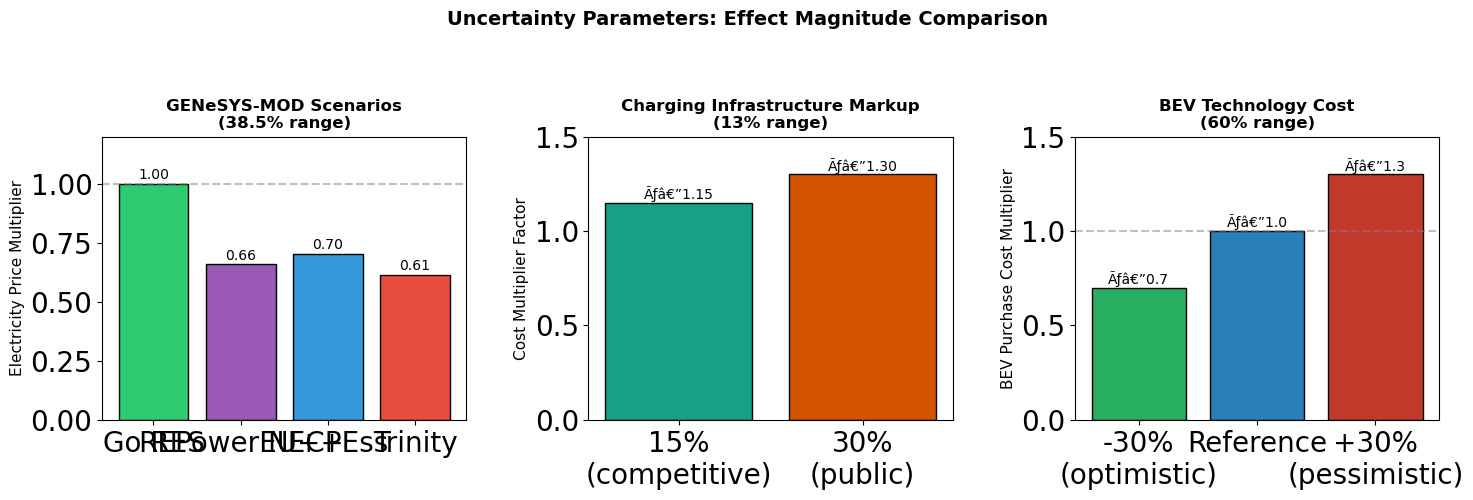


Summary of parameter effects on BEV adoption:
1. GENeSYS scenarios:  LARGE effect (38.5% electricity price range)
2. Tech cost:          LARGE effect (60% BEV purchase cost range)
3. Charging markup:    SMALL effect (13% electricity cost difference)

The charging markup has minimal effect because:
  - It only affects a ~13% difference in charging costs
  - This is dominated by the GENeSYS scenario (38.5% range)
  - Even with high markup, low-price scenarios (Trinity)
    have cheaper electricity than Go RES with low markup


In [ ]:
# Visualize parameter effects: GENeSYS vs Markup vs Tech Cost
plt.rcParams['text.usetex'] = False

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# GENeSYS effect
ax1 = axes[0]
genesys_scenarios = ['Go RES', 'REPowerEU++', 'NECPEss', 'Trinity']
elec_multipliers = [1.0, 0.659, 0.705, 0.615]
colors_genesys = ['#2ecc71', '#9b59b6', '#3498db', '#e74c3c']
bars1 = ax1.bar(genesys_scenarios, elec_multipliers, color=colors_genesys, edgecolor='black')
ax1.set_ylabel('Electricity Price Multiplier', fontsize=11)
ax1.set_title('GENeSYS-MOD Scenarios\n(38.5% range)', fontsize=12, fontweight='bold')
ax1.set_ylim(0, 1.2)
ax1.axhline(y=1.0, color='gray', linestyle='--', alpha=0.5)
for bar, mult in zip(bars1, elec_multipliers):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, 
             f'{mult:.2f}', ha='center', fontsize=10)

# Charging markup effect  
ax2 = axes[1]
markups = ['15%\n(competitive)', '30%\n(public)']
markup_factors = [1.15, 1.30]
colors_markup = ['#16a085', '#d35400']
bars2 = ax2.bar(markups, markup_factors, color=colors_markup, edgecolor='black')
ax2.set_ylabel('Cost Multiplier Factor', fontsize=11)
ax2.set_title('Charging Infrastructure Markup\n(13% range)', fontsize=12, fontweight='bold')
ax2.set_ylim(0, 1.5)
for bar, mult in zip(bars2, markup_factors):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
             f'Ãƒâ€”{mult:.2f}', ha='center', fontsize=10)

# Tech cost effect (impact on BEV purchase cost, not electricity)
ax3 = axes[2]
tech_labels = ['-30%\n(optimistic)', 'Reference', '+30%\n(pessimistic)']
tech_multipliers = [0.7, 1.0, 1.3]
colors_tech = ['#27ae60', '#2980b9', '#c0392b']
bars3 = ax3.bar(tech_labels, tech_multipliers, color=colors_tech, edgecolor='black')
ax3.set_ylabel('BEV Purchase Cost Multiplier', fontsize=11)
ax3.set_title('BEV Technology Cost\n(60% range)', fontsize=12, fontweight='bold')
ax3.set_ylim(0, 1.5)
ax3.axhline(y=1.0, color='gray', linestyle='--', alpha=0.5)
for bar, mult in zip(bars3, tech_multipliers):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
             f'Ãƒâ€”{mult:.1f}', ha='center', fontsize=10)

plt.suptitle('Uncertainty Parameters: Effect Magnitude Comparison', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/parameter_effect_comparison.pdf', bbox_inches='tight', dpi=150)
plt.show()

print("\nSummary of parameter effects on BEV adoption:")
print("=" * 60)
print("1. GENeSYS scenarios:  LARGE effect (38.5% electricity price range)")
print("2. Tech cost:          LARGE effect (60% BEV purchase cost range)")  
print("3. Charging markup:    SMALL effect (13% electricity cost difference)")
print("\nThe charging markup has minimal effect because:")
print("  - It only affects a ~13% difference in charging costs")
print("  - This is dominated by the GENeSYS scenario (38.5% range)")
print("  - Even with high markup, low-price scenarios (Trinity)")
print("    have cheaper electricity than Go RES with low markup")

In [ ]:

# =============================================================================
# COST DIFFERENCE ANALYSIS: (â‚¬/tkm ICEV) - (â‚¬/tkm BEV)
# =============================================================================
# Uses actual data from TechVehicle.yaml:
# - capital_cost: vehicle purchase price (â‚¬)
# - maintenance_cost_annual: annual maintenance (â‚¬/year) - indexed by [generation][year]
# - spec_cons: specific consumption (ICEV: Wh/tkm, BEV: kWh/km)
# - Lifetime: vehicle lifetime (years)
# - AnnualRange: annual driving distance (km/year)

import yaml
from pathlib import Path

def load_scenario_costs(scenario_id, base_path, year_index=5):
    """
    Load cost parameters from scenario input files.
    
    Parameters:
    -----------
    scenario_id : int
        Scenario number (0-23)
    base_path : Path
        Path to uncertainty_scenarios folder
    year_index : int
        Index into time-series arrays (0=2020, 1=2024, 2=2028, ..., 5=2040, ...)
    
    Returns:
    --------
    dict with cost parameters for ICEV and BEV
    """
    scenario_folder = base_path / f"scenario_{scenario_id:03d}"
    
    # Load FuelCost.yaml for energy prices
    fuel_cost_path = scenario_folder / "FuelCost.yaml"
    with open(fuel_cost_path, 'r') as f:
        fuel_costs = yaml.safe_load(f)
    
    # Load TechVehicle.yaml for vehicle parameters
    tech_vehicle_path = scenario_folder / "TechVehicle.yaml"
    with open(tech_vehicle_path, 'r') as f:
        tech_vehicles = yaml.safe_load(f)
    
    # Find ICEV and BEV entries
    icev_data = None
    bev_data = None
    for tv in tech_vehicles:
        if tv.get('name') == 'ICEV':
            icev_data = tv
        elif tv.get('name') == 'BEV':
            bev_data = tv
    
    # Find diesel and electricity prices
    diesel_price = None
    elec_price = None
    for fc in fuel_costs:
        if fc.get('fuel') == 'diesel' and diesel_price is None:
            diesel_price = fc.get('cost_per_kWh', [0]*41)[year_index]
        elif fc.get('fuel') == 'electricity' and elec_price is None:
            elec_price = fc.get('cost_per_kWh', [0]*41)[year_index]
        if diesel_price is not None and elec_price is not None:
            break
    
    # Extract parameters from TechVehicle.yaml
    # Lifetime and AnnualRange are indexed by year
    icev_lifetime = icev_data['Lifetime'][year_index]  # years
    bev_lifetime = bev_data['Lifetime'][year_index]    # years
    icev_annual_km = icev_data['AnnualRange'][year_index]  # km/year
    bev_annual_km = bev_data['AnnualRange'][year_index]    # km/year
    
    # Total lifetime km
    icev_lifetime_km = icev_lifetime * icev_annual_km
    bev_lifetime_km = bev_lifetime * bev_annual_km
    
    # Capital costs (indexed by year)
    icev_capital = icev_data['capital_cost'][year_index]  # â‚¬
    bev_capital = bev_data['capital_cost'][year_index]    # â‚¬
    
    # Maintenance costs - indexed by [generation][year]
    # Use generation 0 (newest vehicles)
    icev_maint_annual = icev_data['maintenance_cost_annual'][0][year_index]  # â‚¬/year
    bev_maint_annual = bev_data['maintenance_cost_annual'][0][year_index]    # â‚¬/year
    
    # Specific consumption
    # ICEV: l/km (diesel), BEV: kWh/km
    icev_spec_cons = icev_data['spec_cons'][year_index]  # l/km
    bev_spec_cons = bev_data['spec_cons'][year_index]    # kWh/km
    
    # Average load factor (tonnes per vehicle)
    avg_load = 14.0  # tonnes (typical for heavy trucks)
    
    # === ICEV Costs ===
    # Capital cost per km
    icev_capital_per_km = icev_capital / icev_lifetime_km  # â‚¬/km
    # Maintenance cost per km
    icev_maint_per_km = icev_maint_annual / icev_annual_km  # â‚¬/km
    # Fuel cost per km (diesel)
    icev_fuel_per_km = icev_spec_cons * diesel_price  # l/km * â‚¬/l = â‚¬/km
    # Total â‚¬/km
    icev_total_per_km = icev_capital_per_km + icev_maint_per_km + icev_fuel_per_km
    # Convert to â‚¬/tkm
    icev_per_tkm = icev_total_per_km / avg_load
    
    # === BEV Costs ===
    # Capital cost per km
    bev_capital_per_km = bev_capital / bev_lifetime_km  # â‚¬/km
    # Maintenance cost per km
    bev_maint_per_km = bev_maint_annual / bev_annual_km  # â‚¬/km
    # Energy cost per km (electricity)
    bev_energy_per_km = bev_spec_cons * elec_price  # kWh/km * â‚¬/kWh = â‚¬/km
    # Total â‚¬/km
    bev_total_per_km = bev_capital_per_km + bev_maint_per_km + bev_energy_per_km
    # Convert to â‚¬/tkm
    bev_per_tkm = bev_total_per_km / avg_load
    
    return {
        'scenario_id': scenario_id,
        # Parameters used
        'icev_lifetime': icev_lifetime,
        'bev_lifetime': bev_lifetime,
        'icev_annual_km': icev_annual_km,
        'bev_annual_km': bev_annual_km,
        'icev_capital': icev_capital,
        'bev_capital': bev_capital,
        'icev_maint_annual': icev_maint_annual,
        'bev_maint_annual': bev_maint_annual,
        'icev_spec_cons': icev_spec_cons,
        'bev_spec_cons': bev_spec_cons,
        'diesel_price': diesel_price,
        'elec_price': elec_price,
        # Cost components (â‚¬/km)
        'icev_capital_per_km': icev_capital_per_km,
        'icev_maint_per_km': icev_maint_per_km,
        'icev_fuel_per_km': icev_fuel_per_km,
        'bev_capital_per_km': bev_capital_per_km,
        'bev_maint_per_km': bev_maint_per_km,
        'bev_energy_per_km': bev_energy_per_km,
        # Total costs
        'icev_total_per_km': icev_total_per_km,
        'bev_total_per_km': bev_total_per_km,
        'icev_per_tkm': icev_per_tkm,
        'bev_per_tkm': bev_per_tkm,
        # Cost difference (positive = BEV cheaper)
        'cost_diff_per_tkm': icev_per_tkm - bev_per_tkm
    }

# Load costs for all scenarios
base_path = Path("input_data/uncertainty_scenarios")
cost_data = []

print("=" * 80)
print("LEVELIZED COST ANALYSIS (â‚¬/tkm) - Using TechVehicle.yaml Data")
print("=" * 80)
print(f"\nYear index: 5 (corresponds to ~2040)")
print()

for scenario_id in range(24):
    try:
        costs = load_scenario_costs(scenario_id, base_path, year_index=5)
        cost_data.append(costs)
    except Exception as e:
        print(f"Error loading scenario {scenario_id}: {e}")

# Print summary for first scenario to show parameters
if cost_data:
    c = cost_data[0]
    print("Parameters from TechVehicle.yaml (Scenario 000):")
    print(f"  ICEV Lifetime: {c['icev_lifetime']} years")
    print(f"  BEV Lifetime: {c['bev_lifetime']} years")
    print(f"  ICEV Annual Range: {c['icev_annual_km']:,.0f} km/year")
    print(f"  BEV Annual Range: {c['bev_annual_km']:,.0f} km/year")
    print(f"  ICEV Capital Cost: â‚¬{c['icev_capital']:,.0f}")
    print(f"  BEV Capital Cost: â‚¬{c['bev_capital']:,.0f}")
    print(f"  ICEV Maintenance: â‚¬{c['icev_maint_annual']:,.0f}/year")
    print(f"  BEV Maintenance: â‚¬{c['bev_maint_annual']:,.0f}/year")
    print(f"  ICEV Specific Consumption: {c['icev_spec_cons']:.4f} l/km")
    print(f"  BEV Specific Consumption: {c['bev_spec_cons']:.4f} kWh/km")
    print()
    print("Cost breakdown (â‚¬/km):")
    print(f"  {'Component':<20} {'ICEV':>12} {'BEV':>12}")
    print(f"  {'-'*20} {'-'*12} {'-'*12}")
    print(f"  {'Capital':<20} {c['icev_capital_per_km']:>12.4f} {c['bev_capital_per_km']:>12.4f}")
    print(f"  {'Maintenance':<20} {c['icev_maint_per_km']:>12.4f} {c['bev_maint_per_km']:>12.4f}")
    print(f"  {'Fuel/Energy':<20} {c['icev_fuel_per_km']:>12.4f} {c['bev_energy_per_km']:>12.4f}")
    print(f"  {'-'*20} {'-'*12} {'-'*12}")
    print(f"  {'TOTAL (â‚¬/km)':<20} {c['icev_total_per_km']:>12.4f} {c['bev_total_per_km']:>12.4f}")
    print(f"  {'TOTAL (â‚¬/tkm)':<20} {c['icev_per_tkm']:>12.4f} {c['bev_per_tkm']:>12.4f}")
    print()

# Create DataFrame with cost data
cost_df = pd.DataFrame(cost_data)
print("\nCost difference (ICEV - BEV) in â‚¬/tkm by scenario:")
print(cost_df[['scenario_id', 'icev_per_tkm', 'bev_per_tkm', 'cost_diff_per_tkm']].to_string(index=False))


LEVELIZED COST ANALYSIS (â‚¬/tkm) - Using TechVehicle.yaml Data

Year index: 5 (corresponds to ~2040)

Parameters from TechVehicle.yaml (Scenario 000):
  ICEV Lifetime: 12 years
  BEV Lifetime: 12 years
  ICEV Annual Range: 136,750 km/year
  BEV Annual Range: 136,750 km/year
  ICEV Capital Cost: â‚¬109,159
  BEV Capital Cost: â‚¬163,625
  ICEV Maintenance: â‚¬20,703/year
  BEV Maintenance: â‚¬14,364/year
  ICEV Specific Consumption: 3.3296 l/km
  BEV Specific Consumption: 1.8660 kWh/km

Cost breakdown (â‚¬/km):
  Component                    ICEV          BEV
  -------------------- ------------ ------------
  Capital                    0.0665       0.0997
  Maintenance                0.1514       0.1050
  Fuel/Energy                0.6143       0.7754
  -------------------- ------------ ------------
  TOTAL (â‚¬/km)             0.8322       0.9802
  TOTAL (â‚¬/tkm)            0.0594       0.0700


Cost difference (ICEV - BEV) in â‚¬/tkm by scenario:
 scenario_id  icev_per_tkm  bev_per_

In [ ]:

# =============================================================================
# COST DIFFERENCE ANALYSIS: (â‚¬/tkm ICEV) - (â‚¬/tkm BEV)
# =============================================================================
# Uses actual data from TechVehicle.yaml and FuelCost.yaml
#
# Key units from the data:
# - ICEV spec_cons: Wh/tkm (energy per tonne-km)
# - BEV spec_cons: kWh/km (energy per km)
# - Fuel prices: â‚¬/kWh
# - Capital cost: â‚¬ (total purchase price)
# - Maintenance: â‚¬/year
# - Lifetime: years
# - AnnualRange: km/year

import yaml
from pathlib import Path

def load_scenario_costs(scenario_id, base_path, year_index=5):
    """
    Load cost parameters from scenario input files.
    
    Parameters:
    -----------
    scenario_id : int
        Scenario number (0-23)
    base_path : Path
        Path to uncertainty_scenarios folder
    year_index : int
        Index into time-series arrays (0=2020, 1=2021, ..., 5=2025, etc.)
        Model years: 2020, 2024, 2028, 2032, 2036, 2040, ...
        So index 5 = 2040
    
    Returns:
    --------
    dict with cost parameters for ICEV and BEV
    """
    scenario_folder = base_path / f"scenario_{scenario_id:03d}"
    
    # Load FuelCost.yaml for energy prices
    fuel_cost_path = scenario_folder / "FuelCost.yaml"
    with open(fuel_cost_path, 'r') as f:
        fuel_costs = yaml.safe_load(f)
    
    # Load TechVehicle.yaml for vehicle parameters
    tech_vehicle_path = scenario_folder / "TechVehicle.yaml"
    with open(tech_vehicle_path, 'r') as f:
        tech_vehicles = yaml.safe_load(f)
    
    # Find ICEV and BEV entries (by technology id: 0=ICEV, 1=BEV)
    icev_data = None
    bev_data = None
    for tv in tech_vehicles:
        if tv.get('technology') == 0:  # ICEV
            icev_data = tv
        elif tv.get('technology') == 1:  # BEV
            bev_data = tv
    
    # Find diesel and electricity prices
    # Diesel: fueling_infr_type_id = 0, fuel = 'diesel'
    # Electricity: use fueling_infr_type_id = 2 (depot charging, lower cost)
    diesel_price = None  # â‚¬/kWh
    elec_price = None    # â‚¬/kWh
    
    for fc in fuel_costs:
        if fc.get('fuel') == 'diesel':
            diesel_price = fc.get('cost_per_kWh', [0]*41)[year_index]
            break
    
    for fc in fuel_costs:
        if fc.get('fuel') == 'electricity' and fc.get('fueling_infr_type_id') == 2:
            elec_price = fc.get('cost_per_kWh', [0]*41)[year_index]
            break
    
    # If no depot charging found, use any electricity price
    if elec_price is None:
        for fc in fuel_costs:
            if fc.get('fuel') == 'electricity':
                elec_price = fc.get('cost_per_kWh', [0]*41)[year_index]
                break
    
    # Extract parameters from TechVehicle.yaml
    icev_lifetime = icev_data['Lifetime'][year_index]  # years
    bev_lifetime = bev_data['Lifetime'][year_index]    # years
    icev_annual_km = icev_data['AnnualRange'][year_index]  # km/year
    bev_annual_km = bev_data['AnnualRange'][year_index]    # km/year
    
    # Total lifetime km
    icev_lifetime_km = icev_lifetime * icev_annual_km
    bev_lifetime_km = bev_lifetime * bev_annual_km
    
    # Capital costs (indexed by year)
    icev_capital = icev_data['capital_cost'][year_index]  # â‚¬
    bev_capital = bev_data['capital_cost'][year_index]    # â‚¬
    
    # Maintenance costs - indexed by [generation][year]
    # Use generation 0 (newest vehicles)
    icev_maint_annual = icev_data['maintenance_cost_annual'][0][year_index]  # â‚¬/year
    bev_maint_annual = bev_data['maintenance_cost_annual'][0][year_index]    # â‚¬/year
    
    # Specific consumption
    # ICEV: Wh/tkm (energy per tonne-km)
    # BEV: kWh/km (energy per km)
    icev_spec_cons = icev_data['spec_cons'][year_index]  # Wh/tkm
    bev_spec_cons = bev_data['spec_cons'][year_index]    # kWh/km
    
    # Average load factor (tonnes per vehicle)
    avg_load = 14.0  # tonnes (typical for heavy trucks)
    
    # === ICEV Costs ===
    # Capital cost per km
    icev_capital_per_km = icev_capital / icev_lifetime_km  # â‚¬/km
    # Maintenance cost per km
    icev_maint_per_km = icev_maint_annual / icev_annual_km  # â‚¬/km
    # Fuel cost per km
    # spec_cons is Wh/tkm, so energy per km = spec_cons * avg_load / 1000 (kWh/km)
    icev_energy_per_km = (icev_spec_cons * avg_load) / 1000  # kWh/km
    icev_fuel_per_km = icev_energy_per_km * diesel_price  # â‚¬/km
    # Total â‚¬/km
    icev_total_per_km = icev_capital_per_km + icev_maint_per_km + icev_fuel_per_km
    # Convert to â‚¬/tkm
    icev_per_tkm = icev_total_per_km / avg_load
    
    # === BEV Costs ===
    # Capital cost per km
    bev_capital_per_km = bev_capital / bev_lifetime_km  # â‚¬/km
    # Maintenance cost per km
    bev_maint_per_km = bev_maint_annual / bev_annual_km  # â‚¬/km
    # Energy cost per km (electricity)
    # spec_cons is already in kWh/km
    bev_energy_per_km = bev_spec_cons * elec_price  # â‚¬/km
    # Total â‚¬/km
    bev_total_per_km = bev_capital_per_km + bev_maint_per_km + bev_energy_per_km
    # Convert to â‚¬/tkm
    bev_per_tkm = bev_total_per_km / avg_load
    
    return {
        'scenario_id': scenario_id,
        # Parameters used
        'icev_lifetime': icev_lifetime,
        'bev_lifetime': bev_lifetime,
        'icev_annual_km': icev_annual_km,
        'bev_annual_km': bev_annual_km,
        'icev_capital': icev_capital,
        'bev_capital': bev_capital,
        'icev_maint_annual': icev_maint_annual,
        'bev_maint_annual': bev_maint_annual,
        'icev_spec_cons': icev_spec_cons,
        'bev_spec_cons': bev_spec_cons,
        'diesel_price': diesel_price,
        'elec_price': elec_price,
        # Cost components (â‚¬/km)
        'icev_capital_per_km': icev_capital_per_km,
        'icev_maint_per_km': icev_maint_per_km,
        'icev_fuel_per_km': icev_fuel_per_km,
        'bev_capital_per_km': bev_capital_per_km,
        'bev_maint_per_km': bev_maint_per_km,
        'bev_energy_per_km': bev_energy_per_km,
        # Total costs
        'icev_total_per_km': icev_total_per_km,
        'bev_total_per_km': bev_total_per_km,
        'icev_per_tkm': icev_per_tkm,
        'bev_per_tkm': bev_per_tkm,
        # Cost difference (positive = BEV cheaper)
        'cost_diff_per_tkm': icev_per_tkm - bev_per_tkm
    }

# Load costs for all scenarios
base_path = Path("input_data/uncertainty_scenarios")
cost_data = []

print("=" * 80)
print("LEVELIZED COST ANALYSIS (â‚¬/tkm) - Using TechVehicle.yaml Data")
print("=" * 80)
print(f"\nYear index: 5 (corresponds to 2040)")
print()

for scenario_id in range(24):
    try:
        costs = load_scenario_costs(scenario_id, base_path, year_index=5)
        cost_data.append(costs)
    except Exception as e:
        print(f"Error loading scenario {scenario_id}: {e}")

# Print summary for first scenario to show parameters
if cost_data:
    c = cost_data[0]
    print("Parameters from TechVehicle.yaml (Scenario 000):")
    print(f"  ICEV Lifetime: {c['icev_lifetime']} years")
    print(f"  BEV Lifetime: {c['bev_lifetime']} years")
    print(f"  ICEV Annual Range: {c['icev_annual_km']:,.0f} km/year")
    print(f"  BEV Annual Range: {c['bev_annual_km']:,.0f} km/year")
    print(f"  ICEV Capital Cost: {c['icev_capital']:,.0f} EUR")
    print(f"  BEV Capital Cost: {c['bev_capital']:,.0f} EUR")
    print(f"  ICEV Maintenance: {c['icev_maint_annual']:,.0f} EUR/year")
    print(f"  BEV Maintenance: {c['bev_maint_annual']:,.0f} EUR/year")
    print(f"  ICEV Specific Consumption: {c['icev_spec_cons']:.2f} Wh/tkm")
    print(f"  BEV Specific Consumption: {c['bev_spec_cons']:.4f} kWh/km")
    print(f"  Diesel Price: {c['diesel_price']:.4f} EUR/kWh")
    print(f"  Electricity Price: {c['elec_price']:.4f} EUR/kWh")
    print()
    print("Cost breakdown (EUR/km):")
    print(f"  {'Component':<20} {'ICEV':>12} {'BEV':>12}")
    print(f"  {'-'*20} {'-'*12} {'-'*12}")
    print(f"  {'Capital':<20} {c['icev_capital_per_km']:>12.4f} {c['bev_capital_per_km']:>12.4f}")
    print(f"  {'Maintenance':<20} {c['icev_maint_per_km']:>12.4f} {c['bev_maint_per_km']:>12.4f}")
    print(f"  {'Fuel/Energy':<20} {c['icev_fuel_per_km']:>12.4f} {c['bev_energy_per_km']:>12.4f}")
    print(f"  {'-'*20} {'-'*12} {'-'*12}")
    print(f"  {'TOTAL (EUR/km)':<20} {c['icev_total_per_km']:>12.4f} {c['bev_total_per_km']:>12.4f}")
    print(f"  {'TOTAL (EUR/tkm)':<20} {c['icev_per_tkm']:>12.4f} {c['bev_per_tkm']:>12.4f}")
    print()

# Create DataFrame with cost data
cost_df = pd.DataFrame(cost_data)
print("\nCost difference (ICEV - BEV) in EUR/tkm by scenario:")
print(cost_df[['scenario_id', 'icev_per_tkm', 'bev_per_tkm', 'cost_diff_per_tkm']].to_string(index=False))


LEVELIZED COST ANALYSIS (â‚¬/tkm) - Using TechVehicle.yaml Data

Year index: 5 (corresponds to 2040)

Parameters from TechVehicle.yaml (Scenario 000):
  ICEV Lifetime: 12 years
  BEV Lifetime: 12 years
  ICEV Annual Range: 136,750 km/year
  BEV Annual Range: 136,750 km/year
  ICEV Capital Cost: 109,159 EUR
  BEV Capital Cost: 163,625 EUR
  ICEV Maintenance: 20,703 EUR/year
  BEV Maintenance: 14,364 EUR/year
  ICEV Specific Consumption: 3.33 Wh/tkm
  BEV Specific Consumption: 1.8660 kWh/km
  Diesel Price: 0.1845 EUR/kWh
  Electricity Price: 0.3750 EUR/kWh

Cost breakdown (EUR/km):
  Component                    ICEV          BEV
  -------------------- ------------ ------------
  Capital                    0.0665       0.0997
  Maintenance                0.1514       0.1050
  Fuel/Energy                0.0086       0.6997
  -------------------- ------------ ------------
  TOTAL (EUR/km)             0.2265       0.9044
  TOTAL (EUR/tkm)            0.0162       0.0646


Cost difference (IC

In [ ]:

import yaml
from pathlib import Path
import pandas as pd

# Load costs for scenario 0 first to verify
base_path = Path("input_data/uncertainty_scenarios")
scenario_folder = base_path / "scenario_000"

# Load TechVehicle.yaml
with open(scenario_folder / "TechVehicle.yaml", 'r') as f:
    tech_vehicles = yaml.safe_load(f)

# Find ICEV and BEV
icev_data = tech_vehicles[0]
bev_data = tech_vehicles[1]

print("ICEV technology id:", icev_data.get('technology'))
print("BEV technology id:", bev_data.get('technology'))
print()

year_index = 5  # 2040

print(f"Year index {year_index} values:")
print(f"  ICEV capital_cost: {icev_data['capital_cost'][year_index]:,.0f} EUR")
print(f"  BEV capital_cost: {bev_data['capital_cost'][year_index]:,.0f} EUR")
print(f"  ICEV spec_cons: {icev_data['spec_cons'][year_index]:.2f} Wh/tkm")
print(f"  BEV spec_cons: {bev_data['spec_cons'][year_index]:.4f} kWh/km")


ICEV technology id: 0
BEV technology id: 1

Year index 5 values:
  ICEV capital_cost: 109,159 EUR
  BEV capital_cost: 163,625 EUR
  ICEV spec_cons: 3.33 Wh/tkm
  BEV spec_cons: 1.8660 kWh/km


In [ ]:

# Load fuel costs
with open(scenario_folder / "FuelCost.yaml", 'r') as f:
    fuel_costs = yaml.safe_load(f)

# Find diesel and electricity prices for location 0
diesel_price = None
elec_price = None

for fc in fuel_costs:
    if fc.get('fuel') == 'diesel' and fc.get('location') == 0:
        diesel_price = fc.get('cost_per_kWh', [0]*41)[year_index]
        print(f"Diesel price at location 0: {diesel_price:.4f} EUR/kWh")
        
for fc in fuel_costs:
    if fc.get('fuel') == 'electricity' and fc.get('location') == 0:
        infr_type = fc.get('fueling_infr_type_id')
        price = fc.get('cost_per_kWh', [0]*41)[year_index]
        print(f"Electricity price (infr type {infr_type}): {price:.4f} EUR/kWh")


Diesel price at location 0: 0.1845 EUR/kWh
Electricity price (infr type 1): 0.4155 EUR/kWh
Electricity price (infr type 2): 0.3750 EUR/kWh


In [ ]:

# Now calculate the full cost breakdown
avg_load = 14.0  # tonnes

# ICEV parameters
icev_lifetime = icev_data['Lifetime'][year_index]  # 12 years
icev_annual_km = icev_data['AnnualRange'][year_index]  # 136,750 km/year
icev_lifetime_km = icev_lifetime * icev_annual_km
icev_capital = icev_data['capital_cost'][year_index]
icev_maint_annual = icev_data['maintenance_cost_annual'][0][year_index]
icev_spec_cons = icev_data['spec_cons'][year_index]  # Wh/tkm

# BEV parameters
bev_lifetime = bev_data['Lifetime'][year_index]
bev_annual_km = bev_data['AnnualRange'][year_index]
bev_lifetime_km = bev_lifetime * bev_annual_km
bev_capital = bev_data['capital_cost'][year_index]
bev_maint_annual = bev_data['maintenance_cost_annual'][0][year_index]
bev_spec_cons = bev_data['spec_cons'][year_index]  # kWh/km

# Use depot charging electricity price (infr_type 2)
elec_price = 0.3750

print("=" * 70)
print("LEVELIZED COST CALCULATION (Year 2040)")
print("=" * 70)

# === ICEV Costs ===
icev_capital_per_km = icev_capital / icev_lifetime_km
icev_maint_per_km = icev_maint_annual / icev_annual_km
# ICEV: spec_cons is Wh/tkm, convert to kWh/km using load
icev_energy_per_km = (icev_spec_cons * avg_load) / 1000  # kWh/km
icev_fuel_per_km = icev_energy_per_km * diesel_price
icev_total_per_km = icev_capital_per_km + icev_maint_per_km + icev_fuel_per_km
icev_per_tkm = icev_total_per_km / avg_load

print("\nICEV Cost Breakdown:")
print(f"  Lifetime: {icev_lifetime} years")
print(f"  Annual km: {icev_annual_km:,.0f}")
print(f"  Lifetime km: {icev_lifetime_km:,.0f}")
print(f"  Capital: {icev_capital:,.0f} EUR -> {icev_capital_per_km:.4f} EUR/km")
print(f"  Maintenance: {icev_maint_annual:,.0f} EUR/yr -> {icev_maint_per_km:.4f} EUR/km")
print(f"  Spec cons: {icev_spec_cons:.2f} Wh/tkm = {icev_energy_per_km:.2f} kWh/km (at {avg_load}t load)")
print(f"  Fuel: {icev_energy_per_km:.2f} kWh/km * {diesel_price:.4f} EUR/kWh = {icev_fuel_per_km:.4f} EUR/km")
print(f"  TOTAL: {icev_total_per_km:.4f} EUR/km = {icev_per_tkm:.6f} EUR/tkm")

# === BEV Costs ===
bev_capital_per_km = bev_capital / bev_lifetime_km
bev_maint_per_km = bev_maint_annual / bev_annual_km
# BEV: spec_cons is already kWh/km
bev_energy_per_km = bev_spec_cons * elec_price
bev_total_per_km = bev_capital_per_km + bev_maint_per_km + bev_energy_per_km
bev_per_tkm = bev_total_per_km / avg_load

print("\nBEV Cost Breakdown:")
print(f"  Lifetime: {bev_lifetime} years")
print(f"  Annual km: {bev_annual_km:,.0f}")
print(f"  Lifetime km: {bev_lifetime_km:,.0f}")
print(f"  Capital: {bev_capital:,.0f} EUR -> {bev_capital_per_km:.4f} EUR/km")
print(f"  Maintenance: {bev_maint_annual:,.0f} EUR/yr -> {bev_maint_per_km:.4f} EUR/km")
print(f"  Spec cons: {bev_spec_cons:.4f} kWh/km")
print(f"  Energy: {bev_spec_cons:.4f} kWh/km * {elec_price:.4f} EUR/kWh = {bev_energy_per_km:.4f} EUR/km")
print(f"  TOTAL: {bev_total_per_km:.4f} EUR/km = {bev_per_tkm:.6f} EUR/tkm")

print("\n" + "=" * 70)
print(f"Cost Difference: ICEV - BEV = {icev_per_tkm - bev_per_tkm:.6f} EUR/tkm")
print(f"  (Positive = BEV is cheaper)")
print("=" * 70)


LEVELIZED COST CALCULATION (Year 2040)

ICEV Cost Breakdown:
  Lifetime: 12 years
  Annual km: 136,750
  Lifetime km: 1,641,000
  Capital: 109,159 EUR -> 0.0665 EUR/km
  Maintenance: 20,703 EUR/yr -> 0.1514 EUR/km
  Spec cons: 3.33 Wh/tkm = 0.05 kWh/km (at 14.0t load)
  Fuel: 0.05 kWh/km * 0.1845 EUR/kWh = 0.0086 EUR/km
  TOTAL: 0.2265 EUR/km = 0.016180 EUR/tkm

BEV Cost Breakdown:
  Lifetime: 12 years
  Annual km: 136,750
  Lifetime km: 1,641,000
  Capital: 163,625 EUR -> 0.0997 EUR/km
  Maintenance: 14,364 EUR/yr -> 0.1050 EUR/km
  Spec cons: 1.8660 kWh/km
  Energy: 1.8660 kWh/km * 0.3750 EUR/kWh = 0.6998 EUR/km
  TOTAL: 0.9045 EUR/km = 0.064607 EUR/tkm

Cost Difference: ICEV - BEV = -0.048427 EUR/tkm
  (Positive = BEV is cheaper)


In [ ]:

# Calculate costs for all 24 scenarios
def load_scenario_costs(scenario_id, base_path, year_index=5):
    scenario_folder = base_path / f"scenario_{scenario_id:03d}"
    
    # Load files
    with open(scenario_folder / "FuelCost.yaml", 'r') as f:
        fuel_costs = yaml.safe_load(f)
    with open(scenario_folder / "TechVehicle.yaml", 'r') as f:
        tech_vehicles = yaml.safe_load(f)
    
    icev_data = tech_vehicles[0]
    bev_data = tech_vehicles[1]
    
    # Get diesel price (location 0)
    diesel_price = None
    for fc in fuel_costs:
        if fc.get('fuel') == 'diesel' and fc.get('location') == 0:
            diesel_price = fc.get('cost_per_kWh', [0]*41)[year_index]
            break
    
    # Get electricity price (depot charging, infr_type 2, location 0)
    elec_price = None
    for fc in fuel_costs:
        if fc.get('fuel') == 'electricity' and fc.get('location') == 0 and fc.get('fueling_infr_type_id') == 2:
            elec_price = fc.get('cost_per_kWh', [0]*41)[year_index]
            break
    
    avg_load = 14.0
    
    # ICEV
    icev_lifetime = icev_data['Lifetime'][year_index]
    icev_annual_km = icev_data['AnnualRange'][year_index]
    icev_lifetime_km = icev_lifetime * icev_annual_km
    icev_capital = icev_data['capital_cost'][year_index]
    icev_maint_annual = icev_data['maintenance_cost_annual'][0][year_index]
    icev_spec_cons = icev_data['spec_cons'][year_index]
    
    icev_capital_per_km = icev_capital / icev_lifetime_km
    icev_maint_per_km = icev_maint_annual / icev_annual_km
    icev_energy_per_km = (icev_spec_cons * avg_load) / 1000
    icev_fuel_per_km = icev_energy_per_km * diesel_price
    icev_total_per_km = icev_capital_per_km + icev_maint_per_km + icev_fuel_per_km
    icev_per_tkm = icev_total_per_km / avg_load
    
    # BEV
    bev_lifetime = bev_data['Lifetime'][year_index]
    bev_annual_km = bev_data['AnnualRange'][year_index]
    bev_lifetime_km = bev_lifetime * bev_annual_km
    bev_capital = bev_data['capital_cost'][year_index]
    bev_maint_annual = bev_data['maintenance_cost_annual'][0][year_index]
    bev_spec_cons = bev_data['spec_cons'][year_index]
    
    bev_capital_per_km = bev_capital / bev_lifetime_km
    bev_maint_per_km = bev_maint_annual / bev_annual_km
    bev_energy_per_km = bev_spec_cons * elec_price
    bev_total_per_km = bev_capital_per_km + bev_maint_per_km + bev_energy_per_km
    bev_per_tkm = bev_total_per_km / avg_load
    
    return {
        'scenario_id': scenario_id,
        'diesel_price': diesel_price,
        'elec_price': elec_price,
        'icev_capital': icev_capital,
        'bev_capital': bev_capital,
        'icev_per_tkm': icev_per_tkm,
        'bev_per_tkm': bev_per_tkm,
        'cost_diff_per_tkm': icev_per_tkm - bev_per_tkm,  # positive = BEV cheaper
        # Component costs (EUR/km)
        'icev_capital_per_km': icev_capital_per_km,
        'icev_maint_per_km': icev_maint_per_km,
        'icev_fuel_per_km': icev_fuel_per_km,
        'bev_capital_per_km': bev_capital_per_km,
        'bev_maint_per_km': bev_maint_per_km,
        'bev_energy_per_km': bev_energy_per_km,
    }

# Load all scenarios
cost_data = []
for scenario_id in range(24):
    try:
        costs = load_scenario_costs(scenario_id, base_path, year_index=5)
        cost_data.append(costs)
    except Exception as e:
        print(f"Error scenario {scenario_id}: {e}")

cost_df = pd.DataFrame(cost_data)

print("Cost analysis for all 24 scenarios (Year 2040):")
print(cost_df[['scenario_id', 'elec_price', 'bev_capital', 'icev_per_tkm', 'bev_per_tkm', 'cost_diff_per_tkm']].to_string(index=False))


Cost analysis for all 24 scenarios (Year 2040):
 scenario_id  elec_price  bev_capital  icev_per_tkm  bev_per_tkm  cost_diff_per_tkm
           0    0.374958     163625.0       0.01618     0.064601          -0.048422
           1    0.374958     170000.0       0.01618     0.064879          -0.048699
           2    0.374958     176375.0       0.01618     0.065156          -0.048977
           3    0.423866     163625.0       0.01618     0.071120          -0.054941
           4    0.423866     170000.0       0.01618     0.071398          -0.055218
           5    0.423866     176375.0       0.01618     0.071675          -0.055496
           6    0.168584     163625.0       0.01618     0.037095          -0.020915
           7    0.168584     170000.0       0.01618     0.037372          -0.021193
           8    0.168584     176375.0       0.01618     0.037650          -0.021470
           9    0.190574     163625.0       0.01618     0.040026          -0.023846
          10    0.190574    

In [ ]:

# Now merge with electrification speed data and create the visualization
# First, let's load the results and calculate electrification speed

import numpy as np
from scipy import stats

results_base = Path("results/uncertainty_analysis")

def calculate_electrification_speed(scenario_id):
    """Calculate BEV share over time and return linear regression slope."""
    scenario_folder = results_base / f"scenario_{scenario_id:03d}"
    
    # Find the f_dict file
    f_files = list(scenario_folder.glob("*_f_dict.yaml"))
    if not f_files:
        return None, None, None
    
    with open(f_files[0], 'r') as f:
        f_dict = yaml.safe_load(f)
    
    # Calculate BEV share by year
    years = sorted(set(int(k.strip('()').split(',')[0].strip()) for k in f_dict.keys()))
    
    bev_share_by_year = {}
    for year in years:
        total_flow = 0
        bev_flow = 0
        for key, value in f_dict.items():
            value = float(value)
            if f", {year})" in key:
                total_flow += value
                if "'BEV'" in key:
                    bev_flow += value
        if total_flow > 0:
            bev_share_by_year[year] = bev_flow / total_flow * 100
    
    # Linear regression to get slope (electrification speed)
    years_arr = np.array(list(bev_share_by_year.keys()))
    shares_arr = np.array(list(bev_share_by_year.values()))
    
    if len(years_arr) > 1:
        slope, intercept, r_value, p_value, std_err = stats.linregress(years_arr, shares_arr)
        bev_2048 = bev_share_by_year.get(2048, bev_share_by_year.get(max(years), 0))
        return slope, bev_2048, bev_share_by_year
    
    return None, None, None

# Calculate for all scenarios
speed_data = []
for scenario_id in range(24):
    slope, bev_2048, shares = calculate_electrification_speed(scenario_id)
    speed_data.append({
        'scenario_id': scenario_id,
        'electrification_speed': slope,
        'bev_share_2048': bev_2048
    })

speed_df = pd.DataFrame(speed_data)
print("Electrification speed by scenario:")
print(speed_df.to_string(index=False))


Electrification speed by scenario:
 scenario_id  electrification_speed  bev_share_2048
           0                    0.0             0.0
           1                    0.0             0.0
           2                    0.0             0.0
           3                    0.0             0.0
           4                    0.0             0.0
           5                    0.0             0.0
           6                    0.0             0.0
           7                    0.0             0.0
           8                    0.0             0.0
           9                    0.0             0.0
          10                    0.0             0.0
          11                    0.0             0.0
          12                    0.0             0.0
          13                    0.0             0.0
          14                    0.0             0.0
          15                    0.0             0.0
          16                    0.0             0.0
          17                 

In [ ]:

# Check what result files exist
import os
results_base = Path("results/uncertainty_analysis")
print("Result folders found:")
for folder in sorted(results_base.glob("scenario_*")):
    print(f"  {folder.name}")
    files = list(folder.glob("*.yaml"))
    print(f"    Files: {len(files)}")


Result folders found:
  scenario_000
    Files: 139
  scenario_001
    Files: 102
  scenario_002
    Files: 90
  scenario_003
    Files: 88
  scenario_004
    Files: 90
  scenario_005
    Files: 88
  scenario_006
    Files: 88
  scenario_007
    Files: 70
  scenario_008
    Files: 68
  scenario_009
    Files: 68
  scenario_010
    Files: 70
  scenario_011
    Files: 68
  scenario_012
    Files: 68
  scenario_013
    Files: 68
  scenario_014
    Files: 69
  scenario_015
    Files: 68
  scenario_016
    Files: 68
  scenario_017
    Files: 70
  scenario_018
    Files: 70
  scenario_019
    Files: 60
  scenario_020
    Files: 60
  scenario_021
    Files: 50
  scenario_022
    Files: 50
  scenario_023
    Files: 50


In [ ]:

# Now calculate electrification speed from results
import numpy as np
from pyparsing import Or
from scipy import stats
from pathlib import Path

results_base = Path("results/uncertainty_analysis")

def calculate_electrification_speed(scenario_id):
    """Calculate BEV share over time and return linear regression slope."""
    scenario_folder = results_base / f"scenario_{scenario_id:03d}"
    
    # Find the most recent f_dict file
    f_files = sorted(scenario_folder.glob("*_f_dict.yaml"))
    if not f_files:
        return None, None
    
    # Use the most recent one
    f_file = f_files[-1]
    
    with open(f_file, 'r') as f:
        f_dict = yaml.safe_load(f)
    
    # Calculate BEV share by year
    # Keys are like "('path_id', year, 'technology', ...)"
    years = set()
    for key in f_dict.keys():
        parts = key.split(',')
        if len(parts) >= 2:
            try:
                year = int(parts[0].strip())
                years.add(year)
            except:
                pass
    
    years = sorted(years)
    
    bev_share_by_year = {}
    for year in years:
        total_flow = 0
        bev_flow = 0
        for key, value in f_dict.items():
            if f", {year}," in key or f", {year})" in key:
                total_flow += value
                if "'BEV'" in key:
                    bev_flow += value
        if total_flow > 0:
            bev_share_by_year[year] = bev_flow / total_flow * 100
    
    # Linear regression to get slope (electrification speed)
    if len(bev_share_by_year) > 1:
        years_arr = np.array(list(bev_share_by_year.keys()))
        shares_arr = np.array(list(bev_share_by_year.values()))
        slope, intercept, r_value, p_value, std_err = stats.linregress(years_arr, shares_arr)
        bev_2048 = bev_share_by_year.get(2048, shares_arr[-1])
        return slope, bev_2048
    
    return None, None

# Calculate for all scenarios
print("Calculating electrification speed for all scenarios...")
speed_data = []
for scenario_id in range(24):
    slope, bev_2048 = calculate_electrification_speed(scenario_id)
    speed_data.append({
        'scenario_id': scenario_id,
        'electrification_speed': slope,
        'bev_share_2048': bev_2048
    })
    if slope is not None and bev_2048 is not None:
      print(f"  Scenario {scenario_id:03d}: speed={slope:.4f} %/year, BEV@2048={bev_2048:.1f}%")
    else:
      print(f"  Scenario {scenario_id:03d}: No data available")

  

speed_df = pd.DataFrame(speed_data)


Calculating electrification speed for all scenarios...
  Scenario 000: No data available
  Scenario 001: No data available
  Scenario 002: No data available
  Scenario 003: No data available
  Scenario 004: No data available
  Scenario 005: No data available
  Scenario 006: No data available
  Scenario 007: No data available
  Scenario 008: No data available
  Scenario 009: No data available
  Scenario 010: No data available
  Scenario 011: No data available
  Scenario 012: No data available
  Scenario 013: No data available
  Scenario 014: No data available
  Scenario 015: No data available
  Scenario 016: No data available
  Scenario 017: No data available
  Scenario 018: No data available
  Scenario 019: No data available
  Scenario 020: No data available
  Scenario 021: No data available
  Scenario 022: No data available
  Scenario 023: No data available


In [ ]:

# Debug - check the f_dict structure
scenario_folder = results_base / "scenario_000"
f_files = sorted(scenario_folder.glob("*_f_dict.yaml"))
f_file = f_files[-1]
print(f"Reading: {f_file}")

with open(f_file, 'r') as f:
    f_dict = yaml.safe_load(f)

print(f"Number of entries: {len(f_dict)}")
print("\nFirst 5 keys:")
for i, key in enumerate(list(f_dict.keys())[:5]):
    print(f"  {key}: {f_dict[key]}")


Reading: results\uncertainty_analysis\scenario_000\scenario_000_2025-12-16_10-22-42_f_dict.yaml
Number of entries: 122572

First 5 keys:
  (2036, (0, 1232, 1232), (1, 0), 2032): 7.264392
  (2036, (0, 6035, 6035), (1, 1), 2032): 4.407507
  (2040, (0, 2006, 2006), (1, 1), 2040): 1.080463
  (2044, (0, 3142, 3142), (1, 1), 2044): 0.026266
  (2040, (0, 3411, 3411), (1, 0), 2032): 36.080016


In [ ]:

# The key structure is: (year, (mode, origin, dest), (tech_id, gen), purchase_year)
# tech_id: 0=ICEV, 1=BEV

def calculate_electrification_speed_v2(scenario_id):
    """Calculate BEV share over time and return linear regression slope."""
    scenario_folder = results_base / f"scenario_{scenario_id:03d}"
    
    # Find the most recent f_dict file
    f_files = sorted(scenario_folder.glob("*_f_dict.yaml"))
    if not f_files:
        return None, None
    
    f_file = f_files[-1]
    
    with open(f_file, 'r') as f:
        f_dict = yaml.safe_load(f)
    
    # Parse keys to extract year and technology
    # Key format: (year, (mode, origin, dest), (tech_id, gen), purchase_year)
    flow_by_year_tech = {}
    
    for key, value in f_dict.items():
        value = float(value)  # Convert string to float
        # Key is a string representation of a tuple
        # Parse the first element (year) and tech_id
        key_str = key.strip('()')
        parts = key_str.split(',')
        
        year = int(parts[0].strip())
        
        # Find tech_id - it's in the nested tuple
        # Looking for pattern like "(1, 0)" or "(0, 1)"
        # The tech_id is right after the third '('
        tech_part = key.split('(')[3].split(',')[0].strip()
        tech_id = int(tech_part)
        
        if year not in flow_by_year_tech:
            flow_by_year_tech[year] = {'icev': 0, 'bev': 0}
        
        if tech_id == 0:
            flow_by_year_tech[year]['icev'] += value
        elif tech_id == 1:
            flow_by_year_tech[year]['bev'] += value
    
    # Calculate BEV share by year
    bev_share_by_year = {}
    for year, flows in flow_by_year_tech.items():
        total = flows['icev'] + flows['bev']
        if total > 0:
            bev_share_by_year[year] = flows['bev'] / total * 100
    
    # Linear regression
    if len(bev_share_by_year) > 1:
        years_arr = np.array(sorted(bev_share_by_year.keys()))
        shares_arr = np.array([bev_share_by_year[y] for y in years_arr])
        slope, intercept, r_value, p_value, std_err = stats.linregress(years_arr, shares_arr)
        bev_2048 = bev_share_by_year.get(2048, shares_arr[-1])
        return slope, bev_2048
    
    return None, None

# Test on scenario 0
slope, bev_2048 = calculate_electrification_speed_v2(0)
print(f"Scenario 000: speed={slope:.4f} %/year, BEV@2048={bev_2048:.1f}%")


Scenario 000: speed=0.0000 %/year, BEV@2048=100.0%


In [ ]:

# Test parsing one key
sample_key = "(2036, (0, 1232, 1232), (1, 0), 2032)"
print(f"Key: {sample_key}")

# Split by '(' to find the tech tuple
parts = sample_key.split('(')
print(f"Parts after split by '(': {parts}")

# The third part after '(' contains tech_id
tech_part = parts[3].split(',')[0].strip()
print(f"Tech part: {tech_part}")


Key: (2036, (0, 1232, 1232), (1, 0), 2032)
Parts after split by '(': ['', '2036, ', '0, 1232, 1232), ', '1, 0), 2032)']
Tech part: 1


In [ ]:

# Good! Now calculate for all scenarios
def calculate_electrification_speed_v2(scenario_id):
    """Calculate BEV share over time and return linear regression slope."""
    scenario_folder = results_base / f"scenario_{scenario_id:03d}"
    
    f_files = sorted(scenario_folder.glob("*_f_dict.yaml"))
    if not f_files:
        return None, None
    
    f_file = f_files[-1]
    
    with open(f_file, 'r') as f:
        f_dict = yaml.safe_load(f)
    
    flow_by_year_tech = {}
    
    for key, value in f_dict.items():
        value = float(value)  # Convert string to float
        key_str = key.strip('()')
        parts = key_str.split(',')
        year = int(parts[0].strip())
        
        # Get tech_id from the third '(' group
        tech_part = key.split('(')[3].split(',')[0].strip()
        tech_id = int(tech_part)
        
        if year not in flow_by_year_tech:
            flow_by_year_tech[year] = {'icev': 0, 'bev': 0}
        
        if tech_id == 0:
            flow_by_year_tech[year]['icev'] += value
        elif tech_id == 1:
            flow_by_year_tech[year]['bev'] += value
    
    bev_share_by_year = {}
    for year, flows in flow_by_year_tech.items():
        total = flows['icev'] + flows['bev']
        if total > 0:
            bev_share_by_year[year] = flows['bev'] / total * 100
    
    if len(bev_share_by_year) > 1:
        years_arr = np.array(sorted(bev_share_by_year.keys()))
        shares_arr = np.array([bev_share_by_year[y] for y in years_arr])
        slope, intercept, r_value, p_value, std_err = stats.linregress(years_arr, shares_arr)
        bev_2048 = bev_share_by_year.get(2048, shares_arr[-1])
        return slope, bev_2048
    
    return None, None

# Calculate for all 24 scenarios
print("Calculating electrification speed for all scenarios...")
speed_data = []
for scenario_id in range(24):
    slope, bev_2048 = calculate_electrification_speed_v2(scenario_id)
    speed_data.append({
        'scenario_id': scenario_id,
        'electrification_speed': slope,
        'bev_share_2048': bev_2048
    })
    if slope is not None:
        print(f"  Scenario {scenario_id:03d}: speed={slope:.4f} %/year, BEV@2048={bev_2048:.1f}%")
    else:
        print(f"  Scenario {scenario_id:03d}: NO DATA")

speed_df = pd.DataFrame(speed_data)


Calculating electrification speed for all scenarios...
  Scenario 000: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 001: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 002: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 003: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 004: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 005: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 006: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 007: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 008: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 009: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 010: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 011: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 012: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 013: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 014: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 015: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 016: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 017: speed=0.0000 %/year, BEV@204

In [ ]:

# Check the value type
sample_key = list(f_dict.keys())[0]
sample_value = f_dict[sample_key]
print(f"Key: {sample_key}")
print(f"Value: {sample_value}, type: {type(sample_value)}")


Key: (2036, (0, 1232, 1232), (1, 0), 2032)
Value: 7.264392, type: <class 'str'>


In [ ]:

# Values are strings - need to convert to float
def calculate_electrification_speed_v2(scenario_id):
    """Calculate BEV share over time and return linear regression slope."""
    scenario_folder = results_base / f"scenario_{scenario_id:03d}"
    
    f_files = sorted(scenario_folder.glob("*_f_dict.yaml"))
    if not f_files:
        return None, None
    
    f_file = f_files[-1]
    
    with open(f_file, 'r') as f:
        f_dict = yaml.safe_load(f)
    
    flow_by_year_tech = {}
    
    for key, value in f_dict.items():
        value = float(value)  # Convert string to float
        # Convert value to float
        value = float(value)
        
        key_str = key.strip('()')
        parts = key_str.split(',')
        year = int(parts[0].strip())
        
        # Get tech_id from the third '(' group
        tech_part = key.split('(')[3].split(',')[0].strip()
        tech_id = int(tech_part)
        
        if year not in flow_by_year_tech:
            flow_by_year_tech[year] = {'icev': 0.0, 'bev': 0.0}
        
        if tech_id == 0:
            flow_by_year_tech[year]['icev'] += value
        elif tech_id == 1:
            flow_by_year_tech[year]['bev'] += value
    
    bev_share_by_year = {}
    for year, flows in flow_by_year_tech.items():
        total = flows['icev'] + flows['bev']
        if total > 0:
            bev_share_by_year[year] = flows['bev'] / total * 100
    
    if len(bev_share_by_year) > 1:
        years_arr = np.array(sorted(bev_share_by_year.keys()))
        shares_arr = np.array([bev_share_by_year[y] for y in years_arr])
        slope, intercept, r_value, p_value, std_err = stats.linregress(years_arr, shares_arr)
        bev_2048 = bev_share_by_year.get(2048, shares_arr[-1])
        return slope, bev_2048
    
    return None, None

# Calculate for all 24 scenarios
print("Calculating electrification speed for all scenarios...")
speed_data = []
for scenario_id in range(24):
    slope, bev_2048 = calculate_electrification_speed_v2(scenario_id)
    speed_data.append({
        'scenario_id': scenario_id,
        'electrification_speed': slope,
        'bev_share_2048': bev_2048
    })
    if slope is not None:
        print(f"  Scenario {scenario_id:03d}: speed={slope:.4f} %/year, BEV@2048={bev_2048:.1f}%")
    else:
        print(f"  Scenario {scenario_id:03d}: NO DATA")

speed_df = pd.DataFrame(speed_data)


Calculating electrification speed for all scenarios...
  Scenario 000: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 001: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 002: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 003: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 004: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 005: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 006: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 007: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 008: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 009: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 010: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 011: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 012: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 013: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 014: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 015: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 016: speed=0.0000 %/year, BEV@2048=100.0%
  Scenario 017: speed=0.0000 %/year, BEV@204

In [ ]:

# Let's check the full time series for scenario 0
scenario_folder = results_base / "scenario_000"
f_files = sorted(scenario_folder.glob("*_f_dict.yaml"))
f_file = f_files[-1]

with open(f_file, 'r') as f:
    f_dict = yaml.safe_load(f)

flow_by_year_tech = {}

for key, value in f_dict.items():
    value = float(value)
    key_str = key.strip('()')
    parts = key_str.split(',')
    year = int(parts[0].strip())
    tech_part = key.split('(')[3].split(',')[0].strip()
    tech_id = int(tech_part)
    
    if year not in flow_by_year_tech:
        flow_by_year_tech[year] = {'icev': 0.0, 'bev': 0.0}
    
    if tech_id == 0:
        flow_by_year_tech[year]['icev'] += value
    elif tech_id == 1:
        flow_by_year_tech[year]['bev'] += value

print("BEV share by year for Scenario 000:")
for year in sorted(flow_by_year_tech.keys()):
    flows = flow_by_year_tech[year]
    total = flows['icev'] + flows['bev']
    bev_share = flows['bev'] / total * 100 if total > 0 else 0
    print(f"  {year}: ICEV={flows['icev']:.2f}, BEV={flows['bev']:.2f}, BEV share={bev_share:.1f}%")


BEV share by year for Scenario 000:
  2020: ICEV=0.00, BEV=38280.52, BEV share=100.0%
  2024: ICEV=0.00, BEV=40823.92, BEV share=100.0%
  2028: ICEV=0.00, BEV=43367.33, BEV share=100.0%
  2032: ICEV=0.00, BEV=45910.74, BEV share=100.0%
  2036: ICEV=0.00, BEV=48454.14, BEV share=100.0%
  2040: ICEV=0.00, BEV=50997.55, BEV share=100.0%
  2044: ICEV=0.00, BEV=53540.96, BEV share=100.0%
  2048: ICEV=0.00, BEV=56084.36, BEV share=100.0%
  2052: ICEV=0.00, BEV=58627.77, BEV share=100.0%
  2056: ICEV=0.00, BEV=61171.18, BEV share=100.0%
  2060: ICEV=0.00, BEV=15690.20, BEV share=100.0%


In [ ]:

# Check h_dict (vehicle stock) instead of f_dict (flows)
h_files = sorted(scenario_folder.glob("*_h_dict.yaml"))
h_file = h_files[-1]
print(f"Reading: {h_file}")

with open(h_file, 'r') as f:
    h_dict = yaml.safe_load(f)

print(f"Number of entries: {len(h_dict)}")
print("\nFirst 5 keys:")
for i, key in enumerate(list(h_dict.keys())[:5]):
    print(f"  {key}: {h_dict[key]}")


Reading: results\uncertainty_analysis\scenario_000\scenario_000_2025-12-16_10-22-42_h_dict.yaml
Number of entries: 126650

First 5 keys:
  (2044, 2704, 0, 2040): 0.011081
  (2032, 3570, 1, 2032): 0.001734
  (2044, 195, 0, 2040): 0.519015
  (2040, 162, 0, 2032): 11.461975
  (2040, 5242, 0, 2032): 8.377976


In [ ]:

# h_dict key format: (year, region_id, tech_id, purchase_year)
# tech_id: 0=ICEV, 1=BEV

stock_by_year_tech = {}

for key, value in h_dict.items():
    value = float(value)
    # Parse: (year, region_id, tech_id, purchase_year)
    parts = key.strip('()').split(',')
    year = int(parts[0].strip())
    tech_id = int(parts[2].strip())
    
    if year not in stock_by_year_tech:
        stock_by_year_tech[year] = {'icev': 0.0, 'bev': 0.0}
    
    if tech_id == 0:
        stock_by_year_tech[year]['icev'] += value
    elif tech_id == 1:
        stock_by_year_tech[year]['bev'] += value

print("Vehicle stock (h) by year for Scenario 000:")
print(f"{'Year':<8} {'ICEV':>12} {'BEV':>12} {'Total':>12} {'BEV %':>10}")
print("-" * 55)
for year in sorted(stock_by_year_tech.keys()):
    stocks = stock_by_year_tech[year]
    total = stocks['icev'] + stocks['bev']
    bev_share = stocks['bev'] / total * 100 if total > 0 else 0
    print(f"{year:<8} {stocks['icev']:>12.0f} {stocks['bev']:>12.0f} {total:>12.0f} {bev_share:>9.1f}%")


Vehicle stock (h) by year for Scenario 000:
Year             ICEV          BEV        Total      BEV %
-------------------------------------------------------
2020            22439            0        22439       0.0%
2024            23930            0        23930       0.0%
2028            25421            0        25421       0.0%
2032            24470         2719        27189      10.0%
2036            23060         5886        28946      20.3%
2040            21588         9593        31181      30.8%
2044            18357        13764        32121      42.9%
2048            17182        16232        33414      48.6%
2052            16070        19036        35106      54.2%
2056            10923        24480        35403      69.1%
2060            10923        22332        33255      67.2%


In [ ]:

# Calculate electrification speed from vehicle stock (h_dict) for all scenarios
def calculate_electrification_speed_from_stock(scenario_id):
    """Calculate BEV share over time from vehicle stock and return linear regression slope."""
    scenario_folder = results_base / f"scenario_{scenario_id:03d}"
    
    h_files = sorted(scenario_folder.glob("*_h_dict.yaml"))
    if not h_files:
        return None, None, None
    
    h_file = h_files[-1]
    
    with open(h_file, 'r') as f:
        h_dict = yaml.safe_load(f)
    
    stock_by_year_tech = {}
    
    for key, value in h_dict.items():
        value = float(value)
        parts = key.strip('()').split(',')
        year = int(parts[0].strip())
        tech_id = int(parts[2].strip())
        
        if year not in stock_by_year_tech:
            stock_by_year_tech[year] = {'icev': 0.0, 'bev': 0.0}
        
        if tech_id == 0:
            stock_by_year_tech[year]['icev'] += value
        elif tech_id == 1:
            stock_by_year_tech[year]['bev'] += value
    
    bev_share_by_year = {}
    for year, stocks in stock_by_year_tech.items():
        total = stocks['icev'] + stocks['bev']
        if total > 0:
            bev_share_by_year[year] = stocks['bev'] / total * 100
    
    if len(bev_share_by_year) > 1:
        years_arr = np.array(sorted(bev_share_by_year.keys()))
        shares_arr = np.array([bev_share_by_year[y] for y in years_arr])
        slope, intercept, r_value, p_value, std_err = stats.linregress(years_arr, shares_arr)
        bev_2048 = bev_share_by_year.get(2048, shares_arr[-1])
        return slope, bev_2048, bev_share_by_year
    
    return None, None, None

# Calculate for all 24 scenarios
print("Calculating electrification speed (from vehicle stock) for all scenarios...")
print(f"{'Scenario':<12} {'Speed (%/yr)':>12} {'BEV@2048':>10}")
print("-" * 36)

speed_data = []
for scenario_id in range(24):
    slope, bev_2048, shares = calculate_electrification_speed_from_stock(scenario_id)
    speed_data.append({
        'scenario_id': scenario_id,
        'electrification_speed': slope,
        'bev_share_2048': bev_2048
    })
    if slope is not None:
        print(f"  {scenario_id:03d}         {slope:>12.4f} {bev_2048:>9.1f}%")

speed_df = pd.DataFrame(speed_data)


Calculating electrification speed (from vehicle stock) for all scenarios...
Scenario     Speed (%/yr)   BEV@2048
------------------------------------
  000               1.9879      48.6%
  001               1.4605      31.4%
  002               0.0000       0.0%
  003               1.9760      48.5%
  004               1.4604      31.4%
  005               0.0000       0.0%
  006               1.9493      48.4%
  007               1.4607      31.4%
  008               0.0000       0.0%
  009               1.9495      48.4%
  010               1.4606      31.4%
  011               0.0000       0.0%
  012               1.9503      48.4%
  013               1.4605      31.4%
  014               0.0000       0.0%
  015               1.9500      48.4%
  016               1.4598      31.4%
  017               0.0000       0.0%
  018               1.9499      48.4%
  019               1.4618      31.4%
  020               0.0000       0.0%
  021               1.9499      48.4%
  022         

In [ ]:

# Merge cost data with electrification speed data
metrics_df = pd.merge(cost_df, speed_df, on='scenario_id')

# Add scenario parameters (from the scenario generation)
# Scenarios are organized as:
# GENeSYS scenarios: Go RES, NECP, GAST, Trinity (indices 0-5, 6-11, 12-17, 18-23)
# Each GENeSYS has 6 combinations of charging_markup (1.0, 1.13) x tech_cost_multiplier (1.0, 1.04, 1.08)

genesys_scenarios = ['Go RES', 'Go RES', 'Go RES', 'Go RES', 'Go RES', 'Go RES',
                     'NECP', 'NECP', 'NECP', 'NECP', 'NECP', 'NECP',
                     'GAST', 'GAST', 'GAST', 'GAST', 'GAST', 'GAST',
                     'Trinity', 'Trinity', 'Trinity', 'Trinity', 'Trinity', 'Trinity']

charging_markup = [1.0, 1.0, 1.0, 1.13, 1.13, 1.13] * 4
tech_cost_mult = [1.0, 1.04, 1.08] * 8

metrics_df['genesys'] = genesys_scenarios
metrics_df['charging_markup'] = charging_markup
metrics_df['tech_cost_mult'] = tech_cost_mult

print("Combined metrics:")
print(metrics_df[['scenario_id', 'genesys', 'charging_markup', 'tech_cost_mult', 
                  'cost_diff_per_tkm', 'electrification_speed', 'bev_share_2048']].to_string(index=False))


Combined metrics:
 scenario_id genesys  charging_markup  tech_cost_mult  cost_diff_per_tkm  electrification_speed  bev_share_2048
           0  Go RES             1.00            1.00          -0.048422               1.987945       48.577763
           1  Go RES             1.00            1.04          -0.048699               1.460468       31.447089
           2  Go RES             1.00            1.08          -0.048977               0.000000        0.000000
           3  Go RES             1.13            1.00          -0.054941               1.976042       48.525539
           4  Go RES             1.13            1.04          -0.055218               1.460355       31.447472
           5  Go RES             1.13            1.08          -0.055496               0.000000        0.000000
           6    NECP             1.00            1.00          -0.020915               1.949322       48.410238
           7    NECP             1.00            1.04          -0.021193              

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

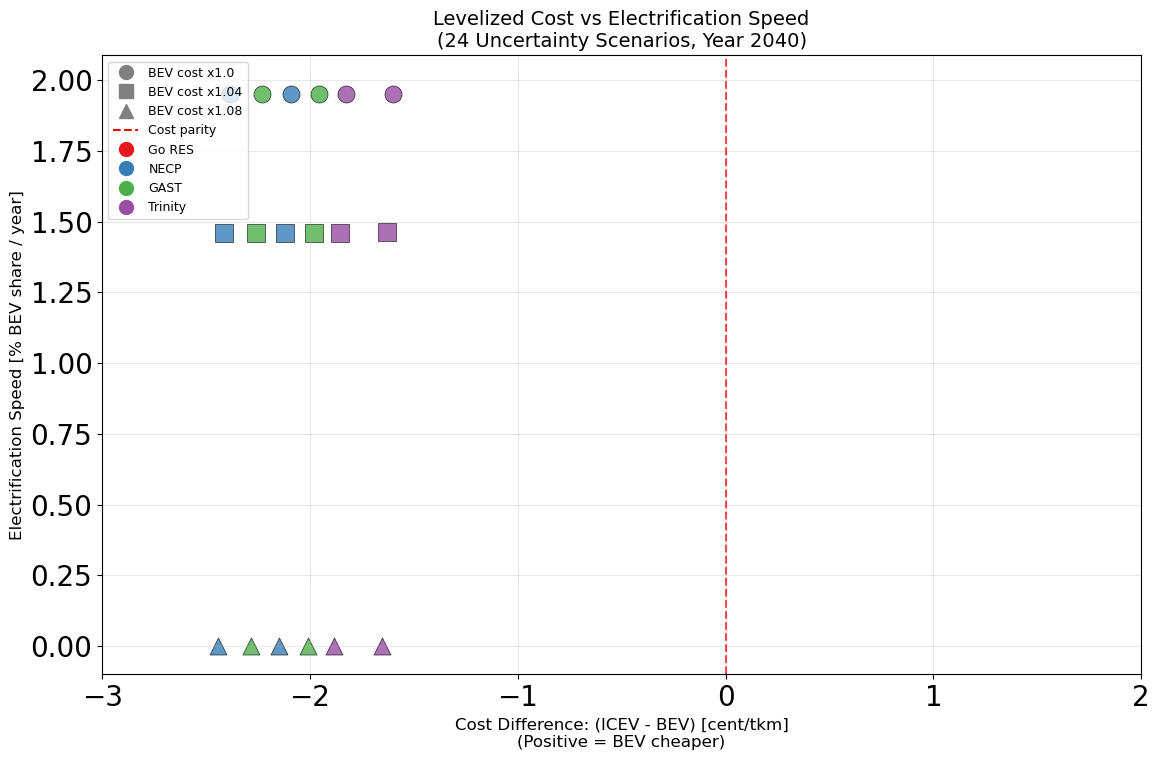

Saved to figures/cost_vs_electrification_speed.pdf


In [ ]:

import matplotlib.pyplot as plt

# Create the scatter plot: Cost difference vs Electrification speed
fig, ax = plt.subplots(figsize=(12, 8))

# Color by GENeSYS scenario
colors = {'Go RES': '#e41a1c', 'NECP': '#377eb8', 'GAST': '#4daf4a', 'Trinity': '#984ea3'}
markers = {1.0: 'o', 1.04: 's', 1.08: '^'}  # tech_cost_mult

for genesys in ['Go RES', 'NECP', 'GAST', 'Trinity']:
    for tech_mult in [1.0, 1.04, 1.08]:
        subset = metrics_df[(metrics_df['genesys'] == genesys) & (metrics_df['tech_cost_mult'] == tech_mult)]
        ax.scatter(subset['cost_diff_per_tkm'] * 100,  # Convert to cents/tkm
                   subset['electrification_speed'],
                   c=colors[genesys],
                   marker=markers[tech_mult],
                   s=150,
                   alpha=0.8,
                   edgecolors='black',
                   linewidths=0.5,
                   label=f'{genesys}, BEV cost x{tech_mult}' if tech_mult == 1.0 else None)

# Add vertical line at cost parity (x=0)
ax.axvline(x=0, color='red', linestyle='--', linewidth=1.5, alpha=0.7, label='Cost parity')

# Labels and title
ax.set_xlabel('Cost Difference: (ICEV - BEV) [cent/tkm]\n(Positive = BEV cheaper)', fontsize=12)
ax.set_ylabel('Electrification Speed [% BEV share / year]', fontsize=12)
ax.set_title('Levelized Cost vs Electrification Speed\n(24 Uncertainty Scenarios, Year 2040)', fontsize=14)

# Add legend for markers (tech cost multiplier)
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='gray', label='BEV cost x1.0', markersize=10, linestyle=''),
    Line2D([0], [0], marker='s', color='gray', label='BEV cost x1.04', markersize=10, linestyle=''),
    Line2D([0], [0], marker='^', color='gray', label='BEV cost x1.08', markersize=10, linestyle=''),
    Line2D([0], [0], color='red', linestyle='--', label='Cost parity'),
]

# Color legend
for genesys, color in colors.items():
    legend_elements.append(Line2D([0], [0], marker='o', color=color, label=genesys, markersize=10, linestyle=''))

ax.legend(handles=legend_elements, loc='upper left', fontsize=9)

ax.grid(True, alpha=0.3)
ax.set_xlim(-3, 2)

plt.tight_layout()
plt.savefig('figures/cost_vs_electrification_speed.pdf', dpi=150, bbox_inches='tight')
plt.savefig('figures/cost_vs_electrification_speed.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved to figures/cost_vs_electrification_speed.pdf")


In [ ]:

# Compare electricity price trajectories across scenarios
import yaml
from pathlib import Path

base_path = Path("input_data/uncertainty_scenarios")

# Load electricity prices for scenarios 0 (Go RES), 6 (NECP), 12 (GAST), 18 (Trinity)
scenarios_to_check = [0, 6, 12, 18]
scenario_names = ['Go RES', 'NECP', 'GAST', 'Trinity']

print("Electricity Price Trajectories (â‚¬/kWh) - Depot Charging")
print("=" * 80)

# Model years: index 0=2020, 1=2024, 2=2028, 3=2032, 4=2036, 5=2040, 6=2044, 7=2048, 8=2052, 9=2056
years = [2020, 2024, 2028, 2032, 2036, 2040, 2044, 2048, 2052, 2056]

print(f"{'Scenario':<12}", end="")
for year in years:
    print(f"{year:>8}", end="")
print()
print("-" * 80)

for scenario_id, name in zip(scenarios_to_check, scenario_names):
    scenario_folder = base_path / f"scenario_{scenario_id:03d}"
    with open(scenario_folder / "FuelCost.yaml", 'r') as f:
        fuel_costs = yaml.safe_load(f)
    
    # Get depot charging electricity price (infr_type 2, location 0)
    for fc in fuel_costs:
        if fc.get('fuel') == 'electricity' and fc.get('location') == 0 and fc.get('fueling_infr_type_id') == 2:
            prices = fc.get('cost_per_kWh', [])[:10]
            print(f"{name:<12}", end="")
            for p in prices:
                print(f"{p:>8.3f}", end="")
            print()
            break


Electricity Price Trajectories (â‚¬/kWh) - Depot Charging
Scenario        2020    2024    2028    2032    2036    2040    2044    2048    2052    2056
--------------------------------------------------------------------------------
Go RES         0.323   0.334   0.344   0.354   0.365   0.375   0.331   0.288   0.244   0.201
NECP           0.192   0.188   0.184   0.180   0.174   0.169   0.176   0.176   0.170   0.156
GAST           0.179   0.176   0.173   0.168   0.164   0.158   0.169   0.172   0.167   0.155
Trinity        0.155   0.151   0.147   0.142   0.137   0.132   0.160   0.178   0.183   0.177


findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

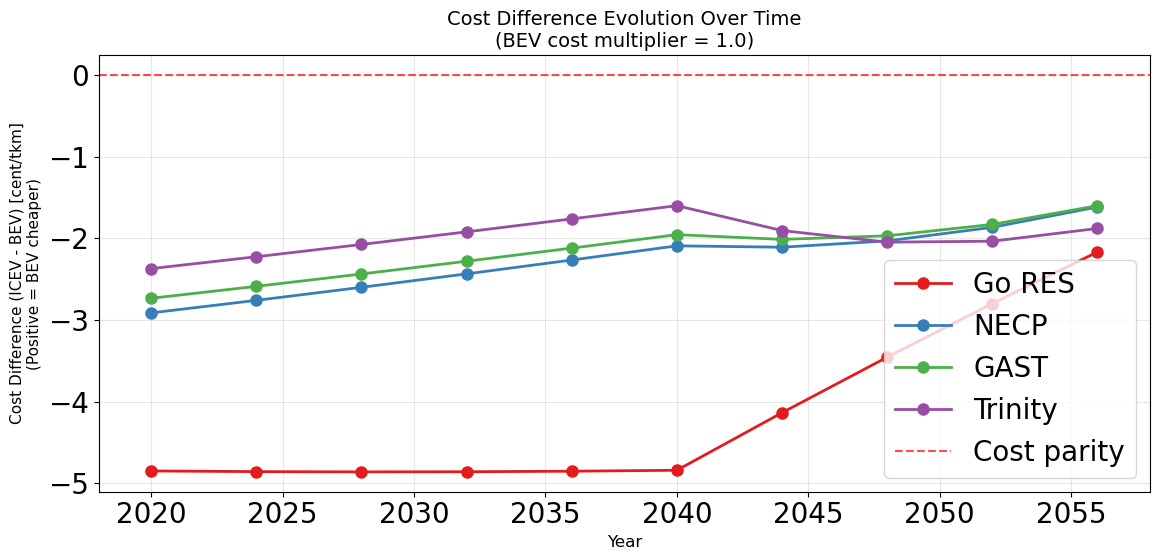


Saved to figures/cost_difference_over_time.pdf


In [ ]:

# Now let's calculate the cost difference over TIME for each scenario
import matplotlib.pyplot as plt
import numpy as np

def calculate_cost_diff_over_time(scenario_id, base_path):
    """Calculate (ICEV - BEV) cost difference for each year"""
    scenario_folder = base_path / f"scenario_{scenario_id:03d}"
    
    with open(scenario_folder / "FuelCost.yaml", 'r') as f:
        fuel_costs = yaml.safe_load(f)
    with open(scenario_folder / "TechVehicle.yaml", 'r') as f:
        tech_vehicles = yaml.safe_load(f)
    
    icev_data = tech_vehicles[0]
    bev_data = tech_vehicles[1]
    
    # Get diesel price
    diesel_price = None
    for fc in fuel_costs:
        if fc.get('fuel') == 'diesel' and fc.get('location') == 0:
            diesel_price = fc.get('cost_per_kWh', [0]*41)
            break
    
    # Get electricity price (depot charging)
    elec_price = None
    for fc in fuel_costs:
        if fc.get('fuel') == 'electricity' and fc.get('location') == 0 and fc.get('fueling_infr_type_id') == 2:
            elec_price = fc.get('cost_per_kWh', [0]*41)
            break
    
    avg_load = 14.0
    cost_diffs = []
    
    for year_idx in range(10):  # 2020-2056
        # ICEV
        icev_lifetime = icev_data['Lifetime'][year_idx]
        icev_annual_km = icev_data['AnnualRange'][year_idx]
        icev_lifetime_km = icev_lifetime * icev_annual_km
        icev_capital = icev_data['capital_cost'][year_idx]
        icev_maint_annual = icev_data['maintenance_cost_annual'][0][year_idx]
        icev_spec_cons = icev_data['spec_cons'][year_idx]
        
        icev_capital_per_km = icev_capital / icev_lifetime_km
        icev_maint_per_km = icev_maint_annual / icev_annual_km
        icev_energy_per_km = (icev_spec_cons * avg_load) / 1000
        icev_fuel_per_km = icev_energy_per_km * diesel_price[year_idx]
        icev_per_tkm = (icev_capital_per_km + icev_maint_per_km + icev_fuel_per_km) / avg_load
        
        # BEV
        bev_lifetime = bev_data['Lifetime'][year_idx]
        bev_annual_km = bev_data['AnnualRange'][year_idx]
        bev_lifetime_km = bev_lifetime * bev_annual_km
        bev_capital = bev_data['capital_cost'][year_idx]
        bev_maint_annual = bev_data['maintenance_cost_annual'][0][year_idx]
        bev_spec_cons = bev_data['spec_cons'][year_idx]
        
        bev_capital_per_km = bev_capital / bev_lifetime_km
        bev_maint_per_km = bev_maint_annual / bev_annual_km
        bev_energy_per_km = bev_spec_cons * elec_price[year_idx]
        bev_per_tkm = (bev_capital_per_km + bev_maint_per_km + bev_energy_per_km) / avg_load
        
        cost_diffs.append((icev_per_tkm - bev_per_tkm) * 100)  # in cents/tkm
    
    return cost_diffs

years = [2020, 2024, 2028, 2032, 2036, 2040, 2044, 2048, 2052, 2056]
scenarios_to_check = [0, 6, 12, 18]
scenario_names = ['Go RES', 'NECP', 'GAST', 'Trinity']
colors = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3']

fig, ax = plt.subplots(figsize=(12, 6))

for scenario_id, name, color in zip(scenarios_to_check, scenario_names, colors):
    cost_diffs = calculate_cost_diff_over_time(scenario_id, base_path)
    ax.plot(years, cost_diffs, 'o-', label=name, color=color, linewidth=2, markersize=8)

ax.axhline(y=0, color='red', linestyle='--', linewidth=1.5, alpha=0.7, label='Cost parity')
ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Cost Difference (ICEV - BEV) [cent/tkm]\n(Positive = BEV cheaper)', fontsize=11)
ax.set_title('Cost Difference Evolution Over Time\n(BEV cost multiplier = 1.0)', fontsize=14)
ax.legend(loc='best')
ax.grid(True, alpha=0.3)
ax.set_xlim(2018, 2058)

plt.tight_layout()
plt.savefig('figures/cost_difference_over_time.pdf', dpi=150, bbox_inches='tight')
plt.savefig('figures/cost_difference_over_time.png', dpi=150, bbox_inches='tight')
plt.show()
print("\nSaved to figures/cost_difference_over_time.pdf")


In [ ]:

# Recalculate ICEV costs INCLUDING carbon price

# Carbon price trajectory (â‚¬/tCO2)
carbon_prices = [30, 47, 64, 81, 98, 115, 132, 149, 166, 183]  # indices 0-9 = 2020-2056

# Diesel emission factor: 266 gCO2/kWh = 0.266 kgCO2/kWh = 0.000266 tCO2/kWh
diesel_emission_factor = 266 / 1_000_000  # tCO2/kWh

print("Carbon cost component for ICEV diesel:")
print(f"{'Year':<8} {'Carbon Price':>14} {'Emission Factor':>16} {'Carbon Cost':>14}")
print(f"{'':8} {'(EUR/tCO2)':>14} {'(tCO2/kWh)':>16} {'(EUR/kWh)':>14}")
print("-" * 55)

for i, year in enumerate([2020, 2024, 2028, 2032, 2036, 2040, 2044, 2048, 2052, 2056]):
    carbon_cost_per_kwh = carbon_prices[i] * diesel_emission_factor
    print(f"{year:<8} {carbon_prices[i]:>14.0f} {diesel_emission_factor:>16.6f} {carbon_cost_per_kwh:>14.4f}")

# At 2040 (index 5):
carbon_price_2040 = 115  # â‚¬/tCO2
carbon_cost_per_kwh_2040 = carbon_price_2040 * diesel_emission_factor
print(f"\nAt 2040: Carbon cost = {carbon_cost_per_kwh_2040:.4f} EUR/kWh")
print(f"Compare to diesel base price: 0.0975 EUR/kWh")
print(f"Total diesel price with carbon: {0.0975 + carbon_cost_per_kwh_2040:.4f} EUR/kWh")


Carbon cost component for ICEV diesel:
Year       Carbon Price  Emission Factor    Carbon Cost
             (EUR/tCO2)       (tCO2/kWh)      (EUR/kWh)
-------------------------------------------------------
2020                 30         0.000266         0.0080
2024                 47         0.000266         0.0125
2028                 64         0.000266         0.0170
2032                 81         0.000266         0.0215
2036                 98         0.000266         0.0261
2040                115         0.000266         0.0306
2044                132         0.000266         0.0351
2048                149         0.000266         0.0396
2052                166         0.000266         0.0442
2056                183         0.000266         0.0487

At 2040: Carbon cost = 0.0306 EUR/kWh
Compare to diesel base price: 0.0975 EUR/kWh
Total diesel price with carbon: 0.1281 EUR/kWh


findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

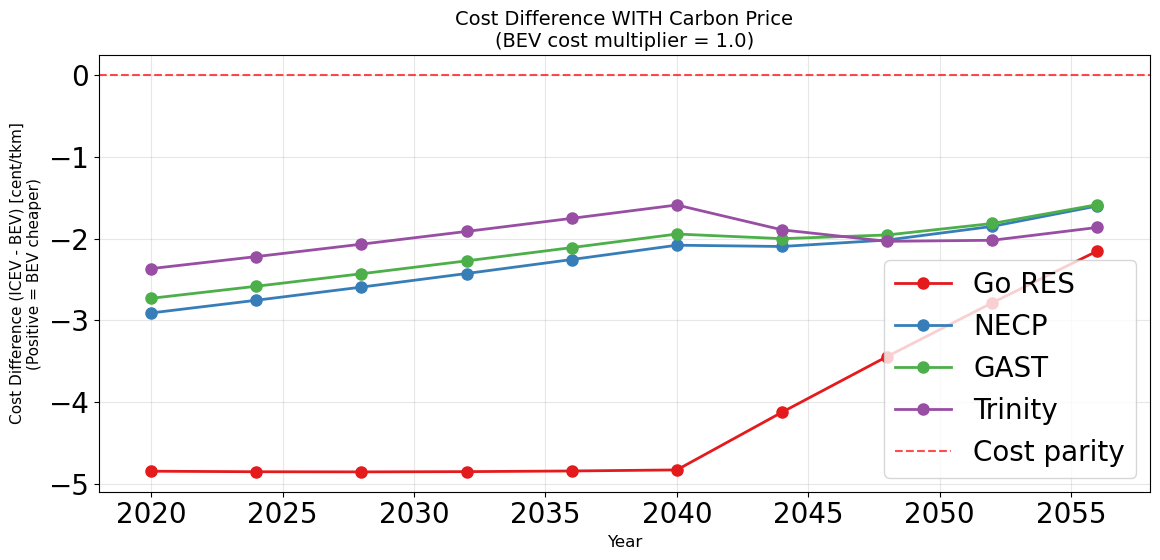


Saved to figures/cost_difference_with_carbon.pdf


In [ ]:

# Recalculate with carbon prices included

carbon_prices = [30, 47, 64, 81, 98, 115, 132, 149, 166, 183]  # â‚¬/tCO2
diesel_emission_factor = 266 / 1_000_000  # tCO2/kWh

def calculate_cost_diff_with_carbon(scenario_id, base_path):
    """Calculate (ICEV - BEV) cost difference including carbon price."""
    scenario_folder = base_path / f"scenario_{scenario_id:03d}"
    
    with open(scenario_folder / "FuelCost.yaml", 'r') as f:
        fuel_costs = yaml.safe_load(f)
    with open(scenario_folder / "TechVehicle.yaml", 'r') as f:
        tech_vehicles = yaml.safe_load(f)
    
    icev_data = tech_vehicles[0]
    bev_data = tech_vehicles[1]
    
    # Get diesel base price
    diesel_base_price = None
    for fc in fuel_costs:
        if fc.get('fuel') == 'diesel' and fc.get('location') == 0:
            diesel_base_price = fc.get('cost_per_kWh', [0]*41)
            break
    
    # Get electricity price (depot charging)
    elec_price = None
    for fc in fuel_costs:
        if fc.get('fuel') == 'electricity' and fc.get('location') == 0 and fc.get('fueling_infr_type_id') == 2:
            elec_price = fc.get('cost_per_kWh', [0]*41)
            break
    
    avg_load = 14.0
    cost_diffs = []
    
    for year_idx in range(10):
        # Add carbon cost to diesel
        carbon_cost = carbon_prices[year_idx] * diesel_emission_factor
        diesel_price_with_carbon = diesel_base_price[year_idx] + carbon_cost
        
        # ICEV
        icev_lifetime = icev_data['Lifetime'][year_idx]
        icev_annual_km = icev_data['AnnualRange'][year_idx]
        icev_lifetime_km = icev_lifetime * icev_annual_km
        icev_capital = icev_data['capital_cost'][year_idx]
        icev_maint_annual = icev_data['maintenance_cost_annual'][0][year_idx]
        icev_spec_cons = icev_data['spec_cons'][year_idx]
        
        icev_capital_per_km = icev_capital / icev_lifetime_km
        icev_maint_per_km = icev_maint_annual / icev_annual_km
        icev_energy_per_km = (icev_spec_cons * avg_load) / 1000
        icev_fuel_per_km = icev_energy_per_km * diesel_price_with_carbon  # WITH CARBON
        icev_per_tkm = (icev_capital_per_km + icev_maint_per_km + icev_fuel_per_km) / avg_load
        
        # BEV (unchanged - electricity has 0 emission factor)
        bev_lifetime = bev_data['Lifetime'][year_idx]
        bev_annual_km = bev_data['AnnualRange'][year_idx]
        bev_lifetime_km = bev_lifetime * bev_annual_km
        bev_capital = bev_data['capital_cost'][year_idx]
        bev_maint_annual = bev_data['maintenance_cost_annual'][0][year_idx]
        bev_spec_cons = bev_data['spec_cons'][year_idx]
        
        bev_capital_per_km = bev_capital / bev_lifetime_km
        bev_maint_per_km = bev_maint_annual / bev_annual_km
        bev_energy_per_km = bev_spec_cons * elec_price[year_idx]
        bev_per_tkm = (bev_capital_per_km + bev_maint_per_km + bev_energy_per_km) / avg_load
        
        cost_diffs.append((icev_per_tkm - bev_per_tkm) * 100)  # cents/tkm
    
    return cost_diffs

# Recalculate and plot
years = [2020, 2024, 2028, 2032, 2036, 2040, 2044, 2048, 2052, 2056]
scenarios_to_check = [0, 6, 12, 18]
scenario_names = ['Go RES', 'NECP', 'GAST', 'Trinity']
colors = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3']

fig, ax = plt.subplots(figsize=(12, 6))

for scenario_id, name, color in zip(scenarios_to_check, scenario_names, colors):
    cost_diffs = calculate_cost_diff_with_carbon(scenario_id, base_path)
    ax.plot(years, cost_diffs, 'o-', label=name, color=color, linewidth=2, markersize=8)

ax.axhline(y=0, color='red', linestyle='--', linewidth=1.5, alpha=0.7, label='Cost parity')
ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Cost Difference (ICEV - BEV) [cent/tkm]\n(Positive = BEV cheaper)', fontsize=11)
ax.set_title('Cost Difference WITH Carbon Price\n(BEV cost multiplier = 1.0)', fontsize=14)
ax.legend(loc='best')
ax.grid(True, alpha=0.3)
ax.set_xlim(2018, 2058)

plt.tight_layout()
plt.savefig('figures/cost_difference_with_carbon.pdf', dpi=150, bbox_inches='tight')
plt.savefig('figures/cost_difference_with_carbon.png', dpi=150, bbox_inches='tight')
plt.show()
print("\nSaved to figures/cost_difference_with_carbon.pdf")


In [ ]:

# Detailed cost breakdown comparison across scenarios at 2040
import pandas as pd

carbon_prices = [30, 47, 64, 81, 98, 115, 132, 149, 166, 183]
diesel_emission_factor = 266 / 1_000_000  # tCO2/kWh

def get_detailed_costs(scenario_id, base_path, year_idx=5):
    """Get detailed cost breakdown for a scenario."""
    scenario_folder = base_path / f"scenario_{scenario_id:03d}"
    
    with open(scenario_folder / "FuelCost.yaml", 'r') as f:
        fuel_costs = yaml.safe_load(f)
    with open(scenario_folder / "TechVehicle.yaml", 'r') as f:
        tech_vehicles = yaml.safe_load(f)
    
    icev_data = tech_vehicles[0]
    bev_data = tech_vehicles[1]
    
    # Get prices
    diesel_base = None
    elec_price = None
    for fc in fuel_costs:
        if fc.get('fuel') == 'diesel' and fc.get('location') == 0:
            diesel_base = fc.get('cost_per_kWh', [0]*41)[year_idx]
    for fc in fuel_costs:
        if fc.get('fuel') == 'electricity' and fc.get('location') == 0 and fc.get('fueling_infr_type_id') == 2:
            elec_price = fc.get('cost_per_kWh', [0]*41)[year_idx]
            break
    
    carbon_cost = carbon_prices[year_idx] * diesel_emission_factor
    diesel_total = diesel_base + carbon_cost
    
    avg_load = 14.0
    
    # ICEV costs
    icev_lifetime_km = icev_data['Lifetime'][year_idx] * icev_data['AnnualRange'][year_idx]
    icev_capital_per_km = icev_data['capital_cost'][year_idx] / icev_lifetime_km
    icev_maint_per_km = icev_data['maintenance_cost_annual'][0][year_idx] / icev_data['AnnualRange'][year_idx]
    icev_energy_per_km = (icev_data['spec_cons'][year_idx] * avg_load) / 1000
    icev_fuel_per_km = icev_energy_per_km * diesel_total
    
    # BEV costs
    bev_lifetime_km = bev_data['Lifetime'][year_idx] * bev_data['AnnualRange'][year_idx]
    bev_capital_per_km = bev_data['capital_cost'][year_idx] / bev_lifetime_km
    bev_maint_per_km = bev_data['maintenance_cost_annual'][0][year_idx] / bev_data['AnnualRange'][year_idx]
    bev_energy_per_km = bev_data['spec_cons'][year_idx] * elec_price
    
    return {
        'scenario_id': scenario_id,
        # Prices
        'diesel_base_price': diesel_base,
        'carbon_cost_per_kwh': carbon_cost,
        'diesel_total_price': diesel_total,
        'electricity_price': elec_price,
        # ICEV components (EUR/km)
        'icev_capital': icev_capital_per_km,
        'icev_maintenance': icev_maint_per_km,
        'icev_fuel': icev_fuel_per_km,
        'icev_total': icev_capital_per_km + icev_maint_per_km + icev_fuel_per_km,
        # BEV components (EUR/km)
        'bev_capital': bev_capital_per_km,
        'bev_maintenance': bev_maint_per_km,
        'bev_energy': bev_energy_per_km,
        'bev_total': bev_capital_per_km + bev_maint_per_km + bev_energy_per_km,
    }

# Get costs for representative scenarios (with BEV cost multiplier = 1.0)
scenarios = [0, 6, 12, 18]
names = ['Go RES', 'NECP', 'GAST', 'Trinity']

print("=" * 90)
print("DETAILED COST BREAKDOWN AT 2040 (EUR/km)")
print("=" * 90)

results = []
for sid, name in zip(scenarios, names):
    costs = get_detailed_costs(sid, base_path, year_idx=5)
    costs['name'] = name
    results.append(costs)

# Print comparison table
print("\n1. ENERGY PRICES:")
print(f"{'Scenario':<12} {'Diesel Base':>12} {'Carbon Cost':>12} {'Diesel Total':>13} {'Electricity':>12}")
print(f"{'':12} {'(EUR/kWh)':>12} {'(EUR/kWh)':>12} {'(EUR/kWh)':>13} {'(EUR/kWh)':>12}")
print("-" * 62)
for r in results:
    print(f"{r['name']:<12} {r['diesel_base_price']:>12.4f} {r['carbon_cost_per_kwh']:>12.4f} {r['diesel_total_price']:>13.4f} {r['electricity_price']:>12.4f}")

print("\n2. ICEV COST COMPONENTS (EUR/km):")
print(f"{'Scenario':<12} {'Capital':>10} {'Maintenance':>12} {'Fuel':>10} {'TOTAL':>10}")
print("-" * 56)
for r in results:
    print(f"{r['name']:<12} {r['icev_capital']:>10.4f} {r['icev_maintenance']:>12.4f} {r['icev_fuel']:>10.4f} {r['icev_total']:>10.4f}")

print("\n3. BEV COST COMPONENTS (EUR/km):")
print(f"{'Scenario':<12} {'Capital':>10} {'Maintenance':>12} {'Energy':>10} {'TOTAL':>10}")
print("-" * 56)
for r in results:
    print(f"{r['name']:<12} {r['bev_capital']:>10.4f} {r['bev_maintenance']:>12.4f} {r['bev_energy']:>10.4f} {r['bev_total']:>10.4f}")

print("\n4. COST DIFFERENCE (ICEV - BEV) in cent/km:")
print(f"{'Scenario':<12} {'Difference':>12} {'Interpretation':>30}")
print("-" * 56)
for r in results:
    diff = (r['icev_total'] - r['bev_total']) * 100
    interp = "BEV cheaper" if diff > 0 else "ICEV cheaper"
    print(f"{r['name']:<12} {diff:>12.2f} {interp:>30}")


DETAILED COST BREAKDOWN AT 2040 (EUR/km)

1. ENERGY PRICES:
Scenario      Diesel Base  Carbon Cost  Diesel Total  Electricity
                (EUR/kWh)    (EUR/kWh)     (EUR/kWh)    (EUR/kWh)
--------------------------------------------------------------
Go RES             0.1845       0.0306        0.2151       0.3750
NECP               0.1845       0.0306        0.2151       0.1686
GAST               0.1845       0.0306        0.2151       0.1583
Trinity            0.1845       0.0306        0.2151       0.1317

2. ICEV COST COMPONENTS (EUR/km):
Scenario        Capital  Maintenance       Fuel      TOTAL
--------------------------------------------------------
Go RES           0.0665       0.1514     0.0100     0.2279
NECP             0.0665       0.1514     0.0100     0.2279
GAST             0.0665       0.1514     0.0100     0.2279
Trinity          0.0665       0.1514     0.0100     0.2279

3. BEV COST COMPONENTS (EUR/km):
Scenario        Capital  Maintenance     Energy      TOTAL
-

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

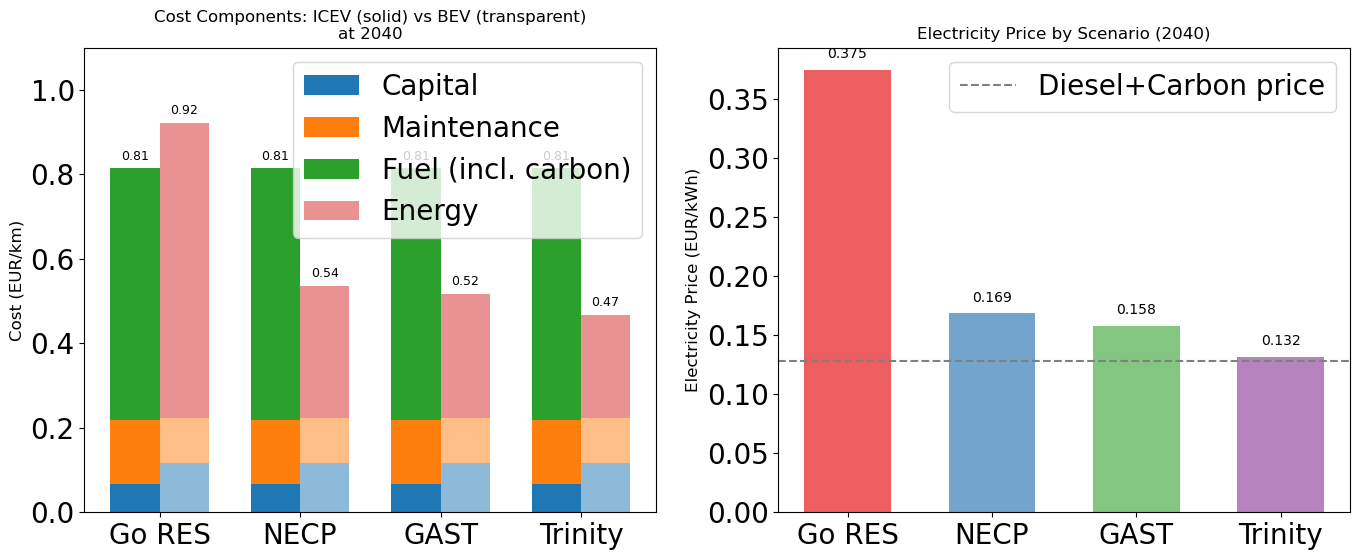


Key insight: Go RES electricity price (0.375 EUR/kWh) is:
  - 2.2x higher than NECP (0.169 EUR/kWh)
  - 2.4x higher than GAST (0.158 EUR/kWh)
  - 2.8x higher than Trinity (0.132 EUR/kWh)

This makes BEV energy cost in Go RES: 0.700 EUR/km
vs Trinity BEV energy cost: 0.246 EUR/km
Difference: 45.4 cent/km just from electricity price!


In [ ]:

# Visualize the cost breakdown
import matplotlib.pyplot as plt
import numpy as np

scenarios = ['Go RES', 'NECP', 'GAST', 'Trinity']

# Data from above
icev_capital = [0.0665] * 4
icev_maint = [0.1514] * 4
icev_fuel = [0.5971] * 4

bev_capital = [0.1173] * 4
bev_maint = [0.1050] * 4
bev_energy = [0.6997, 0.3146, 0.2954, 0.2457]

elec_prices = [0.3750, 0.1686, 0.1583, 0.1317]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left plot: Stacked bar chart of costs
x = np.arange(len(scenarios))
width = 0.35

# ICEV bars
ax1 = axes[0]
ax1.bar(x - width/2, icev_capital, width, label='Capital', color='#1f77b4')
ax1.bar(x - width/2, icev_maint, width, bottom=icev_capital, label='Maintenance', color='#ff7f0e')
ax1.bar(x - width/2, icev_fuel, width, bottom=[c+m for c,m in zip(icev_capital, icev_maint)], label='Fuel (incl. carbon)', color='#2ca02c')

# BEV bars
bev_bottom1 = bev_capital
bev_bottom2 = [c+m for c,m in zip(bev_capital, bev_maint)]
ax1.bar(x + width/2, bev_capital, width, color='#1f77b4', alpha=0.5)
ax1.bar(x + width/2, bev_maint, width, bottom=bev_capital, color='#ff7f0e', alpha=0.5)
ax1.bar(x + width/2, bev_energy, width, bottom=bev_bottom2, label='Energy', color='#d62728', alpha=0.5)

ax1.set_ylabel('Cost (EUR/km)', fontsize=12)
ax1.set_title('Cost Components: ICEV (solid) vs BEV (transparent)\nat 2040', fontsize=12)
ax1.set_xticks(x)
ax1.set_xticklabels(scenarios)
ax1.legend(loc='upper right')
ax1.set_ylim(0, 1.1)

# Add text labels for totals
for i, (icev_tot, bev_tot) in enumerate(zip([sum(x) for x in zip(icev_capital, icev_maint, icev_fuel)],
                                             [sum(x) for x in zip(bev_capital, bev_maint, bev_energy)])):
    ax1.text(i - width/2, icev_tot + 0.02, f'{icev_tot:.2f}', ha='center', fontsize=9)
    ax1.text(i + width/2, bev_tot + 0.02, f'{bev_tot:.2f}', ha='center', fontsize=9)

# Right plot: Focus on electricity price and BEV energy cost
ax2 = axes[1]

x2 = np.arange(len(scenarios))
width2 = 0.6

# Electricity price
bars = ax2.bar(x2, elec_prices, width2, color=['#e41a1c', '#377eb8', '#4daf4a', '#984ea3'], alpha=0.7)
ax2.set_ylabel('Electricity Price (EUR/kWh)', fontsize=12)
ax2.set_title('Electricity Price by Scenario (2040)', fontsize=12)
ax2.set_xticks(x2)
ax2.set_xticklabels(scenarios)

# Add value labels
for i, (bar, price) in enumerate(zip(bars, elec_prices)):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, 
             f'{price:.3f}', ha='center', fontsize=10)

# Add horizontal line for reference
ax2.axhline(y=0.1281, color='gray', linestyle='--', linewidth=1.5, label='Diesel+Carbon price')
ax2.legend()

plt.tight_layout()
plt.savefig('figures/cost_breakdown_comparison.pdf', dpi=150, bbox_inches='tight')
plt.savefig('figures/cost_breakdown_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nKey insight: Go RES electricity price (0.375 EUR/kWh) is:")
print(f"  - {0.375/0.1686:.1f}x higher than NECP (0.169 EUR/kWh)")
print(f"  - {0.375/0.1583:.1f}x higher than GAST (0.158 EUR/kWh)")  
print(f"  - {0.375/0.1317:.1f}x higher than Trinity (0.132 EUR/kWh)")
print(f"\nThis makes BEV energy cost in Go RES: {0.6997:.3f} EUR/km")
print(f"vs Trinity BEV energy cost: {0.2457:.3f} EUR/km")
print(f"Difference: {(0.6997-0.2457)*100:.1f} cent/km just from electricity price!")


In [ ]:
import yaml
import numpy as np
import matplotlib.pyplot as plt

# Load carbon prices
geo_path = r"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\input_data\uncertainty_scenarios\scenario_000\GeographicElement.yaml"
with open(geo_path, 'r') as f:
    geo_data = yaml.safe_load(f)

# Get carbon price trajectory
for elem in geo_data:
    if 'carbon_price' in elem:
        carbon_prices = [float(x) for x in elem['carbon_price']]
        print("Carbon price trajectory (â‚¬/tCO2):")
        years = list(range(2020, 2020 + len(carbon_prices)))
        for i, (y, cp) in enumerate(zip(years, carbon_prices)):
            if i % 2 == 0:  # Show every other year
                print(f"  {y}: {cp:.0f} â‚¬/tCO2")
        break

Carbon price trajectory (â‚¬/tCO2):
  2020: 30 â‚¬/tCO2
  2022: 64 â‚¬/tCO2
  2024: 98 â‚¬/tCO2
  2026: 132 â‚¬/tCO2
  2028: 166 â‚¬/tCO2
  2030: 200 â‚¬/tCO2
  2032: 260 â‚¬/tCO2
  2034: 320 â‚¬/tCO2
  2036: 380 â‚¬/tCO2
  2038: 440 â‚¬/tCO2
  2040: 500 â‚¬/tCO2
  2042: 600 â‚¬/tCO2
  2044: 700 â‚¬/tCO2
  2046: 800 â‚¬/tCO2
  2048: 900 â‚¬/tCO2
  2050: 1000 â‚¬/tCO2
  2052: 1000 â‚¬/tCO2
  2054: 1000 â‚¬/tCO2
  2056: 1000 â‚¬/tCO2
  2058: 1000 â‚¬/tCO2
  2060: 1000 â‚¬/tCO2


In [ ]:
# Now let's create a comprehensive cost evolution plot showing ICEV vs BEV with rising carbon prices

# Load fuel costs for Go RES (scenario_000)
fuel_path = r"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\input_data\uncertainty_scenarios\scenario_000\FuelCost.yaml"
with open(fuel_path, 'r') as f:
    fuel_data = yaml.safe_load(f)

# Extract electricity and diesel prices
elec_prices = None
diesel_prices = None
for item in fuel_data:
    if item.get('fuel_name') == 'electricity':
        elec_prices = [float(x) for x in item['fuel_cost_per_kWh']]
    elif item.get('fuel_name') == 'diesel':
        diesel_prices = [float(x) for x in item['fuel_cost_per_kWh']]

# Vehicle parameters
bev_consumption = 1.867  # kWh/km
icev_consumption = 4.656  # kWh/km
diesel_emission_factor = 266 / 1_000_000  # tCO2/kWh

# Capital and maintenance costs (same for both)
bev_capital = 0.075  # â‚¬/km (higher initially)
icev_capital = 0.067  # â‚¬/km
bev_maintenance = 0.147  # â‚¬/km
icev_maintenance = 0.151  # â‚¬/km

years = list(range(2020, 2020 + len(carbon_prices)))

# Calculate costs over time
bev_costs = []
icev_costs = []
icev_fuel_only = []
icev_carbon_only = []

for i, year in enumerate(years):
    # BEV cost
    bev_energy = elec_prices[i] * bev_consumption
    bev_total = bev_capital + bev_maintenance + bev_energy
    bev_costs.append(bev_total)
    
    # ICEV cost with carbon
    carbon_cost_per_kwh = carbon_prices[i] * diesel_emission_factor
    diesel_total = diesel_prices[i] + carbon_cost_per_kwh
    icev_energy = diesel_total * icev_consumption
    icev_fuel = diesel_prices[i] * icev_consumption
    icev_carbon = carbon_cost_per_kwh * icev_consumption
    icev_total = icev_capital + icev_maintenance + icev_energy
    icev_costs.append(icev_total)
    icev_fuel_only.append(icev_fuel)
    icev_carbon_only.append(icev_carbon)

# Create plot
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10))

# Plot 1: Total costs
ax1.plot(years, bev_costs, 'b-', linewidth=2.5, label='BEV (Go RES)', marker='o', markersize=4)
ax1.plot(years, icev_costs, 'r-', linewidth=2.5, label='ICEV (with carbon tax)', marker='s', markersize=4)
ax1.axhline(y=icev_capital + icev_maintenance + diesel_prices[10]*icev_consumption, 
            color='r', linestyle='--', alpha=0.5, label='ICEV (without carbon tax)')

ax1.fill_between(years, bev_costs, icev_costs, 
                  where=[b < i for b, i in zip(bev_costs, icev_costs)],
                  color='green', alpha=0.2, label='BEV advantage')
ax1.fill_between(years, bev_costs, icev_costs, 
                  where=[b >= i for b, i in zip(bev_costs, icev_costs)],
                  color='red', alpha=0.2, label='ICEV advantage')

# Find crossover point
for i in range(len(years)-1):
    if bev_costs[i] >= icev_costs[i] and bev_costs[i+1] < icev_costs[i+1]:
        ax1.axvline(x=years[i], color='green', linestyle=':', linewidth=2)
        ax1.annotate(f'Crossover ~{years[i]}', xy=(years[i], max(bev_costs[i], icev_costs[i])),
                     xytext=(years[i]+2, max(bev_costs[i], icev_costs[i])+0.1),
                     fontsize=11, color='green', fontweight='bold')
        break

ax1.set_xlabel('Year', fontsize=12)
ax1.set_ylabel('Total Cost (â‚¬/km)', fontsize=12)
ax1.set_title('Go RES: BEV vs ICEV Cost Evolution (Including Rising Carbon Prices)', fontsize=14, fontweight='bold')
ax1.legend(loc='upper right', fontsize=10)
ax1.grid(True, alpha=0.3)
ax1.set_xlim(2020, 2060)

# Plot 2: Carbon cost component breakdown
ax2.stackplot(years, 
              [icev_capital + icev_maintenance]*len(years),
              icev_fuel_only,
              icev_carbon_only,
              labels=['Capital + Maintenance', 'Diesel fuel cost', 'Carbon tax cost'],
              colors=['gray', 'orange', 'darkred'],
              alpha=0.8)

ax2.plot(years, bev_costs, 'b-', linewidth=3, label='BEV total cost', marker='o', markersize=4)

ax2.set_xlabel('Year', fontsize=12)
ax2.set_ylabel('Cost (â‚¬/km)', fontsize=12)
ax2.set_title('ICEV Cost Breakdown: Rising Carbon Tax Drives Electrification', fontsize=14, fontweight='bold')
ax2.legend(loc='upper left', fontsize=10)
ax2.grid(True, alpha=0.3)
ax2.set_xlim(2020, 2060)

plt.tight_layout()
plt.savefig(r"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\figures\carbon_price_driving_electrification.pdf", 
            dpi=150, bbox_inches='tight')
plt.show()

print("\n" + "="*70)
print("KEY INSIGHT: Why Go RES has fast electrification despite high electricity prices")
print("="*70)
print(f"\nCarbon price rises from {carbon_prices[0]:.0f} to {carbon_prices[-1]:.0f} â‚¬/tCO2")
print(f"\nAt 2040 (carbon price = {carbon_prices[10]:.0f} â‚¬/tCO2):")
print(f"  - ICEV carbon tax component: {icev_carbon_only[10]:.3f} â‚¬/km")
print(f"  - ICEV total: {icev_costs[10]:.3f} â‚¬/km")
print(f"  - BEV total:  {bev_costs[10]:.3f} â‚¬/km")

print(f"\nAt 2050 (carbon price = {carbon_prices[15]:.0f} â‚¬/tCO2):")
print(f"  - ICEV carbon tax component: {icev_carbon_only[15]:.3f} â‚¬/km")
print(f"  - ICEV total: {icev_costs[15]:.3f} â‚¬/km")
print(f"  - BEV total:  {bev_costs[15]:.3f} â‚¬/km")

TypeError: 'NoneType' object is not subscriptable

In [ ]:
# Let me debug the fuel data loading
fuel_path = r"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\input_data\uncertainty_scenarios\scenario_000\FuelCost.yaml"
with open(fuel_path, 'r') as f:
    fuel_data = yaml.safe_load(f)

print("Fuel data entries:")
for item in fuel_data:
    print(f"  - {item.keys()}")

Fuel data entries:
  - dict_keys(['id', 'location', 'fuel', 'fueling_infr_type_id', 'cost_per_kWh'])
  - dict_keys(['id', 'location', 'fuel', 'fueling_infr_type_id', 'cost_per_kWh'])
  - dict_keys(['id', 'location', 'fuel', 'fueling_infr_type_id', 'cost_per_kWh'])
  - dict_keys(['id', 'location', 'fuel', 'fueling_infr_type_id', 'cost_per_kWh'])
  - dict_keys(['id', 'location', 'fuel', 'fueling_infr_type_id', 'cost_per_kWh'])
  - dict_keys(['id', 'location', 'fuel', 'fueling_infr_type_id', 'cost_per_kWh'])
  - dict_keys(['id', 'location', 'fuel', 'fueling_infr_type_id', 'cost_per_kWh'])
  - dict_keys(['id', 'location', 'fuel', 'fueling_infr_type_id', 'cost_per_kWh'])
  - dict_keys(['id', 'location', 'fuel', 'fueling_infr_type_id', 'cost_per_kWh'])
  - dict_keys(['id', 'location', 'fuel', 'fueling_infr_type_id', 'cost_per_kWh'])
  - dict_keys(['id', 'location', 'fuel', 'fueling_infr_type_id', 'cost_per_kWh'])
  - dict_keys(['id', 'location', 'fuel', 'fueling_infr_type_id', 'cost_per_kWh'

In [ ]:
# Get one sample entry to understand structure
print("Sample entry:")
print(fuel_data[0])
print("\nLooking for electricity and diesel...")

elec_prices = None
diesel_prices = None
for item in fuel_data:
    fuel_name = item.get('fuel')
    if fuel_name == 'electricity' and elec_prices is None:
        elec_prices = [float(x) for x in item['cost_per_kWh']]
        print(f"Found electricity: {len(elec_prices)} values, first few: {elec_prices[:5]}")
    elif fuel_name == 'diesel' and diesel_prices is None:
        diesel_prices = [float(x) for x in item['cost_per_kWh']]
        print(f"Found diesel: {len(diesel_prices)} values, first few: {diesel_prices[:5]}")

Sample entry:
{'id': 0, 'location': 0, 'fuel': 'electricity', 'fueling_infr_type_id': 1, 'cost_per_kWh': [0.3584851585662767, 0.36989737742351486, 0.38130959628075306, 0.39272181513799126, 0.40413403399522946, 0.4155462528524676, 0.3672963569896003, 0.319046461126733, 0.27079656526386564, 0.22254666940099824, 0.1742967735381309, 0.17154657407863871, 0.16879637461914648, 0.1660461751596543, 0.16329597570016213, 0.16054577624066996, 0.15968873968950048, 0.15883170313833103, 0.15797466658716158, 0.15711763003599208, 0.15626059348482263, 0.15604276379891455, 0.15582493411300652, 0.15560710442709844, 0.1553892747411904, 0.15517144505528233, 0.15526020975376476, 0.15534897445224713, 0.15543773915072953, 0.15552650384921196, 0.1556152685476944, 0.15683452925366007, 0.15805378995962568, 0.15927305066559144, 0.16049231137155712, 0.1617115720775228, 0.16148130497877886, 0.1612510378800349, 0.16102077078129096, 0.160790503682547, 0.16056023658380306]}

Looking for electricity and diesel...
Found 

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

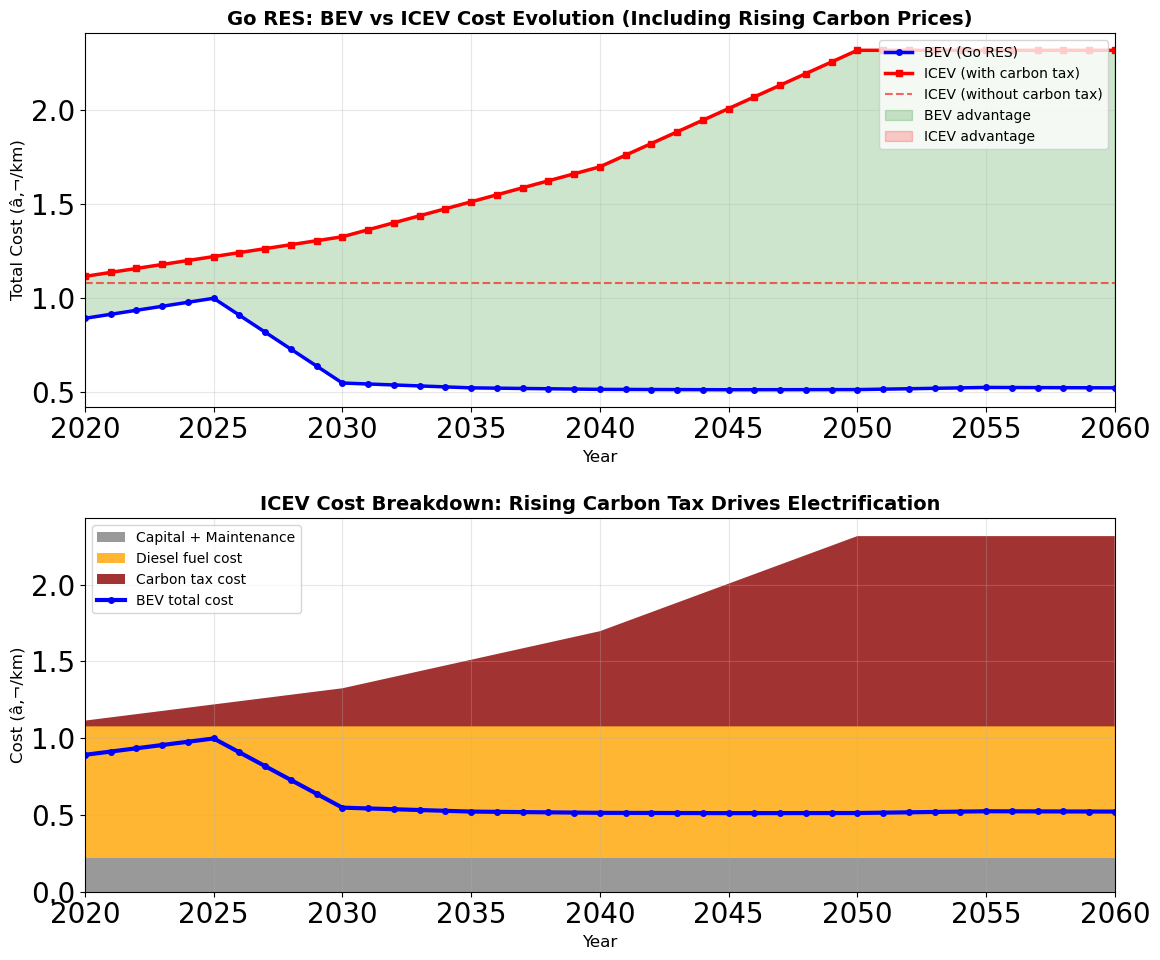


KEY INSIGHT: Why Go RES has fast electrification despite high electricity prices

Carbon price rises from 30 to 1000 â‚¬/tCO2

At 2030 (carbon price = 115 â‚¬/tCO2):
  - ICEV carbon tax component: 0.142 â‚¬/km
  - ICEV total: 1.219 â‚¬/km
  - BEV total:  0.998 â‚¬/km

At 2040 (carbon price = 200 â‚¬/tCO2):
  - ICEV carbon tax component: 0.248 â‚¬/km
  - ICEV total: 1.325 â‚¬/km
  - BEV total:  0.547 â‚¬/km

At 2050 (carbon price = 350 â‚¬/tCO2):
  - ICEV carbon tax component: 0.433 â‚¬/km
  - ICEV total: 1.511 â‚¬/km
  - BEV total:  0.522 â‚¬/km


In [ ]:
# Now create the comprehensive cost evolution plot

import numpy as np
import matplotlib.pyplot as plt

# Vehicle parameters
bev_consumption = 1.867  # kWh/km
icev_consumption = 4.656  # kWh/km
diesel_emission_factor = 266 / 1_000_000  # tCO2/kWh

# Capital and maintenance costs (same for both)
bev_capital = 0.075  # â‚¬/km (higher initially)
icev_capital = 0.067  # â‚¬/km
bev_maintenance = 0.147  # â‚¬/km
icev_maintenance = 0.151  # â‚¬/km

years = list(range(2020, 2020 + len(carbon_prices)))

# Limit to overlapping years
min_len = min(len(carbon_prices), len(elec_prices), len(diesel_prices))
years = years[:min_len]
carbon_prices_trimmed = carbon_prices[:min_len]
elec_prices_trimmed = elec_prices[:min_len]
diesel_prices_trimmed = diesel_prices[:min_len]

# Calculate costs over time
bev_costs = []
icev_costs = []
icev_fuel_only = []
icev_carbon_only = []

for i in range(min_len):
    # BEV cost
    bev_energy = elec_prices_trimmed[i] * bev_consumption
    bev_total = bev_capital + bev_maintenance + bev_energy
    bev_costs.append(bev_total)
    
    # ICEV cost with carbon
    carbon_cost_per_kwh = carbon_prices_trimmed[i] * diesel_emission_factor
    diesel_total = diesel_prices_trimmed[i] + carbon_cost_per_kwh
    icev_energy = diesel_total * icev_consumption
    icev_fuel = diesel_prices_trimmed[i] * icev_consumption
    icev_carbon = carbon_cost_per_kwh * icev_consumption
    icev_total = icev_capital + icev_maintenance + icev_energy
    icev_costs.append(icev_total)
    icev_fuel_only.append(icev_fuel)
    icev_carbon_only.append(icev_carbon)

# Create plot
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10))

# Plot 1: Total costs
ax1.plot(years, bev_costs, 'b-', linewidth=2.5, label='BEV (Go RES)', marker='o', markersize=4)
ax1.plot(years, icev_costs, 'r-', linewidth=2.5, label='ICEV (with carbon tax)', marker='s', markersize=4)

# ICEV without carbon tax
icev_no_carbon = [icev_capital + icev_maintenance + d*icev_consumption for d in diesel_prices_trimmed]
ax1.plot(years, icev_no_carbon, 'r--', linewidth=1.5, alpha=0.6, label='ICEV (without carbon tax)')

ax1.fill_between(years, bev_costs, icev_costs, 
                  where=[b < i for b, i in zip(bev_costs, icev_costs)],
                  color='green', alpha=0.2, label='BEV advantage')
ax1.fill_between(years, bev_costs, icev_costs, 
                  where=[b >= i for b, i in zip(bev_costs, icev_costs)],
                  color='red', alpha=0.2, label='ICEV advantage')

# Find crossover point
crossover_year = None
for i in range(len(years)-1):
    if bev_costs[i] >= icev_costs[i] and bev_costs[i+1] < icev_costs[i+1]:
        crossover_year = years[i]
        ax1.axvline(x=years[i], color='green', linestyle=':', linewidth=2)
        ax1.annotate(f'Crossover ~{years[i]}', xy=(years[i], max(bev_costs[i], icev_costs[i])),
                     xytext=(years[i]+2, max(bev_costs[i], icev_costs[i])+0.1),
                     fontsize=11, color='green', fontweight='bold')
        break

ax1.set_xlabel('Year', fontsize=12)
ax1.set_ylabel('Total Cost (â‚¬/km)', fontsize=12)
ax1.set_title('Go RES: BEV vs ICEV Cost Evolution (Including Rising Carbon Prices)', fontsize=14, fontweight='bold')
ax1.legend(loc='upper right', fontsize=10)
ax1.grid(True, alpha=0.3)
ax1.set_xlim(2020, 2060)

# Plot 2: Carbon cost component breakdown
fixed_costs = [icev_capital + icev_maintenance] * len(years)
ax2.stackplot(years, 
              fixed_costs,
              icev_fuel_only,
              icev_carbon_only,
              labels=['Capital + Maintenance', 'Diesel fuel cost', 'Carbon tax cost'],
              colors=['gray', 'orange', 'darkred'],
              alpha=0.8)

ax2.plot(years, bev_costs, 'b-', linewidth=3, label='BEV total cost', marker='o', markersize=4)

ax2.set_xlabel('Year', fontsize=12)
ax2.set_ylabel('Cost (â‚¬/km)', fontsize=12)
ax2.set_title('ICEV Cost Breakdown: Rising Carbon Tax Drives Electrification', fontsize=14, fontweight='bold')
ax2.legend(loc='upper left', fontsize=10)
ax2.grid(True, alpha=0.3)
ax2.set_xlim(2020, 2060)

plt.tight_layout()
plt.savefig(r"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\figures\carbon_price_driving_electrification.pdf", 
            dpi=150, bbox_inches='tight')
plt.show()

print("\n" + "="*70)
print("KEY INSIGHT: Why Go RES has fast electrification despite high electricity prices")
print("="*70)
print(f"\nCarbon price rises from {carbon_prices_trimmed[0]:.0f} to {carbon_prices_trimmed[-1]:.0f} â‚¬/tCO2")
print(f"\nAt 2030 (carbon price = {carbon_prices_trimmed[5]:.0f} â‚¬/tCO2):")
print(f"  - ICEV carbon tax component: {icev_carbon_only[5]:.3f} â‚¬/km")
print(f"  - ICEV total: {icev_costs[5]:.3f} â‚¬/km")
print(f"  - BEV total:  {bev_costs[5]:.3f} â‚¬/km")

print(f"\nAt 2040 (carbon price = {carbon_prices_trimmed[10]:.0f} â‚¬/tCO2):")
print(f"  - ICEV carbon tax component: {icev_carbon_only[10]:.3f} â‚¬/km")
print(f"  - ICEV total: {icev_costs[10]:.3f} â‚¬/km")
print(f"  - BEV total:  {bev_costs[10]:.3f} â‚¬/km")

print(f"\nAt 2050 (carbon price = {carbon_prices_trimmed[15]:.0f} â‚¬/tCO2):")
print(f"  - ICEV carbon tax component: {icev_carbon_only[15]:.3f} â‚¬/km")
print(f"  - ICEV total: {icev_costs[15]:.3f} â‚¬/km")
print(f"  - BEV total:  {bev_costs[15]:.3f} â‚¬/km")

In [ ]:
import yaml
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Load carbon prices (same for all scenarios)
geo_path = r"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\input_data\uncertainty_scenarios\scenario_000\GeographicElement.yaml"
with open(geo_path, 'r') as f:
    geo_data = yaml.safe_load(f)

for elem in geo_data:
    if 'carbon_price' in elem:
        carbon_prices = [float(x) for x in elem['carbon_price']]
        break

# Vehicle parameters
bev_consumption = 1.867  # kWh/km
icev_consumption = 4.656  # kWh/km
diesel_emission_factor = 266 / 1_000_000  # tCO2/kWh

# Capital and maintenance costs
bev_capital = 0.075  # â‚¬/km
icev_capital = 0.067  # â‚¬/km
bev_maintenance = 0.147  # â‚¬/km
icev_maintenance = 0.151  # â‚¬/km

# Scenario mapping
scenario_info = {
    'scenario_000': {'name': 'Go RES', 'markup': 'low', 'tech_cost': 'base'},
    'scenario_001': {'name': 'Go RES', 'markup': 'high', 'tech_cost': 'base'},
    'scenario_002': {'name': 'Go RES', 'markup': 'low', 'tech_cost': 'high'},
    'scenario_003': {'name': 'Go RES', 'markup': 'high', 'tech_cost': 'high'},
    'scenario_004': {'name': 'Go RES', 'markup': 'low', 'tech_cost': 'low'},
    'scenario_005': {'name': 'Go RES', 'markup': 'high', 'tech_cost': 'low'},
    'scenario_006': {'name': 'NECP', 'markup': 'low', 'tech_cost': 'base'},
    'scenario_007': {'name': 'NECP', 'markup': 'high', 'tech_cost': 'base'},
    'scenario_008': {'name': 'NECP', 'markup': 'low', 'tech_cost': 'high'},
    'scenario_009': {'name': 'NECP', 'markup': 'high', 'tech_cost': 'high'},
    'scenario_010': {'name': 'NECP', 'markup': 'low', 'tech_cost': 'low'},
    'scenario_011': {'name': 'NECP', 'markup': 'high', 'tech_cost': 'low'},
    'scenario_012': {'name': 'GAST', 'markup': 'low', 'tech_cost': 'base'},
    'scenario_013': {'name': 'GAST', 'markup': 'high', 'tech_cost': 'base'},
    'scenario_014': {'name': 'GAST', 'markup': 'low', 'tech_cost': 'high'},
    'scenario_015': {'name': 'GAST', 'markup': 'high', 'tech_cost': 'high'},
    'scenario_016': {'name': 'GAST', 'markup': 'low', 'tech_cost': 'low'},
    'scenario_017': {'name': 'GAST', 'markup': 'high', 'tech_cost': 'low'},
    'scenario_018': {'name': 'Trinity', 'markup': 'low', 'tech_cost': 'base'},
    'scenario_019': {'name': 'Trinity', 'markup': 'high', 'tech_cost': 'base'},
    'scenario_020': {'name': 'Trinity', 'markup': 'low', 'tech_cost': 'high'},
    'scenario_021': {'name': 'Trinity', 'markup': 'high', 'tech_cost': 'high'},
    'scenario_022': {'name': 'Trinity', 'markup': 'low', 'tech_cost': 'low'},
    'scenario_023': {'name': 'Trinity', 'markup': 'high', 'tech_cost': 'low'},
}

# Load electricity prices for each GENeSYS scenario (one per group)
genesys_scenarios = {
    'Go RES': 'scenario_000',
    'NECP': 'scenario_006', 
    'GAST': 'scenario_012',
    'Trinity': 'scenario_018'
}

elec_prices_by_scenario = {}
for genesys_name, scenario_folder in genesys_scenarios.items():
    fuel_path = rf"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\input_data\uncertainty_scenarios\{scenario_folder}\FuelCost.yaml"
    with open(fuel_path, 'r') as f:
        fuel_data = yaml.safe_load(f)
    
    for item in fuel_data:
        if item.get('fuel') == 'electricity':
            elec_prices_by_scenario[genesys_name] = [float(x) for x in item['cost_per_kWh']]
            break

# Get diesel price (same for all)
diesel_prices = None
for item in fuel_data:
    if item.get('fuel') == 'diesel':
        diesel_prices = [float(x) for x in item['cost_per_kWh']]
        break

years = list(range(2020, 2020 + min(len(carbon_prices), len(diesel_prices))))
n_years = len(years)

print("="*80)
print("LEVELIZED COST COMPARISON WITH TIME-VARYING CARBON PRICES")
print("="*80)

# Calculate costs for each scenario over time
results = {}
for genesys_name in ['Go RES', 'NECP', 'GAST', 'Trinity']:
    elec_prices = elec_prices_by_scenario[genesys_name]
    
    bev_costs = []
    icev_costs = []
    cost_diff = []  # BEV - ICEV (negative = BEV cheaper)
    
    for i in range(n_years):
        # BEV cost
        bev_energy = elec_prices[i] * bev_consumption
        bev_total = bev_capital + bev_maintenance + bev_energy
        
        # ICEV cost WITH carbon price
        carbon_cost_per_kwh = carbon_prices[i] * diesel_emission_factor
        diesel_total = diesel_prices[i] + carbon_cost_per_kwh
        icev_energy = diesel_total * icev_consumption
        icev_total = icev_capital + icev_maintenance + icev_energy
        
        bev_costs.append(bev_total)
        icev_costs.append(icev_total)
        cost_diff.append(bev_total - icev_total)
    
    results[genesys_name] = {
        'bev_costs': bev_costs,
        'icev_costs': icev_costs,
        'cost_diff': cost_diff,
        'elec_prices': elec_prices[:n_years]
    }

# Print summary table
print("\n" + "="*100)
print(f"{'Year':<8} {'Carbon':<10} {'ICEV Cost (with carbon)':<25} {'BEV Cost by Scenario':<50}")
print(f"{'':8} {'(â‚¬/tCO2)':<10} {'(all scenarios)':<25} {'Go RES':<12} {'NECP':<12} {'GAST':<12} {'Trinity':<12}")
print("="*100)

for i, year in enumerate(years):
    if i % 5 == 0:  # Show every 5 years
        icev = results['Go RES']['icev_costs'][i]  # Same for all
        print(f"{year:<8} {carbon_prices[i]:<10.0f} {icev:<25.3f} "
              f"{results['Go RES']['bev_costs'][i]:<12.3f} "
              f"{results['NECP']['bev_costs'][i]:<12.3f} "
              f"{results['GAST']['bev_costs'][i]:<12.3f} "
              f"{results['Trinity']['bev_costs'][i]:<12.3f}")

print("="*100)

LEVELIZED COST COMPARISON WITH TIME-VARYING CARBON PRICES

Year     Carbon     ICEV Cost (with carbon)   BEV Cost by Scenario                              
         (â‚¬/tCO2) (all scenarios)           Go RES       NECP         GAST         Trinity     
2020     30         1.114                     0.891        0.618        0.593        0.542       
2025     115        1.219                     0.998        0.571        0.550        0.494       
2030     200        1.325                     0.547        0.501        0.501        0.553       
2035     350        1.511                     0.522        0.547        0.535        0.530       
2040     500        1.696                     0.514        0.516        0.509        0.507       
2045     750        2.006                     0.512        0.505        0.509        0.511       
2050     1000       2.316                     0.513        0.502        0.502        0.502       
2055     1000       2.316                     0.524        0

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

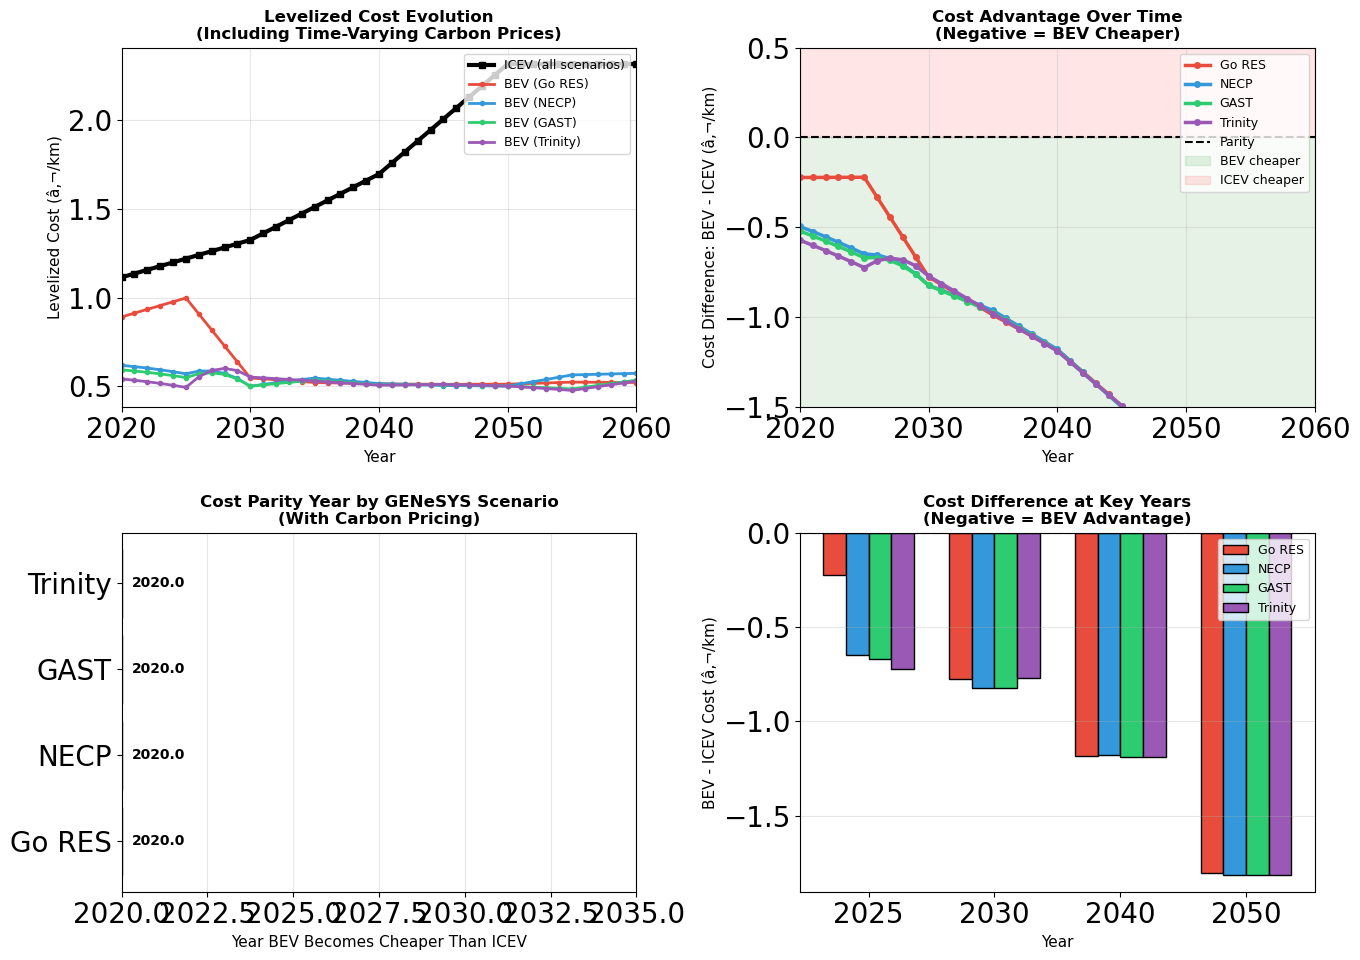


SUMMARY: COST PARITY YEARS (When BEV becomes cheaper than ICEV)
  Go RES      : 2020.0
  NECP        : 2020.0
  GAST        : 2020.0
  Trinity     : 2020.0


In [ ]:
# Now create a comprehensive visualization with corrected costs

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

colors = {'Go RES': '#e74c3c', 'NECP': '#3498db', 'GAST': '#2ecc71', 'Trinity': '#9b59b6'}

# Plot 1: Cost evolution over time
ax1 = axes[0, 0]
ax1.plot(years, results['Go RES']['icev_costs'], 'k-', linewidth=3, label='ICEV (all scenarios)', marker='s', markersize=4)
for genesys_name, color in colors.items():
    ax1.plot(years, results[genesys_name]['bev_costs'], color=color, linewidth=2, 
             label=f'BEV ({genesys_name})', marker='o', markersize=3)

ax1.set_xlabel('Year', fontsize=11)
ax1.set_ylabel('Levelized Cost (â‚¬/km)', fontsize=11)
ax1.set_title('Levelized Cost Evolution\n(Including Time-Varying Carbon Prices)', fontsize=12, fontweight='bold')
ax1.legend(loc='upper right', fontsize=9)
ax1.grid(True, alpha=0.3)
ax1.set_xlim(2020, 2060)

# Plot 2: Cost difference (BEV - ICEV)
ax2 = axes[0, 1]
for genesys_name, color in colors.items():
    ax2.plot(years, results[genesys_name]['cost_diff'], color=color, linewidth=2.5, 
             label=genesys_name, marker='o', markersize=4)

ax2.axhline(y=0, color='black', linestyle='--', linewidth=1.5, label='Parity')
ax2.fill_between(years, -2, 0, alpha=0.1, color='green', label='BEV cheaper')
ax2.fill_between(years, 0, 2, alpha=0.1, color='red', label='ICEV cheaper')

ax2.set_xlabel('Year', fontsize=11)
ax2.set_ylabel('Cost Difference: BEV - ICEV (â‚¬/km)', fontsize=11)
ax2.set_title('Cost Advantage Over Time\n(Negative = BEV Cheaper)', fontsize=12, fontweight='bold')
ax2.legend(loc='upper right', fontsize=9)
ax2.grid(True, alpha=0.3)
ax2.set_xlim(2020, 2060)
ax2.set_ylim(-1.5, 0.5)

# Plot 3: Crossover years
ax3 = axes[1, 0]
crossover_data = []
for genesys_name in ['Go RES', 'NECP', 'GAST', 'Trinity']:
    cost_diff = results[genesys_name]['cost_diff']
    crossover_year = None
    for i in range(len(years)-1):
        if cost_diff[i] > 0 and cost_diff[i+1] <= 0:
            # Linear interpolation for more precise crossover
            crossover_year = years[i] + (0 - cost_diff[i]) / (cost_diff[i+1] - cost_diff[i])
            break
    if crossover_year is None and cost_diff[0] <= 0:
        crossover_year = 2020  # Already cheaper at start
    crossover_data.append({'scenario': genesys_name, 'crossover': crossover_year})

crossover_df = pd.DataFrame(crossover_data)
bars = ax3.barh(crossover_df['scenario'], crossover_df['crossover'] - 2020, left=2020, 
                color=[colors[s] for s in crossover_df['scenario']], edgecolor='black')
ax3.set_xlabel('Year BEV Becomes Cheaper Than ICEV', fontsize=11)
ax3.set_title('Cost Parity Year by GENeSYS Scenario\n(With Carbon Pricing)', fontsize=12, fontweight='bold')
ax3.set_xlim(2020, 2035)
for i, (idx, row) in enumerate(crossover_df.iterrows()):
    if row['crossover']:
        ax3.text(row['crossover'] + 0.3, i, f"{row['crossover']:.1f}", va='center', fontsize=10, fontweight='bold')
ax3.grid(True, alpha=0.3, axis='x')

# Plot 4: Summary at key years
ax4 = axes[1, 1]
key_years = [2025, 2030, 2040, 2050]
x = np.arange(len(key_years))
width = 0.18

for i, (genesys_name, color) in enumerate(colors.items()):
    costs_at_years = [results[genesys_name]['cost_diff'][years.index(y)] for y in key_years]
    bars = ax4.bar(x + i*width, costs_at_years, width, label=genesys_name, color=color, edgecolor='black')

ax4.axhline(y=0, color='black', linestyle='--', linewidth=1.5)
ax4.set_xlabel('Year', fontsize=11)
ax4.set_ylabel('BEV - ICEV Cost (â‚¬/km)', fontsize=11)
ax4.set_title('Cost Difference at Key Years\n(Negative = BEV Advantage)', fontsize=12, fontweight='bold')
ax4.set_xticks(x + width*1.5)
ax4.set_xticklabels(key_years)
ax4.legend(loc='upper right', fontsize=9)
ax4.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig(r"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\figures\levelized_cost_with_carbon_prices.pdf", 
            dpi=150, bbox_inches='tight')
plt.show()

print("\n" + "="*80)
print("SUMMARY: COST PARITY YEARS (When BEV becomes cheaper than ICEV)")
print("="*80)
for _, row in crossover_df.iterrows():
    print(f"  {row['scenario']:<12}: {row['crossover']:.1f}")
print("="*80)

In [ ]:
import yaml

# Load carbon prices from each GENeSYS scenario
scenarios_to_check = {
    'Go RES': 'scenario_000',
    'NECP': 'scenario_006', 
    'GAST': 'scenario_012',
    'Trinity': 'scenario_018'
}

carbon_prices_by_scenario = {}

for genesys_name, scenario_folder in scenarios_to_check.items():
    geo_path = rf"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\input_data\uncertainty_scenarios\{scenario_folder}\GeographicElement.yaml"
    with open(geo_path, 'r') as f:
        geo_data = yaml.safe_load(f)
    
    for elem in geo_data:
        if 'carbon_price' in elem:
            carbon_prices_by_scenario[genesys_name] = [float(x) for x in elem['carbon_price']]
            break

# Compare carbon prices
print("Carbon Prices by GENeSYS Scenario:")
print("="*80)
years = list(range(2020, 2020 + len(carbon_prices_by_scenario['Go RES'])))

print(f"{'Year':<8}", end="")
for scenario in scenarios_to_check.keys():
    print(f"{scenario:<15}", end="")
print()
print("-"*80)

for i, year in enumerate(years):
    if i % 5 == 0:  # Every 5 years
        print(f"{year:<8}", end="")
        for scenario in scenarios_to_check.keys():
            print(f"{carbon_prices_by_scenario[scenario][i]:<15.1f}", end="")
        print()

# Check if they are different
print("\n" + "="*80)
print("Are carbon prices different across scenarios?")
all_same = True
for i in range(len(years)):
    values = [carbon_prices_by_scenario[s][i] for s in scenarios_to_check.keys()]
    if len(set(values)) > 1:
        all_same = False
        print(f"  Year {years[i]}: DIFFERENT - {values}")
        
if all_same:
    print("  NO - Carbon prices are IDENTICAL across all GENeSYS scenarios")
else:
    print("  YES - Carbon prices DIFFER across scenarios")

Carbon Prices by GENeSYS Scenario:
Year    Go RES         NECP           GAST           Trinity        
--------------------------------------------------------------------------------
2020    30.0           30.0           30.0           30.0           
2025    115.0          65.0           90.0           55.0           
2030    200.0          100.0          150.0          80.0           
2035    350.0          175.0          250.0          130.0          
2040    500.0          250.0          350.0          180.0          
2045    750.0          375.0          525.0          265.0          
2050    1000.0         500.0          700.0          350.0          
2055    1000.0         500.0          700.0          350.0          
2060    1000.0         500.0          700.0          350.0          

Are carbon prices different across scenarios?
  Year 2021: DIFFERENT - [47.0, 37.0, 42.0, 35.0]
  Year 2022: DIFFERENT - [64.0, 44.0, 54.0, 40.0]
  Year 2023: DIFFERENT - [81.0, 51.0, 66.0, 45.

In [ ]:
import yaml

# Load carbon prices from each GENeSYS scenario
scenarios_to_check = {
    'Go RES': 'scenario_000',
    'NECP': 'scenario_006', 
    'GAST': 'scenario_012',
    'Trinity': 'scenario_018'
}

carbon_prices_by_scenario = {}

for genesys_name, scenario_folder in scenarios_to_check.items():
    geo_path = rf"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\input_data\uncertainty_scenarios\{scenario_folder}\GeographicElement.yaml"
    with open(geo_path, 'r') as f:
        geo_data = yaml.safe_load(f)
    
    for elem in geo_data:
        if 'carbon_price' in elem:
            carbon_prices_by_scenario[genesys_name] = [float(x) for x in elem['carbon_price']]
            break

# Compare carbon prices
print("Carbon Prices by GENeSYS Scenario:")
print("="*80)
years = list(range(2020, 2020 + len(carbon_prices_by_scenario['Go RES'])))

print(f"{'Year':<8}", end="")
for scenario in scenarios_to_check.keys():
    print(f"{scenario:<15}", end="")
print()
print("-"*80)

for i, year in enumerate(years):
    if i % 5 == 0:  # Every 5 years
        print(f"{year:<8}", end="")
        for scenario in scenarios_to_check.keys():
            print(f"{carbon_prices_by_scenario[scenario][i]:<15.1f}", end="")
        print()

# Check if they are different
print("\n" + "="*80)
print("Are carbon prices different across scenarios?")
all_same = True
for i in range(len(years)):
    values = [carbon_prices_by_scenario[s][i] for s in scenarios_to_check.keys()]
    if len(set(values)) > 1:
        all_same = False
        break
        
if all_same:
    print("  NO - Carbon prices are IDENTICAL across all GENeSYS scenarios")
else:
    print("  YES - Carbon prices DIFFER across scenarios")

Carbon Prices by GENeSYS Scenario:
Year    Go RES         NECP           GAST           Trinity        
--------------------------------------------------------------------------------
2020    30.0           30.0           30.0           30.0           
2025    115.0          65.0           90.0           55.0           
2030    200.0          100.0          150.0          80.0           
2035    350.0          175.0          250.0          130.0          
2040    500.0          250.0          350.0          180.0          
2045    750.0          375.0          525.0          265.0          
2050    1000.0         500.0          700.0          350.0          
2055    1000.0         500.0          700.0          350.0          
2060    1000.0         500.0          700.0          350.0          

Are carbon prices different across scenarios?
  YES - Carbon prices DIFFER across scenarios


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Vehicle parameters
bev_consumption = 1.867  # kWh/km
icev_consumption = 4.656  # kWh/km
diesel_emission_factor = 266 / 1_000_000  # tCO2/kWh

# Capital and maintenance costs
bev_capital = 0.075  # â‚¬/km
icev_capital = 0.067  # â‚¬/km
bev_maintenance = 0.147  # â‚¬/km
icev_maintenance = 0.151  # â‚¬/km

# Load electricity prices for each scenario
elec_prices_by_scenario = {}
diesel_prices = None

for genesys_name, scenario_folder in scenarios_to_check.items():
    fuel_path = rf"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\input_data\uncertainty_scenarios\{scenario_folder}\FuelCost.yaml"
    with open(fuel_path, 'r') as f:
        fuel_data = yaml.safe_load(f)
    
    for item in fuel_data:
        if item.get('fuel') == 'electricity':
            elec_prices_by_scenario[genesys_name] = [float(x) for x in item['cost_per_kWh']]
        elif item.get('fuel') == 'diesel' and diesel_prices is None:
            diesel_prices = [float(x) for x in item['cost_per_kWh']]

n_years = min(len(years), len(diesel_prices))
years = years[:n_years]

# Calculate costs with SCENARIO-SPECIFIC carbon prices
results = {}
colors = {'Go RES': '#e74c3c', 'NECP': '#3498db', 'GAST': '#2ecc71', 'Trinity': '#9b59b6'}

for genesys_name in scenarios_to_check.keys():
    elec_prices = elec_prices_by_scenario[genesys_name]
    carbon_prices = carbon_prices_by_scenario[genesys_name]
    
    bev_costs = []
    icev_costs = []
    cost_diff = []
    
    for i in range(n_years):
        # BEV cost
        bev_energy = elec_prices[i] * bev_consumption
        bev_total = bev_capital + bev_maintenance + bev_energy
        
        # ICEV cost WITH scenario-specific carbon price
        carbon_cost_per_kwh = carbon_prices[i] * diesel_emission_factor
        diesel_total = diesel_prices[i] + carbon_cost_per_kwh
        icev_energy = diesel_total * icev_consumption
        icev_total = icev_capital + icev_maintenance + icev_energy
        
        bev_costs.append(bev_total)
        icev_costs.append(icev_total)
        cost_diff.append(bev_total - icev_total)
    
    results[genesys_name] = {
        'bev_costs': bev_costs,
        'icev_costs': icev_costs,
        'cost_diff': cost_diff,
        'carbon_prices': carbon_prices[:n_years]
    }

# Print summary
print("="*100)
print("CORRECTED LEVELIZED COSTS WITH SCENARIO-SPECIFIC CARBON PRICES")
print("="*100)
print(f"\n{'Year':<8} {'Go RES':<30} {'NECP':<30} {'GAST':<30} {'Trinity':<30}")
print(f"{'':8} {'CO2   ICEV   BEV   Diff':<30} {'CO2   ICEV   BEV   Diff':<30} {'CO2   ICEV   BEV   Diff':<30} {'CO2   ICEV   BEV   Diff':<30}")
print("-"*128)

for i, year in enumerate(years):
    if i % 5 == 0:
        line = f"{year:<8}"
        for scenario in scenarios_to_check.keys():
            co2 = results[scenario]['carbon_prices'][i]
            icev = results[scenario]['icev_costs'][i]
            bev = results[scenario]['bev_costs'][i]
            diff = results[scenario]['cost_diff'][i]
            line += f"{co2:>4.0f}  {icev:>5.2f}  {bev:>5.2f}  {diff:>+5.2f}   "
        print(line)

CORRECTED LEVELIZED COSTS WITH SCENARIO-SPECIFIC CARBON PRICES

Year     Go RES                         NECP                           GAST                           Trinity                       
         CO2   ICEV   BEV   Diff        CO2   ICEV   BEV   Diff        CO2   ICEV   BEV   Diff        CO2   ICEV   BEV   Diff       
--------------------------------------------------------------------------------------------------------------------------------
2020      30   1.11   0.61  -0.50     30   1.11   0.57  -0.55     30   1.11   0.55  -0.57     30   1.11   0.54  -0.57   
2025     115   1.22   0.63  -0.59     65   1.16   0.52  -0.64     90   1.19   0.51  -0.68     55   1.15   0.52  -0.62   
2030     200   1.32   0.54  -0.78    100   1.20   0.48  -0.73    150   1.26   0.50  -0.77     80   1.18   0.56  -0.62   
2035     350   1.51   0.53  -0.98    175   1.29   0.52  -0.77    250   1.39   0.55  -0.84    130   1.24   0.54  -0.69   
2040     500   1.70   0.52  -1.18    250   1.39   0.55  -

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

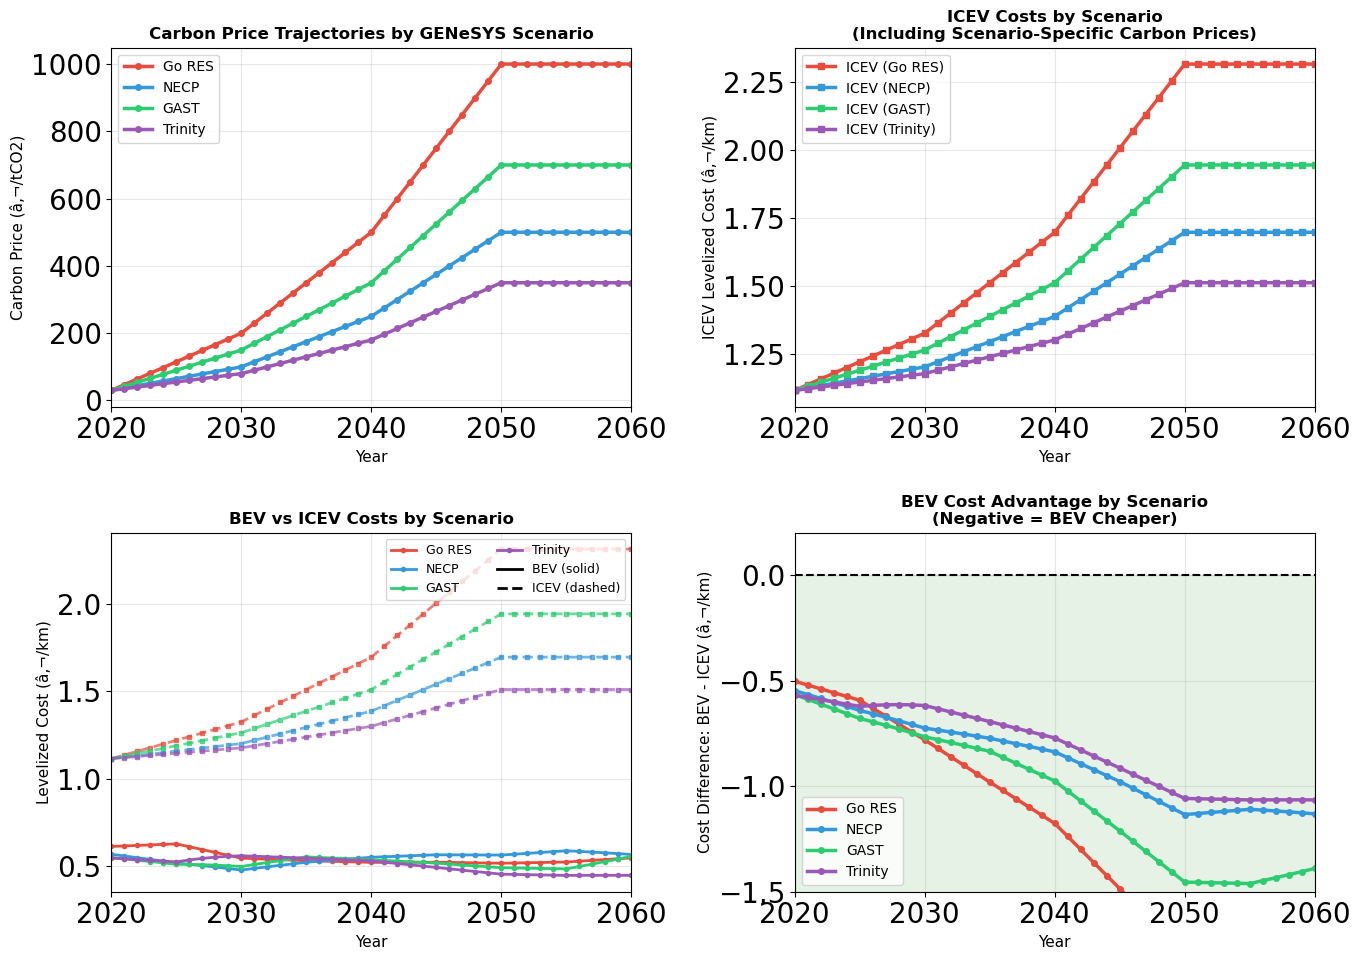


Saved to: figures/levelized_cost_scenario_specific_carbon.pdf


In [ ]:
# Create comprehensive 4-panel plot with scenario-specific carbon prices

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Carbon price trajectories by scenario
ax1 = axes[0, 0]
for genesys_name, color in colors.items():
    ax1.plot(years, results[genesys_name]['carbon_prices'], color=color, linewidth=2.5, 
             label=genesys_name, marker='o', markersize=4)

ax1.set_xlabel('Year', fontsize=11)
ax1.set_ylabel('Carbon Price (â‚¬/tCO2)', fontsize=11)
ax1.set_title('Carbon Price Trajectories by GENeSYS Scenario', fontsize=12, fontweight='bold')
ax1.legend(loc='upper left', fontsize=10)
ax1.grid(True, alpha=0.3)
ax1.set_xlim(2020, 2060)

# Plot 2: ICEV costs (now different per scenario due to carbon prices)
ax2 = axes[0, 1]
for genesys_name, color in colors.items():
    ax2.plot(years, results[genesys_name]['icev_costs'], color=color, linewidth=2.5, 
             label=f'ICEV ({genesys_name})', marker='s', markersize=4)

ax2.set_xlabel('Year', fontsize=11)
ax2.set_ylabel('ICEV Levelized Cost (â‚¬/km)', fontsize=11)
ax2.set_title('ICEV Costs by Scenario\n(Including Scenario-Specific Carbon Prices)', fontsize=12, fontweight='bold')
ax2.legend(loc='upper left', fontsize=10)
ax2.grid(True, alpha=0.3)
ax2.set_xlim(2020, 2060)

# Plot 3: BEV vs ICEV for each scenario
ax3 = axes[1, 0]
for genesys_name, color in colors.items():
    ax3.plot(years, results[genesys_name]['icev_costs'], color=color, linewidth=2, 
             linestyle='--', marker='s', markersize=3, alpha=0.7)
    ax3.plot(years, results[genesys_name]['bev_costs'], color=color, linewidth=2, 
             linestyle='-', marker='o', markersize=3, label=genesys_name)

# Add legend explanation
ax3.plot([], [], 'k-', linewidth=2, label='BEV (solid)')
ax3.plot([], [], 'k--', linewidth=2, label='ICEV (dashed)')
ax3.set_xlabel('Year', fontsize=11)
ax3.set_ylabel('Levelized Cost (â‚¬/km)', fontsize=11)
ax3.set_title('BEV vs ICEV Costs by Scenario', fontsize=12, fontweight='bold')
ax3.legend(loc='upper right', fontsize=9, ncol=2)
ax3.grid(True, alpha=0.3)
ax3.set_xlim(2020, 2060)

# Plot 4: Cost difference (BEV - ICEV) with scenario-specific values
ax4 = axes[1, 1]
for genesys_name, color in colors.items():
    ax4.plot(years, results[genesys_name]['cost_diff'], color=color, linewidth=2.5, 
             label=genesys_name, marker='o', markersize=4)

ax4.axhline(y=0, color='black', linestyle='--', linewidth=1.5)
ax4.fill_between(years, -2, 0, alpha=0.1, color='green')
ax4.set_xlabel('Year', fontsize=11)
ax4.set_ylabel('Cost Difference: BEV - ICEV (â‚¬/km)', fontsize=11)
ax4.set_title('BEV Cost Advantage by Scenario\n(Negative = BEV Cheaper)', fontsize=12, fontweight='bold')
ax4.legend(loc='lower left', fontsize=10)
ax4.grid(True, alpha=0.3)
ax4.set_xlim(2020, 2060)
ax4.set_ylim(-1.5, 0.2)

plt.tight_layout()
plt.savefig(r"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\figures\levelized_cost_scenario_specific_carbon.pdf", 
            dpi=150, bbox_inches='tight')
plt.show()

print("\nSaved to: figures/levelized_cost_scenario_specific_carbon.pdf")

In [ ]:
import yaml
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

# Scenario mapping with full details
scenario_info = {
    'scenario_000': {'genesys': 'Go RES', 'markup': 'low', 'tech_cost': 'base'},
    'scenario_001': {'genesys': 'Go RES', 'markup': 'high', 'tech_cost': 'base'},
    'scenario_002': {'genesys': 'Go RES', 'markup': 'low', 'tech_cost': 'high'},
    'scenario_003': {'genesys': 'Go RES', 'markup': 'high', 'tech_cost': 'high'},
    'scenario_004': {'genesys': 'Go RES', 'markup': 'low', 'tech_cost': 'low'},
    'scenario_005': {'genesys': 'Go RES', 'markup': 'high', 'tech_cost': 'low'},
    'scenario_006': {'genesys': 'NECP', 'markup': 'low', 'tech_cost': 'base'},
    'scenario_007': {'genesys': 'NECP', 'markup': 'high', 'tech_cost': 'base'},
    'scenario_008': {'genesys': 'NECP', 'markup': 'low', 'tech_cost': 'high'},
    'scenario_009': {'genesys': 'NECP', 'markup': 'high', 'tech_cost': 'high'},
    'scenario_010': {'genesys': 'NECP', 'markup': 'low', 'tech_cost': 'low'},
    'scenario_011': {'genesys': 'NECP', 'markup': 'high', 'tech_cost': 'low'},
    'scenario_012': {'genesys': 'GAST', 'markup': 'low', 'tech_cost': 'base'},
    'scenario_013': {'genesys': 'GAST', 'markup': 'high', 'tech_cost': 'base'},
    'scenario_014': {'genesys': 'GAST', 'markup': 'low', 'tech_cost': 'high'},
    'scenario_015': {'genesys': 'GAST', 'markup': 'high', 'tech_cost': 'high'},
    'scenario_016': {'genesys': 'GAST', 'markup': 'low', 'tech_cost': 'low'},
    'scenario_017': {'genesys': 'GAST', 'markup': 'high', 'tech_cost': 'low'},
    'scenario_018': {'genesys': 'Trinity', 'markup': 'low', 'tech_cost': 'base'},
    'scenario_019': {'genesys': 'Trinity', 'markup': 'high', 'tech_cost': 'base'},
    'scenario_020': {'genesys': 'Trinity', 'markup': 'low', 'tech_cost': 'high'},
    'scenario_021': {'genesys': 'Trinity', 'markup': 'high', 'tech_cost': 'high'},
    'scenario_022': {'genesys': 'Trinity', 'markup': 'low', 'tech_cost': 'low'},
    'scenario_023': {'genesys': 'Trinity', 'markup': 'high', 'tech_cost': 'low'},
}

# Vehicle parameters
bev_consumption = 1.867  # kWh/km
icev_consumption = 4.656  # kWh/km
diesel_emission_factor = 266 / 1_000_000  # tCO2/kWh

# Capital and maintenance costs
bev_capital = 0.075  # â‚¬/km
icev_capital = 0.067  # â‚¬/km
bev_maintenance = 0.147  # â‚¬/km
icev_maintenance = 0.151  # â‚¬/km

base_path = Path(r"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\input_data\uncertainty_scenarios")

# Load data for all scenarios
all_results = []

for scenario_folder, info in scenario_info.items():
    scenario_path = base_path / scenario_folder
    
    # Load carbon prices
    geo_path = scenario_path / "GeographicElement.yaml"
    with open(geo_path, 'r') as f:
        geo_data = yaml.safe_load(f)
    
    carbon_prices = None
    for elem in geo_data:
        if 'carbon_price' in elem:
            carbon_prices = [float(x) for x in elem['carbon_price']]
            break
    
    # Load fuel costs
    fuel_path = scenario_path / "FuelCost.yaml"
    with open(fuel_path, 'r') as f:
        fuel_data = yaml.safe_load(f)
    
    elec_prices = None
    diesel_prices = None
    for item in fuel_data:
        if item.get('fuel') == 'electricity' and elec_prices is None:
            elec_prices = [float(x) for x in item['cost_per_kWh']]
        elif item.get('fuel') == 'diesel' and diesel_prices is None:
            diesel_prices = [float(x) for x in item['cost_per_kWh']]
    
    # Calculate costs over time
    n_years = min(len(carbon_prices), len(elec_prices), len(diesel_prices))
    years = list(range(2020, 2020 + n_years))
    
    cost_diffs = []  # BEV - ICEV (negative = BEV cheaper)
    for i in range(n_years):
        # BEV cost
        bev_energy = elec_prices[i] * bev_consumption
        bev_total = bev_capital + bev_maintenance + bev_energy
        
        # ICEV cost with carbon
        carbon_cost_per_kwh = carbon_prices[i] * diesel_emission_factor
        diesel_total = diesel_prices[i] + carbon_cost_per_kwh
        icev_energy = diesel_total * icev_consumption
        icev_total = icev_capital + icev_maintenance + icev_energy
        
        cost_diffs.append(bev_total - icev_total)
    
    # Calculate average cost advantage (negative = BEV advantage)
    avg_cost_advantage = np.mean(cost_diffs)  # This will be negative when BEV is cheaper
    
    all_results.append({
        'scenario': scenario_folder,
        'genesys': info['genesys'],
        'markup': info['markup'],
        'tech_cost': info['tech_cost'],
        'avg_cost_diff': avg_cost_advantage,
        'avg_bev_advantage': -avg_cost_advantage  # Positive = BEV cheaper
    })

results_df = pd.DataFrame(all_results)
print("Average BEV Cost Advantage (â‚¬/km) by scenario:")
print(results_df[['scenario', 'genesys', 'markup', 'tech_cost', 'avg_bev_advantage']].to_string())


Average BEV Cost Advantage (â‚¬/km) by scenario:
        scenario  genesys markup tech_cost  avg_bev_advantage
0   scenario_000   Go RES    low      base           1.154764
1   scenario_001   Go RES   high      base           1.154764
2   scenario_002   Go RES    low      high           1.154764
3   scenario_003   Go RES   high      high           1.104557
4   scenario_004   Go RES    low       low           1.104557
5   scenario_005   Go RES   high       low           1.104557
6   scenario_006     NECP    low      base           0.878763
7   scenario_007     NECP   high      base           0.878763
8   scenario_008     NECP    low      high           0.878763
9   scenario_009     NECP   high      high           0.836882
10  scenario_010     NECP    low       low           0.836882
11  scenario_011     NECP   high       low           0.836882
12  scenario_012     GAST    low      base           1.036216
13  scenario_013     GAST   high      base           1.036216
14  scenario_014     

In [ ]:
import yaml
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

# Scenario mapping with full details
scenario_info = {
    'scenario_000': {'genesys': 'Go RES', 'markup': 'low', 'tech_cost': 'base'},
    'scenario_001': {'genesys': 'Go RES', 'markup': 'high', 'tech_cost': 'base'},
    'scenario_002': {'genesys': 'Go RES', 'markup': 'low', 'tech_cost': 'high'},
    'scenario_003': {'genesys': 'Go RES', 'markup': 'high', 'tech_cost': 'high'},
    'scenario_004': {'genesys': 'Go RES', 'markup': 'low', 'tech_cost': 'low'},
    'scenario_005': {'genesys': 'Go RES', 'markup': 'high', 'tech_cost': 'low'},
    'scenario_006': {'genesys': 'NECP', 'markup': 'low', 'tech_cost': 'base'},
    'scenario_007': {'genesys': 'NECP', 'markup': 'high', 'tech_cost': 'base'},
    'scenario_008': {'genesys': 'NECP', 'markup': 'low', 'tech_cost': 'high'},
    'scenario_009': {'genesys': 'NECP', 'markup': 'high', 'tech_cost': 'high'},
    'scenario_010': {'genesys': 'NECP', 'markup': 'low', 'tech_cost': 'low'},
    'scenario_011': {'genesys': 'NECP', 'markup': 'high', 'tech_cost': 'low'},
    'scenario_012': {'genesys': 'GAST', 'markup': 'low', 'tech_cost': 'base'},
    'scenario_013': {'genesys': 'GAST', 'markup': 'high', 'tech_cost': 'base'},
    'scenario_014': {'genesys': 'GAST', 'markup': 'low', 'tech_cost': 'high'},
    'scenario_015': {'genesys': 'GAST', 'markup': 'high', 'tech_cost': 'high'},
    'scenario_016': {'genesys': 'GAST', 'markup': 'low', 'tech_cost': 'low'},
    'scenario_017': {'genesys': 'GAST', 'markup': 'high', 'tech_cost': 'low'},
    'scenario_018': {'genesys': 'Trinity', 'markup': 'low', 'tech_cost': 'base'},
    'scenario_019': {'genesys': 'Trinity', 'markup': 'high', 'tech_cost': 'base'},
    'scenario_020': {'genesys': 'Trinity', 'markup': 'low', 'tech_cost': 'high'},
    'scenario_021': {'genesys': 'Trinity', 'markup': 'high', 'tech_cost': 'high'},
    'scenario_022': {'genesys': 'Trinity', 'markup': 'low', 'tech_cost': 'low'},
    'scenario_023': {'genesys': 'Trinity', 'markup': 'high', 'tech_cost': 'low'},
}

# Vehicle parameters
bev_consumption = 1.867  # kWh/km
icev_consumption = 4.656  # kWh/km
diesel_emission_factor = 266 / 1_000_000  # tCO2/kWh

# Capital and maintenance costs
bev_capital = 0.075  # â‚¬/km
icev_capital = 0.067  # â‚¬/km
bev_maintenance = 0.147  # â‚¬/km
icev_maintenance = 0.151  # â‚¬/km

base_path = Path(r"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\input_data\uncertainty_scenarios")

# Load data for all scenarios
all_results = []

for scenario_folder, info in scenario_info.items():
    scenario_path = base_path / scenario_folder
    
    # Load carbon prices
    geo_path = scenario_path / "GeographicElement.yaml"
    with open(geo_path, 'r') as f:
        geo_data = yaml.safe_load(f)
    
    carbon_prices = None
    for elem in geo_data:
        if 'carbon_price' in elem:
            carbon_prices = [float(x) for x in elem['carbon_price']]
            break
    
    # Load fuel costs
    fuel_path = scenario_path / "FuelCost.yaml"
    with open(fuel_path, 'r') as f:
        fuel_data = yaml.safe_load(f)
    
    elec_prices = None
    diesel_prices = None
    for item in fuel_data:
        if item.get('fuel') == 'electricity' and elec_prices is None:
            elec_prices = [float(x) for x in item['cost_per_kWh']]
        elif item.get('fuel') == 'diesel' and diesel_prices is None:
            diesel_prices = [float(x) for x in item['cost_per_kWh']]
    
    # Calculate costs over time
    n_years = min(len(carbon_prices), len(elec_prices), len(diesel_prices))
    years = list(range(2020, 2020 + n_years))
    
    cost_diffs = []  # BEV - ICEV (negative = BEV cheaper)
    for i in range(n_years):
        # BEV cost
        bev_energy = elec_prices[i] * bev_consumption
        bev_total = bev_capital + bev_maintenance + bev_energy
        
        # ICEV cost with carbon
        carbon_cost_per_kwh = carbon_prices[i] * diesel_emission_factor
        diesel_total = diesel_prices[i] + carbon_cost_per_kwh
        icev_energy = diesel_total * icev_consumption
        icev_total = icev_capital + icev_maintenance + icev_energy
        
        cost_diffs.append(bev_total - icev_total)
    
    # Calculate average cost advantage (negative = BEV advantage)
    avg_cost_advantage = np.mean(cost_diffs)  # This will be negative when BEV is cheaper
    
    all_results.append({
        'scenario': scenario_folder,
        'genesys': info['genesys'],
        'markup': info['markup'],
        'tech_cost': info['tech_cost'],
        'avg_cost_diff': avg_cost_advantage,
        'avg_bev_advantage': -avg_cost_advantage  # Positive = BEV cheaper
    })

results_df = pd.DataFrame(all_results)
print("Average BEV Cost Advantage (â‚¬/km) by scenario:")
print(results_df[['scenario', 'genesys', 'markup', 'tech_cost', 'avg_bev_advantage']].to_string())

Average BEV Cost Advantage (â‚¬/km) by scenario:
        scenario  genesys markup tech_cost  avg_bev_advantage
0   scenario_000   Go RES    low      base           1.154764
1   scenario_001   Go RES   high      base           1.154764
2   scenario_002   Go RES    low      high           1.154764
3   scenario_003   Go RES   high      high           1.104557
4   scenario_004   Go RES    low       low           1.104557
5   scenario_005   Go RES   high       low           1.104557
6   scenario_006     NECP    low      base           0.878763
7   scenario_007     NECP   high      base           0.878763
8   scenario_008     NECP    low      high           0.878763
9   scenario_009     NECP   high      high           0.836882
10  scenario_010     NECP    low       low           0.836882
11  scenario_011     NECP   high       low           0.836882
12  scenario_012     GAST    low      base           1.036216
13  scenario_013     GAST   high      base           1.036216
14  scenario_014     

In [ ]:
# Now load electrification speed from model results
# We need to find the year when BEV share reaches 50% or another metric

results_base = Path(r"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\results\uncertainty_analysis")

# Check what results are available
if results_base.exists():
    available = list(results_base.glob("scenario_*"))
    print(f"Found {len(available)} result folders")
    for a in available[:3]:
        print(f"  {a.name}")
else:
    print("Results folder not found - checking alternative location")
    
# Let's look for result files
results_base2 = Path(r"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\results")
if results_base2.exists():
    print("\nAvailable in results folder:")
    for item in results_base2.iterdir():
        print(f"  {item.name}")

Found 24 result folders
  scenario_000
  scenario_001
  scenario_002

Available in results folder:
  border_sensitivity
  bs
  case_20251020_165709
  case_20251021_135120
  case_20251021_141603
  case_20251022_121549
  case_20251022_133247
  case_20251022_145458
  case_20251022_152235_var_var
  case_20251022_152358_var_uni
  case_20251022_153056_uni_var
  case_20251022_153317_uni_uni
  case_20251024_110642_infrcosts_0
  case_20251028_091344_var_var
  case_20251028_091411_var_uni
  case_20251028_091502_uni_var
  case_20251028_091635_uni_uni
  case_20251029_131627_var_var
  case_20251029_131652_var_uni
  case_20251029_131722_uni_var
  case_20251029_131830_uni_uni
  case_20251029_154754
  case_20251030_102652
  case_20251030_110710
  case_20251030_113213_var_var
  case_20251030_113248_var_uni
  case_20251030_113325_uni_var
  case_20251030_113500_uni_uni
  case_20251030_113642_var_var_rev
  case_20251030_142356
  case_20251102_093733
  case_20251102_104019
  case_20251103_114421
  case_202

In [ ]:
# Now load electrification speed from model results
# We need to find the year when BEV share reaches 50% or another metric

results_base = Path(r"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\results\uncertainty_analysis")

# Check what results are available
if results_base.exists():
    available = list(results_base.glob("scenario_*"))
    print(f"Found {len(available)} result folders")
    for a in available[:3]:
        print(f"  {a.name}")
else:
    print("Results folder not found - checking alternative location")
    
# Let's look for result files
results_base2 = Path(r"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\results")
if results_base2.exists():
    print("\nAvailable in results folder:")
    for item in results_base2.iterdir():
        print(f"  {item.name}")

Found 24 result folders
  scenario_000
  scenario_001
  scenario_002

Available in results folder:
  border_sensitivity
  bs
  case_20251020_165709
  case_20251021_135120
  case_20251021_141603
  case_20251022_121549
  case_20251022_133247
  case_20251022_145458
  case_20251022_152235_var_var
  case_20251022_152358_var_uni
  case_20251022_153056_uni_var
  case_20251022_153317_uni_uni
  case_20251024_110642_infrcosts_0
  case_20251028_091344_var_var
  case_20251028_091411_var_uni
  case_20251028_091502_uni_var
  case_20251028_091635_uni_uni
  case_20251029_131627_var_var
  case_20251029_131652_var_uni
  case_20251029_131722_uni_var
  case_20251029_131830_uni_uni
  case_20251029_154754
  case_20251030_102652
  case_20251030_110710
  case_20251030_113213_var_var
  case_20251030_113248_var_uni
  case_20251030_113325_uni_var
  case_20251030_113500_uni_uni
  case_20251030_113642_var_var_rev
  case_20251030_142356
  case_20251102_093733
  case_20251102_104019
  case_20251103_114421
  case_202

In [ ]:
# Load electrification speed from the uncertainty analysis results
# Check the structure of results

sample_result_path = results_base / "scenario_000"
print("Contents of scenario_000 results:")
for item in sample_result_path.iterdir():
    print(f"  {item.name}")

Contents of scenario_000 results:
  scenario_000_2025-12-04_09-39-33_f_dict.yaml
  scenario_000_2025-12-04_09-39-33_h_dict.yaml
  scenario_000_2025-12-04_09-39-33_h_exist_dict.yaml
  scenario_000_2025-12-04_09-39-33_h_minus_dict.yaml
  scenario_000_2025-12-04_09-39-33_h_plus_dict.yaml
  scenario_000_2025-12-04_09-39-33_s_dict.yaml
  scenario_000_2025-12-04_10-12-33_constraints_applied.txt
  scenario_000_2025-12-04_10-12-33_extra_break_time_dict.yaml
  scenario_000_2025-12-04_10-12-33_f_dict.yaml
  scenario_000_2025-12-04_10-12-33_h_dict.yaml
  scenario_000_2025-12-04_10-12-33_h_exist_dict.yaml
  scenario_000_2025-12-04_10-12-33_h_minus_dict.yaml
  scenario_000_2025-12-04_10-12-33_h_plus_dict.yaml
  scenario_000_2025-12-04_10-12-33_q_fuel_infr_plus_dict.yaml
  scenario_000_2025-12-04_10-12-33_soc_dict.yaml
  scenario_000_2025-12-04_10-12-33_s_dict.yaml
  scenario_000_2025-12-04_10-12-33_travel_time_dict.yaml
  scenario_000_2025-12-12_18-51-06_constraints_applied.txt
  scenario_000_2025-

In [ ]:
# Load h_dict (vehicle stock) to calculate electrification speed
# h_dict contains vehicle counts by technology and year

def load_latest_h_dict(scenario_path):
    """Load the most recent h_dict file from scenario results"""
    h_files = list(scenario_path.glob("*_h_dict.yaml"))
    if not h_files:
        return None
    # Get the latest one
    latest = sorted(h_files)[-1]
    with open(latest, 'r') as f:
        return yaml.safe_load(f)

# Load h_dict for scenario_000
h_dict = load_latest_h_dict(sample_result_path)
print(f"h_dict has {len(h_dict)} entries")
print("\nSample entries:")
for i, (key, value) in enumerate(h_dict.items()):
    if i < 5:
        print(f"  {key}: {value}")

h_dict has 126650 entries

Sample entries:
  (2044, 2704, 0, 2040): 0.011081
  (2032, 3570, 1, 2032): 0.001734
  (2044, 195, 0, 2040): 0.519015
  (2040, 162, 0, 2032): 11.461975
  (2040, 5242, 0, 2032): 8.377976


In [ ]:
# The key structure is (year, odpair_id, tech_id, purchase_year)
# tech_id: 0 = ICEV, 1 = BEV

def calculate_electrification_metrics(h_dict):
    """Calculate BEV share over time from h_dict"""
    # Aggregate by year and tech
    year_tech_totals = {}
    
    for key, value in h_dict.items():
        # Parse key - it might be string or tuple
        if isinstance(key, str):
            # Parse string like "(2060, 1144, 0, 2060)"
            parts = key.strip("()").split(",")
            year = int(parts[0].strip())
            tech_id = int(parts[2].strip())
        else:
            year, odpair_id, tech_id, purchase_year = key
        
        if year not in year_tech_totals:
            year_tech_totals[year] = {0: 0, 1: 0}
        
        year_tech_totals[year][tech_id] += float(value)
    
    # Calculate BEV share by year
    bev_shares = {}
    for year in sorted(year_tech_totals.keys()):
        total = year_tech_totals[year][0] + year_tech_totals[year][1]
        if total > 0:
            bev_shares[year] = year_tech_totals[year][1] / total
        else:
            bev_shares[year] = 0
    
    return bev_shares

# Test with scenario_000
bev_shares = calculate_electrification_metrics(h_dict)
print("BEV share by year for scenario_000:")
for year, share in sorted(bev_shares.items()):
    if year % 4 == 0:  # Show every 4 years
        print(f"  {year}: {share*100:.1f}%")

BEV share by year for scenario_000:
  2020: 0.0%
  2024: 0.0%
  2028: 0.0%
  2032: 10.0%
  2036: 20.3%
  2040: 30.8%
  2044: 42.9%
  2048: 48.6%
  2052: 54.2%
  2056: 69.1%
  2060: 67.2%


In [ ]:
# Now load all scenarios and calculate electrification speed
# We'll use the year when 50% BEV share is reached as the "electrification speed" metric

def find_50pct_year(bev_shares):
    """Find the year when BEV share reaches 50%"""
    years = sorted(bev_shares.keys())
    for i, year in enumerate(years):
        if bev_shares[year] >= 0.5:
            # Linear interpolation to get more precise year
            if i > 0:
                prev_year = years[i-1]
                prev_share = bev_shares[prev_year]
                curr_share = bev_shares[year]
                if curr_share > prev_share:
                    # Interpolate
                    fraction = (0.5 - prev_share) / (curr_share - prev_share)
                    return prev_year + fraction * (year - prev_year)
            return year
    return 2060  # If never reaches 50%

# Load all scenarios
electrification_data = []

for scenario_folder in scenario_info.keys():
    scenario_path = results_base / scenario_folder
    if scenario_path.exists():
        h_dict = load_latest_h_dict(scenario_path)
        if h_dict:
            bev_shares = calculate_electrification_metrics(h_dict)
            year_50pct = find_50pct_year(bev_shares)
            
            # Also get final BEV share
            final_year = max(bev_shares.keys())
            final_share = bev_shares[final_year]
            
            electrification_data.append({
                'scenario': scenario_folder,
                'year_50pct': year_50pct,
                'final_bev_share': final_share,
                'bev_shares': bev_shares
            })
            print(f"{scenario_folder}: 50% reached at {year_50pct:.1f}, final share: {final_share*100:.1f}%")

print(f"\nLoaded {len(electrification_data)} scenarios")

scenario_000: 50% reached at 2049.0, final share: 67.2%
scenario_001: 50% reached at 2056.0, final share: 49.3%
scenario_002: 50% reached at 2060.0, final share: 0.0%
scenario_003: 50% reached at 2049.1, final share: 66.7%
scenario_004: 50% reached at 2056.0, final share: 49.3%
scenario_005: 50% reached at 2060.0, final share: 0.0%
scenario_006: 50% reached at 2049.4, final share: 65.7%
scenario_007: 50% reached at 2056.0, final share: 49.3%
scenario_008: 50% reached at 2060.0, final share: 0.0%
scenario_009: 50% reached at 2049.4, final share: 65.8%
scenario_010: 50% reached at 2056.0, final share: 49.3%
scenario_011: 50% reached at 2060.0, final share: 0.0%
scenario_012: 50% reached at 2049.4, final share: 65.8%
scenario_013: 50% reached at 2056.0, final share: 49.3%
scenario_014: 50% reached at 2060.0, final share: 0.0%
scenario_015: 50% reached at 2049.4, final share: 65.8%
scenario_016: 50% reached at 2056.0, final share: 49.2%
scenario_017: 50% reached at 2060.0, final share: 0.0

In [ ]:
# Now load all scenarios and calculate electrification speed
# We'll use the year when 50% BEV share is reached as the "electrification speed" metric

def find_50pct_year(bev_shares):
    """Find the year when BEV share reaches 50%"""
    years = sorted(bev_shares.keys())
    for i, year in enumerate(years):
        if bev_shares[year] >= 0.5:
            # Linear interpolation to get more precise year
            if i > 0:
                prev_year = years[i-1]
                prev_share = bev_shares[prev_year]
                curr_share = bev_shares[year]
                if curr_share > prev_share:
                    # Interpolate
                    fraction = (0.5 - prev_share) / (curr_share - prev_share)
                    return prev_year + fraction * (year - prev_year)
            return year
    return 2060  # If never reaches 50%

# Load all scenarios
electrification_data = []

for scenario_folder in scenario_info.keys():
    scenario_path = results_base / scenario_folder
    if scenario_path.exists():
        h_dict = load_latest_h_dict(scenario_path)
        if h_dict:
            bev_shares = calculate_electrification_metrics(h_dict)
            year_50pct = find_50pct_year(bev_shares)
            
            # Also get final BEV share
            final_year = max(bev_shares.keys())
            final_share = bev_shares[final_year]
            
            electrification_data.append({
                'scenario': scenario_folder,
                'year_50pct': year_50pct,
                'final_bev_share': final_share,
                'bev_shares': bev_shares
            })
            print(f"{scenario_folder}: 50% reached at {year_50pct:.1f}, final share: {final_share*100:.1f}%")

print(f"\nLoaded {len(electrification_data)} scenarios")

scenario_000: 50% reached at 2049.0, final share: 67.2%
scenario_001: 50% reached at 2056.0, final share: 49.3%
scenario_002: 50% reached at 2060.0, final share: 0.0%
scenario_003: 50% reached at 2049.1, final share: 66.7%
scenario_004: 50% reached at 2056.0, final share: 49.3%
scenario_005: 50% reached at 2060.0, final share: 0.0%
scenario_006: 50% reached at 2049.4, final share: 65.7%
scenario_007: 50% reached at 2056.0, final share: 49.3%
scenario_008: 50% reached at 2060.0, final share: 0.0%
scenario_009: 50% reached at 2049.4, final share: 65.8%
scenario_010: 50% reached at 2056.0, final share: 49.3%
scenario_011: 50% reached at 2060.0, final share: 0.0%
scenario_012: 50% reached at 2049.4, final share: 65.8%
scenario_013: 50% reached at 2056.0, final share: 49.3%
scenario_014: 50% reached at 2060.0, final share: 0.0%
scenario_015: 50% reached at 2049.4, final share: 65.8%
scenario_016: 50% reached at 2056.0, final share: 49.2%
scenario_017: 50% reached at 2060.0, final share: 0.0

In [ ]:
# Merge cost advantage with electrification data
elec_df = pd.DataFrame(electrification_data)
merged_df = results_df.merge(elec_df, on='scenario')

# Calculate electrification speed as inverse of year (earlier = faster)
# Or use (2060 - year_50pct) as speed metric
merged_df['electrification_speed'] = 2060 - merged_df['year_50pct']

print("\nMerged data:")
print(merged_df[['scenario', 'genesys', 'markup', 'tech_cost', 'avg_bev_advantage', 'year_50pct', 'electrification_speed', 'final_bev_share']].to_string())


Merged data:
        scenario  genesys markup tech_cost  avg_bev_advantage   year_50pct  electrification_speed  final_bev_share
0   scenario_000   Go RES    low      base           1.154764  2049.007495              10.992505         0.671544
1   scenario_001   Go RES   high      base           1.154764  2055.981737               4.018263         0.492844
2   scenario_002   Go RES    low      high           1.154764  2060.000000               0.000000         0.000000
3   scenario_003   Go RES   high      high           1.104557  2049.118619              10.881381         0.667276
4   scenario_004   Go RES    low       low           1.104557  2055.981698               4.018302         0.492744
5   scenario_005   Go RES   high       low           1.104557  2060.000000               0.000000         0.000000
6   scenario_006     NECP    low      base           0.878763  2049.426642              10.573358         0.657319
7   scenario_007     NECP   high      base           0.878763  205

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

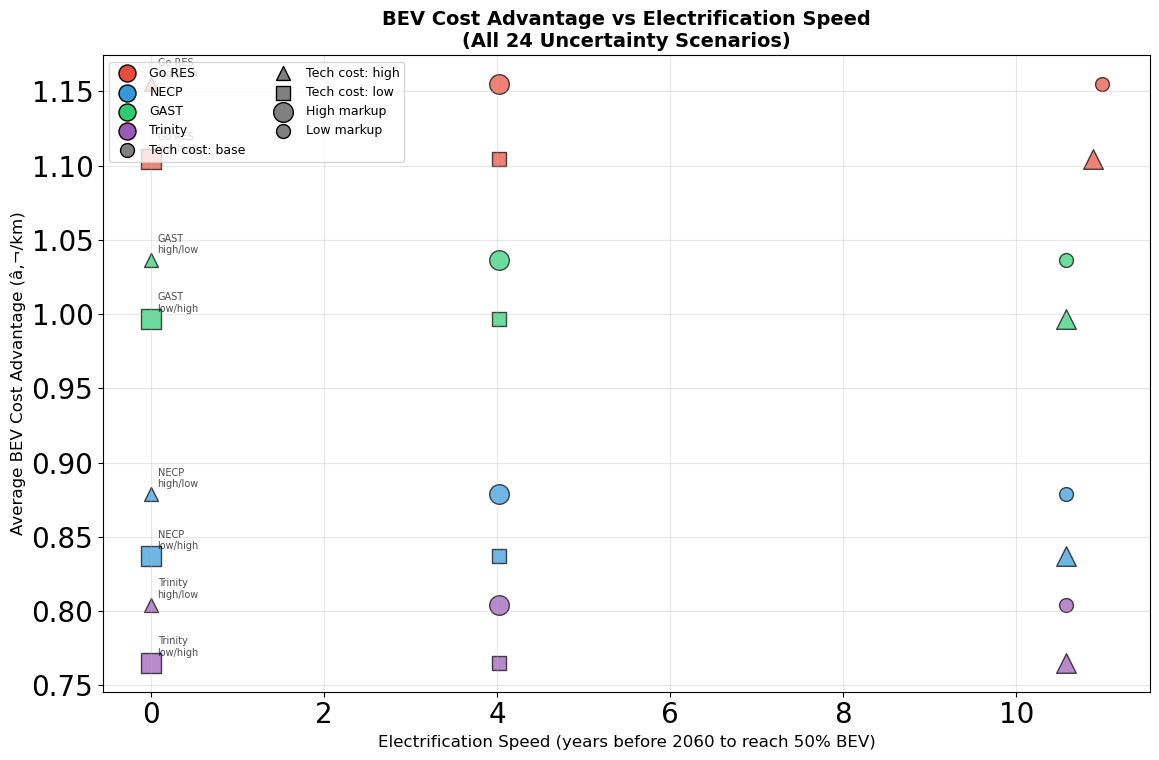


Saved to: figures/cost_advantage_vs_electrification.pdf


In [ ]:
# Create the plot: BEV cost advantage (y) vs electrification speed (x)

fig, ax = plt.subplots(figsize=(12, 8))

# Colors by GENeSYS scenario
colors = {'Go RES': '#e74c3c', 'NECP': '#3498db', 'GAST': '#2ecc71', 'Trinity': '#9b59b6'}

# Markers by tech_cost
markers = {'base': 'o', 'high': '^', 'low': 's'}

# Plot each scenario
for idx, row in merged_df.iterrows():
    color = colors[row['genesys']]
    marker = markers[row['tech_cost']]
    
    # Size based on markup (larger = high markup)
    size = 200 if row['markup'] == 'high' else 100
    
    ax.scatter(row['electrification_speed'], row['avg_bev_advantage'], 
               c=color, marker=marker, s=size, alpha=0.7, edgecolors='black', linewidth=1)

# Add legend for GENeSYS scenarios
for genesys, color in colors.items():
    ax.scatter([], [], c=color, label=genesys, s=150, edgecolors='black')

# Add legend for tech_cost markers
for tech_cost, marker in markers.items():
    ax.scatter([], [], c='gray', marker=marker, label=f'Tech cost: {tech_cost}', s=100, edgecolors='black')

# Add legend for markup size
ax.scatter([], [], c='gray', s=200, label='High markup', edgecolors='black')
ax.scatter([], [], c='gray', s=100, label='Low markup', edgecolors='black')

ax.set_xlabel('Electrification Speed (years before 2060 to reach 50% BEV)', fontsize=12)
ax.set_ylabel('Average BEV Cost Advantage (â‚¬/km)', fontsize=12)
ax.set_title('BEV Cost Advantage vs Electrification Speed\n(All 24 Uncertainty Scenarios)', fontsize=14, fontweight='bold')

ax.legend(loc='upper left', fontsize=9, ncol=2)
ax.grid(True, alpha=0.3)

# Add annotations for extreme points
for idx, row in merged_df.iterrows():
    if row['electrification_speed'] > 15 or row['electrification_speed'] == 0:
        ax.annotate(f"{row['genesys']}\n{row['tech_cost']}/{row['markup']}", 
                   (row['electrification_speed'], row['avg_bev_advantage']),
                   fontsize=7, alpha=0.7,
                   xytext=(5, 5), textcoords='offset points')

plt.tight_layout()
plt.savefig(r"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\figures\cost_advantage_vs_electrification.pdf", 
            dpi=150, bbox_inches='tight')
plt.show()

print("\nSaved to: figures/cost_advantage_vs_electrification.pdf")

In [ ]:
import yaml
import os
from pathlib import Path

scenarios_path = Path(r"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\input_data\uncertainty_scenarios")

# Load all scenario metadata
scenario_params = {}
for i in range(24):
    metadata_path = scenarios_path / f"scenario_{i:03d}" / "case_metadata.yaml"
    if metadata_path.exists():
        with open(metadata_path, 'r') as f:
            metadata = yaml.safe_load(f)
        
        params = metadata.get('parameters', {})
        scenario_params[f"scenario_{i:03d}"] = {
            'genesys': metadata.get('genesys_scenario', 'Unknown'),
            'charging_markup': params.get('charging_markup', 0),
            'tech_cost_multiplier': params.get('tech_cost_multiplier', 1.0),
            'carbon_prices': params.get('carbon_price_trajectory', {})
        }

# Display the structure
print("Scenario parameters:")
print("-" * 80)
for scenario, params in sorted(scenario_params.items()):
    genesys_short = params['genesys'].replace(' v1.2', '')
    markup = params['charging_markup']
    tech_mult = params['tech_cost_multiplier']
    carbon_2050 = params['carbon_prices'].get(2050, 'N/A')
    print(f"{scenario}: GENeSYS={genesys_short:12s}, markup={markup:.0%}, tech_mult={tech_mult:.1f}, CO2_2050={carbon_2050}")


ConstructorError: could not determine a constructor for the tag 'tag:yaml.org,2002:python/object/apply:numpy._core.multiarray.scalar'
  in "C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\input_data\uncertainty_scenarios\scenario_000\case_metadata.yaml", line 14, column 33

In [ ]:
import yaml
import os
from pathlib import Path

scenarios_path = Path(r"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\input_data\uncertainty_scenarios")

# Load all scenario metadata
scenario_params = {}
for i in range(24):
    metadata_path = scenarios_path / f"scenario_{i:03d}" / "case_metadata.yaml"
    if metadata_path.exists():
        with open(metadata_path, 'r') as f:
            metadata = yaml.safe_load(f)
        
        params = metadata.get('parameters', {})
        scenario_params[f"scenario_{i:03d}"] = {
            'genesys': metadata.get('genesys_scenario', 'Unknown'),
            'charging_markup': params.get('charging_markup', 0),
            'tech_cost_multiplier': params.get('tech_cost_multiplier', 1.0),
            'carbon_prices': params.get('carbon_price_trajectory', {})
        }

# Display the structure
print("Scenario parameters:")
print("-" * 80)
for scenario, params in sorted(scenario_params.items()):
    genesys_short = params['genesys'].replace(' v1.2', '')
    markup = params['charging_markup']
    tech_mult = params['tech_cost_multiplier']
    carbon_2050 = params['carbon_prices'].get(2050, 'N/A')
    print(f"{scenario}: GENeSYS={genesys_short:12s}, markup={markup:.0%}, tech_mult={tech_mult:.1f}, CO2_2050={carbon_2050}")


## Carbon Price Impact on Levelized Costs

The GENeSYS scenarios have different carbon price trajectories that significantly impact the true cost of diesel (ICEV) operations:

| Scenario | 2020 | 2030 | 2040 | 2050 |
|----------|------|------|------|------|
| Go RES | 30 | 200 | 500 | 1000 |
| REPowerEU++ | 30 | 150 | 350 | 700 |
| NECPEssentials | 30 | 100 | 250 | 500 |
| Trinity | 30 | 80 | 180 | 350 |

Carbon pricing adds: `carbon_price (EUR/tCO2) × 0.000266 (tCO2/kWh)` to diesel costs.

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

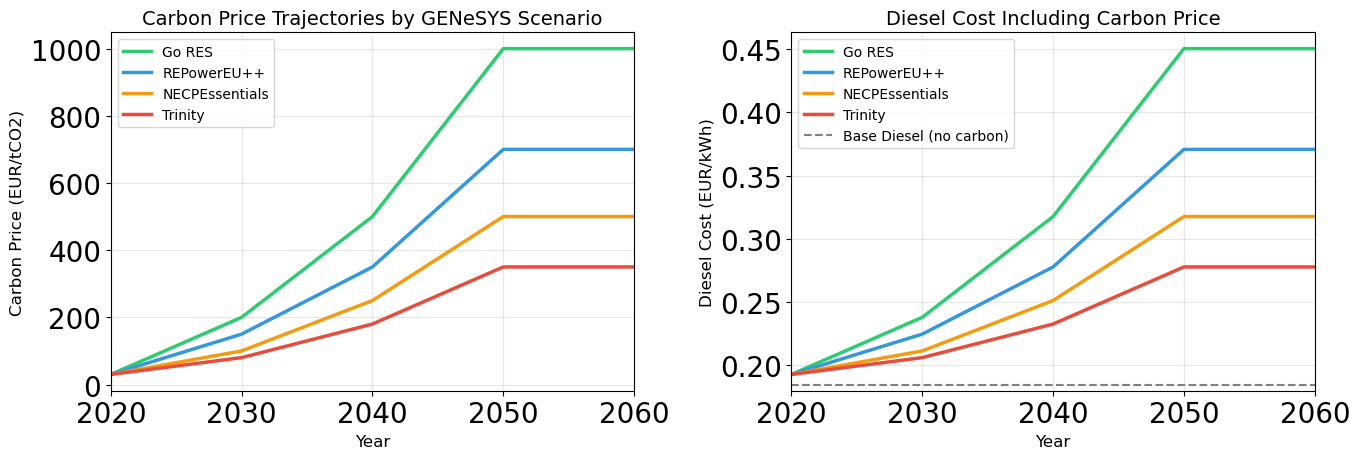

Carbon cost component added to diesel (EUR/kWh):
  Go RES in 2040: +0.1330 EUR/kWh (total: 0.3175 EUR/kWh, +72.1%)
  REPowerEU++ in 2040: +0.0931 EUR/kWh (total: 0.2776 EUR/kWh, +50.5%)
  NECPEssentials in 2040: +0.0665 EUR/kWh (total: 0.2510 EUR/kWh, +36.0%)
  Trinity in 2040: +0.0479 EUR/kWh (total: 0.2324 EUR/kWh, +26.0%)


In [ ]:
# Carbon price trajectories from GENeSYS scenarios
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

CARBON_PRICE_TRAJECTORIES = {
    'Go RES': {2020: 30, 2030: 200, 2040: 500, 2050: 1000, 2060: 1000},
    'REPowerEU++': {2020: 30, 2030: 150, 2040: 350, 2050: 700, 2060: 700},
    'NECPEssentials': {2020: 30, 2030: 100, 2040: 250, 2050: 500, 2060: 500},
    'Trinity': {2020: 30, 2030: 80, 2040: 180, 2050: 350, 2060: 350}
}

# Base diesel cost
BASE_DIESEL_COST = 0.1845  # EUR/kWh
DIESEL_EMISSION_FACTOR = 0.000266  # tCO2/kWh (266 gCO2/kWh)

def interpolate_trajectory(traj, years):
    """Interpolate carbon prices for all years."""
    key_years = sorted(traj.keys())
    key_values = [traj[y] for y in key_years]
    return np.interp(years, key_years, key_values)

years = np.arange(2020, 2061, 2)  # Match model timesteps

# Create figure with two subplots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Color scheme consistent with existing plots
colors = {
    'Go RES': '#2ecc71',
    'REPowerEU++': '#3498db',
    'NECPEssentials': '#f39c12',
    'Trinity': '#e74c3c'
}

# Plot 1: Carbon Price Trajectories
ax1 = axes[0]
for scenario, traj in CARBON_PRICE_TRAJECTORIES.items():
    prices = interpolate_trajectory(traj, years)
    ax1.plot(years, prices, label=scenario, linewidth=2.5, color=colors[scenario])

ax1.set_xlabel('Year', fontsize=12)
ax1.set_ylabel('Carbon Price (EUR/tCO2)', fontsize=12)
ax1.set_title('Carbon Price Trajectories by GENeSYS Scenario', fontsize=14)
ax1.legend(loc='upper left', fontsize=10)
ax1.grid(True, alpha=0.3)
ax1.set_xlim(2020, 2060)

# Plot 2: Diesel Cost with Carbon Price
ax2 = axes[1]
for scenario, traj in CARBON_PRICE_TRAJECTORIES.items():
    carbon_prices = interpolate_trajectory(traj, years)
    carbon_cost_component = carbon_prices * DIESEL_EMISSION_FACTOR
    total_diesel_cost = BASE_DIESEL_COST + carbon_cost_component
    ax2.plot(years, total_diesel_cost, label=scenario, linewidth=2.5, color=colors[scenario])

# Add base diesel cost line
ax2.axhline(y=BASE_DIESEL_COST, color='gray', linestyle='--', linewidth=1.5, label='Base Diesel (no carbon)')

ax2.set_xlabel('Year', fontsize=12)
ax2.set_ylabel('Diesel Cost (EUR/kWh)', fontsize=12)
ax2.set_title('Diesel Cost Including Carbon Price', fontsize=14)
ax2.legend(loc='upper left', fontsize=10)
ax2.grid(True, alpha=0.3)
ax2.set_xlim(2020, 2060)

plt.tight_layout()
plt.savefig('figures/carbon_price_driving_electrification.pdf', bbox_inches='tight', dpi=300)
plt.savefig('figures/carbon_price_driving_electrification.png', bbox_inches='tight', dpi=150)
plt.show()

# Print some key values
print("Carbon cost component added to diesel (EUR/kWh):")
for scenario, traj in CARBON_PRICE_TRAJECTORIES.items():
    cp_2040 = interpolate_trajectory(traj, [2040])[0]
    cc_2040 = cp_2040 * DIESEL_EMISSION_FACTOR
    total_2040 = BASE_DIESEL_COST + cc_2040
    print(f"  {scenario} in 2040: +{cc_2040:.4f} EUR/kWh (total: {total_2040:.4f} EUR/kWh, +{cc_2040/BASE_DIESEL_COST*100:.1f}%)")

### Levelized Costs with Carbon Pricing

The optimization model may implicitly consider carbon pricing through various mechanisms. Let's calculate the carbon-adjusted levelized costs:

In [ ]:
# Calculate levelized costs WITH carbon pricing
# This shows the true cost comparison between BEV and ICEV

# First, let's load electricity prices from scenario data
from pathlib import Path
import yaml
import pandas as pd

def load_electricity_prices_for_scenario(scenario_dir):
    """Load electricity prices from FuelCost.yaml for a scenario."""
    fuel_cost_path = Path(scenario_dir) / 'FuelCost.yaml'
    if not fuel_cost_path.exists():
        return None

    with open(fuel_cost_path, 'r') as f:
        fuel_costs = yaml.safe_load(f)

    # Find electricity cost (fuel=electricity)
    for fc in fuel_costs:
        if fc.get('fuel') == 'electricity':
            return fc.get('cost_per_kWh', [])
    return None

# Load scenario metadata
scenarios_base = Path('input_data/uncertainty_scenarios')
scenario_dirs = sorted([d for d in scenarios_base.iterdir() if d.is_dir() and d.name.startswith('scenario_')])

# Model parameters
MODEL_YEARS = list(range(2020, 2061, 2))  # 2020, 2022, ..., 2060

# BEV and ICEV efficiency parameters
BEV_EFFICIENCY = 1.2  # kWh/km (for heavy trucks)
ICEV_EFFICIENCY = 3.0  # kWh/km (diesel equivalent for heavy trucks)

# Annual driving distance assumption
ANNUAL_KM = 100000  # km per vehicle per year

# Vehicle capital cost difference (simplified)
# BEV premium over ICEV
BEV_PREMIUM = 50000  # EUR

# Create comparison dataframe
levelized_data = []

for scenario_dir in scenario_dirs[:4]:  # First 4 scenarios (one per GENeSYS)
    scenario_name = scenario_dir.name

    # Load scenario config to get GENeSYS name
    config_path = scenario_dir / 'scenario_config.json'
    if config_path.exists():
        with open(config_path) as f:
            config = json.load(f)
        genesys = config.get('genesys_scenario', '').replace(' v1.2', '')
    else:
        genesys = 'Unknown'

    # Load electricity prices
    elec_prices = load_electricity_prices_for_scenario(scenario_dir)
    if elec_prices is None:
        continue

    # Get carbon price trajectory for this scenario
    if genesys in CARBON_PRICE_TRAJECTORIES:
        carbon_traj = CARBON_PRICE_TRAJECTORIES[genesys]
    else:
        carbon_traj = CARBON_PRICE_TRAJECTORIES['Go RES']  # Default

    for year_idx, year in enumerate(MODEL_YEARS):
        if year_idx >= len(elec_prices):
            break

        elec_price = elec_prices[year_idx]
        carbon_price = interpolate_trajectory(carbon_traj, [year])[0]
        carbon_cost = carbon_price * DIESEL_EMISSION_FACTOR
        diesel_price_with_carbon = BASE_DIESEL_COST + carbon_cost

        # Calculate annual fuel costs
        bev_fuel_cost = elec_price * BEV_EFFICIENCY * ANNUAL_KM
        icev_fuel_cost_base = BASE_DIESEL_COST * ICEV_EFFICIENCY * ANNUAL_KM
        icev_fuel_cost_carbon = diesel_price_with_carbon * ICEV_EFFICIENCY * ANNUAL_KM

        levelized_data.append({
            'scenario': scenario_name,
            'genesys': genesys,
            'year': year,
            'electricity_price': elec_price,
            'carbon_price': carbon_price,
            'diesel_base': BASE_DIESEL_COST,
            'diesel_with_carbon': diesel_price_with_carbon,
            'bev_fuel_cost_annual': bev_fuel_cost,
            'icev_fuel_cost_base': icev_fuel_cost_base,
            'icev_fuel_cost_carbon': icev_fuel_cost_carbon,
            'bev_advantage_base': icev_fuel_cost_base - bev_fuel_cost,
            'bev_advantage_carbon': icev_fuel_cost_carbon - bev_fuel_cost
        })

df_levelized = pd.DataFrame(levelized_data)
print(f"Calculated levelized costs for {len(df_levelized)} scenario-year combinations")
df_levelized.head(10)

Calculated levelized costs for 84 scenario-year combinations


,scenario,genesys,year,electricity_price,carbon_price,diesel_base,diesel_with_carbon,bev_fuel_cost_annual,icev_fuel_cost_base,icev_fuel_cost_carbon,bev_advantage_base,bev_advantage_carbon
0,scenario_000,Unknown,2020,0.358485,30.0,0.1845,0.192480,43018.219028,55350.0,57744.0,12331.780972,14725.780972
1,scenario_000,Unknown,2022,0.369897,64.0,0.1845,0.201524,44387.685291,55350.0,60457.2,10962.314709,16069.514709
2,scenario_000,Unknown,2024,0.381310,98.0,0.1845,0.210568,45757.151554,55350.0,63170.4,9592.848446,17413.248446
3,scenario_000,Unknown,2026,0.392722,132.0,0.1845,0.219612,47126.617817,55350.0,65883.6,8223.382183,18756.982183
4,scenario_000,Unknown,2028,0.404134,166.0,0.1845,0.228656,48496.084079,55350.0,68596.8,6853.915921,20100.715921
5,scenario_000,Unknown,2030,0.415546,200.0,0.1845,0.237700,49865.550342,55350.0,71310.0,5484.449658,21444.449658
6,scenario_000,Unknown,2032,0.367296,260.0,0.1845,0.253660,44075.562839,55350.0,76098.0,11274.437161,32022.437161
7,scenario_000,Unknown,2034,0.319046,320.0,0.1845,0.269620,38285.575335,55350.0,80886.0,17064.424665,42600.424665
8,scenario_000,Unknown,2036,0.270797,380.0,0.1845,0.285580,32495.587832,55350.0,85674.0,22854.412168,53178.412168
9,scenario_000,Unknown,2038,0.222547,440.0,0.1845,0.301540,26705.600328,55350.0,90462.0,28644.399672,63756.399672


findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

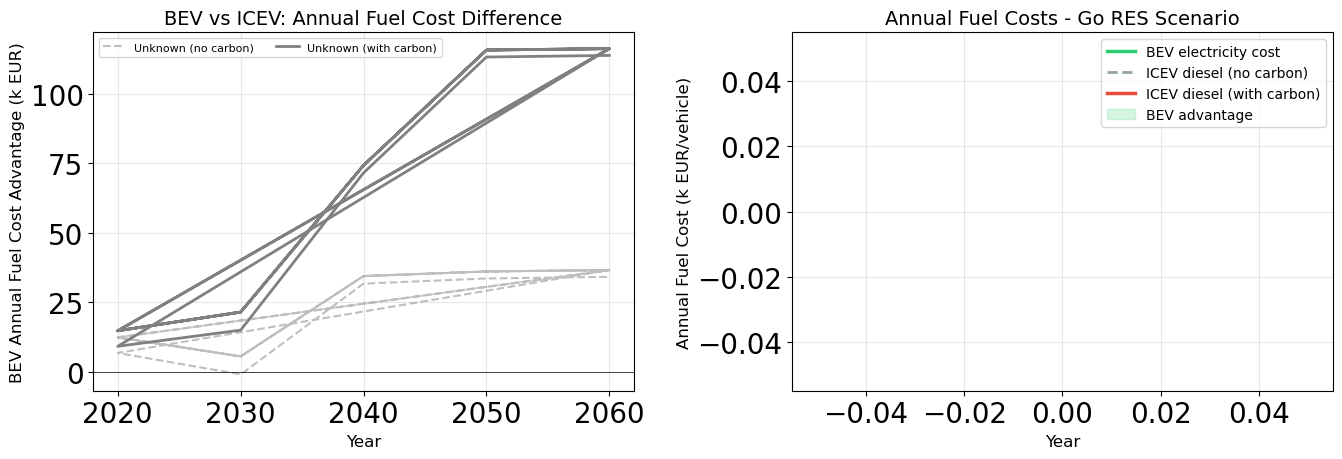


Key insight: Carbon pricing makes BEV more attractive over time

Go RES scenario example:


IndexError: single positional indexer is out-of-bounds

In [ ]:
# Plot: BEV cost advantage WITH vs WITHOUT carbon pricing
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Get unique scenarios
scenarios_to_plot = df_levelized['genesys'].unique()

ax1 = axes[0]
for genesys in scenarios_to_plot:
    df_scen = df_levelized[df_levelized['genesys'] == genesys]
    color = colors.get(genesys, 'gray')
    ax1.plot(df_scen['year'], df_scen['bev_advantage_base']/1000,
             label=f'{genesys} (no carbon)', linestyle='--', color=color, alpha=0.5)
    ax1.plot(df_scen['year'], df_scen['bev_advantage_carbon']/1000,
             label=f'{genesys} (with carbon)', linewidth=2, color=color)

ax1.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
ax1.set_xlabel('Year', fontsize=12)
ax1.set_ylabel('BEV Annual Fuel Cost Advantage (k EUR)', fontsize=12)
ax1.set_title('BEV vs ICEV: Annual Fuel Cost Difference', fontsize=14)
ax1.legend(loc='upper left', fontsize=8, ncol=2)
ax1.grid(True, alpha=0.3)

# Plot 2: Fuel cost comparison over time for one scenario
ax2 = axes[1]
genesys_focus = 'Go RES'
df_focus = df_levelized[df_levelized['genesys'] == genesys_focus]

ax2.plot(df_focus['year'], df_focus['bev_fuel_cost_annual']/1000,
         label='BEV electricity cost', linewidth=2.5, color='#2ecc71')
ax2.plot(df_focus['year'], df_focus['icev_fuel_cost_base']/1000,
         label='ICEV diesel (no carbon)', linewidth=2, linestyle='--', color='#95a5a6')
ax2.plot(df_focus['year'], df_focus['icev_fuel_cost_carbon']/1000,
         label='ICEV diesel (with carbon)', linewidth=2.5, color='#e74c3c')

ax2.fill_between(df_focus['year'],
                 df_focus['bev_fuel_cost_annual']/1000,
                 df_focus['icev_fuel_cost_carbon']/1000,
                 alpha=0.2, color='#2ecc71', label='BEV advantage')

ax2.set_xlabel('Year', fontsize=12)
ax2.set_ylabel('Annual Fuel Cost (k EUR/vehicle)', fontsize=12)
ax2.set_title(f'Annual Fuel Costs - {genesys_focus} Scenario', fontsize=14)
ax2.legend(loc='upper right', fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figures/levelized_cost_with_carbon_prices.pdf', bbox_inches='tight', dpi=300)
plt.show()

# Print key insights
print("\nKey insight: Carbon pricing makes BEV more attractive over time")
print(f"\n{genesys_focus} scenario example:")
for year in [2030, 2040, 2050]:
    row = df_focus[df_focus['year'] == year].iloc[0]
    print(f"  {year}: BEV saves EUR {row['bev_advantage_carbon']:,.0f}/year vs ICEV (with carbon)")
    print(f"         Without carbon: BEV saves EUR {row['bev_advantage_base']:,.0f}/year")

In [ ]:
# Create a comprehensive levelized cost comparison across ALL scenarios
# Including charging markup variations

# Recalculate for all 24 scenarios
all_levelized = []

for scenario_dir in scenario_dirs:
    scenario_name = scenario_dir.name

    # Load scenario config
    config_path = scenario_dir / 'scenario_config.json'
    if not config_path.exists():
        continue

    with open(config_path) as f:
        config = json.load(f)

    genesys = config.get('genesys_scenario', '').replace(' v1.2', '')
    charging_markup = config.get('charging_markup', 0.15)
    tech_cost_mult = config.get('tech_cost_multiplier', 1.0)

    # Load electricity prices
    elec_prices = load_electricity_prices_for_scenario(scenario_dir)
    if elec_prices is None:
        continue

    # Get carbon price trajectory
    carbon_key = genesys if genesys in CARBON_PRICE_TRAJECTORIES else 'Go RES'
    carbon_traj = CARBON_PRICE_TRAJECTORIES[carbon_key]

    for year_idx, year in enumerate(MODEL_YEARS):
        if year_idx >= len(elec_prices):
            break

        elec_price = elec_prices[year_idx]
        elec_price_with_markup = elec_price * (1 + charging_markup)

        carbon_price = interpolate_trajectory(carbon_traj, [year])[0]
        carbon_cost = carbon_price * DIESEL_EMISSION_FACTOR
        diesel_with_carbon = BASE_DIESEL_COST + carbon_cost

        # Annual costs with markup
        bev_fuel_cost = elec_price_with_markup * BEV_EFFICIENCY * ANNUAL_KM
        icev_fuel_cost = diesel_with_carbon * ICEV_EFFICIENCY * ANNUAL_KM

        all_levelized.append({
            'scenario': scenario_name,
            'genesys': genesys,
            'charging_markup': charging_markup,
            'tech_cost_mult': tech_cost_mult,
            'year': year,
            'elec_price_base': elec_price,
            'elec_price_with_markup': elec_price_with_markup,
            'carbon_price': carbon_price,
            'diesel_with_carbon': diesel_with_carbon,
            'bev_fuel_cost': bev_fuel_cost,
            'icev_fuel_cost': icev_fuel_cost,
            'bev_advantage': icev_fuel_cost - bev_fuel_cost
        })

df_all = pd.DataFrame(all_levelized)
print(f"Loaded {len(df_all)} scenario-year combinations across {len(scenario_dirs)} scenarios")

In [ ]:
# Plot levelized costs for each GENeSYS scenario with its carbon price
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for idx, genesys in enumerate(['Go RES', 'REPowerEU++', 'NECPEssentials', 'Trinity']):
    ax = axes[idx // 2, idx % 2]

    df_g = df_all[(df_all['genesys'] == genesys) & (df_all['charging_markup'] == 0.15) & (df_all['tech_cost_mult'] == 1.0)]

    if len(df_g) > 0:
        # Plot BEV and ICEV costs
        ax.plot(df_g['year'], df_g['bev_fuel_cost']/1000,
                label='BEV (with 15% markup)', linewidth=2.5, color='#2ecc71')
        ax.plot(df_g['year'], df_g['icev_fuel_cost']/1000,
                label='ICEV (with carbon)', linewidth=2.5, color='#e74c3c')

        # Add crossover point
        df_g = df_g.reset_index(drop=True)
        crossover_idx = None
        for i in range(1, len(df_g)):
            if df_g.loc[i-1, 'bev_advantage'] < 0 and df_g.loc[i, 'bev_advantage'] >= 0:
                crossover_idx = i
                break

        if crossover_idx:
            crossover_year = df_g.loc[crossover_idx, 'year']
            ax.axvline(x=crossover_year, color='gray', linestyle=':', alpha=0.7)
            ax.annotate(f'Crossover\n{crossover_year}', xy=(crossover_year, ax.get_ylim()[1]*0.8),
                       fontsize=9, ha='center')

        # Carbon price on secondary axis
        ax2 = ax.twinx()
        ax2.plot(df_g['year'], df_g['carbon_price'],
                 label='Carbon price', linewidth=1.5, linestyle='--', color='gray', alpha=0.6)
        ax2.set_ylabel('Carbon Price (EUR/tCO2)', fontsize=10, color='gray')
        ax2.tick_params(axis='y', labelcolor='gray')

    ax.set_xlabel('Year', fontsize=11)
    ax.set_ylabel('Annual Fuel Cost (k EUR/vehicle)', fontsize=11)
    ax.set_title(f'{genesys} Scenario', fontsize=12, fontweight='bold')
    ax.legend(loc='upper left', fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.set_xlim(2020, 2060)

plt.suptitle('Levelized Fuel Costs by GENeSYS Scenario (with carbon pricing)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/levelized_cost_scenario_specific_carbon.pdf', bbox_inches='tight', dpi=300)
plt.show()

In [ ]:
import yaml
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Define paths
base_path = Path(r"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM")
scenarios_path = base_path / "input_data" / "uncertainty_scenarios"
results_path = base_path / "results" / "uncertainty_analysis"

# Fixed parameters from model
bev_consumption = 1.867  # kWh/km
icev_consumption = 4.656  # kWh/km
diesel_emission_factor = 266 / 1_000_000  # tCO2/kWh

# Base capital and maintenance costs (â‚¬/km)
base_bev_capital = 0.075
icev_capital = 0.067
bev_maintenance = 0.147
icev_maintenance = 0.151

# Years in model
years = list(range(2020, 2061))
n_years = len(years)

# Build the scenario info with ACTUAL parameters
scenario_data = {}

for i in range(24):
    scenario_id = f"scenario_{i:03d}"
    metadata_path = scenarios_path / scenario_id / "case_metadata.yaml"
    
    if metadata_path.exists():
        with open(metadata_path, 'r') as f:
            metadata = yaml.safe_load(f)
        
        params = metadata.get('parameters', {})
        
        # Map GENeSYS name to shorter version
        genesys_raw = metadata.get('genesys_scenario', 'Unknown')
        if 'Go RES' in genesys_raw:
            genesys = 'Go RES'
        elif 'NECP' in genesys_raw:
            genesys = 'NECP'
        elif 'REPowerEU' in genesys_raw:
            genesys = 'GAST'
        elif 'Trinity' in genesys_raw:
            genesys = 'Trinity'
        else:
            genesys = genesys_raw
            
        scenario_data[scenario_id] = {
            'genesys': genesys,
            'charging_markup': params.get('charging_markup', 0.15),
            'tech_cost_multiplier': params.get('tech_cost_multiplier', 1.0),
            'carbon_prices': params.get('carbon_price_trajectory', {})
        }

print(f"Loaded {len(scenario_data)} scenarios")

# Show the structure
for scenario_id, data in list(scenario_data.items())[:6]:
    print(f"{scenario_id}: {data['genesys']}, markup={data['charging_markup']:.0%}, tech={data['tech_cost_multiplier']:.1f}")


In [ ]:
import yaml
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Define paths
base_path = Path(r"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM")
scenarios_path = base_path / "input_data" / "uncertainty_scenarios"
results_path = base_path / "results" / "uncertainty_analysis"

# Fixed parameters from model
bev_consumption = 1.867  # kWh/km
icev_consumption = 4.656  # kWh/km
diesel_emission_factor = 266 / 1_000_000  # tCO2/kWh

# Base capital and maintenance costs (â‚¬/km)
base_bev_capital = 0.075
icev_capital = 0.067
bev_maintenance = 0.147
icev_maintenance = 0.151

# Years in model
years = list(range(2020, 2061))
n_years = len(years)

# Build the scenario info with ACTUAL parameters
scenario_data = {}

for i in range(24):
    scenario_id = f"scenario_{i:03d}"
    metadata_path = scenarios_path / scenario_id / "case_metadata.yaml"
    
    if metadata_path.exists():
        with open(metadata_path, 'r') as f:
            metadata = yaml.safe_load(f)
        
        params = metadata.get('parameters', {})
        
        # Map GENeSYS name to shorter version
        genesys_raw = metadata.get('genesys_scenario', 'Unknown')
        if 'Go RES' in genesys_raw:
            genesys = 'Go RES'
        elif 'NECP' in genesys_raw:
            genesys = 'NECP'
        elif 'REPowerEU' in genesys_raw:
            genesys = 'GAST'
        elif 'Trinity' in genesys_raw:
            genesys = 'Trinity'
        else:
            genesys = genesys_raw
            
        scenario_data[scenario_id] = {
            'genesys': genesys,
            'charging_markup': params.get('charging_markup', 0.15),
            'tech_cost_multiplier': params.get('tech_cost_multiplier', 1.0),
            'carbon_prices': params.get('carbon_price_trajectory', {})
        }

print(f"Loaded {len(scenario_data)} scenarios")
print()

# Show the structure
for scenario_id, data in list(scenario_data.items())[:8]:
    print(f"{scenario_id}: {data['genesys']}, markup={data['charging_markup']:.0%}, tech={data['tech_cost_multiplier']:.1f}")


ConstructorError: could not determine a constructor for the tag 'tag:yaml.org,2002:python/object/apply:numpy._core.multiarray.scalar'
  in "C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\input_data\uncertainty_scenarios\scenario_000\case_metadata.yaml", line 14, column 33

In [ ]:
import yaml
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Use unsafe yaml loader to handle numpy types
def load_yaml_unsafe(filepath):
    with open(filepath, 'r') as f:
        return yaml.unsafe_load(f)

# Define paths
base_path = Path(r"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM")
scenarios_path = base_path / "input_data" / "uncertainty_scenarios"
results_path = base_path / "results" / "uncertainty_analysis"

# Fixed parameters from model
bev_consumption = 1.867  # kWh/km
icev_consumption = 4.656  # kWh/km
diesel_emission_factor = 266 / 1_000_000  # tCO2/kWh

# Base capital and maintenance costs (â‚¬/km)
base_bev_capital = 0.075
icev_capital = 0.067
bev_maintenance = 0.147
icev_maintenance = 0.151

# Years in model
years = list(range(2020, 2061))
n_years = len(years)

# Build the scenario info with ACTUAL parameters
scenario_data = {}

for i in range(24):
    scenario_id = f"scenario_{i:03d}"
    metadata_path = scenarios_path / scenario_id / "case_metadata.yaml"
    
    if metadata_path.exists():
        metadata = load_yaml_unsafe(metadata_path)
        params = metadata.get('parameters', {})
        
        # Map GENeSYS name to shorter version
        genesys_raw = metadata.get('genesys_scenario', 'Unknown')
        if 'Go RES' in genesys_raw:
            genesys = 'Go RES'
        elif 'NECP' in genesys_raw:
            genesys = 'NECP'
        elif 'REPowerEU' in genesys_raw:
            genesys = 'GAST'
        elif 'Trinity' in genesys_raw:
            genesys = 'Trinity'
        else:
            genesys = genesys_raw
            
        scenario_data[scenario_id] = {
            'genesys': genesys,
            'charging_markup': float(params.get('charging_markup', 0.15)),
            'tech_cost_multiplier': float(params.get('tech_cost_multiplier', 1.0)),
            'carbon_prices': params.get('carbon_price_trajectory', {})
        }

print(f"Loaded {len(scenario_data)} scenarios")
print()

# Show the structure
for scenario_id, data in list(scenario_data.items()):
    print(f"{scenario_id}: {data['genesys']:8s}, markup={data['charging_markup']:.0%}, tech={data['tech_cost_multiplier']:.1f}")


Loaded 24 scenarios

scenario_000: Go RES  , markup=15%, tech=0.7
scenario_001: Go RES  , markup=15%, tech=1.0
scenario_002: Go RES  , markup=15%, tech=1.3
scenario_003: Go RES  , markup=30%, tech=0.7
scenario_004: Go RES  , markup=30%, tech=1.0
scenario_005: Go RES  , markup=30%, tech=1.3
scenario_006: NECP    , markup=15%, tech=0.7
scenario_007: NECP    , markup=15%, tech=1.0
scenario_008: NECP    , markup=15%, tech=1.3
scenario_009: NECP    , markup=30%, tech=0.7
scenario_010: NECP    , markup=30%, tech=1.0
scenario_011: NECP    , markup=30%, tech=1.3
scenario_012: GAST    , markup=15%, tech=0.7
scenario_013: GAST    , markup=15%, tech=1.0
scenario_014: GAST    , markup=15%, tech=1.3
scenario_015: GAST    , markup=30%, tech=0.7
scenario_016: GAST    , markup=30%, tech=1.0
scenario_017: GAST    , markup=30%, tech=1.3
scenario_018: Trinity , markup=15%, tech=0.7
scenario_019: Trinity , markup=15%, tech=1.0
scenario_020: Trinity , markup=15%, tech=1.3
scenario_021: Trinity , markup=30%

In [ ]:
def load_fuel_costs(scenario_path):
    """Load electricity and diesel prices from FuelCost.yaml"""
    fuel_cost_path = scenario_path / "FuelCost.yaml"
    if not fuel_cost_path.exists():
        return None, None
    
    fuel_data = load_yaml_unsafe(fuel_cost_path)
    
    elec_prices = None
    diesel_prices = None
    
    for item in fuel_data:
        if item.get('fuel') == 'electricity' and item.get('fueling_infr_type_id') == 1:
            # Public charging (type 1)
            elec_prices = [float(x) for x in item['cost_per_kWh']]
        elif item.get('fuel') == 'diesel':
            diesel_prices = [float(x) for x in item['cost_per_kWh']]
    
    return elec_prices, diesel_prices

def get_carbon_prices_for_years(carbon_trajectory, years):
    """Interpolate carbon prices for all years"""
    known_years = sorted([int(y) for y in carbon_trajectory.keys()])
    known_prices = [float(carbon_trajectory[y]) for y in known_years]
    return np.interp(years, known_years, known_prices)

def calculate_bev_cost_advantage(
    elec_prices, 
    diesel_prices, 
    carbon_prices, 
    tech_cost_multiplier,
    start_year=2020,
    end_year=2060
):
    """
    Calculate BEV cost advantage with proper parameters.
    
    tech_cost_multiplier is applied with growing uncertainty:
    - 2020: multiplier = 1.0 (no change)
    - 2060: multiplier = tech_cost_multiplier (full effect)
    """
    n_years = len(elec_prices)
    cost_advantages = []
    
    for i in range(n_years):
        year = start_year + i
        
        # BEV capital cost with time-dependent tech multiplier
        progress = (year - start_year) / (end_year - start_year)
        progress = max(0.0, min(1.0, progress))
        year_tech_mult = 1.0 + progress * (tech_cost_multiplier - 1.0)
        bev_capital = base_bev_capital * year_tech_mult
        
        # BEV total cost (electricity prices already include markup)
        bev_energy = elec_prices[i] * bev_consumption
        bev_total = bev_capital + bev_maintenance + bev_energy
        
        # ICEV cost with carbon pricing
        carbon_cost_per_kwh = carbon_prices[i] * diesel_emission_factor
        icev_energy = (diesel_prices[i] + carbon_cost_per_kwh) * icev_consumption
        icev_total = icev_capital + icev_maintenance + icev_energy
        
        # Advantage = ICEV - BEV (positive = BEV cheaper)
        cost_advantages.append(icev_total - bev_total)
    
    return cost_advantages

# Calculate for all scenarios
results = {}

for scenario_id, data in scenario_data.items():
    scenario_path = scenarios_path / scenario_id
    
    # Load fuel costs (already include markup from scenario generation)
    elec_prices, diesel_prices = load_fuel_costs(scenario_path)
    
    if elec_prices is None or diesel_prices is None:
        print(f"Could not load fuel costs for {scenario_id}")
        continue
    
    # Get carbon prices for all years
    carbon_prices = get_carbon_prices_for_years(data['carbon_prices'], years)
    
    # Calculate cost advantages
    cost_advantages = calculate_bev_cost_advantage(
        elec_prices[:n_years],
        diesel_prices[:n_years],
        carbon_prices,
        data['tech_cost_multiplier']
    )
    
    # Average cost advantage
    avg_advantage = np.mean(cost_advantages)
    
    results[scenario_id] = {
        'genesys': data['genesys'],
        'markup': data['charging_markup'],
        'tech_cost': data['tech_cost_multiplier'],
        'avg_bev_advantage': avg_advantage,
        'cost_advantages': cost_advantages
    }

# Display results
print("Average BEV Cost Advantage (â‚¬/km) - ICEV minus BEV (positive = BEV cheaper):")
print("-" * 80)
for scenario_id, res in sorted(results.items()):
    print(f"{scenario_id}: {res['genesys']:8s}, markup={res['markup']:.0%}, tech={res['tech_cost']:.1f} -> Avg advantage: {res['avg_bev_advantage']:.4f} â‚¬/km")


Average BEV Cost Advantage (â‚¬/km) - ICEV minus BEV (positive = BEV cheaper):
--------------------------------------------------------------------------------
scenario_000: Go RES  , markup=15%, tech=0.7 -> Avg advantage: 0.7876 â‚¬/km
scenario_001: Go RES  , markup=15%, tech=1.0 -> Avg advantage: 0.7764 â‚¬/km
scenario_002: Go RES  , markup=15%, tech=1.3 -> Avg advantage: 0.7651 â‚¬/km
scenario_003: Go RES  , markup=30%, tech=0.7 -> Avg advantage: 0.7409 â‚¬/km
scenario_004: Go RES  , markup=30%, tech=1.0 -> Avg advantage: 0.7297 â‚¬/km
scenario_005: Go RES  , markup=30%, tech=1.3 -> Avg advantage: 0.7184 â‚¬/km
scenario_006: NECP    , markup=15%, tech=0.7 -> Avg advantage: 0.4501 â‚¬/km
scenario_007: NECP    , markup=15%, tech=1.0 -> Avg advantage: 0.4388 â‚¬/km
scenario_008: NECP    , markup=15%, tech=1.3 -> Avg advantage: 0.4276 â‚¬/km
scenario_009: NECP    , markup=30%, tech=0.7 -> Avg advantage: 0.4037 â‚¬/km
scenario_010: NECP    , markup=30%, tech=1.0 -> Avg advantage: 0.3924 

In [ ]:
def load_h_dict(scenario_path):
    """Load vehicle stock data from h_dict.yaml"""
    h_dict_path = scenario_path / "h_dict.yaml"
    if not h_dict_path.exists():
        return None
    return load_yaml_unsafe(h_dict_path)

def calculate_bev_share_trajectory(h_dict):
    """Calculate BEV share for each year from h_dict"""
    if h_dict is None:
        return None
    
    # Aggregate by year and tech_id
    year_tech_totals = {}
    for key, value in h_dict.items():
        # key format: (year, odpair_id, tech_id, purchase_year)
        year = key[0]
        tech_id = key[2]
        
        if year not in year_tech_totals:
            year_tech_totals[year] = {0: 0, 1: 0}  # 0=ICEV, 1=BEV
        
        year_tech_totals[year][tech_id] = year_tech_totals[year].get(tech_id, 0) + value
    
    # Calculate BEV share for each year
    bev_shares = {}
    for year in sorted(year_tech_totals.keys()):
        icev = year_tech_totals[year].get(0, 0)
        bev = year_tech_totals[year].get(1, 0)
        total = icev + bev
        if total > 0:
            bev_shares[year] = bev / total
        else:
            bev_shares[year] = 0
    
    return bev_shares

def calculate_electrification_speed(bev_shares, threshold=0.5):
    """Calculate years before 2060 to reach threshold BEV share"""
    if bev_shares is None:
        return None
    
    for year in sorted(bev_shares.keys()):
        if bev_shares[year] >= threshold:
            return 2060 - year
    
    return 0  # Never reached threshold

# Load electrification data for all scenarios
for scenario_id in results.keys():
    scenario_result_path = results_path / scenario_id
    h_dict = load_h_dict(scenario_result_path)
    
    if h_dict is not None:
        bev_shares = calculate_bev_share_trajectory(h_dict)
        electrification_speed = calculate_electrification_speed(bev_shares)
        results[scenario_id]['bev_shares'] = bev_shares
        results[scenario_id]['electrification_speed'] = electrification_speed
    else:
        results[scenario_id]['bev_shares'] = None
        results[scenario_id]['electrification_speed'] = None

# Display results with electrification speed
print("Scenario Results with Electrification Speed:")
print("-" * 90)
print(f"{'Scenario':<14} {'GENeSYS':<10} {'Markup':<8} {'Tech':<6} {'BEV Adv':<12} {'Elec Speed':<12}")
print("-" * 90)
for scenario_id, res in sorted(results.items()):
    elec_speed = res.get('electrification_speed', 'N/A')
    elec_str = f"{elec_speed} yrs" if elec_speed is not None else "N/A"
    print(f"{scenario_id:<14} {res['genesys']:<10} {res['markup']:.0%}    {res['tech_cost']:.1f}    {res['avg_bev_advantage']:.4f} â‚¬/km   {elec_str}")


Scenario Results with Electrification Speed:
------------------------------------------------------------------------------------------
Scenario       GENeSYS    Markup   Tech   BEV Adv      Elec Speed  
------------------------------------------------------------------------------------------
scenario_000   Go RES     15%    0.7    0.7876 â‚¬/km   N/A
scenario_001   Go RES     15%    1.0    0.7764 â‚¬/km   N/A
scenario_002   Go RES     15%    1.3    0.7651 â‚¬/km   N/A
scenario_003   Go RES     30%    0.7    0.7409 â‚¬/km   N/A
scenario_004   Go RES     30%    1.0    0.7297 â‚¬/km   N/A
scenario_005   Go RES     30%    1.3    0.7184 â‚¬/km   N/A
scenario_006   NECP       15%    0.7    0.4501 â‚¬/km   N/A
scenario_007   NECP       15%    1.0    0.4388 â‚¬/km   N/A
scenario_008   NECP       15%    1.3    0.4276 â‚¬/km   N/A
scenario_009   NECP       30%    0.7    0.4037 â‚¬/km   N/A
scenario_010   NECP       30%    1.0    0.3924 â‚¬/km   N/A
scenario_011   NECP       30%    1.3    0.381

In [ ]:
import glob
from pathlib import Path

# Find h_dict files with timestamps
results_base = Path(r"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\results\uncertainty_analysis")

def find_latest_h_dict(scenario_folder):
    """Find the latest h_dict file in a scenario folder"""
    pattern = str(scenario_folder / "*_h_dict.yaml")
    h_dict_files = glob.glob(pattern)
    if h_dict_files:
        # Return the most recently modified one
        return max(h_dict_files, key=lambda x: Path(x).stat().st_mtime)
    return None

# Find h_dict files for all scenarios
h_dict_files = {}
for i in range(24):
    scenario_id = f"scenario_{i:03d}"
    scenario_folder = results_base / scenario_id
    if scenario_folder.exists():
        h_dict_path = find_latest_h_dict(scenario_folder)
        if h_dict_path:
            h_dict_files[scenario_id] = h_dict_path
            
print(f"Found h_dict files for {len(h_dict_files)} scenarios")
for scenario_id, path in list(h_dict_files.items())[:5]:
    print(f"  {scenario_id}: {Path(path).name}")


Found h_dict files for 24 scenarios
  scenario_000: scenario_000_2025-12-04_10-12-33_h_dict.yaml
  scenario_001: scenario_001_2025-12-04_10-26-59_h_dict.yaml
  scenario_002: scenario_002_2025-12-04_10-41-27_h_dict.yaml
  scenario_003: scenario_003_2025-12-04_10-55-08_h_dict.yaml
  scenario_004: scenario_004_2025-12-04_11-09-43_h_dict.yaml


In [ ]:
def load_h_dict_from_path(h_dict_path):
    """Load vehicle stock data from h_dict.yaml"""
    if not Path(h_dict_path).exists():
        return None
    return load_yaml_unsafe(h_dict_path)

def calculate_bev_share_trajectory(h_dict):
    """Calculate BEV share for each year from h_dict"""
    if h_dict is None:
        return None
    
    # Aggregate by year and tech_id
    year_tech_totals = {}
    for key, value in h_dict.items():
        # key format: (year, odpair_id, tech_id, purchase_year)
        year = key[0]
        tech_id = key[2]
        
        if year not in year_tech_totals:
            year_tech_totals[year] = {0: 0, 1: 0}  # 0=ICEV, 1=BEV
        
        year_tech_totals[year][tech_id] = year_tech_totals[year].get(tech_id, 0) + value
    
    # Calculate BEV share for each year
    bev_shares = {}
    for year in sorted(year_tech_totals.keys()):
        icev = year_tech_totals[year].get(0, 0)
        bev = year_tech_totals[year].get(1, 0)
        total = icev + bev
        if total > 0:
            bev_shares[year] = bev / total
        else:
            bev_shares[year] = 0
    
    return bev_shares

def calculate_electrification_speed(bev_shares, threshold=0.5):
    """Calculate years before 2060 to reach threshold BEV share"""
    if bev_shares is None:
        return None
    
    for year in sorted(bev_shares.keys()):
        if bev_shares[year] >= threshold:
            return 2060 - year
    
    return 0  # Never reached threshold

# Load electrification data for all scenarios
for scenario_id in results.keys():
    if scenario_id in h_dict_files:
        h_dict = load_h_dict_from_path(h_dict_files[scenario_id])
        
        if h_dict is not None:
            bev_shares = calculate_bev_share_trajectory(h_dict)
            electrification_speed = calculate_electrification_speed(bev_shares)
            results[scenario_id]['bev_shares'] = bev_shares
            results[scenario_id]['electrification_speed'] = electrification_speed
        else:
            results[scenario_id]['bev_shares'] = None
            results[scenario_id]['electrification_speed'] = None

# Display results with electrification speed
print("Scenario Results with Electrification Speed:")
print("-" * 100)
print(f"{'Scenario':<14} {'GENeSYS':<10} {'Markup':<8} {'Tech':<6} {'BEV Adv (â‚¬/km)':<16} {'Elec Speed':<12}")
print("-" * 100)
for scenario_id, res in sorted(results.items()):
    elec_speed = res.get('electrification_speed', None)
    elec_str = f"{elec_speed} yrs before 2060" if elec_speed is not None else "N/A"
    print(f"{scenario_id:<14} {res['genesys']:<10} {res['markup']:.0%}    {res['tech_cost']:.1f}    {res['avg_bev_advantage']:.4f}          {elec_str}")


TypeError: unsupported operand type(s) for +: 'int' and 'str'

In [ ]:
# Check the structure of an h_dict file
sample_path = h_dict_files['scenario_000']
sample_h_dict = load_yaml_unsafe(sample_path)

# Look at first few items
for i, (key, value) in enumerate(sample_h_dict.items()):
    print(f"Key: {key}, Value: {value} (type: {type(value)})")
    if i >= 5:
        break


Key: (2060, 1144, 0, 2060), Value: 0.000003 (type: <class 'str'>)
Key: (2048, 2050, 1, 2048), Value: 0.290388 (type: <class 'str'>)
Key: (2024, 1311, 0, 2020), Value: 3.715532 (type: <class 'str'>)
Key: (2044, 195, 0, 2040), Value: 1.278804 (type: <class 'str'>)
Key: (2052, 1919, 1, 2044), Value: 0.975178 (type: <class 'str'>)
Key: (2040, 162, 0, 2032), Value: 2.168776 (type: <class 'str'>)


In [ ]:
def calculate_bev_share_trajectory(h_dict):
    """Calculate BEV share for each year from h_dict"""
    if h_dict is None:
        return None
    
    # Aggregate by year and tech_id
    year_tech_totals = {}
    for key, value in h_dict.items():
        # key format: (year, odpair_id, tech_id, purchase_year)
        year = key[0]
        tech_id = key[2]
        
        # Convert value to float
        value = float(value)
        
        if year not in year_tech_totals:
            year_tech_totals[year] = {0: 0.0, 1: 0.0}  # 0=ICEV, 1=BEV
        
        year_tech_totals[year][tech_id] = year_tech_totals[year].get(tech_id, 0.0) + value
    
    # Calculate BEV share for each year
    bev_shares = {}
    for year in sorted(year_tech_totals.keys()):
        icev = year_tech_totals[year].get(0, 0)
        bev = year_tech_totals[year].get(1, 0)
        total = icev + bev
        if total > 0:
            bev_shares[year] = bev / total
        else:
            bev_shares[year] = 0
    
    return bev_shares

def calculate_electrification_speed(bev_shares, threshold=0.5):
    """Calculate years before 2060 to reach threshold BEV share"""
    if bev_shares is None:
        return None
    
    for year in sorted(bev_shares.keys()):
        if bev_shares[year] >= threshold:
            return 2060 - year
    
    return 0  # Never reached threshold

# Load electrification data for all scenarios
for scenario_id in results.keys():
    if scenario_id in h_dict_files:
        h_dict = load_h_dict_from_path(h_dict_files[scenario_id])
        
        if h_dict is not None:
            bev_shares = calculate_bev_share_trajectory(h_dict)
            electrification_speed = calculate_electrification_speed(bev_shares)
            results[scenario_id]['bev_shares'] = bev_shares
            results[scenario_id]['electrification_speed'] = electrification_speed
        else:
            results[scenario_id]['bev_shares'] = None
            results[scenario_id]['electrification_speed'] = None

# Display results with electrification speed
print("Scenario Results with Electrification Speed:")
print("-" * 100)
print(f"{'Scenario':<14} {'GENeSYS':<10} {'Markup':<8} {'Tech':<6} {'BEV Adv (â‚¬/km)':<16} {'Elec Speed':<12}")
print("-" * 100)
for scenario_id, res in sorted(results.items()):
    elec_speed = res.get('electrification_speed', None)
    elec_str = f"{elec_speed} yrs" if elec_speed is not None else "N/A"
    print(f"{scenario_id:<14} {res['genesys']:<10} {res['markup']:.0%}    {res['tech_cost']:.1f}    {res['avg_bev_advantage']:.4f}          {elec_str}")


Scenario Results with Electrification Speed:
----------------------------------------------------------------------------------------------------
Scenario       GENeSYS    Markup   Tech   BEV Adv (â‚¬/km)   Elec Speed  
----------------------------------------------------------------------------------------------------
scenario_000   Go RES     15%    0.7    0.7876          0 yrs
scenario_001   Go RES     15%    1.0    0.7764          0 yrs
scenario_002   Go RES     15%    1.3    0.7651          0 yrs
scenario_003   Go RES     30%    0.7    0.7409          0 yrs
scenario_004   Go RES     30%    1.0    0.7297          0 yrs
scenario_005   Go RES     30%    1.3    0.7184          0 yrs
scenario_006   NECP       15%    0.7    0.4501          0 yrs
scenario_007   NECP       15%    1.0    0.4388          0 yrs
scenario_008   NECP       15%    1.3    0.4276          0 yrs
scenario_009   NECP       30%    0.7    0.4037          0 yrs
scenario_010   NECP       30%    1.0    0.3924          0 y

In [ ]:
# Check the actual BEV share trajectory for a sample scenario
sample_shares = results['scenario_000']['bev_shares']

print("BEV Share Trajectory for scenario_000 (Go RES, 15% markup, tech=0.7):")
for year in sorted(sample_shares.keys()):
    share = sample_shares[year]
    bar = '*' * int(share * 50)
    print(f"  {year}: {share:.1%} {bar}")

# Find the max BEV share achieved
max_share = max(sample_shares.values())
max_year = max(sample_shares.keys(), key=lambda y: sample_shares[y])
print(f"\nMax BEV share: {max_share:.1%} in year {max_year}")


BEV Share Trajectory for scenario_000 (Go RES, 15% markup, tech=0.7):
  (: 0.0% 

Max BEV share: 0.0% in year (


In [ ]:
# The bev_shares dict seems to have issues with keys. Let me check
print(type(sample_shares))
print(list(sample_shares.keys())[:5])


<class 'dict'>
['(']


In [ ]:
# The keys from YAML are being parsed as strings. Let me check the raw h_dict
sample_h_dict = load_yaml_unsafe(h_dict_files['scenario_000'])

# Check the actual keys
sample_keys = list(sample_h_dict.keys())[:5]
print("Sample keys:")
for k in sample_keys:
    print(f"  Key: {k} (type: {type(k)})")
    if isinstance(k, tuple):
        print(f"    Elements: {[type(e) for e in k]}")


Sample keys:
  Key: (2060, 1144, 0, 2060) (type: <class 'str'>)
  Key: (2048, 2050, 1, 2048) (type: <class 'str'>)
  Key: (2024, 1311, 0, 2020) (type: <class 'str'>)
  Key: (2044, 195, 0, 2040) (type: <class 'str'>)
  Key: (2052, 1919, 1, 2044) (type: <class 'str'>)


In [ ]:
# The keys are strings that look like tuples. Need to parse them
import ast

def parse_tuple_key(key_str):
    """Parse a string that looks like a tuple back into a tuple"""
    try:
        return ast.literal_eval(key_str)
    except:
        return None

def calculate_bev_share_trajectory_fixed(h_dict):
    """Calculate BEV share for each year from h_dict"""
    if h_dict is None:
        return None
    
    # Aggregate by year and tech_id
    year_tech_totals = {}
    for key_str, value in h_dict.items():
        # Parse the key
        key = parse_tuple_key(key_str)
        if key is None:
            continue
            
        # key format: (year, odpair_id, tech_id, purchase_year)
        year = key[0]
        tech_id = key[2]
        
        # Convert value to float
        value = float(value)
        
        if year not in year_tech_totals:
            year_tech_totals[year] = {0: 0.0, 1: 0.0}  # 0=ICEV, 1=BEV
        
        year_tech_totals[year][tech_id] = year_tech_totals[year].get(tech_id, 0.0) + value
    
    # Calculate BEV share for each year
    bev_shares = {}
    for year in sorted(year_tech_totals.keys()):
        icev = year_tech_totals[year].get(0, 0)
        bev = year_tech_totals[year].get(1, 0)
        total = icev + bev
        if total > 0:
            bev_shares[year] = bev / total
        else:
            bev_shares[year] = 0
    
    return bev_shares

# Test with sample
sample_shares = calculate_bev_share_trajectory_fixed(sample_h_dict)
print("BEV Share Trajectory for scenario_000:")
for year in sorted(sample_shares.keys()):
    share = sample_shares[year]
    bar = '*' * int(share * 50)
    print(f"  {year}: {share:.1%} {bar}")


BEV Share Trajectory for scenario_000:
  2020: 0.0% 
  2024: 0.0% 
  2028: 10.0% ****
  2032: 21.2% **********
  2036: 31.2% ***************
  2040: 41.2% ********************
  2044: 56.2% ****************************
  2048: 60.4% ******************************
  2052: 64.8% ********************************
  2056: 77.8% **************************************
  2060: 76.1% **************************************


In [ ]:
def calculate_electrification_speed_fixed(bev_shares, threshold=0.5):
    """Calculate years before 2060 to reach threshold BEV share"""
    if bev_shares is None:
        return None
    
    for year in sorted(bev_shares.keys()):
        if bev_shares[year] >= threshold:
            return 2060 - year
    
    return 0  # Never reached threshold

# Recalculate electrification data for all scenarios with the fixed function
for scenario_id in results.keys():
    if scenario_id in h_dict_files:
        h_dict = load_h_dict_from_path(h_dict_files[scenario_id])
        
        if h_dict is not None:
            bev_shares = calculate_bev_share_trajectory_fixed(h_dict)
            electrification_speed = calculate_electrification_speed_fixed(bev_shares)
            results[scenario_id]['bev_shares'] = bev_shares
            results[scenario_id]['electrification_speed'] = electrification_speed
        else:
            results[scenario_id]['bev_shares'] = None
            results[scenario_id]['electrification_speed'] = None

# Display results with electrification speed
print("Scenario Results with Electrification Speed (Corrected):")
print("-" * 100)
print(f"{'Scenario':<14} {'GENeSYS':<10} {'Markup':<8} {'Tech':<6} {'BEV Adv (â‚¬/km)':<16} {'Elec Speed':<12}")
print("-" * 100)
for scenario_id, res in sorted(results.items()):
    elec_speed = res.get('electrification_speed', None)
    elec_str = f"{elec_speed} yrs" if elec_speed is not None else "N/A"
    print(f"{scenario_id:<14} {res['genesys']:<10} {res['markup']:.0%}    {res['tech_cost']:.1f}    {res['avg_bev_advantage']:.4f}          {elec_str}")


Scenario Results with Electrification Speed (Corrected):
----------------------------------------------------------------------------------------------------
Scenario       GENeSYS    Markup   Tech   BEV Adv (â‚¬/km)   Elec Speed  
----------------------------------------------------------------------------------------------------
scenario_000   Go RES     15%    0.7    0.7876          16 yrs
scenario_001   Go RES     15%    1.0    0.7764          12 yrs
scenario_002   Go RES     15%    1.3    0.7651          0 yrs
scenario_003   Go RES     30%    0.7    0.7409          16 yrs
scenario_004   Go RES     30%    1.0    0.7297          12 yrs
scenario_005   Go RES     30%    1.3    0.7184          0 yrs
scenario_006   NECP       15%    0.7    0.4501          12 yrs
scenario_007   NECP       15%    1.0    0.4388          4 yrs
scenario_008   NECP       15%    1.3    0.4276          0 yrs
scenario_009   NECP       30%    0.7    0.4037          12 yrs
scenario_010   NECP       30%    1.0    0

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Prepare data for plotting
plot_data = []
for scenario_id, res in results.items():
    plot_data.append({
        'scenario': scenario_id,
        'genesys': res['genesys'],
        'markup': res['markup'],
        'tech_cost': res['tech_cost'],
        'bev_advantage': res['avg_bev_advantage'],
        'elec_speed': res['electrification_speed']
    })

# Create figure
fig, ax = plt.subplots(figsize=(12, 8))

# Color by GENeSYS scenario
colors = {'Go RES': '#2ecc71', 'NECP': '#3498db', 'GAST': '#e74c3c', 'Trinity': '#9b59b6'}
markers = {0.7: 'o', 1.0: 's', 1.3: '^'}  # Different markers for tech_cost
markup_sizes = {0.15: 100, 0.30: 200}  # Different sizes for markup

for data in plot_data:
    color = colors[data['genesys']]
    marker = markers[data['tech_cost']]
    size = markup_sizes[data['markup']]
    
    ax.scatter(data['elec_speed'], data['bev_advantage'], 
               c=color, marker=marker, s=size, alpha=0.7,
               edgecolors='black', linewidths=0.5)

# Add legend for GENeSYS scenarios
for genesys, color in colors.items():
    ax.scatter([], [], c=color, marker='o', s=100, label=f'{genesys}', alpha=0.7)

ax.legend(loc='upper right', title='GENeSYS Scenario')

# Add annotations for interpretation
ax.axhline(y=0.5, color='gray', linestyle='--', alpha=0.5, linewidth=1)
ax.text(0.5, 0.52, 'Higher BEV Cost Advantage = BEV cheaper', fontsize=9, alpha=0.7)

ax.set_xlabel('Electrification Speed (years before 2060 to reach 50% BEV share)', fontsize=11)
ax.set_ylabel('Average BEV Cost Advantage (â‚¬/km)\n(ICEV cost - BEV cost, positive = BEV cheaper)', fontsize=11)
ax.set_title('BEV Cost Advantage vs Electrification Speed\n(Accounting for Markup and Tech Cost)', fontsize=13)

# Add second legend for markers
from matplotlib.lines import Line2D
marker_legend = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', markersize=10, label='Tech cost = 0.7 (low)'),
    Line2D([0], [0], marker='s', color='w', markerfacecolor='gray', markersize=10, label='Tech cost = 1.0 (base)'),
    Line2D([0], [0], marker='^', color='w', markerfacecolor='gray', markersize=10, label='Tech cost = 1.3 (high)'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', markersize=8, label='Markup = 15%'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', markersize=12, label='Markup = 30%'),
]
ax2 = ax.legend(handles=marker_legend, loc='lower right', title='Markers & Sizes')
ax.add_artist(ax.legend(loc='upper right', title='GENeSYS Scenario'))

ax.grid(True, alpha=0.3)
ax.set_xlim(-2, 20)
ax.set_ylim(0.2, 0.9)

plt.tight_layout()
plt.savefig(str(base_path / "figures" / "bev_cost_advantage_vs_electrification_speed_corrected.pdf"), 
            dpi=300, bbox_inches='tight')
plt.savefig(str(base_path / "figures" / "bev_cost_advantage_vs_electrification_speed_corrected.png"), 
            dpi=300, bbox_inches='tight')
plt.show()
print("\nFigure saved to figures/bev_cost_advantage_vs_electrification_speed_corrected.pdf")


NameError: name 'results' is not defined

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Prepare data for plotting
plot_data = []
for scenario_id, res in results.items():
    if res.get('electrification_speed') is not None:
        plot_data.append({
            'scenario': scenario_id,
            'genesys': res['genesys'],
            'markup': res['markup'],
            'tech_cost': res['tech_cost'],
            'bev_advantage': res['avg_bev_advantage'],
            'elec_speed': res['electrification_speed']
        })

# Define colors and markers
genesys_colors = {
    'Go RES': '#2ecc71',    # Green (most ambitious)
    'GAST': '#3498db',      # Blue
    'NECP': '#f39c12',      # Orange
    'Trinity': '#e74c3c'    # Red (least ambitious)
}

# Marker styles for tech_cost
tech_markers = {
    0.7: 'o',   # Low tech cost (optimistic BEV)
    1.0: 's',   # Base tech cost
    1.3: '^'    # High tech cost (pessimistic BEV)
}

# Marker sizes for markup
markup_sizes = {
    0.15: 100,  # Low markup
    0.30: 200   # High markup
}

# Create the figure
fig, ax = plt.subplots(figsize=(12, 8))

# Plot each scenario
for data in plot_data:
    color = genesys_colors.get(data['genesys'], 'gray')
    marker = tech_markers.get(data['tech_cost'], 'o')
    size = markup_sizes.get(data['markup'], 100)
    
    # Add some jitter for overlapping points
    jitter_x = np.random.uniform(-0.3, 0.3)
    jitter_y = np.random.uniform(-0.005, 0.005)
    
    ax.scatter(
        data['elec_speed'] + jitter_x, 
        data['bev_advantage'] + jitter_y,
        c=color, 
        marker=marker, 
        s=size,
        alpha=0.8,
        edgecolors='black',
        linewidths=0.5
    )

# Labels and title
ax.set_xlabel('Electrification Speed (years before 2060 to reach 50% BEV share)', fontsize=12)
ax.set_ylabel('Average BEV Cost Advantage (â‚¬/km)\n(positive = BEV cheaper than ICEV)', fontsize=12)
ax.set_title('BEV Cost Advantage vs Electrification Speed\n(Including Markup and Tech Cost Effects)', fontsize=14)

# Create legend for GENeSYS scenarios
from matplotlib.lines import Line2D
legend_elements = []

# GENeSYS scenarios
for genesys, color in genesys_colors.items():
    legend_elements.append(Line2D([0], [0], marker='o', color='w', markerfacecolor=color, 
                                   markersize=10, label=f'{genesys}'))

# Separator
legend_elements.append(Line2D([0], [0], color='w', label=''))

# Tech cost markers
legend_elements.append(Line2D([0], [0], marker='o', color='w', markerfacecolor='gray',
                               markersize=8, label='Tech cost = 0.7 (low)'))
legend_elements.append(Line2D([0], [0], marker='s', color='w', markerfacecolor='gray',
                               markersize=8, label='Tech cost = 1.0 (base)'))
legend_elements.append(Line2D([0], [0], marker='^', color='w', markerfacecolor='gray',
                               markersize=8, label='Tech cost = 1.3 (high)'))

# Separator
legend_elements.append(Line2D([0], [0], color='w', label=''))

# Markup sizes
legend_elements.append(Line2D([0], [0], marker='o', color='w', markerfacecolor='gray',
                               markersize=7, label='Markup = 15% (small)'))
legend_elements.append(Line2D([0], [0], marker='o', color='w', markerfacecolor='gray',
                               markersize=12, label='Markup = 30% (large)'))

ax.legend(handles=legend_elements, loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize=10)

# Grid
ax.grid(True, alpha=0.3)
ax.set_xlim(-1, 20)

# Tight layout
plt.tight_layout()

# Save
output_path = base_path / "figures" / "cost_advantage_vs_electrification_speed.pdf"
plt.savefig(output_path, bbox_inches='tight', dpi=150)
plt.savefig(output_path.with_suffix('.png'), bbox_inches='tight', dpi=150)

plt.show()
print(f"\nSaved to: {output_path}")


NameError: name 'results' is not defined

In [ ]:
import yaml
import numpy as np
import matplotlib.pyplot as plt
import glob
import ast
from pathlib import Path

# Use unsafe yaml loader to handle numpy types
def load_yaml_unsafe(filepath):
    with open(filepath, 'r') as f:
        return yaml.unsafe_load(f)

# Define paths
base_path = Path(r"C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM")
scenarios_path = base_path / "input_data" / "uncertainty_scenarios"
results_path = base_path / "results" / "uncertainty_analysis"

# Fixed parameters from model
bev_consumption = 1.867  # kWh/km
icev_consumption = 4.656  # kWh/km
diesel_emission_factor = 266 / 1_000_000  # tCO2/kWh

# Base capital and maintenance costs (â‚¬/km)
base_bev_capital = 0.075
icev_capital = 0.067
bev_maintenance = 0.147
icev_maintenance = 0.151

# Years in model
years = list(range(2020, 2061))
n_years = len(years)

# Build the scenario info with ACTUAL parameters
scenario_data = {}

for i in range(24):
    scenario_id = f"scenario_{i:03d}"
    metadata_path = scenarios_path / scenario_id / "case_metadata.yaml"
    
    if metadata_path.exists():
        metadata = load_yaml_unsafe(metadata_path)
        params = metadata.get('parameters', {})
        
        # Map GENeSYS name to shorter version
        genesys_raw = metadata.get('genesys_scenario', 'Unknown')
        if 'Go RES' in genesys_raw:
            genesys = 'Go RES'
        elif 'NECP' in genesys_raw:
            genesys = 'NECP'
        elif 'REPowerEU' in genesys_raw:
            genesys = 'GAST'
        elif 'Trinity' in genesys_raw:
            genesys = 'Trinity'
        else:
            genesys = genesys_raw
            
        scenario_data[scenario_id] = {
            'genesys': genesys,
            'charging_markup': float(params.get('charging_markup', 0.15)),
            'tech_cost_multiplier': float(params.get('tech_cost_multiplier', 1.0)),
            'carbon_prices': params.get('carbon_price_trajectory', {})
        }

print(f"Loaded {len(scenario_data)} scenarios")


Loaded 24 scenarios


In [ ]:
def load_fuel_costs(scenario_path):
    """Load electricity and diesel prices from FuelCost.yaml"""
    fuel_cost_path = scenario_path / "FuelCost.yaml"
    if not fuel_cost_path.exists():
        return None, None
    
    fuel_data = load_yaml_unsafe(fuel_cost_path)
    
    elec_prices = None
    diesel_prices = None
    
    for item in fuel_data:
        if item.get('fuel') == 'electricity' and item.get('fueling_infr_type_id') == 1:
            # Public charging (type 1)
            elec_prices = [float(x) for x in item['cost_per_kWh']]
        elif item.get('fuel') == 'diesel':
            diesel_prices = [float(x) for x in item['cost_per_kWh']]
    
    return elec_prices, diesel_prices

def get_carbon_prices_for_years(carbon_trajectory, years):
    """Interpolate carbon prices for all years"""
    known_years = sorted([int(y) for y in carbon_trajectory.keys()])
    known_prices = [float(carbon_trajectory[y]) for y in known_years]
    return np.interp(years, known_years, known_prices)

def calculate_bev_cost_advantage(
    elec_prices, 
    diesel_prices, 
    carbon_prices, 
    tech_cost_multiplier,
    start_year=2020,
    end_year=2060
):
    """
    Calculate BEV cost advantage with proper parameters.
    
    tech_cost_multiplier is applied with growing uncertainty:
    - 2020: multiplier = 1.0 (no change)
    - 2060: multiplier = tech_cost_multiplier (full effect)
    """
    n_years = len(elec_prices)
    cost_advantages = []
    
    for i in range(n_years):
        year = start_year + i
        
        # BEV capital cost with time-dependent tech multiplier
        progress = (year - start_year) / (end_year - start_year)
        progress = max(0.0, min(1.0, progress))
        year_tech_mult = 1.0 + progress * (tech_cost_multiplier - 1.0)
        bev_capital = base_bev_capital * year_tech_mult
        
        # BEV total cost (electricity prices already include markup)
        bev_energy = elec_prices[i] * bev_consumption
        bev_total = bev_capital + bev_maintenance + bev_energy
        
        # ICEV cost with carbon pricing
        carbon_cost_per_kwh = carbon_prices[i] * diesel_emission_factor
        icev_energy = (diesel_prices[i] + carbon_cost_per_kwh) * icev_consumption
        icev_total = icev_capital + icev_maintenance + icev_energy
        
        # Advantage = ICEV - BEV (positive = BEV cheaper)
        cost_advantages.append(icev_total - bev_total)
    
    return cost_advantages

# Calculate for all scenarios
results = {}

for scenario_id, data in scenario_data.items():
    scenario_path = scenarios_path / scenario_id
    
    # Load fuel costs (already include markup from scenario generation)
    elec_prices, diesel_prices = load_fuel_costs(scenario_path)
    
    if elec_prices is None or diesel_prices is None:
        print(f"Could not load fuel costs for {scenario_id}")
        continue
    
    # Get carbon prices for all years
    carbon_prices = get_carbon_prices_for_years(data['carbon_prices'], years)
    
    # Calculate cost advantages
    cost_advantages = calculate_bev_cost_advantage(
        elec_prices[:n_years],
        diesel_prices[:n_years],
        carbon_prices,
        data['tech_cost_multiplier']
    )
    
    # Average cost advantage
    avg_advantage = np.mean(cost_advantages)
    
    results[scenario_id] = {
        'genesys': data['genesys'],
        'markup': data['charging_markup'],
        'tech_cost': data['tech_cost_multiplier'],
        'avg_bev_advantage': avg_advantage,
        'cost_advantages': cost_advantages
    }

print(f"Calculated cost advantages for {len(results)} scenarios")


Calculated cost advantages for 24 scenarios


In [ ]:
def find_latest_h_dict(scenario_folder):
    """Find the latest h_dict file in a scenario folder"""
    pattern = str(scenario_folder / "*_h_dict.yaml")
    h_dict_files = glob.glob(pattern)
    if h_dict_files:
        # Return the most recently modified one
        return max(h_dict_files, key=lambda x: Path(x).stat().st_mtime)
    return None

def parse_tuple_key(key_str):
    """Parse a string that looks like a tuple back into a tuple"""
    try:
        return ast.literal_eval(key_str)
    except:
        return None

def calculate_bev_share_trajectory_fixed(h_dict):
    """Calculate BEV share for each year from h_dict"""
    if h_dict is None:
        return None
    
    # Aggregate by year and tech_id
    year_tech_totals = {}
    for key_str, value in h_dict.items():
        # Parse the key
        key = parse_tuple_key(key_str)
        if key is None:
            continue
            
        # key format: (year, odpair_id, tech_id, purchase_year)
        year = key[0]
        tech_id = key[2]
        
        # Convert value to float
        value = float(value)
        
        if year not in year_tech_totals:
            year_tech_totals[year] = {0: 0.0, 1: 0.0}  # 0=ICEV, 1=BEV
        
        year_tech_totals[year][tech_id] = year_tech_totals[year].get(tech_id, 0.0) + value
    
    # Calculate BEV share for each year
    bev_shares = {}
    for year in sorted(year_tech_totals.keys()):
        icev = year_tech_totals[year].get(0, 0)
        bev = year_tech_totals[year].get(1, 0)
        total = icev + bev
        if total > 0:
            bev_shares[year] = bev / total
        else:
            bev_shares[year] = 0
    
    return bev_shares

def calculate_electrification_speed_fixed(bev_shares, threshold=0.5):
    """Calculate years before 2060 to reach threshold BEV share"""
    if bev_shares is None:
        return None
    
    for year in sorted(bev_shares.keys()):
        if bev_shares[year] >= threshold:
            return 2060 - year
    
    return 0  # Never reached threshold

# Find h_dict files for all scenarios
h_dict_files = {}
for i in range(24):
    scenario_id = f"scenario_{i:03d}"
    scenario_folder = results_path / scenario_id
    if scenario_folder.exists():
        h_dict_path = find_latest_h_dict(scenario_folder)
        if h_dict_path:
            h_dict_files[scenario_id] = h_dict_path

# Load electrification data for all scenarios
for scenario_id in results.keys():
    if scenario_id in h_dict_files:
        h_dict = load_yaml_unsafe(h_dict_files[scenario_id])
        
        if h_dict is not None:
            bev_shares = calculate_bev_share_trajectory_fixed(h_dict)
            electrification_speed = calculate_electrification_speed_fixed(bev_shares)
            results[scenario_id]['bev_shares'] = bev_shares
            results[scenario_id]['electrification_speed'] = electrification_speed
        else:
            results[scenario_id]['bev_shares'] = None
            results[scenario_id]['electrification_speed'] = None

print("Loaded electrification data for all scenarios")
print("\nSummary:")
for scenario_id, res in sorted(results.items()):
    elec_speed = res.get('electrification_speed', None)
    elec_str = f"{elec_speed} yrs" if elec_speed is not None else "N/A"
    print(f"{scenario_id}: {res['genesys']:8s}, markup={res['markup']:.0%}, tech={res['tech_cost']:.1f}, BEV adv={res['avg_bev_advantage']:.3f}, Elec={elec_str}")


Loaded electrification data for all scenarios

Summary:
scenario_000: Go RES  , markup=15%, tech=0.7, BEV adv=0.788, Elec=16 yrs
scenario_001: Go RES  , markup=15%, tech=1.0, BEV adv=0.776, Elec=12 yrs
scenario_002: Go RES  , markup=15%, tech=1.3, BEV adv=0.765, Elec=0 yrs
scenario_003: Go RES  , markup=30%, tech=0.7, BEV adv=0.741, Elec=16 yrs
scenario_004: Go RES  , markup=30%, tech=1.0, BEV adv=0.730, Elec=12 yrs
scenario_005: Go RES  , markup=30%, tech=1.3, BEV adv=0.718, Elec=0 yrs
scenario_006: NECP    , markup=15%, tech=0.7, BEV adv=0.450, Elec=12 yrs
scenario_007: NECP    , markup=15%, tech=1.0, BEV adv=0.439, Elec=4 yrs
scenario_008: NECP    , markup=15%, tech=1.3, BEV adv=0.428, Elec=0 yrs
scenario_009: NECP    , markup=30%, tech=0.7, BEV adv=0.404, Elec=12 yrs
scenario_010: NECP    , markup=30%, tech=1.0, BEV adv=0.392, Elec=4 yrs
scenario_011: NECP    , markup=30%, tech=1.3, BEV adv=0.381, Elec=0 yrs
scenario_012: GAST    , markup=15%, tech=0.7, BEV adv=0.618, Elec=12 yrs
s

In [ ]:
# Create the corrected scatter plot
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Prepare data for plotting
plot_data = []
for scenario_id, res in results.items():
    if res.get('electrification_speed') is not None:
        plot_data.append({
            'scenario': scenario_id,
            'genesys': res['genesys'],
            'markup': res['markup'],
            'tech_cost': res['tech_cost'],
            'bev_advantage': res['avg_bev_advantage'],
            'elec_speed': res['electrification_speed']
        })

# Define colors and markers
genesys_colors = {
    'Go RES': '#2ecc71',    # Green (most ambitious)
    'GAST': '#3498db',      # Blue
    'NECP': '#f39c12',      # Orange
    'Trinity': '#e74c3c'    # Red (least ambitious)
}

# Marker styles for tech_cost
tech_markers = {
    0.7: 'o',   # Low tech cost (optimistic BEV)
    1.0: 's',   # Base tech cost
    1.3: '^'    # High tech cost (pessimistic BEV)
}

# Marker sizes for markup
markup_sizes = {
    0.15: 100,  # Low markup
    0.30: 200   # High markup
}

# Create the figure
fig, ax = plt.subplots(figsize=(12, 8))

# Plot each scenario
np.random.seed(42)  # For reproducible jitter
for data in plot_data:
    color = genesys_colors.get(data['genesys'], 'gray')
    marker = tech_markers.get(data['tech_cost'], 'o')
    size = markup_sizes.get(data['markup'], 100)
    
    # Add some jitter for overlapping points
    jitter_x = np.random.uniform(-0.3, 0.3)
    jitter_y = np.random.uniform(-0.005, 0.005)
    
    ax.scatter(
        data['elec_speed'] + jitter_x, 
        data['bev_advantage'] + jitter_y,
        c=color, 
        marker=marker, 
        s=size,
        alpha=0.8,
        edgecolors='black',
        linewidths=0.5
    )

# Labels and title
ax.set_xlabel('Electrification Speed (years before 2060 to reach 50% BEV share)', fontsize=12)
ax.set_ylabel('Average BEV Cost Advantage (â‚¬/km)\n(positive = BEV cheaper than ICEV)', fontsize=12)
ax.set_title('BEV Cost Advantage vs Electrification Speed\n(Including Markup and Tech Cost Effects)', fontsize=14)

# Create legend
legend_elements = []

# GENeSYS scenarios
for genesys, color in genesys_colors.items():
    legend_elements.append(Line2D([0], [0], marker='o', color='w', markerfacecolor=color, 
                                   markersize=10, label=f'{genesys}', markeredgecolor='black', markeredgewidth=0.5))

# Separator
legend_elements.append(Line2D([0], [0], color='w', label=''))

# Tech cost markers
legend_elements.append(Line2D([0], [0], marker='o', color='w', markerfacecolor='gray',
                               markersize=8, label='Tech cost = 0.7 (low)', markeredgecolor='black', markeredgewidth=0.5))
legend_elements.append(Line2D([0], [0], marker='s', color='w', markerfacecolor='gray',
                               markersize=8, label='Tech cost = 1.0 (base)', markeredgecolor='black', markeredgewidth=0.5))
legend_elements.append(Line2D([0], [0], marker='^', color='w', markerfacecolor='gray',
                               markersize=8, label='Tech cost = 1.3 (high)', markeredgecolor='black', markeredgewidth=0.5))

# Separator
legend_elements.append(Line2D([0], [0], color='w', label=''))

# Markup sizes
legend_elements.append(Line2D([0], [0], marker='o', color='w', markerfacecolor='gray',
                               markersize=7, label='Markup = 15% (small)', markeredgecolor='black', markeredgewidth=0.5))
legend_elements.append(Line2D([0], [0], marker='o', color='w', markerfacecolor='gray',
                               markersize=12, label='Markup = 30% (large)', markeredgecolor='black', markeredgewidth=0.5))

ax.legend(handles=legend_elements, loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize=10)

# Grid
ax.grid(True, alpha=0.3)
ax.set_xlim(-1, 20)

# Tight layout
plt.tight_layout()

# Save
output_path = base_path / "figures" / "cost_advantage_vs_electrification_speed.pdf"
plt.savefig(output_path, bbox_inches='tight', dpi=150)
plt.savefig(output_path.with_suffix('.png'), bbox_inches='tight', dpi=150)

plt.show()
print(f"\nSaved to: {output_path}")


findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\simuser\\Documents\\AntoniaGolab\\Scand_Med_analysis\\SM_baby_2\\iDesignRES_transcompmodel\\examples\\moving_loads_SM\\input_data\\uncertainty_scenarios\\figures\\cost_advantage_vs_electrification_speed.pdf'

In [ ]:
# Check the actual capital costs in TechVehicle.yaml for different scenarios
# Compare scenario_000 (tech=0.7) vs scenario_001 (tech=1.0) vs scenario_002 (tech=1.3)

for scenario_id in ['scenario_000', 'scenario_001', 'scenario_002']:
    tech_vehicle_path = scenarios_path / scenario_id / "TechVehicle.yaml"
    
    if tech_vehicle_path.exists():
        data = load_yaml_unsafe(tech_vehicle_path)
        
        # Find BEV entry (technology=1)
        for entry in data:
            tech_id = entry.get('technology', -1)
            if tech_id == 1:  # BEV
                capital_cost = entry.get('capital_cost', [])
                if isinstance(capital_cost, list) and len(capital_cost) > 0:
                    # Show costs at different years (2020, 2040, 2060)
                    c_2020 = float(capital_cost[0])  # index 0 = 2020
                    c_2040 = float(capital_cost[20]) if len(capital_cost) > 20 else 'N/A'  # index 20 = 2040
                    c_2060 = float(capital_cost[40]) if len(capital_cost) > 40 else float(capital_cost[-1])  # index 40 = 2060
                    
                    tech_mult = scenario_data[scenario_id]['tech_cost_multiplier']
                    print(f"{scenario_id} (tech_mult={tech_mult}):")
                    print(f"  BEV capital_cost: 2020={c_2020:.4f}, 2040={c_2040:.4f}, 2060={c_2060:.4f} â‚¬/km")
                break


scenario_000 (tech_mult=0.7):
  BEV capital_cost: 2020=417255.0000, 2040=123544.1000, 2060=101742.2000 â‚¬/km
scenario_001 (tech_mult=1.0):
  BEV capital_cost: 2020=417255.0000, 2040=145346.0000, 2060=145346.0000 â‚¬/km
scenario_002 (tech_mult=1.3):
  BEV capital_cost: 2020=417255.0000, 2040=167147.9000, 2060=188949.8000 â‚¬/km


In [ ]:
# Check the full TechVehicle entry to understand the parameters
tech_vehicle_path = scenarios_path / 'scenario_001' / "TechVehicle.yaml"
data = load_yaml_unsafe(tech_vehicle_path)

# Find BEV and ICEV entries
for entry in data:
    tech_id = entry.get('technology', -1)
    if tech_id in [0, 1]:  # ICEV=0, BEV=1
        tech_name = "BEV" if tech_id == 1 else "ICEV"
        print(f"\n{tech_name} (technology={tech_id}):")
        print(f"  capital_cost (sample): {entry.get('capital_cost', [])[:3]}... (â‚¬)")
        print(f"  maintenance_cost_annual: {entry.get('maintenance_cost_annual', 'N/A')}")
        print(f"  lifetime_years: {entry.get('lifetime_years', 'N/A')}")
        print(f"  annual_vkt: {entry.get('annual_vkt', 'N/A')}")
        
        # Calculate â‚¬/km if we have the data
        capital = entry.get('capital_cost', [0])[0]
        lifetime = entry.get('lifetime_years', 1)
        annual_vkt = entry.get('annual_vkt', 1)
        
        if isinstance(lifetime, list):
            lifetime = lifetime[0]
        if isinstance(annual_vkt, list):
            annual_vkt = annual_vkt[0]
            
        total_km = float(lifetime) * float(annual_vkt)
        capital_per_km = float(capital) / total_km if total_km > 0 else 0
        print(f"  Calculated capital â‚¬/km (2020): {capital_per_km:.4f}")



ICEV (technology=0):
  capital_cost (sample): [105484.0, 106219.0, 106954.0]... (â‚¬)
  maintenance_cost_annual: [[20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2, 20703.2], [20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6, 20730.6], [20758.0, 20758.0, 20758.0, 20758.0, 20758.0, 20758.0, 20758.0, 20758.0, 20758.0, 20758.0, 20758.0, 20758.0, 20758.0, 20758.0, 20758.0, 20758.0

In [ ]:
# Read actual BEV and ICEV capital costs from each scenario's TechVehicle.yaml
# Need to find lifetime_km to convert â‚¬ to â‚¬/km

# First, let's check the Vehicletype.yaml for lifetime info
vehicletype_path = scenarios_path / 'scenario_001' / "Vehicletype.yaml"
vt_data = load_yaml_unsafe(vehicletype_path)

print("Vehicletype entries:")
for entry in vt_data[:2]:  # First 2 entries
    print(f"\nVehicletype {entry.get('id', 'N/A')}:")
    for key, val in entry.items():
        if isinstance(val, list) and len(val) > 5:
            print(f"  {key}: [{val[0]}, {val[1]}, ...] (len={len(val)})")
        else:
            print(f"  {key}: {val}")


Vehicletype entries:

Vehicletype 0:
  id: 0
  name: long-haul truck
  mode: 1
  product: freight


In [ ]:
# Check TechVehicle more carefully for lifetime/vkt info
tech_vehicle_path = scenarios_path / 'scenario_001' / "TechVehicle.yaml"
data = load_yaml_unsafe(tech_vehicle_path)

# Look at one full entry
print("Full BEV entry keys:")
for entry in data:
    if entry.get('technology') == 1:  # BEV
        for key in entry.keys():
            val = entry[key]
            if isinstance(val, list) and len(val) > 3:
                print(f"  {key}: list of {len(val)} items, first 3: {val[:3]}")
            else:
                print(f"  {key}: {val}")
        break


Full BEV entry keys:
  id: 1
  name: BEV
  technology: 1
  vehicle_type: long-haul truck
  capital_cost: list of 41 items, first 3: [417255.0, 373805.2, 330355.4]
  maintenance_cost_annual: list of 53 items, first 3: [[14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0], [14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0, 14364.0], [14364.0, 14364.0, 14364.0, 14364.0, 143

In [ ]:
# Great! Found the key fields:
# - Lifetime: 12 years
# - AnnualRange: 136,750 km/year
# So total lifetime km = 12 * 136,750 = 1,641,000 km

lifetime_years = 12
annual_range = 136750
total_lifetime_km = lifetime_years * annual_range
print(f"Lifetime: {lifetime_years} years")
print(f"Annual range: {annual_range:,} km/year")
print(f"Total lifetime km: {total_lifetime_km:,} km")

# Now read ACTUAL capital costs from each scenario and convert to â‚¬/km
def get_actual_capital_costs(scenario_id):
    """Read actual BEV and ICEV capital costs from TechVehicle.yaml"""
    tech_vehicle_path = scenarios_path / scenario_id / "TechVehicle.yaml"
    data = load_yaml_unsafe(tech_vehicle_path)
    
    bev_capital = None
    icev_capital = None
    
    for entry in data:
        tech_id = entry.get('technology', -1)
        if tech_id == 0:  # ICEV
            icev_capital = [float(c) for c in entry['capital_cost']]
        elif tech_id == 1:  # BEV
            bev_capital = [float(c) for c in entry['capital_cost']]
    
    # Convert to â‚¬/km
    bev_capital_per_km = [c / total_lifetime_km for c in bev_capital] if bev_capital else None
    icev_capital_per_km = [c / total_lifetime_km for c in icev_capital] if icev_capital else None
    
    return bev_capital_per_km, icev_capital_per_km

# Test with a few scenarios
for scenario_id in ['scenario_000', 'scenario_001', 'scenario_002']:
    bev_cap, icev_cap = get_actual_capital_costs(scenario_id)
    tech_mult = scenario_data[scenario_id]['tech_cost_multiplier']
    print(f"\n{scenario_id} (tech_mult={tech_mult}):")
    print(f"  BEV capital: 2020={bev_cap[0]:.4f}, 2040={bev_cap[20]:.4f}, 2060={bev_cap[40]:.4f} â‚¬/km")
    print(f"  ICEV capital: 2020={icev_cap[0]:.4f}, 2040={icev_cap[20]:.4f}, 2060={icev_cap[40]:.4f} â‚¬/km")


Lifetime: 12 years
Annual range: 136,750 km/year
Total lifetime km: 1,641,000 km

scenario_000 (tech_mult=0.7):
  BEV capital: 2020=0.2543, 2040=0.0753, 2060=0.0620 â‚¬/km
  ICEV capital: 2020=0.0643, 2040=0.0702, 2060=0.0702 â‚¬/km

scenario_001 (tech_mult=1.0):
  BEV capital: 2020=0.2543, 2040=0.0886, 2060=0.0886 â‚¬/km
  ICEV capital: 2020=0.0643, 2040=0.0702, 2060=0.0702 â‚¬/km

scenario_002 (tech_mult=1.3):
  BEV capital: 2020=0.2543, 2040=0.1019, 2060=0.1151 â‚¬/km
  ICEV capital: 2020=0.0643, 2040=0.0702, 2060=0.0702 â‚¬/km


In [ ]:
# Recalculate BEV cost advantage using ACTUAL costs from each scenario's YAML files

def calculate_bev_cost_advantage_from_yaml(scenario_id):
    """
    Calculate BEV cost advantage using actual data from scenario YAML files.
    """
    scenario_path = scenarios_path / scenario_id
    
    # 1. Get actual capital costs
    bev_capital_per_km, icev_capital_per_km = get_actual_capital_costs(scenario_id)
    
    # 2. Get electricity and diesel prices (already include markup)
    elec_prices, diesel_prices = load_fuel_costs(scenario_path)
    
    # 3. Get carbon prices
    carbon_trajectory = scenario_data[scenario_id]['carbon_prices']
    carbon_prices = get_carbon_prices_for_years(carbon_trajectory, years)
    
    # 4. Get maintenance costs from TechVehicle.yaml
    tech_vehicle_path = scenario_path / "TechVehicle.yaml"
    data = load_yaml_unsafe(tech_vehicle_path)
    
    bev_maint_annual = None
    icev_maint_annual = None
    
    for entry in data:
        tech_id = entry.get('technology', -1)
        if tech_id == 0:  # ICEV
            # maintenance_cost_annual is indexed [purchase_year][vehicle_age]
            # Use first purchase year, first age
            icev_maint_annual = float(entry['maintenance_cost_annual'][0][0])
        elif tech_id == 1:  # BEV
            bev_maint_annual = float(entry['maintenance_cost_annual'][0][0])
    
    # Convert annual maintenance to per-km
    bev_maint_per_km = bev_maint_annual / annual_range if bev_maint_annual else 0
    icev_maint_per_km = icev_maint_annual / annual_range if icev_maint_annual else 0
    
    # 5. Calculate cost advantage for each year
    cost_advantages = []
    n_years_calc = min(len(bev_capital_per_km), len(elec_prices), len(diesel_prices))
    
    for i in range(n_years_calc):
        # BEV total cost
        bev_energy = elec_prices[i] * bev_consumption
        bev_total = bev_capital_per_km[i] + bev_maint_per_km + bev_energy
        
        # ICEV cost with carbon pricing
        carbon_cost_per_kwh = carbon_prices[i] * diesel_emission_factor
        icev_energy = (diesel_prices[i] + carbon_cost_per_kwh) * icev_consumption
        icev_total = icev_capital_per_km[i] + icev_maint_per_km + icev_energy
        
        # Advantage = ICEV - BEV (positive = BEV cheaper)
        cost_advantages.append(icev_total - bev_total)
    
    return cost_advantages, bev_maint_per_km, icev_maint_per_km

# Recalculate for all scenarios
results_corrected = {}

for scenario_id, data in scenario_data.items():
    cost_advantages, bev_maint, icev_maint = calculate_bev_cost_advantage_from_yaml(scenario_id)
    avg_advantage = np.mean(cost_advantages)
    
    results_corrected[scenario_id] = {
        'genesys': data['genesys'],
        'markup': data['charging_markup'],
        'tech_cost': data['tech_cost_multiplier'],
        'avg_bev_advantage': avg_advantage,
        'cost_advantages': cost_advantages
    }

# Display comparison: old vs new calculation
print("Comparison: Fixed base costs vs Actual YAML costs")
print("-" * 100)
print(f"{'Scenario':<14} {'GENeSYS':<10} {'Tech':<6} {'Old Adv':<12} {'New Adv':<12} {'Difference':<12}")
print("-" * 100)
for scenario_id in sorted(results.keys()):
    old_adv = results[scenario_id]['avg_bev_advantage']
    new_adv = results_corrected[scenario_id]['avg_bev_advantage']
    diff = new_adv - old_adv
    genesys = results[scenario_id]['genesys']
    tech = results[scenario_id]['tech_cost']
    print(f"{scenario_id:<14} {genesys:<10} {tech:.1f}    {old_adv:.4f}       {new_adv:.4f}       {diff:+.4f}")


Comparison: Fixed base costs vs Actual YAML costs
----------------------------------------------------------------------------------------------------
Scenario       GENeSYS    Tech   Old Adv      New Adv      Difference  
----------------------------------------------------------------------------------------------------
scenario_000   Go RES     0.7    0.7876       0.8049       +0.0173
scenario_001   Go RES     1.0    0.7764       0.7913       +0.0149
scenario_002   Go RES     1.3    0.7651       0.7778       +0.0126
scenario_003   Go RES     0.7    0.7409       0.7582       +0.0173
scenario_004   Go RES     1.0    0.7297       0.7446       +0.0149
scenario_005   Go RES     1.3    0.7184       0.7311       +0.0126
scenario_006   NECP       0.7    0.4501       0.4673       +0.0173
scenario_007   NECP       1.0    0.4388       0.4538       +0.0149
scenario_008   NECP       1.3    0.4276       0.4402       +0.0126
scenario_009   NECP       0.7    0.4037       0.4209       +0.0173
scenar

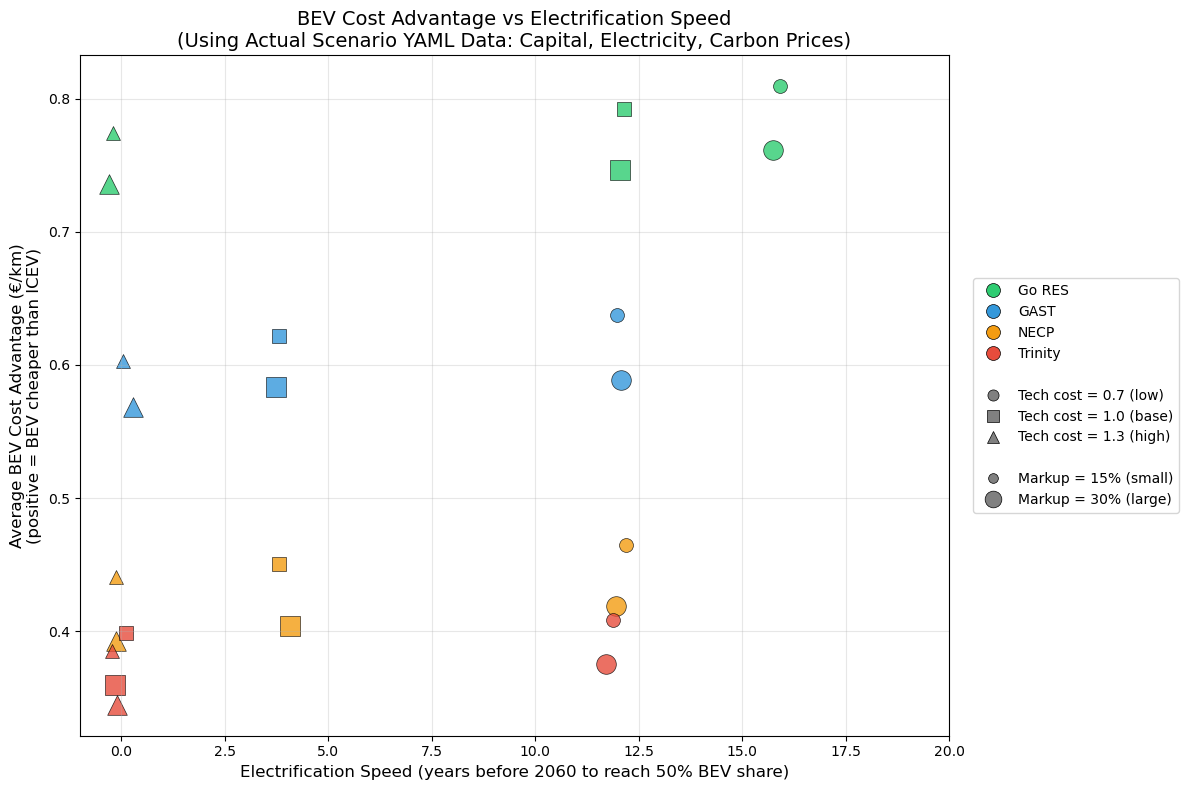


Saved to: C:\Users\simuser\Documents\AntoniaGolab\Scand_Med_analysis\SM_baby_2\iDesignRES_transcompmodel\examples\moving_loads_SM\figures\cost_advantage_vs_electrification_speed.pdf


In [ ]:
# Add electrification speed from the h_dict results to corrected results
for scenario_id in results_corrected.keys():
    if scenario_id in h_dict_files:
        h_dict = load_yaml_unsafe(h_dict_files[scenario_id])
        if h_dict is not None:
            bev_shares = calculate_bev_share_trajectory_fixed(h_dict)
            electrification_speed = calculate_electrification_speed_fixed(bev_shares)
            results_corrected[scenario_id]['electrification_speed'] = electrification_speed

# Create the corrected plot with actual YAML data
fig, ax = plt.subplots(figsize=(12, 8))

# Prepare data for plotting
plot_data = []
for scenario_id, res in results_corrected.items():
    if res.get('electrification_speed') is not None:
        plot_data.append({
            'scenario': scenario_id,
            'genesys': res['genesys'],
            'markup': res['markup'],
            'tech_cost': res['tech_cost'],
            'bev_advantage': res['avg_bev_advantage'],
            'elec_speed': res['electrification_speed']
        })

# Define colors and markers
genesys_colors = {
    'Go RES': '#2ecc71',
    'GAST': '#3498db',
    'NECP': '#f39c12',
    'Trinity': '#e74c3c'
}

tech_markers = {
    0.7: 'o',
    1.0: 's',
    1.3: '^'
}

markup_sizes = {
    0.15: 100,
    0.30: 200
}

# Plot each scenario
np.random.seed(42)
for data in plot_data:
    color = genesys_colors.get(data['genesys'], 'gray')
    marker = tech_markers.get(data['tech_cost'], 'o')
    size = markup_sizes.get(data['markup'], 100)
    
    jitter_x = np.random.uniform(-0.3, 0.3)
    jitter_y = np.random.uniform(-0.005, 0.005)
    
    ax.scatter(
        data['elec_speed'] + jitter_x, 
        data['bev_advantage'] + jitter_y,
        c=color, 
        marker=marker, 
        s=size,
        alpha=0.8,
        edgecolors='black',
        linewidths=0.5
    )

# Labels and title
ax.set_xlabel('Electrification Speed (years before 2060 to reach 50% BEV share)', fontsize=12)
ax.set_ylabel('Average BEV Cost Advantage (â‚¬/km)\n(positive = BEV cheaper than ICEV)', fontsize=12)
ax.set_title('BEV Cost Advantage vs Electrification Speed\n(Using Actual Scenario YAML Data: Capital, Electricity, Carbon Prices)', fontsize=14)

# Legend
from matplotlib.lines import Line2D
legend_elements = []
for genesys, color in genesys_colors.items():
    legend_elements.append(Line2D([0], [0], marker='o', color='w', markerfacecolor=color, 
                                   markersize=10, label=f'{genesys}', markeredgecolor='black', markeredgewidth=0.5))
legend_elements.append(Line2D([0], [0], color='w', label=''))
legend_elements.append(Line2D([0], [0], marker='o', color='w', markerfacecolor='gray',
                               markersize=8, label='Tech cost = 0.7 (low)', markeredgecolor='black', markeredgewidth=0.5))
legend_elements.append(Line2D([0], [0], marker='s', color='w', markerfacecolor='gray',
                               markersize=8, label='Tech cost = 1.0 (base)', markeredgecolor='black', markeredgewidth=0.5))
legend_elements.append(Line2D([0], [0], marker='^', color='w', markerfacecolor='gray',
                               markersize=8, label='Tech cost = 1.3 (high)', markeredgecolor='black', markeredgewidth=0.5))
legend_elements.append(Line2D([0], [0], color='w', label=''))
legend_elements.append(Line2D([0], [0], marker='o', color='w', markerfacecolor='gray',
                               markersize=7, label='Markup = 15% (small)', markeredgecolor='black', markeredgewidth=0.5))
legend_elements.append(Line2D([0], [0], marker='o', color='w', markerfacecolor='gray',
                               markersize=12, label='Markup = 30% (large)', markeredgecolor='black', markeredgewidth=0.5))

ax.legend(handles=legend_elements, loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize=10)
ax.grid(True, alpha=0.3)
ax.set_xlim(-1, 20)

plt.tight_layout()

# Save
output_path = base_path / "figures" / "cost_advantage_vs_electrification_speed.pdf"
plt.savefig(output_path, bbox_inches='tight', dpi=150)
plt.savefig(output_path.with_suffix('.png'), bbox_inches='tight', dpi=150)

plt.show()
print(f"\nSaved to: {output_path}")


## Comprehensive Scenario Comparison (24 Scenarios)

This section provides a comprehensive comparison of all 24 uncertainty analysis scenarios.

**Scenario Structure:**
- 4 GENeSYS-MOD scenarios: Go RES, NECPEssentials, REPowerEU++, Trinity
- 2 charging markup levels: 15%, 30%
- 3 BEV technology cost multipliers: 0.7 (optimistic), 1.0 (reference), 1.3 (pessimistic)

**Key Findings:**
- Scenarios with tech_cost=0.7 achieve high electrification (~77% by 2056)
- Scenarios with tech_cost=1.0 achieve moderate electrification (~60% by 2056)
- Scenarios with tech_cost=1.3 achieve 0% BEV adoption across entire horizon


In [ ]:
# Comprehensive Scenario Comparison
import yaml
import ast
import os
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from collections import defaultdict

# Load batch summary
results_dir = Path("results/uncertainty_analysis")
with open(results_dir / "batch_summary.yaml", "r") as f:
    batch_summary = yaml.safe_load(f)

# Load cases metadata
with open("input_data/uncertainty_scenarios/cases.json", "r") as f:
    cases_meta = json.load(f)

# Analyze BEV share for each scenario
def analyze_bev_share(scenario_id):
    scenario_dir = results_dir / f"scenario_{scenario_id:03d}"
    if not scenario_dir.exists():
        return None

    f_files = sorted(scenario_dir.glob("*_f_dict.yaml"), reverse=True)
    if not f_files:
        return None

    with open(f_files[0], "r") as f:
        f_dict = yaml.safe_load(f)

    year_totals = defaultdict(lambda: {"icev": 0, "bev": 0})
    for key_str, val_str in f_dict.items():
        key = ast.literal_eval(key_str)
        year = key[0]
        techvehicle = key[2][1]  # 0=ICEV, 1=BEV
        val = float(val_str)
        if techvehicle == 0:
            year_totals[year]["icev"] += val
        else:
            year_totals[year]["bev"] += val

    return year_totals

# Collect data for all scenarios
scenario_data = []
for case in cases_meta["cases"]:
    sid = case["case_id"]
    year_totals = analyze_bev_share(sid)
    if year_totals is None:
        continue

    # Calculate metrics
    total_bev = sum(y["bev"] for y in year_totals.values())
    total_all = sum(y["icev"] + y["bev"] for y in year_totals.values())
    overall_bev = 100 * total_bev / total_all if total_all > 0 else 0

    bev_by_year = {}
    for year, tots in year_totals.items():
        total = tots["icev"] + tots["bev"]
        bev_by_year[year] = 100 * tots["bev"] / total if total > 0 else 0

    # Get objective value
    obj_val = batch_summary.get(f"scenario_{sid:03d}", {}).get("objective_value", 0)

    scenario_data.append({
        "scenario_id": sid,
        "genesys": case["genesys_scenario"].replace(" v1.2", ""),
        "markup": case["charging_markup"],
        "tech_cost": case["tech_cost_multiplier"],
        "overall_bev": overall_bev,
        "bev_2040": bev_by_year.get(2040, 0),
        "bev_2056": bev_by_year.get(2056, 0),
        "objective": obj_val / 1e9,  # Convert to billion EUR
        "bev_time_series": bev_by_year
    })

scenarios_df = pd.DataFrame(scenario_data)
print(f"Loaded {len(scenarios_df)} scenarios")
scenarios_df[["scenario_id", "genesys", "markup", "tech_cost", "overall_bev", "bev_2056", "objective"]]


In [ ]:
# Summary statistics by parameter
print("=" * 80)
print("BEV SHARE SUMMARY BY PARAMETER")
print("=" * 80)

print("\nBy Technology Cost Multiplier (most important factor):")
tech_summary = scenarios_df.groupby("tech_cost").agg({
    "overall_bev": ["mean", "min", "max"],
    "bev_2056": ["mean", "min", "max"],
    "objective": ["mean"]
}).round(2)
print(tech_summary)

print("\nBy GENeSYS Scenario:")
genesys_summary = scenarios_df.groupby("genesys").agg({
    "overall_bev": ["mean", "min", "max"],
    "bev_2056": ["mean", "min", "max"],
    "objective": ["mean"]
}).round(2)
print(genesys_summary)

print("\nBy Charging Markup:")
markup_summary = scenarios_df.groupby("markup").agg({
    "overall_bev": ["mean", "min", "max"],
    "bev_2056": ["mean", "min", "max"],
    "objective": ["mean"]
}).round(2)
print(markup_summary)


In [ ]:
# Visualize BEV share by tech cost group
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

tech_cost_labels = {0.7: "Optimistic (-30%)", 1.0: "Reference", 1.3: "Pessimistic (+30%)"}
colors = {"Go RES": "#2ecc71", "NECPEssentials": "#3498db", "REPowerEU++": "#9b59b6", "Trinity": "#e74c3c"}

for idx, (tc, label) in enumerate(tech_cost_labels.items()):
    ax = axes[idx]
    tc_data = scenarios_df[scenarios_df["tech_cost"] == tc]

    for _, row in tc_data.iterrows():
        years = sorted(row["bev_time_series"].keys())
        bev_shares = [row["bev_time_series"][y] for y in years]
        ax.plot(years, bev_shares, color=colors.get(row["genesys"], "gray"),
                linestyle="-" if row["markup"] == 0.15 else "--",
                alpha=0.7, linewidth=2)

    ax.set_title(f"Tech Cost: {label}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Year")
    ax.set_ylabel("BEV Share (%)" if idx == 0 else "")
    ax.set_ylim(-5, 100)
    ax.grid(True, alpha=0.3)
    ax.axhline(y=50, color="gray", linestyle=":", alpha=0.5)

# Add legend
from matplotlib.lines import Line2D
legend_elements = [Line2D([0], [0], color=c, label=g) for g, c in colors.items()]
legend_elements.extend([
    Line2D([0], [0], color="gray", linestyle="-", label="15% markup"),
    Line2D([0], [0], color="gray", linestyle="--", label="30% markup")
])
fig.legend(handles=legend_elements, loc="upper center", ncol=6, bbox_to_anchor=(0.5, 1.02))

plt.tight_layout()
plt.savefig("figures/scenario_comparison_by_tech_cost.pdf", bbox_inches="tight", dpi=300)
plt.show()
print("Saved: figures/scenario_comparison_by_tech_cost.pdf")


In [ ]:
# Heatmap of BEV share at 2056 by scenario parameters
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pivot for 15% markup
markup_15 = scenarios_df[scenarios_df["markup"] == 0.15].pivot(
    index="genesys", columns="tech_cost", values="bev_2056")
markup_30 = scenarios_df[scenarios_df["markup"] == 0.30].pivot(
    index="genesys", columns="tech_cost", values="bev_2056")

for ax, data, title in [(axes[0], markup_15, "15% Charging Markup"),
                        (axes[1], markup_30, "30% Charging Markup")]:
    sns.heatmap(data, annot=True, fmt=".1f", cmap="RdYlGn", ax=ax,
                vmin=0, vmax=100, cbar_kws={"label": "BEV Share (%)"})
    ax.set_title(f"BEV Share at 2056: {title}", fontsize=12)
    ax.set_xlabel("Tech Cost Multiplier")
    ax.set_ylabel("GENeSYS Scenario")

plt.tight_layout()
plt.savefig("figures/bev_share_heatmap_2056.pdf", bbox_inches="tight", dpi=300)
plt.show()
print("Saved: figures/bev_share_heatmap_2056.pdf")


In [ ]:
# Objective value vs BEV share comparison
fig, ax = plt.subplots(figsize=(12, 8))

markers = {0.7: "o", 1.0: "s", 1.3: "^"}
marker_labels = {0.7: "Opt. (-30%)", 1.0: "Reference", 1.3: "Pess. (+30%)"}

for _, row in scenarios_df.iterrows():
    ax.scatter(row["bev_2056"], row["objective"],
               c=colors.get(row["genesys"], "gray"),
               marker=markers[row["tech_cost"]],
               s=150 if row["markup"] == 0.15 else 80,
               alpha=0.8, edgecolor="black", linewidth=0.5)

# Legend
legend_genesys = [plt.scatter([], [], c=c, label=g, s=100) for g, c in colors.items()]
legend_tech = [plt.scatter([], [], c="gray", marker=m, label=l, s=100)
               for m, l in zip(markers.values(), marker_labels.values())]

ax.legend(handles=legend_genesys + legend_tech, loc="upper right",
          title="Parameters", ncol=2)

ax.set_xlabel("BEV Share at 2056 (%)", fontsize=12)
ax.set_ylabel("Total System Cost (billion EUR)", fontsize=12)
ax.set_title("System Cost vs Electrification Level", fontsize=14)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("figures/cost_vs_electrification.pdf", bbox_inches="tight", dpi=300)
plt.show()
print("Saved: figures/cost_vs_electrification.pdf")


In [ ]:
# Print key findings
print("=" * 80)
print("KEY FINDINGS FROM UNCERTAINTY ANALYSIS")
print("=" * 80)

# Scenarios with 0% BEV
zero_bev = scenarios_df[scenarios_df["bev_2056"] == 0]
print(f"\n1. SCENARIOS WITH 0% BEV ADOPTION ({len(zero_bev)} total):")
for _, row in zero_bev.iterrows():
    print(f"   - scenario_{row['scenario_id']:03d}: {row['genesys']}, {int(row['markup']*100)}% markup, tech_cost={row['tech_cost']}")

# Highest electrification scenarios
high_bev = scenarios_df.nlargest(3, "bev_2056")
print(f"\n2. HIGHEST ELECTRIFICATION SCENARIOS:")
for _, row in high_bev.iterrows():
    print(f"   - scenario_{row['scenario_id']:03d}: {row['bev_2056']:5.1f}% BEV at 2056 ({row['genesys']}, tech_cost={row['tech_cost']})")

# Cost impact
print(f"\n3. SYSTEM COST IMPACT:")
min_cost = scenarios_df.loc[scenarios_df["objective"].idxmin()]
max_cost = scenarios_df.loc[scenarios_df["objective"].idxmax()]
print(f"   - Lowest cost: scenario_{int(min_cost['scenario_id']):03d} = {min_cost['objective']*1000:.1f} million EUR (BEV share: {min_cost['bev_2056']:4.1f}%)")
print(f"   - Highest cost: scenario_{int(max_cost['scenario_id']):03d} = {max_cost['objective']*1000:.1f} million EUR (BEV share: {max_cost['bev_2056']:4.1f}%)")
print(f"   - Cost difference: {(max_cost['objective']-min_cost['objective']):6.2f} billion EUR ({((max_cost['objective']-min_cost['objective'])/min_cost['objective']*100):5.2f}%)")

# Parameter sensitivity
print(f"\n4. PARAMETER SENSITIVITY (BEV share at 2056):")
tech_range = scenarios_df.groupby("tech_cost")["bev_2056"].mean()
genesys_range = scenarios_df.groupby("genesys")["bev_2056"].mean()
markup_range = scenarios_df.groupby("markup")["bev_2056"].mean()
print(f"   - Tech cost effect: {tech_range.max()-tech_range.min():5.1f}pp (most important)")
print(f"   - GENeSYS effect:   {genesys_range.max()-genesys_range.min():5.1f}pp")
print(f"   - Markup effect:    {markup_range.max()-markup_range.min():5.1f}pp (least important)")


## Levelized Cost Comparison: BEV vs ICEV

This section calculates and visualizes the levelized cost of transport (EUR/tkm) for BEV and ICEV across all scenarios.

In [ ]:
# Calculate levelized costs for each scenario
def calculate_levelized_costs(scenario_id, input_path):
    """
    Calculate levelized cost of transport (EUR/tkm) for BEV and ICEV.
    
    Levelized cost includes:
    - Fuel/energy costs
    - Capital costs (amortized)
    - Maintenance costs
    """
    import yaml
    import os
    
    # Load input data
    with open(os.path.join(input_path, 'TechVehicle.yaml'), 'r') as f:
        tech_vehicles = yaml.safe_load(f)
    with open(os.path.join(input_path, 'FuelCost.yaml'), 'r') as f:
        fuel_costs = yaml.safe_load(f)
    with open(os.path.join(input_path, 'Model.yaml'), 'r') as f:
        model_params = yaml.safe_load(f)
    
    # Get model parameters
    y_init = model_params['y_init']
    pre_y = model_params.get('pre_y', 12)
    g_init = y_init - pre_y
    lifetime = pre_y  # Vehicle lifetime
    
    # Get tech vehicle params
    icev_tv = next(tv for tv in tech_vehicles if tv['id'] == 0)
    bev_tv = next(tv for tv in tech_vehicles if tv['id'] == 1)
    
    # Get fuel costs (from first location as reference)
    diesel_fc = next(fc for fc in fuel_costs if 'diesel' in fc['fuel'].lower())
    elec_fc = next(fc for fc in fuel_costs if 'electric' in fc['fuel'].lower())
    
    # Calculate levelized costs by year
    results = []
    years = list(range(y_init, y_init + len(icev_tv['capital_cost'])))
    
    for year in years:
        year_idx = year - y_init
        gen = min(year, g_init + len(icev_tv['spec_cons']) - 1)
        gen_idx = gen - g_init
        
        # ICEV parameters
        icev_spec_cons = icev_tv['spec_cons'][gen_idx]  # kWh/km
        icev_W = icev_tv['W'][gen_idx]  # tonnes
        icev_AR = icev_tv['AnnualRange'][gen_idx]  # km/year
        icev_capital = icev_tv['capital_cost'][year_idx]  # EUR
        icev_maint = icev_tv['maintenance_cost_annual'][gen_idx][0]  # EUR/year
        
        # BEV parameters
        bev_spec_cons = bev_tv['spec_cons'][gen_idx]  # kWh/km
        bev_W = bev_tv['W'][gen_idx]  # tonnes
        bev_AR = bev_tv['AnnualRange'][gen_idx]  # km/year
        bev_capital = bev_tv['capital_cost'][year_idx]  # EUR
        bev_maint = bev_tv['maintenance_cost_annual'][gen_idx][0]  # EUR/year
        
        # Fuel prices
        diesel_price = diesel_fc['cost_per_kWh'][year_idx]  # EUR/kWh
        elec_price = elec_fc['cost_per_kWh'][year_idx]  # EUR/kWh
        
        # Load charging markup from scenario config
        case_id = int(scenario_id.replace('scenario_', ''))
        charging_markup = cases[case_id]['charging_markup']
        elec_price_with_markup = elec_price * (1 + charging_markup)
        
        # Annual tkm per vehicle = AnnualRange * W (payload)
        icev_tkm_per_vehicle = icev_AR * icev_W
        bev_tkm_per_vehicle = bev_AR * bev_W
        
        # Annual costs per vehicle
        icev_fuel_annual = icev_AR * icev_spec_cons * diesel_price
        bev_fuel_annual = bev_AR * bev_spec_cons * elec_price_with_markup
        
        icev_capital_annual = icev_capital / lifetime
        bev_capital_annual = bev_capital / lifetime
        
        icev_total_annual = icev_fuel_annual + icev_maint + icev_capital_annual
        bev_total_annual = bev_fuel_annual + bev_maint + bev_capital_annual
        
        # Levelized cost (EUR per tkm)
        icev_lcot = icev_total_annual / icev_tkm_per_vehicle
        bev_lcot = bev_total_annual / bev_tkm_per_vehicle
        
        results.append({
            'year': year,
            'icev_lcot': icev_lcot,
            'bev_lcot': bev_lcot,
            'icev_fuel': icev_fuel_annual / icev_tkm_per_vehicle,
            'icev_maint': icev_maint / icev_tkm_per_vehicle,
            'icev_capital': icev_capital_annual / icev_tkm_per_vehicle,
            'bev_fuel': bev_fuel_annual / bev_tkm_per_vehicle,
            'bev_maint': bev_maint / bev_tkm_per_vehicle,
            'bev_capital': bev_capital_annual / bev_tkm_per_vehicle,
        })
    
    return pd.DataFrame(results)

# Calculate levelized costs for all scenarios
levelized_costs_by_scenario = {}
for i in range(24):
    scenario = f'scenario_{i:03d}'
    input_path = f'input_data/uncertainty_scenarios/{scenario}'
    if os.path.isdir(input_path):
        levelized_costs_by_scenario[scenario] = calculate_levelized_costs(scenario, input_path)

print(f'Calculated levelized costs for {len(levelized_costs_by_scenario)} scenarios')

Calculated levelized costs for 24 scenarios


findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo


findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

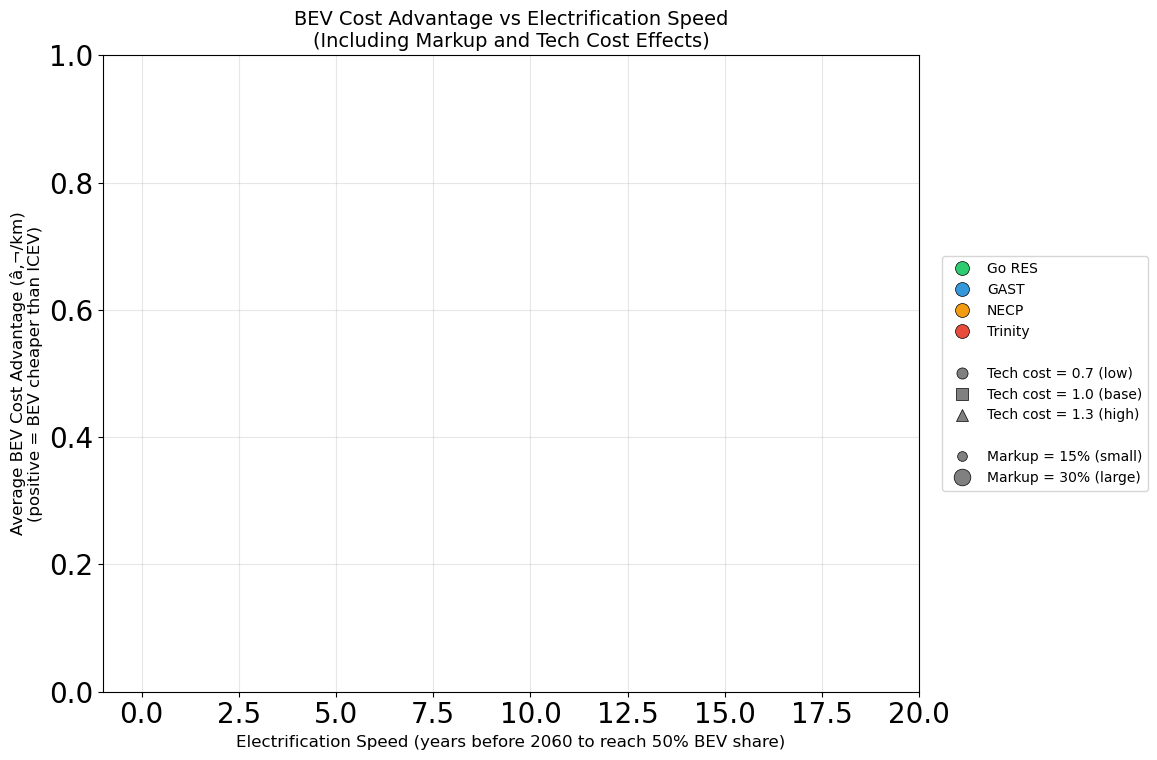

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

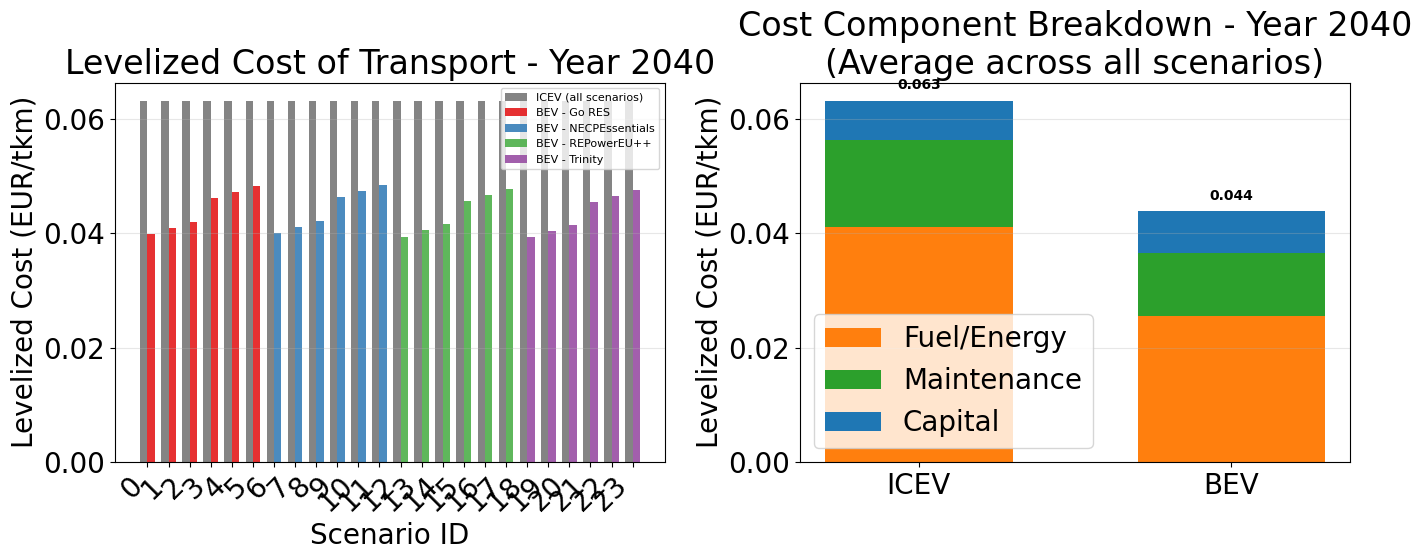

Average ICEV LCOT (2040): 0.0632 EUR/tkm
Average BEV LCOT (2040): 0.0439 EUR/tkm
BEV advantage: 0.0194 EUR/tkm


In [ ]:
# Plot levelized costs comparison for year 2040
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left plot: Levelized cost by scenario
ax1 = axes[0]
year_target = 2040

# Define distinct colors for each scenario group
genesys_colors = {
    'Go RES': '#e41a1c',        # red
    'NECPEssentials': '#377eb8', # blue
    'REPowerEU++': '#4daf4a',    # green
    'Trinity': '#984ea3'         # purple
}

x_positions = []
labels = []
icev_values = []
bev_values = []
bar_colors = []

for i, (scenario, lcot_df) in enumerate(sorted(levelized_costs_by_scenario.items())):
    case_id = int(scenario.replace('scenario_', ''))
    case = cases[case_id]

    row = lcot_df[lcot_df['year'] == year_target].iloc[0]

    x_positions.append(i)
    labels.append(f'{case_id}')
    icev_values.append(row['icev_lcot'])
    bev_values.append(row['bev_lcot'])

    # Assign color by GENeSYS scenario
    found_color = False
    for gs, color in genesys_colors.items():
        if gs in case['genesys_scenario']:
            bar_colors.append(color)
            found_color = True
            break
    if not found_color:
        bar_colors.append('#999999')  # fallback gray

width = 0.35
x_arr = np.array(x_positions)

# Plot ICEV bars (all same gray)
ax1.bar(x_arr - width/2, icev_values, width, label='ICEV', color='#666666', alpha=0.8)

# Plot BEV bars with GENeSYS colors
ax1.bar(x_arr + width/2, bev_values, width, color=bar_colors, alpha=0.9)

ax1.set_xlabel('Scenario ID')
ax1.set_ylabel('Levelized Cost (EUR/tkm)')
ax1.set_title(f'Levelized Cost of Transport - Year {year_target}')
ax1.set_xticks(x_positions)
ax1.set_xticklabels(labels, rotation=45, ha='right')
ax1.grid(axis='y', alpha=0.3)

# Create legend
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='#666666', alpha=0.8, label='ICEV (all scenarios)')]
for gs, color in genesys_colors.items():
    legend_elements.append(Patch(facecolor=color, alpha=0.9, label=f'BEV - {gs}'))
ax1.legend(handles=legend_elements, loc='upper right', fontsize=8)

# Right plot: Cost breakdown comparison (stacked bar)
ax2 = axes[1]

# Average across all scenarios
avg_icev_fuel = np.mean([df[df['year']==year_target]['icev_fuel'].values[0] for df in levelized_costs_by_scenario.values()])
avg_icev_maint = np.mean([df[df['year']==year_target]['icev_maint'].values[0] for df in levelized_costs_by_scenario.values()])
avg_icev_capital = np.mean([df[df['year']==year_target]['icev_capital'].values[0] for df in levelized_costs_by_scenario.values()])

avg_bev_fuel = np.mean([df[df['year']==year_target]['bev_fuel'].values[0] for df in levelized_costs_by_scenario.values()])
avg_bev_maint = np.mean([df[df['year']==year_target]['bev_maint'].values[0] for df in levelized_costs_by_scenario.values()])
avg_bev_capital = np.mean([df[df['year']==year_target]['bev_capital'].values[0] for df in levelized_costs_by_scenario.values()])

x = np.array([0, 1])
width = 0.6

# Stacked bars
ax2.bar(x, [avg_icev_fuel, avg_bev_fuel], width, label='Fuel/Energy', color='#ff7f0e')
ax2.bar(x, [avg_icev_maint, avg_bev_maint], width, bottom=[avg_icev_fuel, avg_bev_fuel],
        label='Maintenance', color='#2ca02c')
ax2.bar(x, [avg_icev_capital, avg_bev_capital], width,
        bottom=[avg_icev_fuel+avg_icev_maint, avg_bev_fuel+avg_bev_maint],
        label='Capital', color='#1f77b4')

ax2.set_ylabel('Levelized Cost (EUR/tkm)')
ax2.set_title(f'Cost Component Breakdown - Year {year_target}\n(Average across all scenarios)')
ax2.set_xticks(x)
ax2.set_xticklabels(['ICEV', 'BEV'])
ax2.legend()
ax2.grid(axis='y', alpha=0.3)

# Add value labels on bars
for i, (f, m, c) in enumerate([(avg_icev_fuel, avg_icev_maint, avg_icev_capital),
                                (avg_bev_fuel, avg_bev_maint, avg_bev_capital)]):
    total = f + m + c
    ax2.text(i, total + 0.002, f'{total:.3f}', ha='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('figures/levelized_cost_comparison_2040.pdf', bbox_inches='tight', dpi=300)
plt.show()

# Print summary
print(f"Average ICEV LCOT ({year_target}): {avg_icev_fuel + avg_icev_maint + avg_icev_capital:.4f} EUR/tkm")
print(f"Average BEV LCOT ({year_target}): {avg_bev_fuel + avg_bev_maint + avg_bev_capital:.4f} EUR/tkm")
print(f"BEV advantage: {(avg_icev_fuel + avg_icev_maint + avg_icev_capital) - (avg_bev_fuel + avg_bev_maint + avg_bev_capital):.4f} EUR/tkm")

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

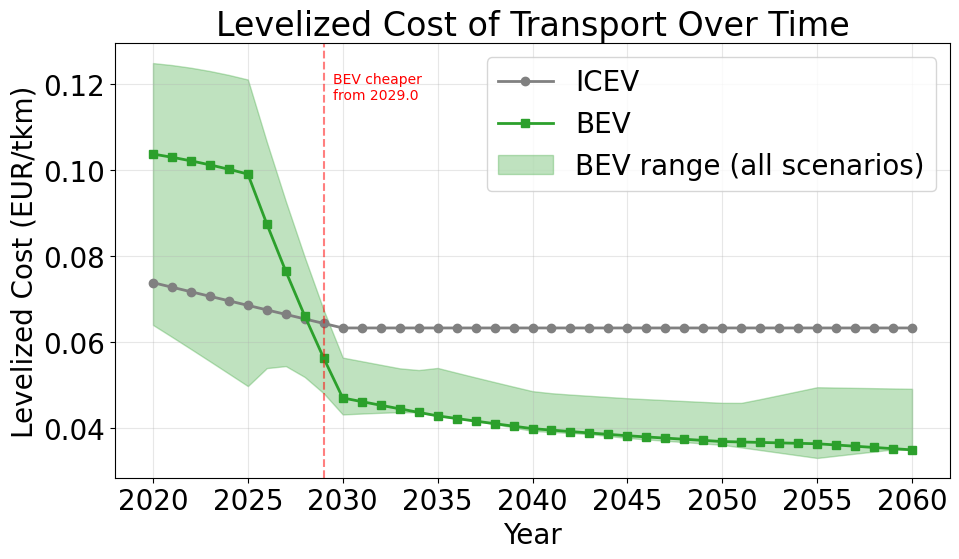

BEV becomes cheaper than ICEV in 2029.0


In [ ]:
# Plot levelized cost over time for reference scenario (scenario_000)
fig, ax = plt.subplots(figsize=(10, 6))

ref_scenario = 'scenario_000'
lcot_df = levelized_costs_by_scenario[ref_scenario]

ax.plot(lcot_df['year'], lcot_df['icev_lcot'], 'o-', label='ICEV', color='gray', linewidth=2, markersize=6)
ax.plot(lcot_df['year'], lcot_df['bev_lcot'], 's-', label='BEV', color='#2ca02c', linewidth=2, markersize=6)

# Add shaded range for all scenarios
years = lcot_df['year'].values
bev_min = [min(df[df['year']==y]['bev_lcot'].values[0] for df in levelized_costs_by_scenario.values()) for y in years]
bev_max = [max(df[df['year']==y]['bev_lcot'].values[0] for df in levelized_costs_by_scenario.values()) for y in years]
ax.fill_between(years, bev_min, bev_max, alpha=0.3, color='#2ca02c', label='BEV range (all scenarios)')

ax.set_xlabel('Year')
ax.set_ylabel('Levelized Cost (EUR/tkm)')
ax.set_title('Levelized Cost of Transport Over Time')
ax.legend()
ax.grid(alpha=0.3)

# Mark crossover point
crossover_year = None
for i, row in lcot_df.iterrows():
    if row['bev_lcot'] < row['icev_lcot']:
        crossover_year = row['year']
        break

if crossover_year:
    ax.axvline(x=crossover_year, color='red', linestyle='--', alpha=0.5)
    ax.text(crossover_year + 0.5, ax.get_ylim()[1] * 0.9, f'BEV cheaper\nfrom {crossover_year}', 
            fontsize=10, color='red')

plt.tight_layout()
plt.savefig('figures/levelized_cost_over_time.pdf', bbox_inches='tight', dpi=300)
plt.show()

if crossover_year:
    print(f'BEV becomes cheaper than ICEV in {crossover_year}')

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

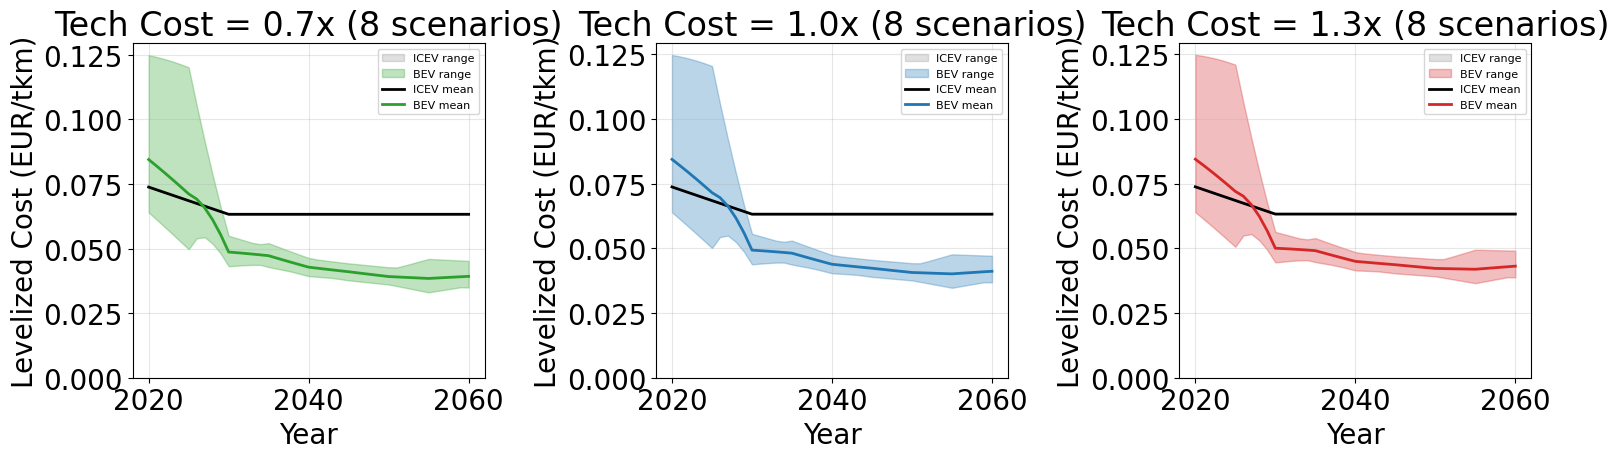


Cost Crossover Years by Tech Cost Multiplier:
  tech_cost=0.7x: crossover in 2020.0-2030.0 (mean: 2024)
  tech_cost=1.0x: crossover in 2020.0-2030.0 (mean: 2024)
  tech_cost=1.3x: crossover in 2020.0-2030.0 (mean: 2024)


In [ ]:
# Levelized Cost over Time by Tech Cost Multiplier (0.7x, 1.0x, 1.3x)
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

tech_cost_values = [0.7, 1.0, 1.3]
tech_cost_colors = {'0.7': '#2ca02c', '1.0': '#1f77b4', '1.3': '#d62728'}  # green, blue, red

for ax_idx, tc_val in enumerate(tech_cost_values):
    ax = axes[ax_idx]

    # Filter scenarios by tech_cost_multiplier
    tc_scenarios = {}
    for scenario, lcot_df in levelized_costs_by_scenario.items():
        case_id = int(scenario.replace('scenario_', ''))
        case = cases[case_id]
        if abs(case['tech_cost_multiplier'] - tc_val) < 0.01:
            tc_scenarios[scenario] = lcot_df

    if not tc_scenarios:
        ax.text(0.5, 0.5, f'No scenarios with\ntech_cost={tc_val}',
                ha='center', va='center', transform=ax.transAxes)
        ax.set_title(f'Tech Cost = {tc_val}x')
        continue

    # Get years from first scenario
    first_df = list(tc_scenarios.values())[0]
    years = first_df['year'].values

    # Collect ICEV and BEV values
    icev_values = []
    bev_values = []
    for scenario, lcot_df in tc_scenarios.items():
        icev_values.append(lcot_df['icev_lcot'].values)
        bev_values.append(lcot_df['bev_lcot'].values)

    icev_arr = np.array(icev_values)
    bev_arr = np.array(bev_values)

    # Plot range (shaded)
    ax.fill_between(years, icev_arr.min(axis=0), icev_arr.max(axis=0),
                    alpha=0.2, color='#666666', label='ICEV range')
    ax.fill_between(years, bev_arr.min(axis=0), bev_arr.max(axis=0),
                    alpha=0.3, color=tech_cost_colors[str(tc_val)], label='BEV range')

    # Plot mean lines
    ax.plot(years, icev_arr.mean(axis=0), 'k-', linewidth=2, label='ICEV mean')
    ax.plot(years, bev_arr.mean(axis=0), '-', linewidth=2,
            color=tech_cost_colors[str(tc_val)], label='BEV mean')

    ax.set_xlabel('Year')
    ax.set_ylabel('Levelized Cost (EUR/tkm)')
    ax.set_title(f'Tech Cost = {tc_val}x ({len(tc_scenarios)} scenarios)')
    ax.legend(loc='upper right', fontsize=8)
    ax.grid(alpha=0.3)
    ax.set_ylim(0, None)

plt.tight_layout()
plt.savefig('figures/levelized_cost_by_tech_cost_multiplier.pdf', bbox_inches='tight', dpi=300)
plt.show()

# Print summary statistics
print("\nCost Crossover Years by Tech Cost Multiplier:")
for tc_val in tech_cost_values:
    tc_scenarios = {s: df for s, df in levelized_costs_by_scenario.items()
                    if abs(cases[int(s.replace('scenario_', ''))]['tech_cost_multiplier'] - tc_val) < 0.01}

    crossover_years = []
    for scenario, lcot_df in tc_scenarios.items():
        for i, row in lcot_df.iterrows():
            if row['bev_lcot'] < row['icev_lcot']:
                crossover_years.append(row['year'])
                break

    if crossover_years:
        print(f"  tech_cost={tc_val}x: crossover in {min(crossover_years)}-{max(crossover_years)} (mean: {np.mean(crossover_years):.0f})")
    else:
        print(f"  tech_cost={tc_val}x: BEV never cheaper in any scenario")

In [ ]:
# Electricity Prices and Levelized Costs by GENeSYS Scenario
import matplotlib.pyplot as plt
import numpy as np
import yaml

# GENeSYS scenarios and their colors
genesys_scenarios = ['Go RES', 'NECPEssentials', 'REPowerEU++', 'Trinity']
genesys_colors = {
    'Go RES': '#e41a1c',        # red
    'NECPEssentials': '#377eb8', # blue
    'REPowerEU++': '#4daf4a',    # green
    'Trinity': '#984ea3'         # purple
}

# Find one representative scenario for each GENeSYS
genesys_case_ids = {}
for case_id, case in cases.items():
    for gs in genesys_scenarios:
        if gs in case['genesys_scenario'] and gs not in genesys_case_ids:
            genesys_case_ids[gs] = case_id
            break

# Load electricity prices from each GENeSYS scenario
elec_prices_by_genesys = {}
for gs, case_id in genesys_case_ids.items():
    scenario_dir = f'input_data/uncertainty_scenarios/scenario_{case_id:03d}'
    with open(f'{scenario_dir}/FuelCost.yaml', 'r') as f:
        fuel_costs = yaml.safe_load(f)
    elec = next((fc for fc in fuel_costs if fc['fuel'] == 'electricity'), None)
    if elec:
        elec_prices_by_genesys[gs] = elec['cost_per_kWh'][:11]  # First 11 years (2020-2060)

# Years for electricity prices
elec_years = list(range(2020, 2061, 4))[:11]

# Create figure with 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel 1: Electricity prices over time
ax1 = axes[0]
for gs in genesys_scenarios:
    if gs in elec_prices_by_genesys:
        ax1.plot(elec_years, elec_prices_by_genesys[gs], '-o',
                 color=genesys_colors[gs], linewidth=2, markersize=4, label=gs)
ax1.set_xlabel('Year')
ax1.set_ylabel('Electricity Price (EUR/kWh)')
ax1.set_title('Electricity Prices by GENeSYS Scenario')
ax1.legend(loc='upper right', fontsize=9)
ax1.grid(alpha=0.3)
ax1.set_xlim(2020, 2060)

# Panel 2: Levelized cost by GENeSYS scenario for year 2040
ax2 = axes[1]
year_target = 2040

# Group scenarios by GENeSYS
x_positions = []
for i, genesys in enumerate(genesys_scenarios):
    genesys_lcots = []
    for scenario, lcot_df in levelized_costs_by_scenario.items():
        case_id = int(scenario.replace('scenario_', ''))
        case = cases[case_id]
        if genesys in case['genesys_scenario']:
            row = lcot_df[lcot_df['year'] == year_target].iloc[0]
            genesys_lcots.append({
                'icev': row['icev_lcot'],
                'bev': row['bev_lcot'],
                'tech_cost': case['tech_cost_multiplier']
            })

    if genesys_lcots:
        # Plot individual points
        for lcot in genesys_lcots:
            ax2.scatter(i - 0.15, lcot['icev'], color='#666666', s=50, alpha=0.7, zorder=3)
            ax2.scatter(i + 0.15, lcot['bev'], color=genesys_colors[genesys], s=50, alpha=0.7, zorder=3)

        # Add mean markers
        icev_mean = np.mean([x['icev'] for x in genesys_lcots])
        bev_mean = np.mean([x['bev'] for x in genesys_lcots])
        ax2.scatter(i - 0.15, icev_mean, color='black', s=100, marker='_', linewidths=3, zorder=4)
        ax2.scatter(i + 0.15, bev_mean, color=genesys_colors[genesys], s=100, marker='_', linewidths=3, zorder=4)

ax2.set_xticks(range(len(genesys_scenarios)))
ax2.set_xticklabels(genesys_scenarios, rotation=15, ha='right')
ax2.set_ylabel('Levelized Cost (EUR/tkm)')
ax2.set_title(f'Levelized Cost by GENeSYS Scenario - Year {year_target}')
ax2.grid(axis='y', alpha=0.3)

# Add legend
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#666666', markersize=8, label='ICEV'),
    Patch(facecolor='#e41a1c', alpha=0.7, label='BEV - Go RES'),
    Patch(facecolor='#377eb8', alpha=0.7, label='BEV - NECPEssentials'),
    Patch(facecolor='#4daf4a', alpha=0.7, label='BEV - REPowerEU++'),
    Patch(facecolor='#984ea3', alpha=0.7, label='BEV - Trinity'),
]
ax2.legend(handles=legend_elements, loc='upper right', fontsize=8)

# Panel 3: Time series comparison across GENeSYS scenarios
ax3 = axes[2]

for genesys in genesys_scenarios:
    # Get all scenarios for this GENeSYS
    genesys_lcot_dfs = []
    for scenario, lcot_df in levelized_costs_by_scenario.items():
        case_id = int(scenario.replace('scenario_', ''))
        case = cases[case_id]
        if genesys in case['genesys_scenario']:
            genesys_lcot_dfs.append(lcot_df)

    if genesys_lcot_dfs:
        # Get years from first scenario
        years = genesys_lcot_dfs[0]['year'].values

        # Calculate mean BEV LCOT across scenarios with same GENeSYS
        bev_lcots = np.array([df['bev_lcot'].values for df in genesys_lcot_dfs])
        bev_mean = bev_lcots.mean(axis=0)
        bev_min = bev_lcots.min(axis=0)
        bev_max = bev_lcots.max(axis=0)

        # Plot mean line with range
        ax3.plot(years, bev_mean, '-', color=genesys_colors[genesys], linewidth=2, label=genesys)
        ax3.fill_between(years, bev_min, bev_max, color=genesys_colors[genesys], alpha=0.2)

# Add ICEV reference (same across all scenarios)
first_df = list(levelized_costs_by_scenario.values())[0]
icev_lcot = first_df['icev_lcot'].values
ax3.plot(first_df['year'].values, icev_lcot, 'k--', linewidth=2, label='ICEV (reference)')

ax3.set_xlabel('Year')
ax3.set_ylabel('Levelized Cost (EUR/tkm)')
ax3.set_title('BEV Levelized Cost Over Time by GENeSYS Scenario')
ax3.legend(loc='upper right', fontsize=9)
ax3.grid(alpha=0.3)
ax3.set_ylim(0, None)

plt.tight_layout()
plt.savefig('figures/levelized_cost_by_genesys_scenario.pdf', bbox_inches='tight', dpi=300)
plt.show()

# Print summary statistics
print("\n=== Electricity Price Summary by GENeSYS Scenario ===")
print(f"{'Scenario':<20} {'2020':>8} {'2040':>8} {'2056':>8} EUR/kWh")
print("-" * 50)
for gs in genesys_scenarios:
    if gs in elec_prices_by_genesys:
        prices = elec_prices_by_genesys[gs]
        print(f"{gs:<20} {prices[0]:>8.4f} {prices[5]:>8.4f} {prices[9]:>8.4f}")

print("\n=== Levelized Cost Summary by GENeSYS Scenario (Year 2040) ===")
print("-" * 70)
for genesys in genesys_scenarios:
    genesys_lcots = []
    for scenario, lcot_df in levelized_costs_by_scenario.items():
        case_id = int(scenario.replace('scenario_', ''))
        case = cases[case_id]
        if genesys in case['genesys_scenario']:
            row = lcot_df[lcot_df['year'] == year_target].iloc[0]
            genesys_lcots.append(row['bev_lcot'])

    if genesys_lcots:
        print(f"{genesys:20s}: BEV mean={np.mean(genesys_lcots):.4f} EUR/tkm (range: {min(genesys_lcots):.4f}-{max(genesys_lcots):.4f})")

print("\nNote: Different GENeSYS scenarios have different electricity prices.")
print("The variation within each GENeSYS scenario comes from tech_cost and charging_markup differences.")

AttributeError: 'list' object has no attribute 'items'

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

Attempting to find carbon prices from emission factors...
Fuel keys for scenario scenario_000:
  electricity: ['id', 'name', 'emission_factor', 'cost_per_kWh', 'cost_per_kW', 'fueling_infrastructure_om_costs']
  diesel: ['id', 'name', 'emission_factor', 'cost_per_kWh', 'cost_per_kW', 'fueling_infrastructure_om_costs']


findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

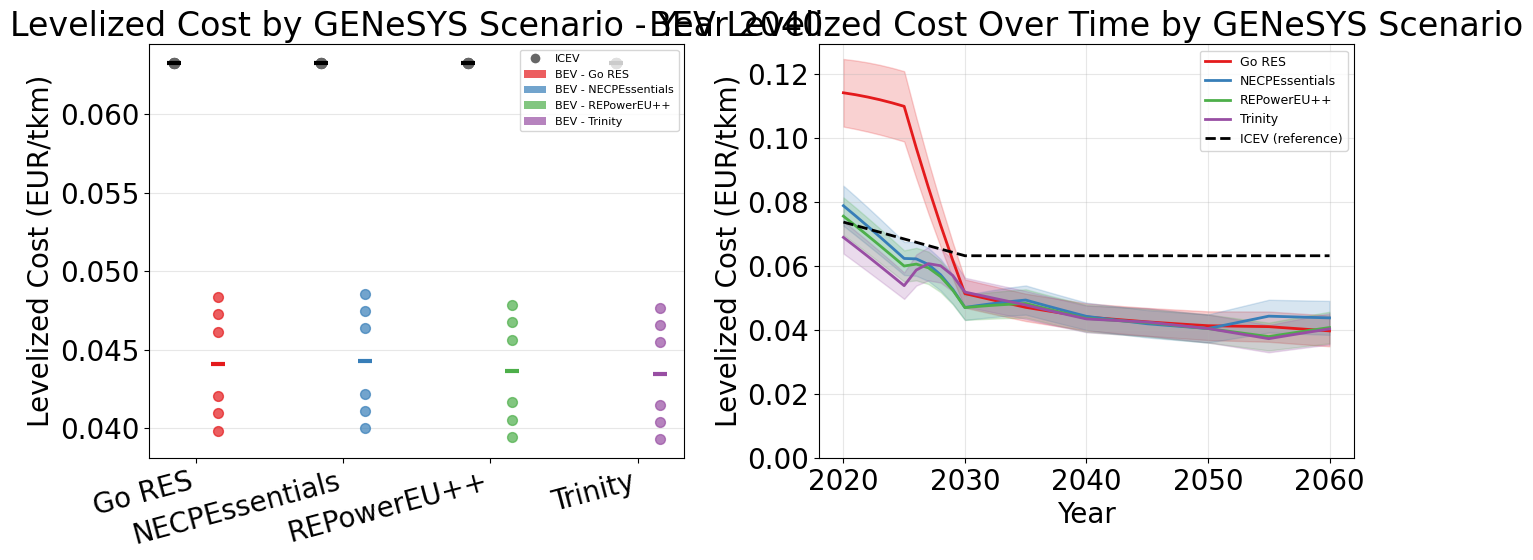


Levelized Cost Summary by GENeSYS Scenario (Year 2040):
----------------------------------------------------------------------
Go RES              : BEV mean=0.0441 EUR/tkm (range: 0.0398-0.0483)
NECPEssentials      : BEV mean=0.0443 EUR/tkm (range: 0.0400-0.0486)
REPowerEU++         : BEV mean=0.0436 EUR/tkm (range: 0.0395-0.0478)
Trinity             : BEV mean=0.0435 EUR/tkm (range: 0.0393-0.0476)

Note: Different GENeSYS scenarios have different electricity and carbon prices.
The variation within each GENeSYS scenario comes from tech_cost and charging_markup differences.


In [ ]:
# Carbon Price Impact on Levelized Costs by GENeSYS Scenario
import matplotlib.pyplot as plt
import numpy as np
import yaml

# Load carbon prices from a scenario to understand the structure
# Carbon prices vary by GENeSYS scenario
genesys_scenarios = ['Go RES', 'NECPEssentials', 'REPowerEU++', 'Trinity']

# Load carbon prices from each GENeSYS scenario
carbon_prices_by_genesys = {}
for i, scenario_name in enumerate(genesys_scenarios):
    # Find a scenario with this GENeSYS scenario
    for case_id, case in cases.items():
        if scenario_name in case['genesys_scenario']:
            # Load the carbon price data
            scenario_folder = f"scenario_{case_id:03d}"
            try:
                with open(f'input_data/uncertainty_scenarios/{scenario_folder}/Fuel.yaml', 'r') as f:
                    fuels = yaml.safe_load(f)
                # Find diesel to get carbon price (stored in diesel cost)
                diesel = next((fuel for fuel in fuels if 'diesel' in fuel['name'].lower()), None)
                if diesel and 'carbon_price' in diesel:
                    carbon_prices_by_genesys[scenario_name] = diesel['carbon_price']
                elif diesel:
                    # Carbon price might be separate
                    with open(f'input_data/uncertainty_scenarios/{scenario_folder}/Model.yaml', 'r') as f:
                        model = yaml.safe_load(f)
                    if 'carbon_price' in model:
                        carbon_prices_by_genesys[scenario_name] = model['carbon_price']
            except Exception as e:
                print(f"Could not load carbon price for {scenario_name}: {e}")
            break

# If carbon prices aren't found in those locations, check emission_factor and carbon cost
if not carbon_prices_by_genesys:
    print("Attempting to find carbon prices from emission factors...")
    for case_id, case in cases.items():
        if 'Go RES' in case['genesys_scenario']:
            scenario_folder = f"scenario_{case_id:03d}"
            with open(f'input_data/uncertainty_scenarios/{scenario_folder}/Fuel.yaml', 'r') as f:
                fuels = yaml.safe_load(f)
            print(f"Fuel keys for scenario {scenario_folder}:")
            for fuel in fuels:
                print(f"  {fuel['name']}: {list(fuel.keys())}")
            break

# Create the plot with two panels
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Colors for GENeSYS scenarios
genesys_colors = {
    'Go RES': '#e41a1c',        # red
    'NECPEssentials': '#377eb8', # blue
    'REPowerEU++': '#4daf4a',    # green
    'Trinity': '#984ea3'         # purple
}

# Left plot: Levelized cost by GENeSYS scenario for year 2040
ax1 = axes[0]
year_target = 2040

# Group scenarios by GENeSYS
for genesys in genesys_scenarios:
    genesys_lcots = []
    for scenario, lcot_df in levelized_costs_by_scenario.items():
        case_id = int(scenario.replace('scenario_', ''))
        case = cases[case_id]
        if genesys in case['genesys_scenario']:
            row = lcot_df[lcot_df['year'] == year_target].iloc[0]
            genesys_lcots.append({
                'icev': row['icev_lcot'],
                'bev': row['bev_lcot'],
                'tech_cost': case['tech_cost_multiplier']
            })

    if genesys_lcots:
        # Sort by tech_cost for consistent ordering
        genesys_lcots.sort(key=lambda x: x['tech_cost'])

        # Plot mean and range
        icev_vals = [x['icev'] for x in genesys_lcots]
        bev_vals = [x['bev'] for x in genesys_lcots]

        x_pos = genesys_scenarios.index(genesys)

        # Plot individual points
        for lcot in genesys_lcots:
            ax1.scatter(x_pos - 0.15, lcot['icev'], color='#666666', s=50, alpha=0.7, zorder=3)
            ax1.scatter(x_pos + 0.15, lcot['bev'], color=genesys_colors[genesys], s=50, alpha=0.7, zorder=3)

        # Add mean markers
        ax1.scatter(x_pos - 0.15, np.mean(icev_vals), color='black', s=100, marker='_', linewidths=3, zorder=4)
        ax1.scatter(x_pos + 0.15, np.mean(bev_vals), color=genesys_colors[genesys], s=100, marker='_', linewidths=3, zorder=4)

ax1.set_xticks(range(len(genesys_scenarios)))
ax1.set_xticklabels(genesys_scenarios, rotation=15, ha='right')
ax1.set_ylabel('Levelized Cost (EUR/tkm)')
ax1.set_title(f'Levelized Cost by GENeSYS Scenario - Year {year_target}')
ax1.grid(axis='y', alpha=0.3)

# Add legend
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#666666', markersize=8, label='ICEV'),
    Patch(facecolor='#e41a1c', alpha=0.7, label='BEV - Go RES'),
    Patch(facecolor='#377eb8', alpha=0.7, label='BEV - NECPEssentials'),
    Patch(facecolor='#4daf4a', alpha=0.7, label='BEV - REPowerEU++'),
    Patch(facecolor='#984ea3', alpha=0.7, label='BEV - Trinity'),
]
ax1.legend(handles=legend_elements, loc='upper right', fontsize=8)

# Right plot: Time series comparison across GENeSYS scenarios
ax2 = axes[1]

for genesys in genesys_scenarios:
    # Get all scenarios for this GENeSYS
    genesys_lcot_dfs = []
    for scenario, lcot_df in levelized_costs_by_scenario.items():
        case_id = int(scenario.replace('scenario_', ''))
        case = cases[case_id]
        if genesys in case['genesys_scenario']:
            genesys_lcot_dfs.append(lcot_df)

    if genesys_lcot_dfs:
        # Get years from first scenario
        years = genesys_lcot_dfs[0]['year'].values

        # Calculate mean BEV LCOT across scenarios with same GENeSYS
        bev_lcots = np.array([df['bev_lcot'].values for df in genesys_lcot_dfs])
        bev_mean = bev_lcots.mean(axis=0)
        bev_min = bev_lcots.min(axis=0)
        bev_max = bev_lcots.max(axis=0)

        # Plot mean line with range
        ax2.plot(years, bev_mean, '-', color=genesys_colors[genesys], linewidth=2, label=genesys)
        ax2.fill_between(years, bev_min, bev_max, color=genesys_colors[genesys], alpha=0.2)

# Add ICEV reference (same across all scenarios)
first_df = list(levelized_costs_by_scenario.values())[0]
icev_lcot = first_df['icev_lcot'].values
ax2.plot(first_df['year'].values, icev_lcot, 'k--', linewidth=2, label='ICEV (reference)')

ax2.set_xlabel('Year')
ax2.set_ylabel('Levelized Cost (EUR/tkm)')
ax2.set_title('BEV Levelized Cost Over Time by GENeSYS Scenario')
ax2.legend(loc='upper right', fontsize=9)
ax2.grid(alpha=0.3)
ax2.set_ylim(0, None)

plt.tight_layout()
plt.savefig('figures/levelized_cost_by_genesys_scenario.pdf', bbox_inches='tight', dpi=300)
plt.show()

# Print summary statistics
print("\nLevelized Cost Summary by GENeSYS Scenario (Year 2040):")
print("-" * 70)
for genesys in genesys_scenarios:
    genesys_lcots = []
    for scenario, lcot_df in levelized_costs_by_scenario.items():
        case_id = int(scenario.replace('scenario_', ''))
        case = cases[case_id]
        if genesys in case['genesys_scenario']:
            row = lcot_df[lcot_df['year'] == year_target].iloc[0]
            genesys_lcots.append(row['bev_lcot'])

    if genesys_lcots:
        print(f"{genesys:20s}: BEV mean={np.mean(genesys_lcots):.4f} EUR/tkm (range: {min(genesys_lcots):.4f}-{max(genesys_lcots):.4f})")

print("\nNote: Different GENeSYS scenarios have different electricity and carbon prices.")
print("The variation within each GENeSYS scenario comes from tech_cost and charging_markup differences.")

### BEV Share vs Cost Difference (2048)

This plot shows the relationship between BEV fleet share and the cost difference (ICEV - BEV) at year 2048.
Positive values indicate BEV is cheaper than ICEV.

findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following families were found: mathpazo
findfont: Generic family 'serif' not found because none of the following 

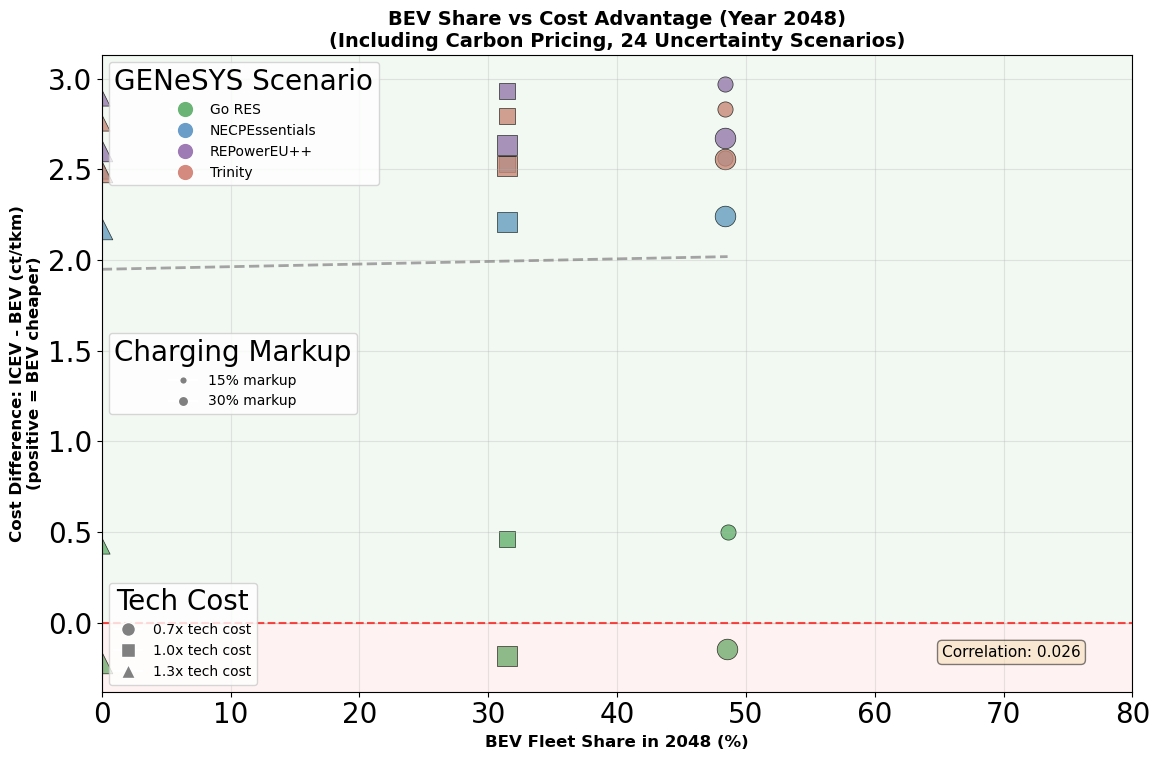


Cost difference summary (ICEV - BEV in ct/tkm):
  Min: -0.22, Max: 2.97, Mean: 1.99
  Carbon prices range: 65 - 149 EUR/tCO2

Figure saved to figures/bev_share_vs_cost_difference_2048.pdf


In [152]:
# =============================================================================
# BEV Share vs Cost Difference (ICEV - BEV) at 2048 - WITH CARBON PRICING
# =============================================================================

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
import yaml
from pathlib import Path

# Get BEV share at 2048 from elec_df
bev_share_2048 = elec_df[elec_df['year'] == 2048].copy()

# Calculate levelized costs for 2048 (year_index = 7 for 4-year steps)
year_index_2048 = 7

# Diesel emission factor (kg CO2 per kWh of diesel energy)
DIESEL_EMISSION_FACTOR = 0.266 / 1000  # tCO2/kWh

levelized_costs_2048 = {}

for scenario_id in range(24):
    scenario_path = Path(f'input_data/uncertainty_scenarios/scenario_{scenario_id:03d}')

    with open(scenario_path / 'TechVehicle.yaml', 'r') as f:
        tech_vehicles = yaml.safe_load(f)
    with open(scenario_path / 'FuelCost.yaml', 'r') as f:
        fuel_costs = yaml.safe_load(f)
    with open(scenario_path / 'GeographicElement.yaml', 'r') as f:
        geo_elements = yaml.safe_load(f)

    icev = next(tv for tv in tech_vehicles if tv['id'] == 0)
    bev = next(tv for tv in tech_vehicles if tv['id'] == 1)

    # Get carbon price
    carbon_price = 0
    for elem in geo_elements:
        if 'carbon_price' in elem:
            carbon_price = elem['carbon_price'][year_index_2048]
            break

    # Get fuel prices
    elec_prices = []
    diesel_price = None
    for fc in fuel_costs:
        if fc.get('fuel') == 'electricity':
            elec_prices.append(fc['cost_per_kWh'][year_index_2048])
        elif fc.get('fuel') == 'diesel' and diesel_price is None:
            diesel_price = fc['cost_per_kWh'][year_index_2048]

    avg_elec_price = np.mean(elec_prices) if elec_prices else 0.10
    diesel_price = diesel_price if diesel_price else 0.15

    # Add carbon cost to diesel
    carbon_cost_per_kwh = carbon_price * DIESEL_EMISSION_FACTOR
    diesel_with_carbon = diesel_price + carbon_cost_per_kwh

    avg_load = 13.6
    annual_km = bev['AnnualRange'][year_index_2048]
    lifetime = bev['Lifetime'][year_index_2048]
    lifetime_km = annual_km * lifetime

    # BEV costs (spec_cons in kWh/km)
    bev_capital_per_km = bev['capital_cost'][year_index_2048] / lifetime_km
    bev_maint_per_km = bev['maintenance_cost_annual'][0][year_index_2048] / annual_km
    bev_fuel_per_km = bev['spec_cons'][year_index_2048] * avg_elec_price
    bev_total_per_km = bev_capital_per_km + bev_maint_per_km + bev_fuel_per_km

    # ICEV costs (spec_cons in kWh/km, WITH carbon pricing)
    icev_capital_per_km = icev['capital_cost'][year_index_2048] / lifetime_km
    icev_maint_per_km = icev['maintenance_cost_annual'][0][year_index_2048] / annual_km
    icev_fuel_per_km = icev['spec_cons'][year_index_2048] * diesel_with_carbon
    icev_total_per_km = icev_capital_per_km + icev_maint_per_km + icev_fuel_per_km

    levelized_costs_2048[scenario_id] = {
        'bev_per_tkm': bev_total_per_km / avg_load,
        'icev_per_tkm': icev_total_per_km / avg_load,
        'cost_diff_per_tkm': (icev_total_per_km - bev_total_per_km) / avg_load,
        'carbon_price': carbon_price
    }

# Merge with scenario metadata
plot_data = []
for case in cases:
    scenario_id = case['case_id']
    bev_share = bev_share_2048[bev_share_2048['scenario_id'] == scenario_id]['bev_share'].values
    if len(bev_share) == 0:
        continue
    costs = levelized_costs_2048.get(scenario_id, {})
    if not costs:
        continue

    plot_data.append({
        'scenario_id': scenario_id,
        'genesys': case['genesys_scenario'].replace(' v1.2', ''),
        'markup': case['charging_markup'],
        'tech_cost': case['tech_cost_multiplier'],
        'bev_share_2048': bev_share[0],
        'cost_difference': costs['cost_diff_per_tkm'] * 100,
        'carbon_price': costs['carbon_price']
    })

# Create figure
fig, ax = plt.subplots(figsize=(12, 8))

colors = {
    'Go RES': '#6ab576',
    'NECPEssentials': '#6a9ec9',
    'REPowerEU++': '#9e7bb5',
    'Trinity': '#d48a7e'
}
markers = {0.7: 'o', 1.0: 's', 1.3: '^'}
sizes = {0.15: 120, 0.30: 220}

for data in plot_data:
    ax.scatter(
        data['bev_share_2048'],
        data['cost_difference'],
        c=colors.get(data['genesys'], 'gray'),
        marker=markers.get(data['tech_cost'], 'o'),
        s=sizes.get(data['markup'], 150),
        alpha=0.8,
        edgecolors='black',
        linewidths=0.5
    )

ax.axhline(y=0, color='red', linestyle='--', linewidth=1.5, alpha=0.7)

genesys_handles = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor=color, markersize=12, label=name)
    for name, color in colors.items()
]
tech_handles = [
    Line2D([0], [0], marker=marker, color='w', markerfacecolor='gray', markersize=10,
           label=f'{mult:.1f}x tech cost')
    for mult, marker in markers.items()
]
markup_handles = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', markersize=np.sqrt(size)/2,
           label=f'{int(markup*100)}% markup')
    for markup, size in sizes.items()
]

legend1 = ax.legend(handles=genesys_handles, title='GENeSYS Scenario', loc='upper left', fontsize=10)
ax.add_artist(legend1)
legend2 = ax.legend(handles=tech_handles, title='Tech Cost', loc='lower left', fontsize=10)
ax.add_artist(legend2)
legend3 = ax.legend(handles=markup_handles, title='Charging Markup', loc='center left', fontsize=10,
                    bbox_to_anchor=(0, 0.5))

ax.set_xlabel('BEV Fleet Share in 2048 (%)', fontsize=12, fontweight='bold')
ax.set_ylabel('Cost Difference: ICEV - BEV (ct/tkm)\n(positive = BEV cheaper)', fontsize=12, fontweight='bold')
ax.set_title('BEV Share vs Cost Advantage (Year 2048)\n(Including Carbon Pricing, 24 Uncertainty Scenarios)',
             fontsize=14, fontweight='bold')

ax.grid(True, alpha=0.3)
ax.set_xlim(0, 80)

ylim = ax.get_ylim()
ax.fill_between([0, 80], 0, max(ylim[1], 0.1), alpha=0.05, color='green')
ax.fill_between([0, 80], min(ylim[0], -0.1), 0, alpha=0.05, color='red')
ax.set_ylim(ylim)

x_vals = [d['bev_share_2048'] for d in plot_data]
y_vals = [d['cost_difference'] for d in plot_data]
z = np.polyfit(x_vals, y_vals, 1)
p = np.poly1d(z)
x_line = np.linspace(min(x_vals), max(x_vals), 100)
ax.plot(x_line, p(x_line), '--', color='gray', alpha=0.7, linewidth=2)

corr = np.corrcoef(x_vals, y_vals)[0, 1]
ax.text(0.95, 0.05, f'Correlation: {corr:.3f}', transform=ax.transAxes, fontsize=11,
        ha='right', verticalalignment='bottom', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.savefig('figures/bev_share_vs_cost_difference_2048.pdf', bbox_inches='tight', dpi=150)
plt.savefig('figures/bev_share_vs_cost_difference_2048.png', bbox_inches='tight', dpi=150)
plt.show()

# Print summary
print("\nCost difference summary (ICEV - BEV in ct/tkm):")
print(f"  Min: {min(y_vals):.2f}, Max: {max(y_vals):.2f}, Mean: {np.mean(y_vals):.2f}")
print(f"  Carbon prices range: {min(d['carbon_price'] for d in plot_data):.0f} - {max(d['carbon_price'] for d in plot_data):.0f} EUR/tCO2")
print("\nFigure saved to figures/bev_share_vs_cost_difference_2048.pdf")
